# How BCA can help a policy: four toy experiments, step by step

A *policy* is a rule that picks an action in each state. Here the policy learns offline, from a *log* of past actions and their outcomes. Its guide is a *critic*: a learned estimate of each action's value, the total reward (the *return*) that the action leads to. The critic is least reliable on *risky actions*, which the log barely covers, and it can overrate them. The policy finds out only at *deployment*, when it is put to use.

**BCA** (Bayesian Conformal Aggregation) is this repository's calibration method. It turns the critic's errors on *held-out* data, which training never saw, into a *threshold* with a stated confidence: for example, 95% sure that at least 90% of future errors fall at or below it. Four small toy experiments, whose truth is known exactly, ask where that threshold can help a policy choose better actions.

## What you will learn

- How BCA turns held-out errors into a threshold, computed by hand.
- How BCA makes a yes-or-no decision on a risky action, in two versions, and what each version promises.
- How *weights* keep BCA's promise under a *shift*, when deployment meets states in a different mix than the log. Each held-out outcome then counts by how often deployment meets its state, compared with the log.
- What each experiment found, and why.
- Which uses of BCA these toys support, and which they leave open.

## How to use this notebook

- **Run All first.** It takes about 3–6 minutes, most of it in Part 4. It needs only NumPy, Matplotlib and IPython, and downloads nothing.
- **Read from top to bottom.** Each step adds one idea to the ones before it.
- **Short on time?** Follow this core path, and leave cells that begin *Deeper: skip on a first read.* for a second read:
  - the Lesson's Steps A.1 to A.8;
  - in each part: its opening, its worked case (Steps 1.4 and 1.5; 2.9 to 2.13; 3.9 and 3.10; 4.6 and 4.10), its verdicts (Steps 2.15, 3.12 and 4.12) and *What Part N found*;
  - the closing summary, *What it all adds up to*.
- **Code starts collapsed** in editors that support it, except the Try-it cells. Expand any cell to read its code. The first code cell, just below this introduction, holds the display tools that the worked examples use.
- **Try it.** Change an input in a Try-it cell and rerun that cell: every line of its worked example updates.
- **Going back.** Parts reuse some of the experiments' names. A Try-it cell or worked example that finds its part's names taken over by another part (a later one, or an earlier one you reran) says so, and asks you to rerun its own part's code cells first.
- **Old and new.** The experiments' code is copied unchanged from their original notebooks, and it reproduces every result they printed (only run times differ). The worked examples are new. Each one that recomputes an experiment's result checks itself against that result, and stops the notebook if the two ever disagree.
- **Production checks.** A few checks compare with the repository's production code, `calibration/wbcp.py`. When that file cannot be imported, for example because the notebook is not running from the repository's root folder, they skip themselves with a note.

## The answer in one minute

A policy can use BCA in two ways:
- as a **width**: a margin of error on the critic's values, used as extra caution. Part 1 subtracts it from the values. The *hosts*, the four offline learners BCA is attached to in this repository, use it during training to strengthen one term of their loss, and one of Part 2's rules (A2) mimics this;
- as a **gate**: a yes-or-no check on one risky action. The gate reads held-out *tries* of that action (logged outcomes that training never saw) and lets the action through only if they pass. Otherwise the policy takes the *fallback*, a safe action the log covers well.

A gate makes one of two promises, each with 95% confidence:
- a **tail gate** promises that at most 10% of the risky action's outcomes fall below the fallback;
- a **mean gate** promises that the risky action beats the fallback on average.

What the four experiments found:
- **A width did not help.** Calibrated where it was measured, it still did worse than simply refusing actions with too little data (Parts 1 and 2).
- **Gates that read the risky action's own held-out tries did help.** The help vanished when those tries were shuffled (Part 2).
- **BCA's tail gate kept its promise for the data in hand,** unlike split conformal prediction, the standard method, whose promise holds only on average over many data sets. But with equal weights, that is, no shift weights, BCA's tail gate is a textbook test: the exact binomial test (Part 2).
- **BCA's mean gate earned the most once every gate was tuned to the same safety level** (Part 3; narrowly in Part 4). That tuning used toy worlds whose truth is known. With no safety promise at all, simply checking the tries' plain average earned more than the mean gate at its stated 95% confidence: 0.158 against 0.045, in Part 3's average gain per situation.
- **BCA's weights kept both promises under a shift,** when deployment meets states in a different mix than the log. The cost is evidence: under the strongest shift tested, the tail gate needs about 83 tries before it can say yes, against 29 with no shift (Part 4).

In short: in these toys, BCA helped as a gate on each risky action, never as a width.

## Roadmap

| Section | Title | What it holds |
|---|---|---|
| Lesson | How BCA turns held-out scores into a promise | BCA's tools, worked by hand on small examples |
| Part 1 | Does BCA's width make the policy choose better? | an exploratory demo: one seed, no claims |
| Part 2 | Where can BCA help? Widths against gates | 6 pre-registered tests |
| Part 3 | Can a BCA gate raise return? The mean gate | 6 pre-registered claims |
| Part 4 | Do BCA's weights help under a shift? | 6 pre-registered claims |
| Summary | What it all adds up to | all 18 verdicts, what they mean, and a glossary |

Each part opens with its question and the steps it will take, and closes with what it found.

## How far to trust it

- **Toys only.** Small made-up worlds. Nothing here is evidence about ThrusterChain, the repository's larger test environment, or about the hosts (TD3+BC, CQL, IQL and ReBRAC).
- **Part 1 is exploratory:** one *seed* (one set of random numbers), and no claims.
- **Parts 2–4 were pre-registered.** Each claim has a *kill rule*: a result, written down before the run, that would *shelve* the claim (set it aside as unsupported). A claim that survives its kill rule is *alive*. The rules were fingerprinted (hashed with SHA-256, so any later edit would show) before each experiment's first run, according to the agent that ran them. The repository's history cannot confirm that timing, because all four notebooks were added in one commit.
- **Two verdicts are narrow.** Part 2's test 4b and Part 4's claim 6 cleared their kill rules by small margins.
- **The mean gate's guarantee rests on a preprint** that is not peer reviewed (Vlassis and Thomas, July 2026, [arXiv 2607.08415](https://arxiv.org/abs/2607.08415), version 1). The weighted mean gate that Part 4 tests has no proof at all.

In [1]:
# Lesson tools: they display worked examples and never change the experiments' data.
# Names made here start with "lesson_" (tools) or "try_" (inputs you may edit), so they cannot collide
# with the experiments' own names.
import math
import re
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 100, "figure.facecolor": "white",
                     "axes.facecolor": "white", "savefig.facecolor": "white", "font.size": 10})

_LESSON_PLAIN = [(r"\left", ""), (r"\right", ""), (r"\Big", ""), (r"\big", ""), (r"\,", " "), (r"\;", " "),
                 (r"\quad", "  "), (r"\qquad", "    "), (r"\times", "×"), (r"\cdot", "·"), (r"\leq", "≤"),
                 (r"\geq", "≥"), (r"\le", "≤"), (r"\ge", "≥"), (r"\neq", "≠"), (r"\approx", "≈"),
                 (r"\infty", "∞"), (r"\lceil", "⌈"), (r"\rceil", "⌉"), (r"\lfloor", "⌊"), (r"\rfloor", "⌋"),
                 (r"\sum", "Σ"), (r"\prod", "Π"), (r"\Rightarrow", "⇒"), (r"\rightarrow", "→"),
                 (r"\to", "→"), (r"\iff", "⇔"), (r"\Leftrightarrow", "⇔"), (r"\ldots", "…"), (r"\dots", "…"),
                 (r"\lambda", "λ"), (r"\alpha", "α"), (r"\beta", "β"), (r"\sigma", "σ"), (r"\mu", "μ"),
                 (r"\delta", "δ"), (r"\Delta", "Δ"), (r"\pi", "π"), (r"\hat", ""), (r"\bar", ""),
                 (r"\in", "∈"), (r"\{", "{"), (r"\}", "}"), (r"\%", "%"), (r"\\", "\n"), ("{,}", ",")]


def lesson_plain(md):
    """A rough plain-text version of a Markdown/LaTeX string, for viewers that cannot render Markdown."""
    text = md.replace("$$", "").replace("$", "")
    text = re.sub(r"\\begin\{aligned\}|\\end\{aligned\}", "", text)
    text = re.sub(r"\\(?:text|mathrm|mathbf|operatorname|textbf)\{([^{}]*)\}", r"\1", text)
    text = re.sub(r"\\frac\{([^{}]*)\}\{([^{}]*)\}", r"(\1)/(\2)", text)
    text = re.sub(r"\\sqrt\{([^{}]*)\}", r"√(\1)", text)
    for latex, plain in _LESSON_PLAIN:
        text = text.replace(latex, plain)
    text = text.replace("&", "").replace("{", "").replace("}", "")
    return re.sub(r"[ \t]+\n", "\n", text).strip()


class lesson_Markdown:
    """A display object with a Markdown (LaTeX) view and a plain-text fallback."""

    def __init__(self, md, plain=None):
        self.md, self.plain = md, (lesson_plain(md) if plain is None else plain)

    def _repr_markdown_(self):
        return self.md

    def __repr__(self):
        return self.plain


def lesson_show(md):
    """Display Markdown text (inline math in $...$, display math in $$...$$)."""
    display(lesson_Markdown(md))


def _lesson_digits(x, d):
    return f"{x:,.{d}f}" if abs(x) >= 10_000 else f"{x:.{d}f}"


def lesson_num(x, d=3, sign=False):
    """A number for LaTeX: infinity as \\infty, thousands as 10{,}000, a plus sign when sign=True."""
    if isinstance(x, (bool, np.bool_)):
        return r"\text{" + ("yes" if x else "no") + "}"
    if isinstance(x, (int, np.integer)):
        s = f"{int(x):,}"
    else:
        x = float(x)
        if math.isinf(x):
            return ("+" if sign else "") + r"\infty" if x > 0 else r"-\infty"
        s = _lesson_digits(x, d)
    s = s.replace(",", "{,}")
    return ("+" + s) if sign and not s.startswith("-") else s


def lesson_txt(x, d=3, sign=False):
    """The same number for plain Markdown text: ∞, a true minus sign (−), thousands as 10,000."""
    if isinstance(x, (bool, np.bool_)):
        return "yes" if x else "no"
    if isinstance(x, (int, np.integer)):
        s = f"{int(x):,}"
    else:
        x = float(x)
        if math.isinf(x):
            return ("+" if sign else "") + "∞" if x > 0 else "−∞"
        s = _lesson_digits(x, d)
    s = ("+" + s) if sign and not s.startswith("-") else s
    return s.replace("-", "−")


def lesson_pct(x, d=1, latex=True):
    """A share as a percentage: 0.0523 -> 5.2% (LaTeX escapes the % sign)."""
    s = f"{100 * float(x):.{d}f}"
    return s + (r"\%" if latex else "%")


_LESSON_SLOT = re.compile(r"<<(\w+)(?::([%+]?)(\d*))?>>")


def lesson_tex(template, **values):
    """Fill a LaTeX template: <<name>> (3 decimals), <<name:2>> (2 decimals), <<name:+2>> (signed),
    <<name:%1>> (percentage with 1 decimal). Strings are inserted as they are. No brace escaping needed."""
    def fill(m):
        v, flag, digits = values[m.group(1)], m.group(2) or "", m.group(3)
        if isinstance(v, str):
            return v
        if flag == "%":
            return lesson_pct(v, int(digits) if digits else 1)
        return lesson_num(v, int(digits) if digits else 3, sign=flag == "+")
    return _LESSON_SLOT.sub(fill, template)


def lesson_text(template, **values):
    """Like lesson_tex, for plain Markdown text (uses lesson_txt; percentages end in %)."""
    def fill(m):
        v, flag, digits = values[m.group(1)], m.group(2) or "", m.group(3)
        if isinstance(v, str):
            return v
        if flag == "%":
            return lesson_pct(v, int(digits) if digits else 1, latex=False)
        return lesson_txt(v, int(digits) if digits else 3, sign=flag == "+")
    return _LESSON_SLOT.sub(fill, template)


def lesson_math(*lines, note=None):
    """Display aligned LaTeX lines (use & to align, usually just before =), then an optional Markdown note."""
    body = r" \\ ".join(lines)
    md = "$$\n\\begin{aligned}\n" + body + "\n\\end{aligned}\n$$"
    if note:
        md += "\n\n" + note
    lesson_show(md)


def lesson_table(header, rows, note=None, digits=3):
    """Display a Markdown table; numbers are formatted with lesson_txt."""
    def cell(v):
        if isinstance(v, str):
            return v
        return lesson_txt(v, digits)
    md = "| " + " | ".join(header) + " |\n|" + "|".join("---" for _ in header) + "|\n"
    md += "\n".join("| " + " | ".join(cell(v) for v in row) + " |" for row in rows)
    if note:
        md += "\n\n" + note
    lesson_show(md)


def lesson_check(condition, message):
    """Stop the notebook if a worked example disagrees with the experiment it explains."""
    if not condition:
        raise AssertionError("Worked example does not match the experiment: " + message)

---
# Lesson · How BCA turns held-out scores into a promise

*New for this notebook. Every example here uses small made-up numbers, worked by the code, so nothing in the Lesson is an experiment's result.*

**The question.** How does BCA turn a critic's misses on held-out data into a threshold that it is 95% sure at least 90% of future misses stay at or below? And how does that threshold become a yes-or-no decision about a risky action? Each step adds one idea and works it with real arithmetic. Parts 1–4 then use the same tools on the experiments.

**In this lesson**

**Building the threshold**

1. Scores and the promise
2. Two simple thresholds
3. One random draw, by hand
4. A thousand draws

**How much evidence it needs**

5. Why at least 29 scores
6. The exact shortcut

**Turning it into a decision**

7. From a threshold to a decision: the tail gate
8. The mean gate

**Shifts, and a map of the tools**

9. Weights for a shift
10. Where each tool appears

### Step A.1 · Scores and the promise

BCA checks a **critic**, a learned estimate of what an action is worth, on data it was not trained on:
- **Held-out** rows are logged outcomes that training never saw.
- On held-out row $i$, the **score** $s_i$ says how far the critic missed; bigger is worse. If the critic predicted 2.0 and the row's outcome was 1.6, then $s_i = \lvert 1.6 - 2.0 \rvert = 0.4$.

BCA's goal is a **threshold** $\lambda$ that comes with a promise: we are $\beta = 95\%$ sure that at least $1 - \alpha = 90\%$ of future scores will be at or below $\lambda$.
- $n$: the number of held-out scores.
- $\alpha = 0.1$: the share of future scores allowed above $\lambda$.
- $\beta = 0.95$: the confidence.

Every threshold below is one of the scores, chosen by its rank, so the first move is to sort them: $s_{(j)}$ is the $j$-th smallest. Here are ten made-up scores.

In [2]:
# Step A.1 tools. Settings shared by the whole Lesson, and the ten made-up scores in the order their rows came.
from fractions import Fraction

lesson_a_alpha = 0.1                         # the promise: at least 1 - alpha = 90% of future scores at or below
lesson_a_ninety = Fraction(9, 10)            # 1 - alpha, exactly, so that ranks never suffer from rounding
lesson_a_draws = 1000                        # BCA's random draws per threshold, as in production
lesson_a_need = math.ceil(Fraction(95, 100) * lesson_a_draws)   # 950: lambda_beta is the 950th smallest crossing
lesson_a_seed = 121                          # the Lesson's seed for BCA's random weights (Step A.3 says why)
lesson_a_scores = np.array([0.4, 1.3, 0.2, 2.1, 0.7, 0.9, 0.3, 1.6, 0.5, 1.1])


def lesson_a_g(x, latex=True):
    """A short number: at most 3 decimals with trailing zeros dropped, infinity as a symbol, a true minus in text."""
    x = float(x)
    if math.isinf(x):
        return r"\infty" if latex else "∞"
    s = f"{round(x, 3) + 0.0:.3f}".rstrip("0").rstrip(".")
    s = "0" if s in ("-0", "") else s
    return s if latex else s.replace("-", "−")


def lesson_a_count(k, one, many=None):
    """A count with its noun: 1 score, 10 scores; 1 try, 30 tries (1,000 with a thousands comma)."""
    return f"{int(k):,} " + (one if int(k) == 1 else (many or one + "s"))


def lesson_a_real(x):
    """A Try-it input as a float, or nan when it is not a single number (text, True/False, a list, ...)."""
    if isinstance(x, (bool, np.bool_)) or not isinstance(x, (int, float, np.integer, np.floating)):
        return math.nan
    try:
        return float(x)
    except OverflowError:
        return math.nan


def lesson_a_whole(x, lo, hi):
    """True when a Try-it input is a whole number from lo to hi."""
    v = lesson_a_real(x)
    return math.isfinite(v) and v.is_integer() and lo <= v <= hi


def lesson_a_seed_ok(seed):
    """True for a usable seed (a whole number, 0 or more); otherwise say how to fix it."""
    if isinstance(seed, (int, np.integer)) and not isinstance(seed, bool) and seed >= 0:
        return True
    lesson_show("Pick a seed that is a whole number, 0 or more.")
    return False


def lesson_a_valid_scores(scores):
    """The scores as a float array; for unusable Try-it input, a short message and None."""
    try:
        s = None if isinstance(scores, str) else np.asarray(scores, dtype=float)
    except (TypeError, ValueError, OverflowError):
        s = None
    if s is None or s.ndim != 1 or not 1 <= s.size <= 2000 or not np.all(np.isfinite(s)):
        lesson_show("Give a list of 1 to 2,000 finite numbers, for example [0.4, 1.3, 0.2].")
        return None
    return s


def lesson_a_sorted_table(try_scores):
    """Step A.1: the scores from smallest to largest, with the held-out row each came from."""
    s = lesson_a_valid_scores(try_scores)
    if s is None:
        return
    order = np.argsort(s, kind="stable")
    lesson_table(["rank $j$", "score $s_{(j)}$", "from held-out row $i$"],
                 [[str(j + 1), lesson_a_g(s[i], False), str(i + 1)] for j, i in enumerate(order)],
                 note=lesson_text("**So:** $n = <<n>>$, and the scores run from $s_{(1)} = <<lo>>$ up to "
                                  "$s_{(<<n>>)} = <<hi>>$.", n=lesson_num(int(s.size)), lo=lesson_a_g(s[order[0]]),
                                  hi=lesson_a_g(s[order[-1]])))

In [3]:
# Try it: edit the scores (1 to 2,000 numbers), then rerun this cell.
# (Steps A.2 to A.4 keep the ten scores above; Step A.4's Try-it takes your own list.)
try_scores = [0.4, 1.3, 0.2, 2.1, 0.7, 0.9, 0.3, 1.6, 0.5, 1.1]
lesson_a_sorted_table(try_scores)

| rank $j$ | score $s_{(j)}$ | from held-out row $i$ |
|---|---|---|
| 1 | 0.2 | 3 |
| 2 | 0.3 | 7 |
| 3 | 0.4 | 1 |
| 4 | 0.5 | 9 |
| 5 | 0.7 | 5 |
| 6 | 0.9 | 6 |
| 7 | 1.1 | 10 |
| 8 | 1.3 | 2 |
| 9 | 1.6 | 8 |
| 10 | 2.1 | 4 |

**So:** $n = 10$, and the scores run from $s_{(1)} = 0.2$ up to $s_{(10)} = 2.1$.

### Step A.2 · Two simple thresholds

The **plain 90% quantile** is the smallest score with at most 10% of the scores above it:

$$
\hat\lambda = s_{(\lceil (1-\alpha)\, n \rceil)}
$$

Here $\lceil x \rceil$ rounds $x$ up to a whole number. **Split conformal prediction**, the standard method for such thresholds, uses $n + 1$ in place of $n$:

$$
\text{split conformal's threshold} = s_{(\lceil (1-\alpha)(n+1) \rceil)}
$$

When that rank is above $n$, the threshold is $\infty$: too few scores to promise anything.

In [4]:
# Step A.2 tools.
def lesson_a_rank_hat(n):
    """The plain quantile's rank: (1 - alpha) times n, rounded up."""
    return math.ceil(lesson_a_ninety * n)


def lesson_a_rank_sc(n):
    """Split conformal's rank: (1 - alpha) times (n + 1), rounded up; above n means no finite threshold."""
    return math.ceil(lesson_a_ninety * (n + 1))


def lesson_a_two_thresholds(scores):
    """Step A.2: both thresholds, worked from the sorted scores."""
    s = lesson_a_valid_scores(scores)
    if s is None:
        return
    s = np.sort(s)
    n = int(s.size)
    j1, j2 = lesson_a_rank_hat(n), lesson_a_rank_sc(n)
    v1 = float(s[j1 - 1])
    v2 = float(s[j2 - 1]) if j2 <= n else math.inf
    end2 = (lesson_tex(r"s_{(<<j>>)} = <<v>>", j=j2, v=lesson_a_g(v2)) if j2 <= n
            else lesson_tex(r"\infty \quad (\text{rank } <<j>> > n)", j=j2))
    lesson_math(lesson_tex(r"\hat\lambda &= s_{(\lceil 0.9 \times <<n>> \rceil)} = s_{(\lceil <<p>> \rceil)}",
                           n=n, p=lesson_a_g(lesson_a_ninety * n)),
                lesson_tex(r"&= s_{(<<j>>)} = <<v>>", j=j1, v=lesson_a_g(v1)),
                lesson_tex(r"\text{split conformal} &= s_{(\lceil 0.9 \times <<m>> \rceil)} = s_{(\lceil <<p>> \rceil)}",
                           m=n + 1, p=lesson_a_g(lesson_a_ninety * (n + 1))),
                r"&= " + end2,
                note=lesson_text("**So:** with <<n>> scores, the plain quantile is <<a>> and split conformal's "
                                 "threshold is <<b>><<r>>.", n=n, a=lesson_a_g(v1, False), b=lesson_a_g(v2, False),
                                 r=", one rank higher" if j2 == j1 + 1 and j2 <= n else ""))


lesson_a_two_thresholds(lesson_a_scores)

$$
\begin{aligned}
\hat\lambda &= s_{(\lceil 0.9 \times 10 \rceil)} = s_{(\lceil 9 \rceil)} \\ &= s_{(9)} = 1.6 \\ \text{split conformal} &= s_{(\lceil 0.9 \times 11 \rceil)} = s_{(\lceil 9.9 \rceil)} \\ &= s_{(10)} = 2.1
\end{aligned}
$$

**So:** with 10 scores, the plain quantile is 1.6 and split conformal's threshold is 2.1, one rank higher.

**Why the +1.** The promise is about the next score, which is not among the $n$ held out. If it behaves like them, it is equally likely to land in any of the $n + 1$ gaps that the sorted scores leave: below $s_{(1)}$, between two neighbors, or above $s_{(n)}$. So it lands at or below $s_{(j)}$ with chance $j/(n+1)$. Split conformal takes the smallest $j$ that makes this chance at least 90%.

In [5]:
def lesson_a_next_chance(n):
    """Step A.2: the chance that the next score lands at or below each threshold."""
    j1, j2 = lesson_a_rank_hat(n), lesson_a_rank_sc(n)
    lines = [lesson_tex(r"P(\text{next} \le s_{(<<j>>)}) &= \frac{<<j>>}{<<m>>} = <<p>>", j=j1, m=n + 1, p=j1 / (n + 1))]
    if j2 <= n:
        lines.append(lesson_tex(r"P(\text{next} \le s_{(<<j>>)}) &= \frac{<<j>>}{<<m>>} = <<p>>",
                                j=j2, m=n + 1, p=j2 / (n + 1)))
    lesson_math(*lines, note=lesson_text("**So:** the next score lands at or below the plain quantile $s_{(<<j>>)}$ "
                                         "with chance <<a>>, short of 90%, and at or below split conformal's "
                                         "threshold<<k>> with chance <<b>>.", j=j1, a=j1 / (n + 1),
                                         k=lesson_text(" $s_{(<<j>>)}$", j=j2) if j2 <= n else " (∞)",
                                         b=min(j2, n + 1) / (n + 1)))


lesson_a_next_chance(lesson_a_scores.size)

$$
\begin{aligned}
P(\text{next} \le s_{(9)}) &= \frac{9}{11} = 0.818 \\ P(\text{next} \le s_{(10)}) &= \frac{10}{11} = 0.909
\end{aligned}
$$

**So:** the next score lands at or below the plain quantile $s_{(9)}$ with chance 0.818, short of 90%, and at or below split conformal's threshold $s_{(10)}$ with chance 0.909.

**On average, not for the data in hand.** That chance is an average over all the sets of scores you might have held out. The set you actually have may give a threshold that covers less: one with less than 90% of future scores at or below it. To see how often, the next cell draws 100,000 made-up data sets of 10 scores from a known source. Its scores are spread evenly between 0 and 3, so exactly a share $t/3$ of future scores lands at or below a threshold $t$.

In [6]:
def lesson_a_coverage(n, ranks, seed=2027):
    """Over many made-up data sets of n scores, spread evenly between 0 and 3 (so a threshold t has exactly t/3 of
    future scores at or below it): for each rank j asked for, the share of future scores that each data set's
    j-th smallest score covers. A rank above n stands for the threshold infinity, which covers everything.
    The same n and seed always give the same data sets."""
    sets = min(100_000, 4_000_000 // n)
    data = np.random.default_rng(seed).uniform(0.0, 3.0, (sets, n))
    inside = sorted({j - 1 for j in ranks if 1 <= j <= n})
    part = np.partition(data, inside, axis=1) if inside else data
    return sets, {j: (part[:, j - 1] / 3.0 if j <= n else np.ones(sets)) for j in ranks}


def lesson_a_short_share(n):
    """The share of the made-up data sets of n scores in which split conformal's threshold covers less than 90%."""
    j2 = lesson_a_rank_sc(n)
    return float((lesson_a_coverage(n, (j2,))[1][j2] < 0.9).mean())


def lesson_a_conformal_sim(try_n, explain=False):
    """Step A.2: how often each threshold covers less than 90% of future scores, over many made-up data sets.
    explain=True adds why the share does not go away (printed once, for the Lesson's 10 scores)."""
    if not lesson_a_whole(try_n, 2, 1000):
        lesson_show("Pick a whole number of scores from 2 to 1,000.")
        return
    n = int(try_n)
    j1, j2 = lesson_a_rank_hat(n), lesson_a_rank_sc(n)
    sets, cover = lesson_a_coverage(n, (j1, j2))
    cover1, cover2 = cover[j1], cover[j2]
    short1, short2 = float((cover1 < 0.9).mean()), float((cover2 < 0.9).mean())
    if j2 > n:
        note = lesson_text("**So:** with only <<n>> scores, split conformal's rank is above $n$, so its threshold is "
                           "∞: it covers every future score but promises nothing useful.", n=n)
    else:
        note = lesson_text("**So:** over <<k>> data sets of <<n>> scores, split conformal's threshold covers <<c>> of "
                           "future scores on average, as promised. Yet in <<p:%1>> of the data sets it covers less "
                           "than 90%", k=sets, n=n, c=float(cover2.mean()), p=short2)
        if explain:
            note += (". More scores do not make that share go away: the threshold aims at 90% on average, so many "
                     "data sets land a little below 90%, and more scores only shrink how far below. BCA aims for a "
                     "different kind of promise, about the data set in hand: 95% sure that it covers at least 90%. "
                     "Then at most 5% of data sets may fall short.")
        elif n == 10:
            note += ", as in the table above."
        else:
            note += lesson_text(", against <<q:%1>> with 10 scores<<t>>", q=lesson_a_short_share(10),
                                t=": more scores do not make that share go away." if n > 10 else ".")
    lesson_table(["threshold", "rank", "average share covered", "data sets covering under 90%"],
                 [["plain quantile", str(j1), lesson_txt(cover1.mean()), lesson_pct(short1, 1, latex=False)],
                  ["split conformal", str(j2) if j2 <= n else "above $n$: ∞", lesson_txt(cover2.mean()),
                   lesson_pct(short2, 1, latex=False)]], note=note)


lesson_a_conformal_sim(lesson_a_scores.size, explain=True)

| threshold | rank | average share covered | data sets covering under 90% |
|---|---|---|---|
| plain quantile | 9 | 0.818 | 73.7% |
| split conformal | 10 | 0.909 | 34.9% |

**So:** over 100,000 data sets of 10 scores, split conformal's threshold covers 0.909 of future scores on average, as promised. Yet in 34.9% of the data sets it covers less than 90%. More scores do not make that share go away: the threshold aims at 90% on average, so many data sets land a little below 90%, and more scores only shrink how far below. BCA aims for a different kind of promise, about the data set in hand: 95% sure that it covers at least 90%. Then at most 5% of data sets may fall short.

In [7]:
# Try it: change the number of scores n (a whole number from 2 to 1,000), then rerun this cell.
# Watch the last column as n grows: it does not go away.
try_n = 100
lesson_a_conformal_sim(try_n)

| threshold | rank | average share covered | data sets covering under 90% |
|---|---|---|---|
| plain quantile | 90 | 0.891 | 58.1% |
| split conformal | 91 | 0.901 | 44.8% |

**So:** over 40,000 data sets of 100 scores, split conformal's threshold covers 0.901 of future scores on average, as promised. Yet in 44.8% of the data sets it covers less than 90%, against 34.9% with 10 scores: more scores do not make that share go away.

### Step A.3 · One random draw, by hand

BCA gives each sorted score a random weight, and adds an **extra weight** for the unseen next score:
- $E_1, \dots, E_n$ go to $s_{(1)}, \dots, s_{(n)}$. Each is drawn from an Exponential(1) distribution, so it is always positive.
- $E_{n+1}$ goes above every score: the worst case.
- These random weights change from draw to draw but favor no score: each is 1 on average. Step A.9 adds a second, fixed weight per row for a shift. Until then every row's fixed weight is 1, and this notebook calls that **equal weights** (no shift weights).

A draw is one plausible guess at how future scores spread out: a share $E_j / \sum_{i=1}^{n+1} E_i$ of them at $s_{(j)}$, and the extra weight's share above all the scores. The draw's **crossing** is that guess's 90% point: the first score where the running total of weights reaches 90% of the total. For draw number $m$:

$$
\begin{aligned}
\lambda^{(m)} &= s_{(j^*)}, \quad \text{where} \\
j^* &= \min\Big\{ j : \sum_{i=1}^{j} E_i \ge (1-\alpha) \sum_{i=1}^{n+1} E_i \Big\}
\end{aligned}
$$

If no $j \le n$ qualifies, the draw **never crosses**: $\lambda^{(m)} = \infty$.

In [8]:
# Step A.3 tools: BCA's random weights in production's layout, and production's crossing rule.
def lesson_a_exponentials(n, seed, draws=lesson_a_draws):
    """Production's layout: row m - 1 is draw m; its first n columns weight the sorted scores, the last is E_{n+1}."""
    if not (isinstance(seed, (int, np.integer)) and seed >= 0):
        raise ValueError("Pick a seed that is a whole number, 0 or more.")
    return np.random.default_rng(seed).standard_exponential((draws, n + 1))


def lesson_a_crossing_parts(E, w=None, wbar=1.0):
    """Production's crossing rule (calibration/wbcp.py), keeping the pieces for display. Returns each draw's
    crossing rank j* (0 when it never crosses), the running totals and the totals."""
    n = E.shape[1] - 1
    mass = E[:, :-1] * (np.ones(n) if w is None else np.asarray(w, dtype=float))
    total = mass.sum(axis=1) + E[:, -1] * wbar
    running = np.cumsum(mass, axis=1)
    covered = running >= (1.0 - lesson_a_alpha) * total[:, None]
    return np.where(covered.any(axis=1), covered.argmax(axis=1) + 1, 0), running, total


def lesson_a_one_draw(scores, try_draw, try_seed):
    """Step A.3: one draw's weights, running total and crossing, row by row."""
    s = lesson_a_valid_scores(scores)
    if s is None:
        return
    s = np.sort(s)
    if not lesson_a_whole(try_draw, 1, lesson_a_draws):
        lesson_show("Pick a draw from 1 to 1,000.")
        return
    if not lesson_a_seed_ok(try_seed):
        return
    n, m = int(s.size), int(try_draw)
    E = lesson_a_exponentials(n, try_seed)
    ranks, running, total = lesson_a_crossing_parts(E)
    e, run, tot = E[m - 1], running[m - 1], float(total[m - 1])
    target = (1.0 - lesson_a_alpha) * tot
    j_star = int(ranks[m - 1])
    by_hand = next((j for j in range(1, n + 1) if run[j - 1] >= target), 0)
    lesson_check(by_hand == j_star, "the crossing worked row by row differs from production's rule")
    lesson_math(lesson_tex(r"\text{total} &= E_1 + \dots + E_{<<k>>} = <<t>>", k=n + 1, t=tot),
                r"\text{target} &= 0.9 \times \text{total}",
                lesson_tex(r"&= 0.9 \times <<t>> = <<g>>", t=tot, g=target))
    rows = []
    for j in range(1, n + 1):
        mark = "**yes: the crossing**" if j == j_star else ("yes" if run[j - 1] >= target else "no")
        rows.append([str(j), lesson_a_g(s[j - 1], False), lesson_txt(e[j - 1]), lesson_txt(run[j - 1]), mark])
    rows.append([lesson_text("extra, $E_{<<k>>}$", k=lesson_num(n + 1)), "above every score", lesson_txt(e[n]),
                 lesson_txt(tot), "not a score"])
    lesson_table(["$j$", "$s_{(j)}$", "weight $E_j$", "running total", lesson_text("reached <<g>>?", g=target)], rows)
    if j_star:                       # whole numbers inside $...$ go through lesson_num (1{,}000, not 1,000)
        before = ("" if j_star == 1 else
                  lesson_text(" (at $j = <<j>>$ it was <<r>>, still short)", j=lesson_num(j_star - 1),
                              r=float(run[j_star - 2])))
        lesson_show(lesson_text("**So:** the running total first reaches <<g>> at $j^* = <<j>>$<<b>>, so draw <<m>>'s "
                                "crossing is $\\lambda^{(<<mm>>)} = s_{(<<j>>)} = <<v>>$.", g=target,
                                j=lesson_num(j_star), b=before, m=m, mm=lesson_num(m), v=lesson_a_g(s[j_star - 1])))
    else:
        share = float(e[n]) / tot
        lesson_show(lesson_text("**So:** draw <<m>> never crosses. Its extra weight, <<x>>, is <<p:%1>> of the total, "
                                "more than $\\alpha$ = 10%. So <<who>> only <<q:%1>> of the weight, short of 90%: "
                                "$\\lambda^{(<<mm>>)} = \\infty$.", m=m, mm=lesson_num(m), x=float(e[n]), p=share,
                                q=1 - share, who="the one score holds" if n == 1 else
                                f"even all {n:,} scores together hold"))


lesson_a_one_draw(lesson_a_scores, 1, lesson_a_seed)
lesson_show(lesson_text("These are the weights of draw 1 of 1,000, from seed <<sd>>, a seed picked because its draw 1 "
                        "crosses and its draw 2 never does.", sd=lesson_a_seed))

$$
\begin{aligned}
\text{total} &= E_1 + \dots + E_{11} = 12.788 \\ \text{target} &= 0.9 \times \text{total} \\ &= 0.9 \times 12.788 = 11.509
\end{aligned}
$$

| $j$ | $s_{(j)}$ | weight $E_j$ | running total | reached 11.509? |
|---|---|---|---|---|
| 1 | 0.2 | 2.283 | 2.283 | no |
| 2 | 0.3 | 1.312 | 3.596 | no |
| 3 | 0.4 | 1.377 | 4.973 | no |
| 4 | 0.5 | 2.697 | 7.670 | no |
| 5 | 0.7 | 1.951 | 9.621 | no |
| 6 | 0.9 | 0.341 | 9.961 | no |
| 7 | 1.1 | 0.513 | 10.474 | no |
| 8 | 1.3 | 1.024 | 11.498 | no |
| 9 | 1.6 | 0.449 | 11.947 | **yes: the crossing** |
| 10 | 2.1 | 0.134 | 12.081 | yes |
| extra, $E_{11}$ | above every score | 0.707 | 12.788 | not a score |

**So:** the running total first reaches 11.509 at $j^* = 9$ (at $j = 8$ it was 11.498, still short), so draw 1's crossing is $\lambda^{(1)} = s_{(9)} = 1.6$.

These are the weights of draw 1 of 1,000, from seed 121, a seed picked because its draw 1 crosses and its draw 2 never does.

In [9]:
# Try it: pick a draw from 1 to 1,000 or another seed (a whole number, 0 or more), then rerun this cell.
# (With seed 121, draw 2 never crosses.)
try_draw, try_seed = 2, 121
lesson_a_one_draw(lesson_a_scores, try_draw, try_seed)

$$
\begin{aligned}
\text{total} &= E_1 + \dots + E_{11} = 22.246 \\ \text{target} &= 0.9 \times \text{total} \\ &= 0.9 \times 22.246 = 20.021
\end{aligned}
$$

| $j$ | $s_{(j)}$ | weight $E_j$ | running total | reached 20.021? |
|---|---|---|---|---|
| 1 | 0.2 | 2.230 | 2.230 | no |
| 2 | 0.3 | 6.548 | 8.778 | no |
| 3 | 0.4 | 1.471 | 10.248 | no |
| 4 | 0.5 | 0.418 | 10.667 | no |
| 5 | 0.7 | 1.191 | 11.858 | no |
| 6 | 0.9 | 0.238 | 12.096 | no |
| 7 | 1.1 | 1.068 | 13.164 | no |
| 8 | 1.3 | 0.035 | 13.199 | no |
| 9 | 1.6 | 2.317 | 15.516 | no |
| 10 | 2.1 | 0.441 | 15.957 | no |
| extra, $E_{11}$ | above every score | 6.289 | 22.246 | not a score |

**So:** draw 2 never crosses. Its extra weight, 6.289, is 28.3% of the total, more than $\alpha$ = 10%. So even all 10 scores together hold only 71.7% of the weight, short of 90%: $\lambda^{(2)} = \infty$.

### Step A.4 · A thousand draws

BCA repeats the draw 1,000 times, with fresh weights each time, and sorts the 1,000 crossings:

$$
\begin{aligned}
\lambda_\beta &= \text{the 950th smallest crossing} \\
\lambda_{\mathrm{BCA}} &= \max(\hat\lambda, \lambda_\beta)
\end{aligned}
$$

- $\lambda_\beta$ is BCA's **95% value**: in at least 950 of the 1,000 guesses ($0.95 \times 1{,}000$), the 90% point is at or below it. The production code calls it `lambda_hpd`.
- $\lambda_{\mathrm{BCA}}$ is BCA's threshold. Taking the larger of the two keeps it from falling below the plain quantile $\hat\lambda$ of Step A.2, where it would leave more than 10% of the held-out scores above it.

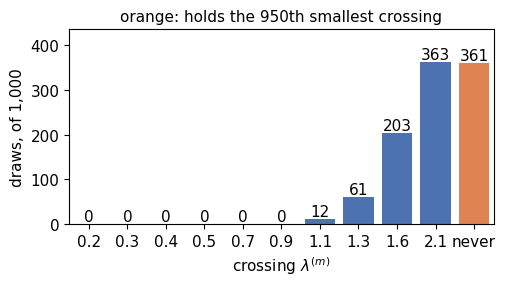

$$
\begin{aligned}
\text{draws that cross} &= 1{,}000 - 361 = 639 \\ \lambda_\beta &= \text{950th smallest} \\ &= \infty \\ \lambda_{\mathrm{BCA}} &= \max(\hat\lambda, \lambda_\beta) \\ &= \max(1.6, \infty) \\ &= \infty
\end{aligned}
$$

**So:** 361 of the 1,000 draws never cross, so only 639 crossings are finite, fewer than 950, and the 950th smallest is ∞. With 10 scores, BCA refuses to promise anything.

In [10]:
# Step A.4 tools: BCA with equal weights, exactly as production computes it, and the comparison with production.
def lesson_a_bca(scores, seed):
    """BCA with equal weights: sorted scores, crossing ranks, sorted crossings, lambda_hat, lambda_beta, threshold.
    The callers have checked the scores and the seed."""
    s = np.sort(np.asarray(scores, dtype=float))
    ranks = lesson_a_crossing_parts(lesson_a_exponentials(s.size, seed))[0]
    cross = np.sort(np.where(ranks > 0, s[np.maximum(ranks, 1) - 1], np.inf))
    lam_hat = float(s[lesson_a_rank_hat(s.size) - 1])
    lam_beta = float(cross[lesson_a_need - 1])
    return {"s": s, "ranks": ranks, "cross": cross, "lam_hat": lam_hat, "lam_beta": lam_beta,
            "lam_bca": max(lam_hat, lam_beta)}


def lesson_a_production():
    """Production BCA's calibrate() from calibration/wbcp.py, or None when the notebook does not run from the
    repository root."""
    import os
    import sys
    sys.dont_write_bytecode = True
    if os.getcwd() not in sys.path:
        sys.path.insert(0, os.getcwd())
    try:
        from calibration.wbcp import calibrate
    except ImportError:
        return None
    return calibrate


def lesson_a_production_check(scores, seed, quiet=False):
    """Compare this Lesson's BCA with production calibrate() on the same scores and seed; stop if they differ."""
    b = lesson_a_bca(scores, seed)
    calibrate = lesson_a_production()
    if calibrate is None:
        print("Production check skipped: run this notebook from the repository root to compare with "
              "calibration/wbcp.py.")
        return
    cal = calibrate(np.asarray(scores, dtype=float), np.random.default_rng(seed))
    same = bool(np.array_equal(cal.crossings, b["cross"]))
    lesson_check(cal.lambda_hat == b["lam_hat"] and cal.lambda_hpd == b["lam_beta"]
                 and cal.threshold == b["lam_bca"] and same, "this Lesson's BCA differs from production calibrate()")
    if quiet:
        lesson_show("Checked against production `calibrate`: the same numbers, crossing for crossing.")
        return
    lesson_table(["quantity", "this Lesson", "production `calibrate`"],
                 [["plain quantile $\\hat\\lambda$", lesson_a_g(b["lam_hat"], False),
                   lesson_a_g(cal.lambda_hat, False) + " (`lambda_hat`)"],
                  ["95% value $\\lambda_\\beta$", lesson_a_g(b["lam_beta"], False),
                   lesson_a_g(cal.lambda_hpd, False) + " (`lambda_hpd`)"],
                  ["threshold $\\lambda_{\\mathrm{BCA}}$", lesson_a_g(b["lam_bca"], False),
                   lesson_a_g(cal.threshold, False) + " (`threshold`)"],
                  ["the 1,000 sorted crossings", "as in the chart", "identical (`crossings`)"]],
                 note="**So:** production gives the same numbers, crossing for crossing: this Lesson's draws are "
                      "production's draws.")


def lesson_a_thousand(try_scores, try_seed, chart=False):
    """Step A.4: where the 1,000 draws cross, BCA's 95% value and its threshold. Tied scores share one crossing
    value, so the draws are counted by value."""
    if lesson_a_valid_scores(try_scores) is None or not lesson_a_seed_ok(try_seed):
        return
    b = lesson_a_bca(try_scores, try_seed)
    s, ranks = b["s"], b["ranks"]
    n = int(s.size)
    values = np.unique(s)
    finite = b["cross"][np.isfinite(b["cross"])]
    never = int(lesson_a_draws - finite.size)
    heights = np.array([int((finite == v).sum()) for v in values] + [never])
    labels = [lesson_a_g(v, False) for v in values] + ["never"]
    hold = int(np.searchsorted(np.cumsum(heights), lesson_a_need))   # the bar that holds the 950th smallest
    j_beta = int(np.sort(np.where(ranks > 0, ranks, n + 1))[lesson_a_need - 1])   # its rank (n + 1: never)
    if chart:
        with plt.rc_context({"font.size": 11}):
            fig, ax = plt.subplots(figsize=(5.2, 3))
            ax.margins(x=0.01)
            colors = ["#4C72B0"] * heights.size
            colors[hold] = "#DD8452"
            ax.bar(np.arange(heights.size), heights, color=colors)
            for k, h in enumerate(heights):
                ax.text(k, h, str(int(h)), ha="center", va="bottom", fontsize=11)
            ax.set_xticks(np.arange(heights.size))
            ax.set_xticklabels(labels)
            ax.set_ylim(0, heights.max() * 1.2)
            ax.set_xlabel(r"crossing $\lambda^{(m)}$")
            ax.set_ylabel("draws, of 1,000")
            ax.set_title("orange: holds the 950th smallest crossing", fontsize=11)
            fig.tight_layout()
            plt.show()
    else:
        shown = []                   # one row per value as shown: values that round alike share a row
        for k, h in enumerate(heights):
            if h > 0 and shown and shown[-1][0] == labels[k]:
                shown[-1][1] += int(h)
            elif h > 0:
                shown.append([labels[k], int(h)])
        lesson_table(["crossing", "draws, of 1,000"], [[a, f"{h:,}"] for a, h in shown])
    crossed = int(lesson_a_draws - never)
    lines = [lesson_tex(r"\text{draws that cross} &= 1{,}000 - <<nv>> = <<c>>", nv=never, c=crossed)]
    lines.append(r"\lambda_\beta &= \text{950th smallest}")         # its value on the next line, to fit a phone
    if math.isinf(b["lam_beta"]):
        lines.append(r"&= \infty")
    else:
        lines.append(lesson_tex(r"&= s_{(<<j>>)} = <<v>>", j=j_beta, v=lesson_a_g(b["lam_beta"])))
    lines += [r"\lambda_{\mathrm{BCA}} &= \max(\hat\lambda, \lambda_\beta)",          # one step per line
              lesson_tex(r"&= \max(<<a>>, <<b>>)", a=lesson_a_g(b["lam_hat"]), b=lesson_a_g(b["lam_beta"])),
              r"&= " + lesson_a_g(b["lam_bca"])]
    if math.isinf(b["lam_bca"]):
        note = lesson_text("**So:** <<nv>> of the 1,000 draws never cross, so only <<c>> crossings are finite, fewer "
                           "than 950, and the 950th smallest is ∞. With <<n>>, BCA refuses to promise anything.",
                           nv=never, c=crossed, n=lesson_a_count(n, "score"))
    else:
        note = lesson_text("**So:** BCA is 95% sure that at least 90% of future scores are at or below <<v>>.",
                           v=lesson_a_g(b["lam_bca"], False))
    lesson_math(*lines, note=note)
    if not chart:
        lesson_a_production_check(try_scores, try_seed, quiet=True)


lesson_a_thousand(lesson_a_scores, lesson_a_seed, chart=True)

**How this relates to split conformal.** Suppose every random weight $E_i$ were fixed at 1 instead of drawn. Then the running total at $j$ would be just $j$, and the target would be $0.9\,(n + 1)$. So the crossing would be the score of rank $\lceil 0.9\,(n + 1) \rceil$: split conformal's threshold from Step A.2.

In [11]:
def lesson_a_all_ones(scores, seed):
    """Step A.4: the crossing when every random weight is fixed at 1, against the scatter of the 1,000 real draws."""
    b = lesson_a_bca(scores, seed)
    s, n = b["s"], int(b["s"].size)
    j_one = int(lesson_a_crossing_parts(np.ones((1, n + 1)))[0][0])
    lesson_check(j_one == lesson_a_rank_sc(n), "with every weight at 1, the crossing should be split conformal's rank")
    lesson_check(j_one == n, "the note below assumes that split conformal's rank is the top one")
    counts = np.bincount(b["ranks"], minlength=n + 1)          # counts[0]: draws that never cross
    target = lesson_a_ninety * (n + 1)
    lesson_math(r"\text{running total at } j &= 1 + \dots + 1 = j",
                lesson_tex(r"\text{target} &= 0.9 \times (<<n>> + 1) = <<t>>", n=n, t=lesson_a_g(target)),
                lesson_tex(r"j^* &= \lceil <<t>> \rceil = <<j>>", t=lesson_a_g(target), j=j_one),
                lesson_tex(r"\text{crossing} &= s_{(<<j>>)} = <<v>>", j=j_one, v=lesson_a_g(s[j_one - 1])),
                note=lesson_text("**So:** with every weight fixed at 1, the crossing is $s_{(<<j>>)} = <<v>>$, split "
                                 "conformal's threshold. Drawn weights scatter the crossing around that rank: in the "
                                 "chart, <<lo>> draws cross below $s_{(<<j>>)}$, <<at>> cross at it, and <<nv>> never "
                                 "cross. $\\lambda_\\beta$ takes the high end of that scatter, here ∞. That is BCA's "
                                 "trade: a higher threshold, in exchange for a promise about the data in hand instead "
                                 "of one on average. Step A.6 checks that promise.", j=j_one,
                                 v=lesson_a_g(s[j_one - 1]), lo=int(counts[1:j_one].sum()), at=int(counts[j_one]),
                                 nv=int(counts[0])))


lesson_a_all_ones(lesson_a_scores, lesson_a_seed)

$$
\begin{aligned}
\text{running total at } j &= 1 + \dots + 1 = j \\ \text{target} &= 0.9 \times (10 + 1) = 9.9 \\ j^* &= \lceil 9.9 \rceil = 10 \\ \text{crossing} &= s_{(10)} = 2.1
\end{aligned}
$$

**So:** with every weight fixed at 1, the crossing is $s_{(10)} = 2.1$, split conformal's threshold. Drawn weights scatter the crossing around that rank: in the chart, 276 draws cross below $s_{(10)}$, 363 cross at it, and 361 never cross. $\lambda_\beta$ takes the high end of that scatter, here ∞. That is BCA's trade: a higher threshold, in exchange for a promise about the data in hand instead of one on average. Step A.6 checks that promise.

**Production check.** The repository's production code, the function `calibrate` in `calibration/wbcp.py`, runs these same steps. Given the same scores and a random-number generator started from the same seed, it must return the same numbers, crossing for crossing. The check skips itself when the notebook does not run from the repository's root folder.

In [12]:
lesson_a_production_check(lesson_a_scores, lesson_a_seed)

| quantity | this Lesson | production `calibrate` |
|---|---|---|
| plain quantile $\hat\lambda$ | 1.6 | 1.6 (`lambda_hat`) |
| 95% value $\lambda_\beta$ | ∞ | ∞ (`lambda_hpd`) |
| threshold $\lambda_{\mathrm{BCA}}$ | ∞ | ∞ (`threshold`) |
| the 1,000 sorted crossings | as in the chart | identical (`crossings`) |

**So:** production gives the same numbers, crossing for crossing: this Lesson's draws are production's draws.

In [13]:
# Try it: change the seed (a whole number, 0 or more) or the scores (1 to 2,000 numbers), then rerun this cell.
# With only 10 scores BCA refuses (Step A.5 says why). To see a finite threshold, use 30 scores,
# for example try_scores = [round(0.1 * k, 1) for k in range(1, 31)].
try_seed, try_scores = 2026, [0.4, 1.3, 0.2, 2.1, 0.7, 0.9, 0.3, 1.6, 0.5, 1.1]
lesson_a_thousand(try_scores, try_seed)

| crossing | draws, of 1,000 |
|---|---|
| 0.9 | 3 |
| 1.1 | 10 |
| 1.3 | 56 |
| 1.6 | 196 |
| 2.1 | 381 |
| never | 354 |

$$
\begin{aligned}
\text{draws that cross} &= 1{,}000 - 354 = 646 \\ \lambda_\beta &= \text{950th smallest} \\ &= \infty \\ \lambda_{\mathrm{BCA}} &= \max(\hat\lambda, \lambda_\beta) \\ &= \max(1.6, \infty) \\ &= \infty
\end{aligned}
$$

**So:** 354 of the 1,000 draws never cross, so only 646 crossings are finite, fewer than 950, and the 950th smallest is ∞. With 10 scores, BCA refuses to promise anything.

Checked against production `calibrate`: the same numbers, crossing for crossing.

### Step A.5 · Why at least 29 scores

Step A.4's BCA refused because too many draws never crossed. A draw never crosses exactly when the extra weight alone holds more than $\alpha$ of the total, so that the $n$ scores together hold less than 90%:

$$
\text{draw } m \text{ never crosses} \iff \frac{E_{n+1}}{\sum_{i=1}^{n+1} E_i} > \alpha
$$

With random Exponential(1) weights, this has chance exactly $(1-\alpha)^n$; the reason follows the next cell. And $\lambda_\beta$ is finite only if at least 950 of the 1,000 draws cross, that is, if at most 5% never cross. So BCA needs $(1-\alpha)^n \le 1 - \beta = 0.05$, up to sampling noise.

$$
\begin{aligned}
(1-\alpha)^{10} &= 0.9^{10} = 0.3487 \\ (1-\alpha)^{28} &= 0.9^{28} = 0.0523 > 0.05 \\ (1-\alpha)^{29} &= 0.9^{29} = 0.0471 \le 0.05
\end{aligned}
$$

**So:** with 28 or fewer scores, more than 5% of draws are expected never to cross, so (sampling noise aside) $\lambda_\beta = \infty$ whatever the scores are: BCA cannot promise anything. From 29 scores on, it can.

| scores $n$ | expected share that never cross | never crossed, of 1,000 | $\lambda_\beta$ |
|---|---|---|---|
| 10 | 0.3487 | 361 | ∞ |
| 28 | 0.0523 | 54 | ∞ |
| 29 | 0.0471 | 41 | finite |
| 30 | 0.0424 | 30 | finite |

The row for 10 scores repeats Step A.4: 361 of its 1,000 draws never crossed.

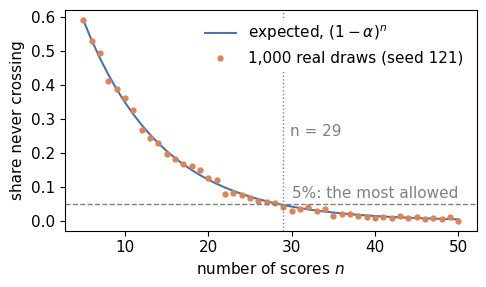

**Sampling noise.** The real draws follow the expected share closely, but not exactly. At 28 scores, one run of 1,000 draws still finds at most 50 that never cross, and so a finite $\lambda_\beta$, with chance 40%. At 29 scores it finds more than 50, and refuses, with chance 30%. Seed 121 switches exactly at 29, and it was picked so that its 1,000-draw answers in Steps A.5 to A.8 match the exact ones (the code checks this). Other seeds can switch a few scores earlier or later, and can differ from the exact answers near any boundary.

In [14]:
# Step A.5 tools.
def lesson_a_never_count(n, seed):
    """How many of the 1,000 draws never cross with n scores. Only the weights matter, not the scores."""
    return int((lesson_a_crossing_parts(lesson_a_exponentials(n, seed))[0] == 0).sum())


def lesson_a_min_scores():
    """The fewest scores with (1 - alpha)^n <= 0.05, in exact arithmetic."""
    n = 1
    while lesson_a_ninety ** n > Fraction(1, 20):
        n += 1
    return n


def lesson_a_binom_at_most(k, n, p):
    """P(Binomial(n, p) <= k), in floating point."""
    return sum(math.comb(n, i) * p ** i * (1 - p) ** (n - i) for i in range(k + 1))


def lesson_a_small(p, digits=4):
    """A chance for LaTeX: 4 decimals, or a power of ten when it is tiny."""
    if p >= 10 ** -digits:
        return f"{p:.{digits}f}"
    mantissa, exponent = f"{p:.1e}".split("e")
    return mantissa + r" \times 10^{" + str(int(exponent)) + "}"


def lesson_a_vs_digits(p, bar=0.05, digits=4):
    """How many decimals p needs so that, rounded, it still sits on its own side of `bar`: 4 at least, and more near
    the bar (0.04998, not 0.0500, for a chance just under 0.05)."""
    p = float(p)
    for d in range(digits, 16):
        v = float(f"{p:.{d}f}")
        if p == bar or ((p < bar) == (v < bar) and v != bar):
            return d
    return 15


def lesson_a_vs(p, bar=0.05, digits=4, latex=True):
    """A chance shown next to its comparison with `bar`: 4 decimals, more when 4 would not show which side of `bar`
    it is on, and a power of ten when it is tiny."""
    p = float(p)
    if 0 < p < 10 ** -digits:
        return lesson_a_small(p, digits) if latex else f"{p:.1e}".replace("-", "−")
    return f"{p:.{lesson_a_vs_digits(p, bar, digits)}f}"


def lesson_a_why_29(seed):
    """Step A.5: the chance that a draw never crosses, worked, then against BCA's real draws."""
    low = lesson_a_min_scores()
    allowed = lesson_a_draws - lesson_a_need                       # 50 draws may fail to cross
    lesson_math(lesson_tex(r"(1-\alpha)^{10} &= 0.9^{10} = <<p:4>>", p=0.9 ** 10),
                lesson_tex(r"(1-\alpha)^{<<a>>} &= 0.9^{<<a>>} = <<p:4>> > 0.05", a=low - 1, p=0.9 ** (low - 1)),
                lesson_tex(r"(1-\alpha)^{<<a>>} &= 0.9^{<<a>>} = <<p:4>> \le 0.05", a=low, p=0.9 ** low),
                note=lesson_text("**So:** with <<a>> or fewer scores, more than 5% of draws are expected never to "
                                 "cross, so (sampling noise aside) $\\lambda_\\beta = \\infty$ whatever the scores "
                                 "are: BCA cannot promise anything. From <<b>> scores on, it can.", a=low - 1, b=low))
    never = {n: lesson_a_never_count(n, seed) for n in range(5, 51)}
    lesson_table(["scores $n$", "expected share that never cross", "never crossed, of 1,000", "$\\lambda_\\beta$"],
                 [[str(n), f"{0.9 ** n:.4f}", str(never[n]), "∞" if never[n] > allowed else "finite"]
                  for n in (10, low - 1, low, low + 1)],
                 note=lesson_text("The row for 10 scores repeats Step A.4: <<v>> of its 1,000 draws never crossed.",
                                  v=never[10]))
    with plt.rc_context({"font.size": 11}):
        fig, ax = plt.subplots(figsize=(5, 3))
        ns = np.arange(5, 51)
        ax.plot(ns, 0.9 ** ns, color="#4C72B0", lw=1.5, label=r"expected, $(1-\alpha)^n$")
        ax.plot(ns, [never[int(n)] / lesson_a_draws for n in ns], "o", ms=3.5, color="#DD8452",
                label=f"1,000 real draws (seed {seed})")
        ax.axhline(0.05, color="gray", ls="--", lw=1)
        ax.axvline(low, color="gray", ls=":", lw=1)
        ax.text(50, 0.06, "5%: the most allowed", ha="right", va="bottom", fontsize=11, color="gray")
        ax.text(low + 0.8, 0.25, f"n = {low}", fontsize=11, color="gray")
        ax.set_xlabel("number of scores $n$")
        ax.set_ylabel("share never crossing")
        ax.legend(fontsize=11, frameon=True, framealpha=1, facecolor="white", edgecolor="none")
        fig.tight_layout()
        plt.show()
    first = next(n for n in range(5, 51) if never[n] <= allowed and all(never[k] <= allowed for k in range(n, 51)))
    lesson_check(first == low, "the Lesson's seed was chosen to switch exactly at the exact minimum")
    accept_early = lesson_a_binom_at_most(allowed, lesson_a_draws, 0.9 ** (low - 1))
    refuse_late = 1 - lesson_a_binom_at_most(allowed, lesson_a_draws, 0.9 ** low)
    lesson_show(lesson_text("**Sampling noise.** The real draws follow the expected share closely, but not exactly. "
                            "At <<a>> scores, one run of 1,000 draws still finds at most 50 that never cross, and so "
                            "a finite $\\lambda_\\beta$, with chance <<p:%0>>. At <<b>> scores it finds more than 50, "
                            "and refuses, with chance <<q:%0>>. Seed <<sd>> switches exactly at <<b>>, and it was "
                            "picked so that its 1,000-draw answers in Steps A.5 to A.8 match the exact ones (the code "
                            "checks this). Other seeds can switch a few scores earlier or later, and can differ from "
                            "the exact answers near any boundary.", a=low - 1, b=low, p=accept_early, q=refuse_late,
                            sd=seed))


lesson_a_why_29(lesson_a_seed)

*Deeper: skip on a first read.*

**Why $(1-\alpha)^n$.** Write $S = E_1 + \dots + E_n$. The draw never crosses when $E_{n+1} > \alpha\,(S + E_{n+1})$, which rearranges to $E_{n+1} > k\,S$ with $k = \alpha/(1-\alpha) = 1/9$. Two facts finish it:
- for a fixed $S$, an Exponential(1) weight lands above $kS$ with chance $e^{-kS}$, so the chance is the average of $e^{-kS} = e^{-kE_1} \times \dots \times e^{-kE_n}$;
- the weights are independent, and each factor $e^{-kE_i}$ averages $1/(1+k) = 0.9$.

So the chance is $0.9^n$. That is also the chance that the largest of $n$ scores covers less than 90% of future scores: Step A.2 found 34.9% for 10 scores, against $0.9^{10} = 0.3487$. A draw that never crosses is a plausible guess in which exactly that happens.

In [15]:
def lesson_a_never_try(try_n, try_seed):
    """Step A.5, for any n: the expected share of draws that never cross, and a real run of 1,000 draws."""
    if not lesson_a_whole(try_n, 1, 2000):
        lesson_show("Pick a whole number of scores from 1 to 2,000.")
        return
    if not lesson_a_seed_ok(try_seed):
        return
    n = int(try_n)
    allowed = lesson_a_draws - lesson_a_need
    expected_ok = lesson_a_ninety ** n <= Fraction(1, 20)
    nv = lesson_a_never_count(n, try_seed)
    if nv <= allowed:
        verdict = lesson_text("at least 950 draws cross, so $\\lambda_\\beta$ is finite: with <<n>>, BCA can promise "
                              "something.", n=lesson_a_count(n, "score"))
    else:
        verdict = lesson_text("more than 50 draws never cross, so $\\lambda_\\beta = \\infty$: with <<n>>, BCA cannot "
                              "promise anything.", n=lesson_a_count(n, "score"))
    if expected_ok != (nv <= allowed):
        verdict += " This run disagrees with the expected share: sampling noise near the boundary."
    lesson_math(lesson_tex(r"(1-\alpha)^{<<n>>} &= 0.9^{<<n>>}", n=n),
                lesson_tex(r"&= <<p>> <<c>> 0.05", p=lesson_a_vs(0.9 ** n), c=r"\le" if expected_ok else ">"),
                lesson_tex(r"\text{never crossed} &= <<v>> \text{ of } 1{,}000 \quad (<<c>> 50)", v=nv,
                           c=r"\le" if nv <= allowed else ">"),
                note="**So:** " + verdict)

In [16]:
# Try it: change the number of scores n (1 to 2,000) or the seed (a whole number, 0 or more), then rerun this cell.
try_n, try_seed = 28, 121
lesson_a_never_try(try_n, try_seed)

$$
\begin{aligned}
(1-\alpha)^{28} &= 0.9^{28} \\ &= 0.0523 > 0.05 \\ \text{never crossed} &= 54 \text{ of } 1{,}000 \quad (> 50)
\end{aligned}
$$

**So:** more than 50 draws never cross, so $\lambda_\beta = \infty$: with 28 scores, BCA cannot promise anything.

### Step A.6 · The exact shortcut

With equal weights (every row's fixed weight is 1; only the random $E_i$ vary), $\lambda_\beta$ lands on a rank that a formula gives directly:

$$
\lambda_\beta \approx s_{(n - x(n))}
$$

- $x(n)$: the most scores allowed above the threshold. It is the largest $x$ with $P(\mathrm{Binomial}(n, \alpha) \le x) \le 1 - \beta$. When even $x = 0$ fails, $x(n) = -1$ ("none") and $\lambda_\beta = \infty$.
- $\mathrm{Binomial}(n, \alpha)$: the number of heads in $n$ coin flips that each land heads with chance $\alpha$.
- The chance of exactly $k$ heads is $\binom{n}{k}\,\alpha^k (1-\alpha)^{n-k}$, where $\binom{n}{k}$ ("$n$ choose $k$") counts the ways to pick which $k$ of the $n$ flips land heads. $P(\mathrm{Binomial}(n, \alpha) \le x)$ adds these chances up for $k = 0, \dots, x$. For $x = 0$ it is $(1-\alpha)^n$, Step A.5's number.

The "≈" turns into "=" as the number of draws grows. For $n = 100$ scores:

In [17]:
# Step A.6 tools: binomial chances in exact integer arithmetic (P(Binomial(n, 0.1) <= x) = sum / 10^n).
def lesson_a_count_at_most(x, n):
    """10^n times P(Binomial(n, 0.1) <= x), as an exact whole number."""
    return sum(math.comb(n, i) * 9 ** (n - i) for i in range(min(x, n) + 1)) if x >= 0 else 0


def lesson_a_cdf(x, n):
    """P(Binomial(n, 0.1) <= x), computed exactly, then rounded to a float."""
    return lesson_a_count_at_most(x, n) / 10 ** n


def lesson_a_within(x, n):
    """True when P(Binomial(n, 0.1) <= x) <= 0.05, decided exactly."""
    return 20 * lesson_a_count_at_most(x, n) <= 10 ** n


def lesson_a_x(n):
    """x(n): the largest x with P(Binomial(n, 0.1) <= x) <= 0.05, or -1 when even x = 0 fails."""
    best = -1
    for x in range(n + 1):
        if not lesson_a_within(x, n):
            break
        best = x
    return best


def lesson_a_binomial_table(n):
    """Step A.6: the binomial chances up to just past x(n), and the ranks they give."""
    x_n = lesson_a_x(n)
    lesson_table(["$x$", lesson_tex(r"${P(\mathrm{Binomial}(<<n>>, 0.1) \le x)}$", n=n), "at most 0.05?"],
                 [[str(x), f"{lesson_a_cdf(x, n):.5f}", "yes" if lesson_a_within(x, n) else "no"]
                  for x in range(max(x_n, 0) + 3)])
    j1 = lesson_a_rank_hat(n)
    lesson_math(lesson_tex(r"x(<<n>>) &= <<x>> \quad (\text{the largest } x \text{ marked yes})", n=n, x=x_n),
                lesson_tex(r"\lambda_\beta &\approx s_{(n - x(n))} = s_{(<<n>> - <<x>>)} = s_{(<<j>>)}", n=n, x=x_n,
                           j=n - x_n),
                lesson_tex(r"\hat\lambda &= s_{(\lceil 0.9 \times <<n>> \rceil)} = s_{(<<j>>)}", n=n, j=j1),
                note=lesson_text("**So:** with <<n>> scores, BCA's 95% value lets only <<x>> scores sit above it, "
                                 "where the plain quantile lets <<p>>.", n=n, x=x_n, p=n - j1))


lesson_a_binomial_table(100)

| $x$ | ${P(\mathrm{Binomial}(100, 0.1) \le x)}$ | at most 0.05? |
|---|---|---|
| 0 | 0.00003 | yes |
| 1 | 0.00032 | yes |
| 2 | 0.00194 | yes |
| 3 | 0.00784 | yes |
| 4 | 0.02371 | yes |
| 5 | 0.05758 | no |
| 6 | 0.11716 | no |

$$
\begin{aligned}
x(100) &= 4 \quad (\text{the largest } x \text{ marked yes}) \\ \lambda_\beta &\approx s_{(n - x(n))} = s_{(100 - 4)} = s_{(96)} \\ \hat\lambda &= s_{(\lceil 0.9 \times 100 \rceil)} = s_{(90)}
\end{aligned}
$$

**So:** with 100 scores, BCA's 95% value lets only 4 scores sit above it, where the plain quantile lets 10.

**Why.** Let $q$ be the score that exactly 90% of future scores stay at or below. Each held-out score lands above $q$ with chance $\alpha$, like a coin flip. The threshold $s_{(n-x)}$ falls below $q$ exactly when at most $x$ of the $n$ scores landed above $q$, which has chance $P(\mathrm{Binomial}(n, \alpha) \le x)$. Keeping that chance at or below 5% makes us 95% sure that $s_{(n-x)} \ge q$: the promise.

BCA's draws reach the same answer. With many draws, the share that cross at or below $s_{(j)}$ settles at $1 - P(\mathrm{Binomial}(n, \alpha) \le n - j)$. The next cell checks this with BCA's real 1,000 draws on 100 made-up scores from Step A.2's source.

In [18]:
def lesson_a_made_up(n, seed=2026):
    """n made-up scores from Step A.2's source: spread evenly between 0 and 3."""
    return np.random.default_rng(seed).uniform(0.0, 3.0, int(n))


def lesson_a_shortcut_ok(try_n, try_seed):
    """True when Step A.6's inputs are usable; otherwise one short message saying what to enter."""
    if not lesson_a_whole(try_n, 1, 2000):
        lesson_show("Pick a whole number of scores from 1 to 2,000.")
        return False
    return lesson_a_seed_ok(try_seed)


def lesson_a_shortcut_check(try_n, try_seed, explain_x=False, claim=False):
    """Step A.6: BCA's 1,000 real draws against the exact shortcut, on n made-up scores."""
    if not lesson_a_shortcut_ok(try_n, try_seed):
        return
    n = int(try_n)
    scores = lesson_a_made_up(n)
    b = lesson_a_bca(scores, try_seed)
    s, ranks = b["s"], b["ranks"]
    x_n = lesson_a_x(n)
    j_exact = n - x_n if x_n >= 0 else n + 1                     # n + 1 stands for "never": infinity
    j_draws = int(np.sort(np.where(ranks > 0, ranks, n + 1))[lesson_a_need - 1])
    if claim:
        lesson_check(j_draws == j_exact, "the Lesson's seed was chosen to match the shortcut here")

    def share(j):
        """The share of the 1,000 draws that cross at or below s_(j)."""
        return float(((ranks > 0) & (ranks <= j)).mean())

    lo = max(1, min(j_exact, j_draws, n) - 2)
    hi = min(n, max(min(j_exact, n), min(j_draws, n)) + 1)
    lesson_table(["rank $j$", "score $s_{(j)}$", "share of the 1,000 draws crossing at or below $s_{(j)}$",
                  "exact chance"],
                 [[f"{j:,}", lesson_a_g(s[j - 1], False), lesson_txt(share(j)), lesson_txt(1 - lesson_a_cdf(n - j, n))]
                  for j in range(lo, hi + 1)],
                 note="Exact chance, the share that many draws would give: "
                      "$1 - P(\\mathrm{Binomial}(n, 0.1) \\le n - j)$.")

    def at(j):
        return r"\infty" if j > n else lesson_tex(r"s_{(<<j>>)} = <<v>>", j=j, v=lesson_a_g(s[j - 1]))

    if explain_x:                     # each chance on one line, its comparison with 0.05 on the next (phone width)
        lines = []
        for x in ((x_n, x_n + 1) if x_n >= 0 else (0,)):
            lines += [lesson_tex(r"& P(\mathrm{Binomial}(<<n>>, 0.1) \le <<x>>)", n=n, x=x),
                      lesson_tex(r"&\quad = <<p>> <<c>> 0.05", p=lesson_a_vs(lesson_a_cdf(x, n)),
                                 c=r"\le" if lesson_a_within(x, n) else ">")]
        lesson_math(*lines)
    lines = [lesson_tex(r"x(<<n>>) &= <<x>>", n=n, x=x_n) + (r" \quad (\text{none})" if x_n < 0 else "")]
    if x_n >= 0:
        lines += [lesson_tex(r"\text{shortcut: } \lambda_\beta &\approx s_{(<<n>> - <<x>>)}", n=n, x=x_n),
                  r"&= " + at(j_exact)]
    else:
        lines.append(r"\text{shortcut: } \lambda_\beta &= \infty")
    lines += [r"\text{1,000 draws: } \lambda_\beta &= " + at(j_draws),
              r"\lambda_{\mathrm{BCA}} &= \max(\hat\lambda, \lambda_\beta)",               # one step per line
              lesson_tex(r"&= \max(<<a>>,\ <<b>>)", a=lesson_a_g(b["lam_hat"]), b=lesson_a_g(b["lam_beta"])),
              r"&= " + lesson_a_g(b["lam_bca"])]

    def rank_text(j):
        return "∞" if j > n else "$s_{(" + lesson_num(j) + ")}$"

    if j_draws > n:
        how = lesson_text("Even at $s_{(<<n>>)}$, the largest score, only <<p>> of the draws have crossed, so the "
                          "950th smallest crossing is ∞.", n=lesson_num(n), p=share(n))
    elif j_draws == 1:
        how = lesson_text("Already at $s_{(1)}$, <<p>> of the draws have crossed, so the 950th smallest crossing is "
                          "$s_{(1)}$.", p=share(1))
    else:
        how = lesson_text("At $s_{(<<a>>)}$ only <<p>> of the draws have crossed, and at $s_{(<<b>>)}$ <<q>> have, "
                          "so the 950th smallest crossing is $s_{(<<b>>)}$.", a=lesson_num(j_draws - 1),
                          b=lesson_num(j_draws), p=share(j_draws - 1), q=share(j_draws))
    if j_draws == j_exact > n:
        tail = "The shortcut agrees: no rank's exact chance reaches 0.95, so $x(n) = -1$ and $\\lambda_\\beta = \\infty$."
    elif j_draws == j_exact:
        tail = "The shortcut makes the same choice with the exact chances, the first rank whose exact chance reaches " \
               "0.95, and lands on the same score."
    else:
        tail = lesson_text("The shortcut makes the same choice with the exact chances, the first rank whose exact "
                           "chance reaches 0.95, and lands on <<e>>: the two differ here by sampling noise near the "
                           "95% line.", e=rank_text(j_exact))
    lesson_math(*lines, note="**So:** $\\lambda_\\beta$ sits at the first rank whose share reaches 0.950. " + how
                             + " " + tail)
    lesson_a_production_check(scores, try_seed, quiet=True)


lesson_a_shortcut_check(100, lesson_a_seed, claim=True)

| rank $j$ | score $s_{(j)}$ | share of the 1,000 draws crossing at or below $s_{(j)}$ | exact chance |
|---|---|---|---|
| 94 | 2.76 | 0.895 | 0.883 |
| 95 | 2.826 | 0.942 | 0.942 |
| 96 | 2.84 | 0.973 | 0.976 |
| 97 | 2.841 | 0.995 | 0.992 |

Exact chance, the share that many draws would give: $1 - P(\mathrm{Binomial}(n, 0.1) \le n - j)$.

$$
\begin{aligned}
x(100) &= 4 \\ \text{shortcut: } \lambda_\beta &\approx s_{(100 - 4)} \\ &= s_{(96)} = 2.84 \\ \text{1,000 draws: } \lambda_\beta &= s_{(96)} = 2.84 \\ \lambda_{\mathrm{BCA}} &= \max(\hat\lambda, \lambda_\beta) \\ &= \max(2.714,\ 2.84) \\ &= 2.84
\end{aligned}
$$

**So:** $\lambda_\beta$ sits at the first rank whose share reaches 0.950. At $s_{(95)}$ only 0.942 of the draws have crossed, and at $s_{(96)}$ 0.973 have, so the 950th smallest crossing is $s_{(96)}$. The shortcut makes the same choice with the exact chances, the first rank whose exact chance reaches 0.95, and lands on the same score.

Checked against production `calibrate`: the same numbers, crossing for crossing.

This rule has a name: the **exact binomial test**. Statisticians also know it as Wilks' tolerance limit; in conformal prediction it is Vovk's training-conditional bound. With equal weights, BCA's 1,000 random draws are a sampled version of it: they reach the same answer up to sampling noise, and add no information beyond it. What BCA does add over split conformal is the kind of promise (Step A.2): 95% sure for the data in hand, not only on average. Part 2 measures how often 1,000 draws disagree with the exact answer.

**Worked example: the promise, checked.** The next cell reruns Step A.2's simulation on the same 40,000 made-up data sets of 100 scores, and adds a row for BCA's threshold in exact form, $s_{(n - x(n))}$.

In [19]:
def lesson_a_promise_check(try_n):
    """Step A.6, worked example: Step A.2's made-up data sets again, now with BCA's threshold in exact form."""
    if not lesson_a_whole(try_n, 1, 2000):
        lesson_show("Pick a whole number of scores from 1 to 2,000.")
        return
    n = int(try_n)
    x_n = lesson_a_x(n)
    j1, j2, j3 = lesson_a_rank_hat(n), lesson_a_rank_sc(n), n - x_n      # j3 = n + 1 (infinity) when x(n) = -1
    sets, cover = lesson_a_coverage(n, (j1, j2, j3))
    short = {j: float((cover[j] < 0.9).mean()) for j in (j1, j2, j3)}
    mean = {j: float(cover[j].mean()) for j in (j1, j2, j3)}
    rows = [[name, f"{j:,}" if j <= n else "above $n$: ∞", lesson_txt(mean[j]), lesson_pct(short[j], 1, latex=False)]
            for name, j in (("plain quantile", j1), ("split conformal", j2), ("BCA, exact form", j3))]
    if x_n < 0:
        note = lesson_text("**So:** with only <<n>>, $x(<<k>>) = -1$, so BCA's threshold is ∞ (Step A.5): it never "
                           "covers less than 90%, but it promises nothing useful.", n=lesson_a_count(n, "score"),
                           k=lesson_num(n))
    else:
        exact = lesson_tex(r"$P(\mathrm{Binomial}(<<n>>, 0.1) \le <<x>>) = <<c>>$", n=n, x=x_n,
                           c=lesson_a_vs(lesson_a_cdf(x_n, n)))
        if short[j3] <= 0.05:
            within = "within its 5%, and close to the exact chance from Step A.6's \"Why\", " + exact
        else:
            within = ("a little above 5% only by the luck of these made-up data sets: the exact chance from Step "
                      "A.6's \"Why\" is " + exact)
        note = lesson_text("**So:** over the same <<k>> data sets of <<n>>, BCA's threshold $s_{(<<j>>)}$ covers less "
                           "than 90% in <<p:%1>> of them: <<w>>. Split conformal's covers less than 90% in <<q:%1>>. "
                           "The price is a higher threshold: on average BCA's covers <<a>> of future scores, not "
                           "<<b>>.", k=sets, n=lesson_a_count(n, "score"), j=lesson_num(j3), p=short[j3], w=within,
                           q=short[j2], a=mean[j3], b=mean[j2])
    lesson_table(["threshold", "rank", "average share covered", "data sets covering under 90%"], rows, note=note)


def lesson_a_exact_try(try_n, try_seed):
    """Step A.6's Try-it: the shortcut against BCA's 1,000 draws, then the promise, for n made-up scores. Unusable
    inputs get one message and nothing else."""
    if lesson_a_shortcut_ok(try_n, try_seed):
        lesson_a_shortcut_check(try_n, try_seed, explain_x=True)
        lesson_a_promise_check(try_n)


lesson_a_promise_check(100)

| threshold | rank | average share covered | data sets covering under 90% |
|---|---|---|---|
| plain quantile | 90 | 0.891 | 58.1% |
| split conformal | 91 | 0.901 | 44.8% |
| BCA, exact form | 96 | 0.951 | 2.3% |

**So:** over the same 40,000 data sets of 100 scores, BCA's threshold $s_{(96)}$ covers less than 90% in 2.3% of them: within its 5%, and close to the exact chance from Step A.6's "Why", $P(\mathrm{Binomial}(100, 0.1) \le 4) = 0.0237$. Split conformal's covers less than 90% in 44.8%. The price is a higher threshold: on average BCA's covers 0.951 of future scores, not 0.901.

In [20]:
# Try it: change the number of scores n (1 to 2,000) or the seed (a whole number, 0 or more), then rerun this cell.
# The first part checks the shortcut against BCA's 1,000 draws; the last table checks the promise for your n.
try_n, try_seed = 46, 121
lesson_a_exact_try(try_n, try_seed)

| rank $j$ | score $s_{(j)}$ | share of the 1,000 draws crossing at or below $s_{(j)}$ | exact chance |
|---|---|---|---|
| 43 | 2.715 | 0.717 | 0.688 |
| 44 | 2.76 | 0.859 | 0.852 |
| 45 | 2.84 | 0.953 | 0.952 |
| 46 | 2.901 | 0.994 | 0.992 |

Exact chance, the share that many draws would give: $1 - P(\mathrm{Binomial}(n, 0.1) \le n - j)$.

$$
\begin{aligned}
& P(\mathrm{Binomial}(46, 0.1) \le 1) \\ &\quad = 0.0480 \le 0.05 \\ & P(\mathrm{Binomial}(46, 0.1) \le 2) \\ &\quad = 0.1484 > 0.05
\end{aligned}
$$

$$
\begin{aligned}
x(46) &= 1 \\ \text{shortcut: } \lambda_\beta &\approx s_{(46 - 1)} \\ &= s_{(45)} = 2.84 \\ \text{1,000 draws: } \lambda_\beta &= s_{(45)} = 2.84 \\ \lambda_{\mathrm{BCA}} &= \max(\hat\lambda, \lambda_\beta) \\ &= \max(2.701,\ 2.84) \\ &= 2.84
\end{aligned}
$$

**So:** $\lambda_\beta$ sits at the first rank whose share reaches 0.950. At $s_{(44)}$ only 0.859 of the draws have crossed, and at $s_{(45)}$ 0.953 have, so the 950th smallest crossing is $s_{(45)}$. The shortcut makes the same choice with the exact chances, the first rank whose exact chance reaches 0.95, and lands on the same score.

Checked against production `calibrate`: the same numbers, crossing for crossing.

| threshold | rank | average share covered | data sets covering under 90% |
|---|---|---|---|
| plain quantile | 42 | 0.894 | 50.5% |
| split conformal | 43 | 0.915 | 31.0% |
| BCA, exact form | 45 | 0.957 | 4.8% |

**So:** over the same 86,956 data sets of 46 scores, BCA's threshold $s_{(45)}$ covers less than 90% in 4.8% of them: within its 5%, and close to the exact chance from Step A.6's "Why", $P(\mathrm{Binomial}(46, 0.1) \le 1) = 0.0480$. Split conformal's covers less than 90% in 31.0%. The price is a higher threshold: on average BCA's covers 0.957 of future scores, not 0.915.

### Step A.7 · From a threshold to a decision: the tail gate

Now BCA makes a decision. A policy wants a **risky action**, one the log barely covers, in place of the fallback, a safe action the log covers well, so its value is well estimated.
- $n$ held-out tries: the risky action's logged outcomes that training never saw.
- $g_i$: try $i$'s gain, its outcome minus the fallback's value.
- $b$: how many tries fall below the fallback ($g_i < 0$).

Any number where bigger is worse can serve as a score. Here, score each try by its shortfall, $s_i = -g_i$. If $\lambda_{\mathrm{BCA}} \le 0$, we are 95% sure that at least 90% of the risky action's future outcomes are at or above the fallback: the **tail promise**. In the exact form of Step A.6 (with as many draws as you like), that happens exactly when at most $x(n)$ scores are above 0. So the exact tail gate says yes (take the risky action) or no (fall back) by this rule:

$$
\text{yes} \iff b \le x(n)
$$

BCA's 1,000 draws give the same answer except near the boundary (Step A.5).

In [21]:
# Step A.7 tools.
def lesson_a_x_table(ns):
    """Step A.7: how many tries may fall below the fallback, for several numbers of tries."""
    lesson_check(lesson_a_x(28) < 0 <= lesson_a_x(29), "the note below says that 28 tries can never pass")
    rows = []
    for n in ns:
        x = lesson_a_x(n)
        plain = n - lesson_a_rank_hat(n)
        lesson_check(x <= plain, "x(n) should never exceed the plain quantile's allowance")
        rows.append([str(n), "none" if x < 0 else str(x),
                     "—" if x < 0 else lesson_a_vs(lesson_a_cdf(x, n), latex=False),
                     lesson_a_vs(lesson_a_cdf(x + 1, n), latex=False), str(plain)])
    low, low_n = lesson_a_allowance_chance()
    lesson_table(["tries $n$", "$x(n)$", "chance at $x(n)$", "chance at $x(n) + 1$", "plain quantile allows"], rows,
                 note=lesson_text("The chance at $x$ is $P(\\mathrm{Binomial}(n, 0.1) \\le x)$, and $x(n)$ is the last "
                                  "$x$ where it is at most 0.05. The plain quantile alone would allow "
                                  "$n - \\lceil 0.9\\, n \\rceil = \\lfloor 0.1\\, n \\rfloor$ tries below the "
                                  "fallback, and $x(n)$ never allows more: at $x = \\lfloor 0.1\\, n \\rfloor$ the "
                                  "chance is at least <<lo>> for every $n$ up to 2,000 (lowest at $n = <<ln>>$), "
                                  "far above 0.05.\n\n"
                                  "**So:** in exact form, <<a>> tries can never pass, even with none below the "
                                  "fallback. <<b>> tries allow <<xb>> below it, <<c>> allow <<xc>>, and <<d>> allow "
                                  "<<xd>>, where the plain quantile alone would allow <<pd>>.", a=28, b=29,
                                  xb=lesson_a_x(29), c=46, xc=lesson_a_x(46), d=240, xd=lesson_a_x(240),
                                  pd=240 - lesson_a_rank_hat(240), lo=low, ln=low_n))


def lesson_a_allowance_chance(top=2000):
    """The smallest P(Binomial(n, 0.1) <= floor(0.1 n)) over n = 1..top, and the n where it occurs. floor(0.1 n) is
    the plain quantile's allowance n - ceil(0.9 n); the chances of exactly i heads are built up one from the last."""
    best = (2.0, 0)
    for n in range(1, top + 1):
        k = n - lesson_a_rank_hat(n)
        lesson_check(k == n // 10, "the plain quantile's allowance should be floor(0.1 n)")
        term = total = 0.9 ** n
        for i in range(k):
            term *= (n - i) / ((i + 1) * 9)
            total += term
        best = min(best, (total, n))
    return best


def lesson_a_term(k, n):
    """The chance of exactly k heads in n flips that each land heads with chance 0.1: C(n, k) 0.1^k 0.9^(n - k)."""
    return math.comb(n, k) * 9 ** (n - k) / 10 ** n


def lesson_a_binom_lines(n, x):
    """Step A.7, by hand: P(Binomial(n, 0.1) <= x) and P(Binomial(n, 0.1) <= x + 1), each a sum of the chances of
    exactly k heads, one step per line, each ending in its comparison with 0.05; then x(n)."""
    def head(u):
        return lesson_tex(r"& P(\mathrm{Binomial}(<<n>>, 0.1) \le <<u>>)", n=n, u=u)

    def written(k):
        if k == 0:
            return lesson_tex(r"0.9^{<<n>>}", n=n)
        if k == 1:
            return lesson_tex(r"<<n>> \times 0.1 \times 0.9^{<<m>>}", n=n, m=n - 1)
        return lesson_tex(r"\tbinom{<<n>>}{<<k>>} \times 0.1^{<<k>>} \times 0.9^{<<m>>}", n=n, k=k, m=n - k)

    def verdict(u):
        return r"\le 0.05" if lesson_a_within(u, n) else "> 0.05"

    def plus(a, b):
        """a + b and their sum, with 4 decimals or more, as many as a or the sum needs to show its side of 0.05;
        "≈" when the rounded parts do not add up exactly."""
        d = max(lesson_a_vs_digits(a), lesson_a_vs_digits(a + b))
        eq = "=" if abs(round(a, d) + round(b, d) - round(a + b, d)) < 0.1 ** (d + 2) else r"\approx"
        return f"{a:.{d}f} + {b:.{d}f} {eq} {a + b:.{d}f}"

    p0 = lesson_a_term(0, n)
    if x <= 0:
        lines = [head(0) + " = " + written(0), r"&\quad = " + lesson_a_vs(p0) + " " + verdict(0)]
        if x == 0:
            lines += [head(1), r"&\quad = " + written(0) + " + " + written(1),
                      r"&\quad = " + plus(p0, lesson_a_term(1, n)) + " " + verdict(1)]
    else:
        if x == 1:
            lines = [head(1), r"&\quad = " + written(0) + " + " + written(1),
                     r"&\quad = " + plus(p0, lesson_a_term(1, n)) + " " + verdict(1)]
        else:
            lines = [head(x), lesson_tex(r"&\quad = \textstyle\sum_{k=0}^{<<x>>} \tbinom{<<n>>}{k}\, 0.1^{k}\, "
                                         r"0.9^{<<n>> - k}", x=x, n=n),
                     r"&\quad = " + lesson_a_vs(lesson_a_cdf(x, n)) + " " + verdict(x)]
        px = lesson_a_cdf(x, n)
        lines += [head(x + 1), r"&\quad = " + lesson_a_vs(px) + " + " + written(x + 1),
                  r"&\quad = " + plus(px, lesson_a_term(x + 1, n)) + " " + verdict(x + 1)]
    lines.append(lesson_tex(r"& \Rightarrow\quad x(<<n>>) = <<x>>", n=n, x=x) + (r" \ (\text{none})" if x < 0 else ""))
    return lines


def lesson_a_tail_gate(try_n, try_b, try_seed, claim=False):
    """Step A.7: one tail-gate decision, in exact form and from BCA's 1,000 draws."""
    if not (lesson_a_whole(try_n, 1, 2000) and lesson_a_whole(try_b, 0, 2000) and int(try_b) <= int(try_n)):
        lesson_show("Pick a whole number of tries n from 1 to 2,000, and a whole number b from 0 to n.")
        return
    if not lesson_a_seed_ok(try_seed):
        return
    n, b = int(try_n), int(try_b)
    x = lesson_a_x(n)
    exact_yes = b <= x
    _, running, total = lesson_a_crossing_parts(lesson_a_exponentials(n, try_seed))
    good = n - b                                   # tries at or above the fallback: they have the lowest scores
    ok = int((running[:, good - 1] >= (1.0 - lesson_a_alpha) * total).sum()) if good >= 1 else 0
    sampled_yes = ok >= lesson_a_need and b <= n - lesson_a_rank_hat(n)
    if claim:
        lesson_check(sampled_yes == exact_yes, "the Lesson's seed was chosen so that the 1,000 draws agree here")
    say = {True: "yes", False: "no"}
    lines = lesson_a_binom_lines(n, x)
    lines += [lesson_tex(r"& b = <<b>> <<c>> x(<<n>>) = <<x>> \;\Rightarrow\; \text{<<d>>}", b=b, n=n, x=x,
                         c=r"\le" if exact_yes else ">", d=say[exact_yes]),
              r"& \text{draws crossing at or below 0:}",
              lesson_tex(r"&\quad <<k>> <<c>> 950 \;\Rightarrow\; \text{<<d>>}", k=ok,
                         c=r"\ge" if ok >= lesson_a_need else "<", d=say[sampled_yes])]
    note = lesson_text("**So:** the gate says <<d>>: <<b>> below the fallback, and <<n>> <<v>> <<x>>. ",
                       d=say[exact_yes], b=lesson_a_count(b, "try", "tries") + (" fell" if b else ""),
                       n=lesson_a_count(n, "try", "tries"), v="allows" if n == 1 else "allow",
                       x="none" if x < 0 else str(x))
    if good == 0:
        note += "No try is at or above the fallback, so no draw can cross at or below 0."
    else:
        note += lesson_text("BCA's own 1,000 draws <<a>>. A draw crosses at or below 0 when the <<g>> at or above "
                            "the fallback <<h>> at least 90% of its weight; <<k>> of the 1,000 draws do, and 950 are "
                            "needed.", a="agree" if sampled_yes == exact_yes else
                            "disagree here: sampling noise near the boundary",
                            g=lesson_a_count(good, "try", "tries"), h="holds" if good == 1 else "hold", k=ok)
    lesson_math(*lines, note=note)


lesson_a_x_table((28, 29, 30, 45, 46, 60, 100, 240))
lesson_show("**One decision, worked:** 30 tries, of which 1 fell below the fallback.")
lesson_a_tail_gate(30, 1, lesson_a_seed, claim=True)

| tries $n$ | $x(n)$ | chance at $x(n)$ | chance at $x(n) + 1$ | plain quantile allows |
|---|---|---|---|---|
| 28 | none | — | 0.0523 | 2 |
| 29 | 0 | 0.0471 | 0.1989 | 2 |
| 30 | 0 | 0.0424 | 0.1837 | 3 |
| 45 | 0 | 0.0087 | 0.0524 | 4 |
| 46 | 1 | 0.0480 | 0.1484 | 4 |
| 60 | 1 | 0.0138 | 0.0530 | 6 |
| 100 | 4 | 0.0237 | 0.0576 | 10 |
| 240 | 16 | 0.0475 | 0.0761 | 24 |

The chance at $x$ is $P(\mathrm{Binomial}(n, 0.1) \le x)$, and $x(n)$ is the last $x$ where it is at most 0.05. The plain quantile alone would allow $n - \lceil 0.9\, n \rceil = \lfloor 0.1\, n \rfloor$ tries below the fallback, and $x(n)$ never allows more: at $x = \lfloor 0.1\, n \rfloor$ the chance is at least 0.387 for every $n$ up to 2,000 (lowest at $n = 9$), far above 0.05.

**So:** in exact form, 28 tries can never pass, even with none below the fallback. 29 tries allow 0 below it, 46 allow 1, and 240 allow 16, where the plain quantile alone would allow 24.

**One decision, worked:** 30 tries, of which 1 fell below the fallback.

$$
\begin{aligned}
& P(\mathrm{Binomial}(30, 0.1) \le 0) = 0.9^{30} \\ &\quad = 0.0424 \le 0.05 \\ & P(\mathrm{Binomial}(30, 0.1) \le 1) \\ &\quad = 0.9^{30} + 30 \times 0.1 \times 0.9^{29} \\ &\quad = 0.0424 + 0.1413 = 0.1837 > 0.05 \\ & \Rightarrow\quad x(30) = 0 \\ & b = 1 > x(30) = 0 \;\Rightarrow\; \text{no} \\ & \text{draws crossing at or below 0:} \\ &\quad 809 < 950 \;\Rightarrow\; \text{no}
\end{aligned}
$$

**So:** the gate says no: 1 try fell below the fallback, and 30 tries allow 0. BCA's own 1,000 draws agree. A draw crosses at or below 0 when the 29 tries at or above the fallback hold at least 90% of its weight; 809 of the 1,000 draws do, and 950 are needed.

In [22]:
# Try it: change the number of tries n and how many fell below the fallback (b), then rerun this cell.
try_n, try_b = 46, 1
lesson_a_tail_gate(try_n, try_b, lesson_a_seed)

$$
\begin{aligned}
& P(\mathrm{Binomial}(46, 0.1) \le 1) \\ &\quad = 0.9^{46} + 46 \times 0.1 \times 0.9^{45} \\ &\quad = 0.0079 + 0.0401 = 0.0480 \le 0.05 \\ & P(\mathrm{Binomial}(46, 0.1) \le 2) \\ &\quad = 0.0480 + \tbinom{46}{2} \times 0.1^{2} \times 0.9^{44} \\ &\quad = 0.0480 + 0.1004 = 0.1484 > 0.05 \\ & \Rightarrow\quad x(46) = 1 \\ & b = 1 \le x(46) = 1 \;\Rightarrow\; \text{yes} \\ & \text{draws crossing at or below 0:} \\ &\quad 953 \ge 950 \;\Rightarrow\; \text{yes}
\end{aligned}
$$

**So:** the gate says yes: 1 try fell below the fallback, and 46 tries allow 1. BCA's own 1,000 draws agree. A draw crosses at or below 0 when the 45 tries at or above the fallback hold at least 90% of its weight; 953 of the 1,000 draws do, and 950 are needed.

### Step A.8 · The mean gate

The tail promise limits how often the risky action does worse than the fallback. The **mean promise** is about the average instead: we are 95% sure that the risky action's average gain is above 0. Two more symbols:
- $\bar g = \frac{1}{n}\sum_{i=1}^{n} g_i$: the tries' plain average gain.
- $g_{\min}$: the **floor**, the worst gain a try can possibly have, known in advance.

BCA's mean gate reuses the random weights, with one change: in draw $m$, the extra weight goes on the floor. The gate takes each draw's weighted average,

$$
\bar g^{(m)} = \frac{\sum_{i=1}^{n} E_i\, g_i + E_{n+1}\, g_{\min}}{\sum_{i=1}^{n+1} E_i}
$$

and says yes when at most 5% of 10,000 draws give $\bar g^{(m)} < 0$. The floor keeps the gate honest: an action that showed no disaster in a few tries still pays for the disaster it might be hiding.

In [23]:
# Step A.8 tools.
lesson_a_mean_draws = 10_000                   # the mean gate's random draws, as in Parts 3 and 4
lesson_a_mean_limit = math.floor(Fraction(5, 100) * lesson_a_mean_draws)   # 500: at most 5% may fall below 0


def lesson_a_mean_sums(n, g, floor, seed):
    """Each draw's weighted sum of n tries that all gain g, plus the floor. A weighted average is below 0 exactly
    when its weighted sum is, because the weights are positive. Returns each draw's total weight on the tries, its
    extra weight and its weighted sum. The draws come 1,000 at a time (the same numbers as all at once), so that
    2,000 tries need little memory."""
    gen = np.random.default_rng(seed)
    S, extra = [], []
    for _ in range(lesson_a_mean_draws // 1000):
        E = gen.standard_exponential((1000, n + 1))
        S.append(E[:, :n].sum(axis=1))
        extra.append(E[:, n].copy())
    S, extra = np.concatenate(S), np.concatenate(extra)
    return S, extra, g * S + floor * extra


def lesson_a_mean_exact(n, g, floor):
    """The chance that a draw's weighted average is below 0 when all n tries gain g: (-floor / (g - floor))^n."""
    return 1.0 if g <= 0 else (-floor / (g - floor)) ** n


def lesson_a_typed(x, decimals=0, latex=True):
    """A number as typed, with every decimal it has (0.1088 stays 0.1088) and at least `decimals` decimals."""
    s = np.format_float_positional(float(x), trim="-")
    have = len(s.split(".")[1]) if "." in s else 0
    if have < decimals:
        s += ("" if "." in s else ".") + "0" * (decimals - have)
    return s if latex else s.replace("-", "−")


def lesson_a_gain(g, latex=True):
    """A gain as typed; below 1, with at least 2 decimals (0.10, not 0.1), so that close gains line up."""
    return lesson_a_typed(g, 2 if abs(float(g)) < 1 else 0, latex)


def lesson_a_mean_draw(n, g, floor, seed, claim=False):
    """Step A.8: draw 1's weighted average, worked, then the count over all 10,000 draws."""
    S_all, extra_all, sums = lesson_a_mean_sums(n, g, floor, seed)
    S, extra = float(S_all[0]), float(extra_all[0])
    neg = int((sums < 0).sum())
    yes = neg <= lesson_a_mean_limit
    if claim:
        lesson_check(yes == (lesson_a_mean_exact(n, g, floor) <= 0.05), "the 10,000 draws should agree here")
    lesson_show(lesson_text("**Worked:** <<n>> tries that each gain $g_i = <<g>>$, so $\\bar g = <<g>>$, with floor "
                            "$g_{\\min} = <<f>>$. Draw 1's weights, then the count over all 10,000 draws:",
                            n=n, g=lesson_a_gain(g), f=lesson_a_typed(floor)))
    lesson_math(lesson_tex(r"\textstyle\sum_{i=1}^{<<n>>} E_i &= <<S>>, \quad E_{<<k>>} = <<e>>", n=n, S=S, k=n + 1,
                           e=extra),
                lesson_tex(r"\bar g^{(1)} &= \frac{<<g>> \times <<S>> + (<<f>>) \times <<e>>}{<<S>> + <<e>>}",
                           g=lesson_a_gain(g), S=S, f=lesson_a_typed(floor), e=extra),
                lesson_tex(r"&= \frac{<<a>>}{<<t>>} = <<v>>", a=g * S + floor * extra, t=S + extra,
                           v=(g * S + floor * extra) / (S + extra)))
    lesson_math(lesson_tex(r"\text{draws below } 0 &= <<k>> \text{ of } 10{,}000", k=neg),
                lesson_tex(r"&<<c>> 500 \;\Rightarrow\; \text{<<d>>}", c=r"\le" if yes else ">",
                           d="yes" if yes else "no"),
                note=lesson_text("**So:** <<k>> of the 10,000 weighted averages are below 0, <<w>> the 500 allowed "
                                 "(5%): the gate says <<d>>.", k=neg, w="within" if yes else "more than",
                                 d="yes" if yes else "no"))


lesson_a_mean_draw(29, 0.11, -1.0, lesson_a_seed, claim=True)

**Worked:** 29 tries that each gain $g_i = 0.11$, so $\bar g = 0.11$, with floor $g_{\min} = -1$. Draw 1's weights, then the count over all 10,000 draws:

$$
\begin{aligned}
\textstyle\sum_{i=1}^{29} E_i &= 41.698, \quad E_{30} = 1.435 \\ \bar g^{(1)} &= \frac{0.11 \times 41.698 + (-1) \times 1.435}{41.698 + 1.435} \\ &= \frac{3.152}{43.133} = 0.073
\end{aligned}
$$

$$
\begin{aligned}
\text{draws below } 0 &= 483 \text{ of } 10{,}000 \\ &\le 500 \;\Rightarrow\; \text{yes}
\end{aligned}
$$

**So:** 483 of the 10,000 weighted averages are below 0, within the 500 allowed (5%): the gate says yes.

**A formula for identical gains.** If all $n$ tries gain the same $g > 0$, then $\bar g^{(m)} < 0$ exactly when $E_{n+1} > k\,S$, with $S = \sum_{i=1}^{n} E_i$ and $k = g / (-g_{\min})$. That is Step A.5's event with a different $k$, so its chance is $\left(1/(1+k)\right)^n$:

$$
P(\bar g^{(m)} < 0) = \left(\frac{-g_{\min}}{g - g_{\min}}\right)^n
$$

The mean gate itself is Gaffke's bound on an average, computed with BCA's weights, and the formula above is its special case for identical gains. Part 3 tests it. The proof that it keeps the mean promise is in a July 2026 preprint (Vlassis and Thomas, [arXiv 2607.08415](https://arxiv.org/abs/2607.08415), version 1) that is not peer reviewed.

In [24]:
def lesson_a_mean_formula(n, gains, floor, seed, claim=False):
    """Step A.8: the formula against the 10,000 draws, for tries that all show the same gain."""
    lines, rows = [], []
    for g in gains:
        exact = lesson_a_mean_exact(n, g, floor)
        neg = int((lesson_a_mean_sums(n, g, floor, seed)[2] < 0).sum())
        if claim:
            lesson_check((neg <= lesson_a_mean_limit) == (exact <= 0.05), "the 10,000 draws should agree here")
        lines += [lesson_tex(r"g = <<g>>:\quad P(\bar g^{(m)} < 0) &= \left(\frac{<<a>>}{<<g>> + <<a>>}\right)^{<<n>>}",
                             g=lesson_a_gain(g), a=lesson_a_typed(-floor), n=n),
                  lesson_tex(r"&= <<p>> <<c>> 0.05", p=lesson_a_vs(exact), c=r"\le" if exact <= 0.05 else ">")]
        rows.append([lesson_a_gain(g, False), f"{exact:.4f}", f"{neg / lesson_a_mean_draws:.4f}",
                     "yes" if neg <= lesson_a_mean_limit else "no"])
    need = -floor * (0.05 ** (-1 / n) - 1)                   # the gain that makes the formula exactly 0.05
    up, down = math.ceil(need * 10_000) / 10_000, math.floor(need * 10_000) / 10_000
    lesson_check(lesson_a_mean_exact(n, up, floor) <= 0.05 < lesson_a_mean_exact(n, down, floor),
                 "the note's two gains should fall on either side of the formula's 5% line")
    lesson_math(*lines)
    lesson_table(["gain $g$ of every try", "formula", "share of 10,000 draws below 0", "gate says"], rows,
                 note=lesson_text("**So:** with <<n>> tries and floor <<f>>, the formula equals 0.05 at a gain of "
                                  "about <<v:6>>. For a yes, every try must gain at least that much: by the formula, "
                                  "<<u:4>> is enough and <<d:4>> is not. The real draws agree with the formula to "
                                  "within sampling noise.", n=n, f=lesson_a_typed(floor, latex=False), v=need, u=up,
                                  d=down))


lesson_a_mean_formula(29, (0.11, 0.10), -1.0, lesson_a_seed, claim=True)

$$
\begin{aligned}
g = 0.11:\quad P(\bar g^{(m)} < 0) &= \left(\frac{1}{0.11 + 1}\right)^{29} \\ &= 0.0485 \le 0.05 \\ g = 0.10:\quad P(\bar g^{(m)} < 0) &= \left(\frac{1}{0.10 + 1}\right)^{29} \\ &= 0.0630 > 0.05
\end{aligned}
$$

| gain $g$ of every try | formula | share of 10,000 draws below 0 | gate says |
|---|---|---|---|
| 0.11 | 0.0485 | 0.0483 | yes |
| 0.10 | 0.0630 | 0.0634 | no |

**So:** with 29 tries and floor −1, the formula equals 0.05 at a gain of about 0.108825. For a yes, every try must gain at least that much: by the formula, 0.1089 is enough and 0.1088 is not. The real draws agree with the formula to within sampling noise.

In [25]:
def lesson_a_mean_try(try_n, try_g, try_floor, seed):
    """Step A.8, for any inputs: the formula and BCA's 10,000 draws, for n tries that all gain g."""
    g, floor = lesson_a_real(try_g), lesson_a_real(try_floor)
    if not (lesson_a_whole(try_n, 1, 2000) and math.isfinite(g) and math.isfinite(floor) and floor < 0
            and g >= floor):
        lesson_show("Pick a whole number n from 1 to 2,000, a floor below 0, and a gain g at or above the floor.")
        return
    n = int(try_n)
    exact = lesson_a_mean_exact(n, g, floor)
    neg = int((lesson_a_mean_sums(n, g, floor, seed)[2] < 0).sum())
    yes = neg <= lesson_a_mean_limit
    if g > 0:
        first = [lesson_tex(r"P(\bar g^{(m)} < 0) &= \left(\frac{<<a>>}{<<g>> + <<a>>}\right)^{<<n>>}",
                            a=lesson_a_typed(-floor), g=lesson_a_gain(g), n=n),
                 lesson_tex(r"&= <<p>> <<c>> 0.05", p=lesson_a_vs(exact), c=r"\le" if exact <= 0.05 else ">")]
    else:
        first = [r"P(\bar g^{(m)} < 0) &= 1 > 0.05"]
    lines = first + [lesson_tex(r"\text{draws below } 0 &= <<k>> \text{ of } 10{,}000", k=neg),
                     lesson_tex(r"&<<c>> 500 \;\Rightarrow\; \text{<<d>>}", c=r"\le" if yes else ">",
                                d="yes" if yes else "no")]
    note = lesson_text("**So:** the mean gate says <<d>> to <<n>> <<e>> <<g>>, with floor <<f>>.",
                       d="yes" if yes else "no", n=lesson_a_count(n, "try", "tries"),
                       e="that each gain" if n > 1 else "that gains", g=lesson_a_gain(g, False),
                       f=lesson_a_typed(floor, latex=False))
    if g <= 0:
        note += " With $g \\le 0$, every weighted average is below 0."
    elif yes != (exact <= 0.05):
        note += " Here the 10,000 draws disagree with the formula: sampling noise near the 5% line."
    lesson_math(*lines, note=note)

In [26]:
# Try it: change the number of tries n, the gain g that every try shows, or the floor (below 0), then rerun.
try_n, try_g, try_floor = 10, 0.35, -1.0
lesson_a_mean_try(try_n, try_g, try_floor, lesson_a_seed)

$$
\begin{aligned}
P(\bar g^{(m)} < 0) &= \left(\frac{1}{0.35 + 1}\right)^{10} \\ &= 0.0497 \le 0.05 \\ \text{draws below } 0 &= 495 \text{ of } 10{,}000 \\ &\le 500 \;\Rightarrow\; \text{yes}
\end{aligned}
$$

**So:** the mean gate says yes to 10 tries that each gain 0.35, with floor −1.

### Step A.9 · Weights for a shift

So far every row had the same fixed weight, 1, and only the random weights $E_i$ varied. That is right when the held-out rows come from the same mix of states as deployment, where the policy will be used. When the two mixes differ (a **shift**), BCA weights each row by how much more often deployment meets its kind of state than the log does:

$$
w_i = w_{c_i} = \frac{p_{\mathrm{dep}}(c_i)}{p_{\mathrm{log}}(c_i)}
$$

- $c_i$: the context, the kind of state, of row $i$; $w_c$ is the weight of every row from context $c$.
- $p_{\mathrm{log}}(c)$ and $p_{\mathrm{dep}}(c)$: context $c$'s share of the log and of deployment.

The unseen next score comes from deployment, where the average weight is

$$
\bar w = \sum_c p_{\mathrm{dep}}(c)\, w_c = \sum_c \frac{p_{\mathrm{dep}}(c)^2}{p_{\mathrm{log}}(c)}
$$

Part 1 uses two contexts: the log is 85% context 0 and 15% context 1, and deployment is 35% and 65%.

In [27]:
# Step A.9 tools.
def lesson_a_mixes(log_mix, dep_mix):
    """The two mixes as arrays, or None (with a message) when they are not usable."""
    try:
        p_log, p_dep = np.asarray(log_mix, dtype=float), np.asarray(dep_mix, dtype=float)
    except (TypeError, ValueError, OverflowError):
        p_log = p_dep = np.zeros(0)
    if (p_log.ndim != 1 or p_log.size == 0 or p_log.shape != p_dep.shape or not np.all(np.isfinite(p_log))
            or not np.all(np.isfinite(p_dep)) or np.any(p_log <= 0) or np.any(p_dep < 0)
            or p_log.size > 10 or abs(p_log.sum() - 1) > 1e-9 or abs(p_dep.sum() - 1) > 1e-9):
        lesson_show("Give two mixes of the same length (1 to 10 contexts), each a list of shares that add up to 1 "
                    "(every share in the log above 0).")
        return None
    return p_log, p_dep


def lesson_a_fraction(x, big=False):
    """x as LaTeX for a simple fraction (denominator at most 100) when it is one, else None."""
    f = Fraction(float(x)).limit_denominator(100)
    if abs(float(f) - float(x)) > 1e-9:
        return None
    if f.denominator == 1:
        return str(f.numerator)
    return (r"\frac{" if big else r"\tfrac{") + f"{f.numerator}}}{{{f.denominator}}}"


def lesson_a_big(x, latex=True):
    """A number with at most 3 decimals (trailing zeros dropped) and thousands separators: 3,377.483, 850,000."""
    s = f"{round(float(x), 3) + 0.0:,.3f}".rstrip("0").rstrip(".")
    s = "0" if s in ("-0", "") else s
    return s.replace(",", "{,}") if latex else s.replace("-", "−")


def lesson_a_sum_lines(left, terms, values, total, per=2):
    """Display lines for: left = t1 + t2 + ... = v1 + v2 + ... = total, with at most `per` terms on a line, so that
    the sums fit a phone screen."""
    lines = []
    for k in range(0, len(terms), per):
        lines.append((left + " &= " if k == 0 else r"&\quad + ") + " + ".join(terms[k:k + per]))
    for k in range(0, len(values), per):
        lines.append((r"&= " if k == 0 else r"&\quad + ") + " + ".join(values[k:k + per]))
    if len(values) > 1:
        lines[-1] += " = " + total
    return lines


def lesson_a_shift_weights(log_mix, dep_mix):
    """Step A.9: each context's weight and the average weight at deployment, worked."""
    mixes = lesson_a_mixes(log_mix, dep_mix)
    if mixes is None:
        return
    p_log, p_dep = mixes
    w, terms = p_dep / p_log, p_dep ** 2 / p_log
    lines = []
    for c in range(w.size):
        frac = lesson_a_fraction(w[c], big=True)
        middle = "" if frac is None else (frac + " = " if "frac" in frac else "")
        value = frac if frac is not None and "frac" not in frac else lesson_num(float(w[c]))
        lines.append(lesson_tex(r"w_<<c>> &= \frac{<<d>>}{<<l>>} = ", c=c, d=lesson_a_g(p_dep[c]), l=lesson_a_g(p_log[c]))
                     + middle + value)
    lines += lesson_a_sum_lines(r"\bar w", [lesson_tex(r"\frac{<<d>>^2}{<<l>>}", d=lesson_a_g(p_dep[c]),
                                                       l=lesson_a_g(p_log[c])) for c in range(w.size)],
                                [lesson_num(float(t)) for t in terms], lesson_num(float(terms.sum())))
    hi, lo = int(np.argmax(w)), int(np.argmin(w))
    if np.allclose(w, 1.0):
        note = "**So:** with no shift, every weight is 1 and so is $\\bar w$: weighted BCA is plain BCA."
    else:
        note = lesson_text("**So:** each row from context <<h>> counts <<wh>>, and each row from context <<l>> counts "
                           "<<wl>>, because deployment meets context <<h>> relatively more often than the log does. "
                           "The extra weight is multiplied by $\\bar w$ = <<v>>.",
                           h=hi, wh=float(w[hi]), l=lo, wl=float(w[lo]), v=float(terms.sum()))
    lesson_math(*lines, note=note)


lesson_a_shift_weights((0.85, 0.15), (0.35, 0.65))

$$
\begin{aligned}
w_0 &= \frac{0.35}{0.85} = \frac{7}{17} = 0.412 \\ w_1 &= \frac{0.65}{0.15} = \frac{13}{3} = 4.333 \\ \bar w &= \frac{0.35^2}{0.85} + \frac{0.65^2}{0.15} \\ &= 0.144 + 2.817 = 2.961
\end{aligned}
$$

**So:** each row from context 1 counts 4.333, and each row from context 0 counts 0.412, because deployment meets context 1 relatively more often than the log does. The extra weight is multiplied by $\bar w$ = 2.961.

**Weighted BCA** keeps every step above, with two changes:
- each random weight $E_i$ is multiplied by the weight of the row whose score is $s_{(i)}$, and the extra weight becomes $E_{n+1}\,\bar w$;
- the plain quantile $\hat\lambda$ becomes the smallest score with at most 10% of the total weight above it.

Weights cost evidence. The **effective number** of rows says how many equally weighted rows the weighted ones are worth:

$$
n_{\mathrm{eff}} = \frac{\left(\sum_i w_i\right)^2}{\sum_i w_i^2}
$$

For example, take 100 rows in the log's mix: 85 from context 0 and 15 from context 1.

In [28]:
def lesson_a_rows(rows, p_log):
    """Whole rows per context in the log's mix, adding up to `rows`: round each share of the rows down, then give
    the rows left over to the contexts with the largest remainders."""
    want = rows * p_log
    counts = np.floor(want).astype(int)
    order = np.argsort(-(want - counts), kind="stable")
    counts[order[: rows - int(counts.sum())]] += 1
    return counts


def lesson_a_effective(log_mix, dep_mix, rows):
    """Step A.9: the effective number of rows, for whole rows that follow the log's mix."""
    mixes = lesson_a_mixes(log_mix, dep_mix)
    if mixes is None:
        return
    if not lesson_a_whole(rows, 1, 1_000_000):
        lesson_show("Pick a whole number of rows from 1 to 1,000,000.")
        return
    p_log, p_dep = mixes
    n = int(rows)
    w = p_dep / p_log
    counts = lesson_a_rows(n, p_log)
    total_w, total_w2 = float((counts * w).sum()), float((counts * w ** 2).sum())
    if total_w2 == 0:
        lesson_show("These rows all come from contexts that deployment never meets, so every weight is 0 and the "
                    "rows carry no evidence about deployment.")
        return
    wbar = float((p_dep ** 2 / p_log).sum())
    n_eff = total_w ** 2 / total_w2
    fracs = [lesson_a_fraction(v) for v in w]
    if all(f is not None for f in fracs):
        shown, extra = fracs, ""
    else:
        shown, extra = [lesson_num(float(v)) for v in w], " The products use the unrounded weights."
    squared = [r"\big(" + f + r"\big)^2" if "frac" in f else f + "^2" for f in shown]
    per = 1 if counts.max() >= 1_000 else 2                  # one term per line for big counts, to fit a phone
    lesson_math(*lesson_a_sum_lines(r"\sum_i w_i",
                                    [f"{lesson_num(int(k))} \\times {f}" for k, f in zip(counts, shown)],
                                    [lesson_a_big(k * v) for k, v in zip(counts, w)], lesson_a_big(total_w), per),
                *lesson_a_sum_lines(r"\sum_i w_i^2",
                                    [f"{lesson_num(int(k))} \\times {f}" for k, f in zip(counts, squared)],
                                    [lesson_a_big(k * v * v) for k, v in zip(counts, w)], lesson_a_big(total_w2),
                                    per),
                lesson_tex(r"n_{\mathrm{eff}} &= \frac{<<a>>^2}{<<b>>}", a=lesson_a_big(total_w),
                           b=lesson_a_big(total_w2)),
                r"&= " + lesson_a_big(n_eff),
                note=None)
    exact = bool(np.allclose(counts, n * p_log))
    if exact:
        how = ("The rows follow the log's mix exactly, so $n_{\\mathrm{eff}}$ equals $n / \\bar w$ = <<n>> / <<v>> "
               "= <<q>>: each row is worth about $1 / \\bar w$ of an equally weighted row.")
    elif abs(n_eff - n / wbar) <= 0.1 * n / wbar:
        how = ("Rounded to whole rows, the log's mix gives <<parts>> = <<nrows>>. They follow the mix roughly, so "
               "$n_{\\mathrm{eff}}$ is close to $n / \\bar w$ = <<n>> / <<v>> = <<q>>.")
    else:
        how = ("Rounded to whole rows, the log's mix gives <<parts>> = <<nrows>>. These no longer follow the mix "
               "closely, so $n_{\\mathrm{eff}}$ is not close to $n / \\bar w$ = <<n>> / <<v>> = <<q>>.")
    lesson_show(lesson_text("**So:** with these mixes, <<rows>> from the log <<verb>> as about <<eff>>. " + how + extra,
                            rows=lesson_a_count(n, "row"), verb="counts" if n == 1 else "count",
                            eff=lesson_a_count(int(round(n_eff)), "equally weighted row"),
                            parts=" + ".join(f"{int(k):,}" for k in counts), nrows=lesson_a_count(n, "row"), n=n,
                            v=wbar, q=lesson_a_big(n / wbar, latex=False)))


def lesson_a_weights(try_log, try_dep, try_rows):
    """Step A.9, for any two mixes: the weights, the average weight at deployment and the effective rows."""
    if lesson_a_mixes(try_log, try_dep) is None:
        return
    if not lesson_a_whole(try_rows, 1, 1_000_000):
        lesson_show("Pick a whole number of rows from 1 to 1,000,000.")
        return
    lesson_a_shift_weights(try_log, try_dep)
    lesson_a_effective(try_log, try_dep, try_rows)


lesson_a_effective((0.85, 0.15), (0.35, 0.65), 100)

$$
\begin{aligned}
\sum_i w_i &= 85 \times \tfrac{7}{17} + 15 \times \tfrac{13}{3} \\ &= 35 + 65 = 100 \\ \sum_i w_i^2 &= 85 \times \big(\tfrac{7}{17}\big)^2 + 15 \times \big(\tfrac{13}{3}\big)^2 \\ &= 14.412 + 281.667 = 296.078 \\ n_{\mathrm{eff}} &= \frac{100^2}{296.078} \\ &= 33.775
\end{aligned}
$$

**So:** with these mixes, 100 rows from the log count as about 34 equally weighted rows. The rows follow the log's mix exactly, so $n_{\mathrm{eff}}$ equals $n / \bar w$ = 100 / 2.961 = 33.775: each row is worth about $1 / \bar w$ of an equally weighted row.

In [29]:
# Try it: change the two mixes (one share per context, each mix adding up to 1) or the number of rows (a whole
# number, 1 or more), then rerun.
try_log, try_dep, try_rows = (0.85, 0.15), (0.6, 0.4), 100
lesson_a_weights(try_log, try_dep, try_rows)

$$
\begin{aligned}
w_0 &= \frac{0.6}{0.85} = \frac{12}{17} = 0.706 \\ w_1 &= \frac{0.4}{0.15} = \frac{8}{3} = 2.667 \\ \bar w &= \frac{0.6^2}{0.85} + \frac{0.4^2}{0.15} \\ &= 0.424 + 1.067 = 1.490
\end{aligned}
$$

**So:** each row from context 1 counts 2.667, and each row from context 0 counts 0.706, because deployment meets context 1 relatively more often than the log does. The extra weight is multiplied by $\bar w$ = 1.490.

$$
\begin{aligned}
\sum_i w_i &= 85 \times \tfrac{12}{17} + 15 \times \tfrac{8}{3} \\ &= 60 + 40 = 100 \\ \sum_i w_i^2 &= 85 \times \big(\tfrac{12}{17}\big)^2 + 15 \times \big(\tfrac{8}{3}\big)^2 \\ &= 42.353 + 106.667 = 149.02 \\ n_{\mathrm{eff}} &= \frac{100^2}{149.02} \\ &= 67.105
\end{aligned}
$$

**So:** with these mixes, 100 rows from the log count as about 67 equally weighted rows. The rows follow the log's mix exactly, so $n_{\mathrm{eff}}$ equals $n / \bar w$ = 100 / 1.490 = 67.105: each row is worth about $1 / \bar w$ of an equally weighted row.

### Step A.10 · Where each tool appears

| Tool (step) | Rule | Used in |
|---|---|---|
| split conformal (A.2) | $s_{(\lceil (1-\alpha)(n+1) \rceil)}$ | Parts 1–4, for comparison |
| BCA's threshold (A.3–A.6) | $\max(\hat\lambda, \lambda_\beta)$, with $\lambda_\beta \approx s_{(n - x(n))}$ | Parts 1 and 2, as a width |
| tail gate (A.7) | yes when $b \le x(n)$: the exact binomial test | Parts 2, 3 and 4 |
| mean gate (A.8) | yes when at most 5% of 10,000 draws give $\bar g^{(m)} < 0$ | Parts 3 and 4 |
| weights (A.9) | $w_i = p_{\mathrm{dep}}(c_i) / p_{\mathrm{log}}(c_i)$; extra weight $E_{n+1}\,\bar w$ | Parts 1 and 4 |

A **width** turns the threshold into a margin of error on the critic's values, used as extra caution. Part 1 subtracts it from the values; the hosts use it during training to strengthen one term of their loss, and Part 2's rule A2 mimics this. A gate turns the threshold into a yes or a no.

**By hand, in three lines.**
1. *Threshold:* sort the $n$ scores, find $x(n)$ by adding binomial chances (Step A.7 shows how), and take $\lambda_{\mathrm{BCA}} \approx s_{(n - x(n))}$, or $\infty$ when $x(n) = -1$. It is never below $\hat\lambda$, because $x(n)$ never exceeds the plain quantile's allowance $\lfloor 0.1\,n \rfloor$: with that many scores above, the binomial chance stays far above 0.05 (Step A.7's table note).
2. *Tail gate:* count $b$, the tries below the fallback; say yes when $b \le x(n)$.
3. *Mean gate,* when every try gains the same ${g > 0}$: say yes when $\left(\frac{-g_{\min}}{g - g_{\min}}\right)^n \le 0.05$. With mixed gains, count the draws, as the code does.

---
# Part 1 · Does BCA's width make the policy choose better?

*Exploratory: one seed, no claims. Original notebook: `bca_discrete_toy.ipynb`.*

**The question.** The hosts, the offline learners that BCA is attached to (see the introduction), turn BCA's threshold into a width: a margin of error on the critic's values, used as extra caution. Part 1 tests the simplest use of a width: subtract it from the critic's values before choosing. Does that make the policy choose better actions?

**How the hosts use the width.** They use it during training: three of the four hosts as a *dose* that strengthens one term of their training loss, and IQL as weights in training its policy. The closing summary's point 1 and the glossary give the details; Part 2's rule A2 mimics the dose.

**From the Lesson you need** the thresholds $\hat\lambda$, $\lambda_\beta$ and $\lambda_{\mathrm{BCA}}$ (Steps A.2 to A.4), the shortcut $x(n)$ (Step A.6) and the weights for a shift (Step A.9).

**Why no claims.** Part 1 runs on one seed, 7: the starting number of its random draws, so every run draws the same data. This seed's numbers had already been seen and discussed, so on their own they are not evidence. Part 1 shows how a width works and where it goes wrong. Parts 2 to 4 test claims.

**In this part**

**Setting up**

1. The world
2. The log and deployment
3. The critic, worked from the real training rows

**The worked case: from scores to a choice**

4. Scores and thresholds
5. Width and choice, worked

**The evaluation, and checks**

6. The evaluation
7. Coverage, worked
8. Why every calibrated width made the same choice
9. Each rule's regret, in both worlds
10. Checks and an optional sweep

### Step 1.1 · The world

The world is small enough to write down completely.
- An **episode** has two steps, $t = 0$ then $t = 1$.
- Its **context** $c$ (0 or 1) is drawn at the start and stays fixed.
- At each step the policy (the rule that picks actions) chooses an action $a$: **safe** ($a = 0$) or **venture** ($a = 1$, the risky action).
- Each choice pays a **reward**; $r_t$ is the reward at step $t$.

The table shows what each choice pays.

In [30]:
# Step 1.1 tools. The world's reward table, written out for the lesson. Step 1.2 checks it against the
# experiment's own table (its function outcomes). Each cell lists (chance, reward) pairs.
lesson_1_pays = {
    (0, 0, 0): [(1.0, 0.1)], (0, 0, 1): [(1.0, 0.3)],
    (0, 1, 0): [(1.0, 0.1)], (0, 1, 1): [(0.5, -0.5), (0.5, 1.1)],
    (1, 0, 0): [(1.0, 1.0)], (1, 0, 1): [(0.5, 0.0), (0.5, 3.0)],
    (1, 1, 0): [(1.0, 1.0)],
}
# The never-tried cell (t = 1, c = 1, venture) depends on the world.
lesson_1_never_tried = {"harmful": [(0.8, -5.0), (0.2, 2.0)], "harmless": [(1.0, 2.0)]}
lesson_1_name = {0: "safe", 1: "venture"}


def lesson_1_g(x, latex=True):
    """A short number: rounded to 3 decimals, trailing zeros dropped (0.1, 1, -0.5); text uses a true minus."""
    s = f"{round(float(x), 3) + 0.0:.3f}".rstrip("0").rstrip(".")
    s = "0" if s in ("-0", "") else s
    return s if latex else s.replace("-", "−")


def lesson_1_p(x):
    """The same short number for LaTeX, in parentheses when negative: (-0.5)."""
    s = lesson_1_g(x)
    return f"({s})" if s.startswith("-") else s


def lesson_1_valid(**inputs):
    """True when every Try-it input is allowed. Otherwise show one line saying what to enter, and return False
    (no exception, so a bad value left in a Try-it cell never stops Run All)."""
    for key, value in inputs.items():
        if key == "rule":
            # The seven rules are defined in Step 1.5; only the Try-its from Step 1.5 on pass a rule.
            allowed = tuple(lesson_1_methods)
            words = "a rule: " + ", ".join(f'"{m}"' for m in allowed[:-1]) + f' or "{allowed[-1]}"'
        else:
            allowed, words = {
                "context": ((0, 1), "0 or 1 for the context"),
                "step": ((0, 1), "0 or 1 for the step"),
                "action": ((0, 1), "0 (safe) or 1 (venture) for the action"),
                "action0": ((0, 1), "0 (safe) or 1 (venture) for the first action"),
                "action1": ((0, 1), "0 (safe) or 1 (venture) for the second action"),
                "world": (("harmful", "harmless"), '"harmful" or "harmless" for the world'),
                "weighted": ((True, False), "True or False for whether to use the weights"),
            }[key]
        try:
            ok = np.ndim(value) == 0 and any(bool(value == v) for v in allowed)
        except (TypeError, ValueError):
            ok = False
        if not ok:
            lesson_show(f"Enter {words}, then rerun the cell.")
            return False
    return True


def lesson_1_law(t, c, a, world="harmful"):
    """The (chance, reward) pairs of cell (t, c, a) in the given world."""
    if (t, c, a) == (1, 1, 1):
        return lesson_1_never_tried[world]
    return lesson_1_pays[(t, c, a)]


def lesson_1_mean(law):
    return sum(p * r for p, r in law)


def lesson_1_pays_text(law):
    if len(law) == 1:
        return lesson_1_g(law[0][1], False)
    if all(p == 0.5 for p, r in law):
        each = " or ".join(lesson_1_g(r, False) for p, r in law)
        return f"{each}, half each (average {lesson_1_g(lesson_1_mean(law), False)})"
    each = " or ".join(f"{lesson_1_g(r, False)} (chance {lesson_1_g(p, False)})" for p, r in law)
    return f"{each}; average {lesson_1_g(lesson_1_mean(law), False)}"


def lesson_1_episode(try_context, try_first, try_second, try_world="harmful"):
    """Step 1.1: the possible returns of one episode, and its average return."""
    if not lesson_1_valid(context=try_context, action0=try_first, action1=try_second, world=try_world):
        return
    c, a0, a1 = int(try_context), int(try_first), int(try_second)
    law0, law1 = lesson_1_law(0, c, a0, try_world), lesson_1_law(1, c, a1, try_world)
    rows = [[lesson_1_g(r0, False), lesson_1_g(r1, False), lesson_1_g(r0 + r1, False), lesson_1_g(p0 * p1, False)]
            for p0, r0 in law0 for p1, r1 in law1]
    lesson_table(["$r_0$", "$r_1$", "return $r_0 + r_1$", "chance"], rows)

    def average(name, law):
        # One step's average reward: the sum on one line and, when it has several terms, the result on the next.
        terms = " + ".join(lesson_tex(r"<<p>> \times <<r>>", p=lesson_1_g(p), r=lesson_1_p(r)) for p, r in law)
        head = lesson_tex(r"\text{average of } <<n>> &= <<t>>", n=name, t=terms)
        m = lesson_1_g(lesson_1_mean(law))
        return [head + " = " + m] if len(law) == 1 else [head, "&= " + m]

    m0, m1 = lesson_1_mean(law0), lesson_1_mean(law1)
    world = f", in the {try_world} world" if (c, a1) == (1, 1) else ""
    lesson_math(*average("r_0", law0), *average("r_1", law1),
                lesson_tex(r"\text{average return} &= <<a>> + <<b>> = <<s>>",
                           a=lesson_1_g(m0), b=lesson_1_p(m1), s=lesson_1_g(m0 + m1)),
                note=f"**So:** in context {c}, {lesson_1_name[a0]} then {lesson_1_name[a1]} has an average return of "
                     f"{lesson_1_g(m0 + m1, False)}{world}.")


def lesson_1_two_worlds():
    """Step 1.1: venture's average in the never-tried cell, in each world."""
    lines = []
    for world, law in lesson_1_never_tried.items():
        terms = " + ".join(lesson_tex(r"<<p>> \times <<r>>", p=lesson_1_g(p), r=lesson_1_p(r)) for p, r in law)
        lines += [lesson_tex(r"& \text{<<w>> world:}", w=world),
                  lesson_tex(r"&\quad \text{average} = <<t>> = <<m>>", t=terms, m=lesson_1_g(lesson_1_mean(law)))]
    lesson_math(*lines, note="**So:** safe pays " + lesson_1_g(lesson_1_mean(lesson_1_law(1, 1, 0)), False)
                + " there. Venturing is a disaster in the harmful world (average "
                + lesson_1_g(lesson_1_mean(lesson_1_never_tried["harmful"]), False)
                + ") and a win in the harmless one (" + lesson_1_g(lesson_1_mean(lesson_1_never_tried["harmless"]), False)
                + ").")


lesson_table(["step $t$", "context $c$", "safe pays", "venture pays"],
             [[str(t), str(c), lesson_1_pays_text(lesson_1_law(t, c, 0)),
               "never tried in the log (see below)" if (t, c) == (1, 1) else lesson_1_pays_text(lesson_1_law(t, c, 1))]
              for t in (0, 1) for c in (0, 1)],
             note="Safe always pays a fixed amount, so its value is known: it is the **fallback**.")

| step $t$ | context $c$ | safe pays | venture pays |
|---|---|---|---|
| 0 | 0 | 0.1 | 0.3 |
| 0 | 1 | 0.1 | −0.5 or 1.1, half each (average 0.3) |
| 1 | 0 | 1 | 0 or 3, half each (average 1.5) |
| 1 | 1 | 1 | never tried in the log (see below) |

Safe always pays a fixed amount, so its value is known: it is the **fallback**.

**One episode, worked.** An episode's **return** is the sum of its rewards, $r_0 + r_1$. The average of a sum is the sum of the averages, so the average return is the average of $r_0$ plus the average of $r_1$. Below: context 1, venture at $t = 0$, then safe at $t = 1$.

In [31]:
# Try it: change the context (0 or 1), the two actions (0 = safe, 1 = venture) or the world
# ("harmful" or "harmless"; it matters only for venture at t = 1 in context 1), then rerun this cell.
try_context, try_first, try_second, try_world = 1, 1, 0, "harmful"
lesson_1_episode(try_context, try_first, try_second, try_world)

| $r_0$ | $r_1$ | return $r_0 + r_1$ | chance |
|---|---|---|---|
| −0.5 | 1 | 0.5 | 0.5 |
| 1.1 | 1 | 2.1 | 0.5 |

$$
\begin{aligned}
\text{average of } r_0 &= 0.5 \times (-0.5) + 0.5 \times 1.1 \\ &= 0.3 \\ \text{average of } r_1 &= 1 \times 1 = 1 \\ \text{average return} &= 0.3 + 1 = 1.3
\end{aligned}
$$

**So:** in context 1, venture then safe has an average return of 1.3.

**The never-tried cell.** The log never ventures at $t = 1$ in context 1 (Step 1.2), so no data says what venture pays there. The experiment runs two **worlds**, versions of the toy that differ only in that cell. Since the log never visits it, both worlds produce exactly the same log: no rule can tell them apart.

In [32]:
lesson_1_two_worlds()

$$
\begin{aligned}
& \text{harmful world:} \\ &\quad \text{average} = 0.8 \times (-5) + 0.2 \times 2 = -3.6 \\ & \text{harmless world:} \\ &\quad \text{average} = 1 \times 2 = 2
\end{aligned}
$$

**So:** safe pays 1 there. Venturing is a disaster in the harmful world (average −3.6) and a win in the harmless one (2).

### Step 1.2 · The log and deployment

The critic learns from a log: episodes recorded earlier under a **behavior policy**, the rule that chose the logged actions. The new policy is then deployed on fresh episodes, which meet the two contexts in a different mix:

| mix | context 0 | context 1 |
|---|---|---|
| log, $p_{\mathrm{log}}(c)$ | 0.85 | 0.15 |
| deployment, $p_{\mathrm{dep}}(c)$ | 0.35 | 0.65 |

Context 1 is rare in the log but common at deployment. Step A.9 worked out the weights for exactly these mixes. The behavior policy ventures with chance 0.5 at $t = 0$, 0.25 at $t = 1$ in context 0, and never at $t = 1$ in context 1: that is the never-tried cell.

Three sets of episodes are drawn:
- 600 **training** episodes from the log fit the critic.
- 300 **calibration** episodes from the log are held out to make scores.
- 2,000 **test** episodes check coverage (Step 1.6). They follow the deployment mix of contexts, but their actions still come from the behavior policy.

The next cell holds these settings.

In [33]:
import time, math, itertools
import numpy as np
import matplotlib.pyplot as plt
START = time.perf_counter()
SEED = 7                      # demo seed (already seen); see the note above
N_TRAIN, N_CAL, N_TEST = 600, 300, 2000
DRAWS = 1000
ALPHA, BETA = 0.1, 0.95
P_CAL = np.array([0.85, 0.15])
P_TEST = np.array([0.35, 0.65])
UNKNOWN_PRIOR = 2.5
SCALE_FLOOR = 0.02
PENALTY_GAIN = 1.0
RUN_SWEEP = False
N_SWEEP = 200                 # seeds in the optional sweep (cell 14)
# Independent SeedSequence children: never split transitions from the same episode.
streams = [np.random.default_rng(s) for s in np.random.SeedSequence(SEED).spawn(6)]
train_rng, cal_rng, test_rng, novel_rng, boot_rng, spare_rng = streams
assert 0 < ALPHA < 1 and 0 < BETA < 1, "ALPHA and BETA must lie strictly between 0 and 1"
assert np.all(P_CAL > 0) and np.all(P_TEST > 0), \
    "P_CAL and P_TEST must be > 0 for every context (finite likelihood ratio)"
assert np.isclose(P_CAL.sum(), 1) and np.isclose(P_TEST.sum(), 1), "P_CAL and P_TEST must each sum to 1"

**How to read it.** The next cell draws all the episodes, fits the critic (Step 1.3) and prints three arrays indexed $[t, c, a]$. In each array the first block is step 0 and the second is step 1; within a block, the rows are contexts 0 and 1 and the columns are safe and venture.
- **Training counts:** how many training rows landed in each cell.
- **Frozen critic:** the critic's value of each cell ("frozen": fixed before any calibration).
- **Train-only count scales:** each cell's count scale (Step 1.3), from training counts only.

In [34]:
def outcomes(t, c, a, variant="harmful"):
    # Simulator/oracle only. Learner receives sampled (c,a,r), not this table.
    if t == 0:
        if a == 0: return [(1., .1)]
        return [(1., .3)] if c == 0 else [(.5, -.5), (.5, 1.1)]
    if a == 0: return [(1., 1.)]
    if c == 0: return [(.5, 0.), (.5, 3.)]
    return [(.8, -5.), (.2, 2.)] if variant == "harmful" else [(1., 2.)]

# Behavior policy: probability of the venture (action 1) at [stage t, context c].
P_VENTURE = np.array([[.5, .5], [.25, 0.]])

def episodes(n, p, rng, variant="harmful", novel=False):
    c = rng.choice(2, n, p=p)
    a = np.zeros((n, 2), dtype=int)
    for t in range(2):
        a[:, t] = rng.binomial(1, P_VENTURE[t, c])
    if novel:
        c[:] = 1
        a[:, 1] = 1
    r = np.zeros((n, 2))
    for i in range(n):
        for t in range(2):
            o = outcomes(t, int(c[i]), int(a[i,t]), variant)
            k = rng.choice(len(o), p=[x[0] for x in o])
            r[i,t] = o[k][1]
    return {"c": c, "a": a, "r": r}

train = episodes(N_TRAIN, P_CAL, train_rng)
cal = episodes(N_CAL, P_CAL, cal_rng)
test = episodes(N_TEST, P_TEST, test_rng)
novel = episodes(N_TEST, P_TEST, novel_rng, novel=True)

def fit_tabular(data):
    q = np.full((2,2,2), UNKNOWN_PRIOR, dtype=float)
    counts = np.zeros((2,2,2), dtype=int)
    # Fixed continuation policy pi0(c)=safe at stage 1.
    # Fit terminal means then frozen bootstrapped stage-0 targets on training only.
    for t in (1,0):
        for c in range(2):
            for a in range(2):
                mask = (data["c"] == c) & (data["a"][:,t] == a)
                counts[t,c,a] = mask.sum()
                if mask.any():
                    y = data["r"][mask,t].copy()
                    if t == 0: y += q[1,c,0]
                    q[t,c,a] = y.mean()
    # Sparse cells have a larger heuristic scale. This is NOT an estimated SE.
    scale = np.maximum(SCALE_FLOOR, 1 / np.sqrt(np.maximum(counts, 1)))
    return q, counts, scale

q, counts, scale = fit_tabular(train)
supported = counts > 0
print("Training counts [time, context, action]:\n", counts)
print("Frozen critic:\n", q)
print("Train-only count scales:\n", scale)

def targets(data, t):
    y = data["r"][:,t].copy()
    if t == 0: y += q[1,data["c"],0]
    return y

# Cells with a certain outcome should have residual exactly 0, but the fitted mean of
# identical rewards can be off by about 1e-16. Snap such floating-point dust to 0.
RESID_TOL = 1e-9
def snap(r):
    return np.where(r < RESID_TOL, 0., r)

def residual(data, t):
    c, a = data["c"], data["a"][:,t]
    return snap(np.abs(targets(data,t) - q[t,c,a]))

def scores(data, t):
    c, a = data["c"], data["a"][:,t]
    bad = ~supported[t,c,a]
    if bad.any():
        missing = sorted({(t,int(ci),int(ai)) for ci,ai in zip(c[bad],a[bad])})
        raise ValueError(f"Calibration cells {missing} [t,c,a] have no training data; "
                         "increase N_TRAIN or change SEED (refusing to certify unseen cells).")
    return residual(data,t) / scale[t,c,a]

cal_scores = [scores(cal,t) for t in range(2)]

Training counts [time, context, action]:
 [[[263 240]
  [ 53  44]]

 [[396 107]
  [ 97   0]]]
Frozen critic:
 [[[1.1        1.3       ]
  [1.1        1.44545455]]

 [[1.         1.62616822]
  [1.         2.5       ]]]
Train-only count scales:
 [[[0.06166264 0.06454972]
  [0.13736056 0.15075567]]

 [[0.05025189 0.09667365]
  [0.10153462 1.        ]]]


**What to notice**
- The never-tried cell, $[1, 1, 1]$: 0 training rows, a critic value of 2.5 and a count scale of 1.
- Venture at $[1, 0, 1]$: 107 rows and a critic value of 1.62616822, above its true average of 1.5.
- Context 1 is rare in the log: its cells hold far fewer rows (53 and 44 at step 0) than context 0's (263 and 240).

In [35]:
# Check that the reward table of Step 1.1 and the settings named in Step 1.2 are the experiment's own.
lesson_check(all(sorted(outcomes(t, c, a, w)) == sorted(lesson_1_law(t, c, a, w))
                 for t in (0, 1) for c in (0, 1) for a in (0, 1) for w in ("harmful", "harmless")),
             "Step 1.1's reward table differs from the experiment's outcomes()")
lesson_check(np.allclose(P_CAL, [0.85, 0.15]) and np.allclose(P_TEST, [0.35, 0.65])
             and np.allclose(P_VENTURE, [[0.5, 0.5], [0.25, 0.0]])
             and (N_TRAIN, N_CAL, N_TEST, SEED, UNKNOWN_PRIOR) == (600, 300, 2000, 7, 2.5),
             "Step 1.2's settings differ from the experiment's")

# Part 1 keeps copies of its data under one lesson_ name. Later parts reuse several of the same names (Part 2
# rebinds q, train, cal, P_TEST, ALPHA and BETA), so Part 1's Try-it cells read these copies and still show
# Part 1's numbers if you rerun them after Run All. Steps 1.4 and 1.7 add the thresholds and the results.
lesson_1_run = {"train": {k: v.copy() for k, v in train.items()}, "cal": {k: v.copy() for k, v in cal.items()},
                "q": q.copy(), "counts": counts.copy(), "scale": scale.copy(),
                "cal_scores": [s.copy() for s in cal_scores], "P_CAL": P_CAL.copy(), "P_TEST": P_TEST.copy(),
                "P_VENTURE": P_VENTURE.copy(), "ALPHA": ALPHA, "BETA": BETA, "UNKNOWN_PRIOR": UNKNOWN_PRIOR,
                "SCALE_FLOOR": SCALE_FLOOR, "PENALTY_GAIN": PENALTY_GAIN, "RESID_TOL": RESID_TOL}

lesson_1_by_context = np.bincount(train["c"], minlength=2)
lesson_1_test_by_context = np.bincount(test["c"], minlength=2)
lesson_show(lesson_text(
    "Checked: the reward table of Step 1.1 and the settings of Step 1.2 are the experiment's own. The 600 training "
    "episodes split into <<n0>> in context 0 and <<n1>> in context 1 (<<s:%1>> in context 1, near the log's 15%). "
    "The 2,000 test episodes split into <<m0>> and <<m1>> (<<u:%1>>, near deployment's 65%).",
    n0=int(lesson_1_by_context[0]), n1=int(lesson_1_by_context[1]), s=lesson_1_by_context[1] / lesson_1_by_context.sum(),
    m0=int(lesson_1_test_by_context[0]), m1=int(lesson_1_test_by_context[1]),
    u=lesson_1_test_by_context[1] / lesson_1_test_by_context.sum()))

Checked: the reward table of Step 1.1 and the settings of Step 1.2 are the experiment's own. The 600 training episodes split into 503 in context 0 and 97 in context 1 (16.2% in context 1, near the log's 15%). The 2,000 test episodes split into 701 and 1,299 (65.0%, near deployment's 65%).

### Step 1.3 · The critic, worked from the real training rows

The **critic** values each cell $(t, c, a)$ by averaging over the training rows that landed in it:

$$
\begin{aligned}
Q(1, c, a) &= \text{average of } r_1 \\
Q(0, c, a) &= \text{average of } \big(r_0 + Q(1, c, \text{safe})\big)
\end{aligned}
$$

- $Q(t, c, a)$: the critic's value of action $a$ at step $t$ in context $c$. At step 0 it adds the step-1 value of playing safe: the critic assumes the policy plays the fallback afterward.
- A cell with no rows keeps a starting guess of 2.5, deliberately optimistic.

Safe at step 1 always pays 1, so $Q(1, c, \text{safe}) = 1$ exactly. The two steps are therefore separate choices: no critic error at step 1 flows back into step 0.

In [36]:
def lesson_1_cell(t, c, a):
    """A cell's name for LaTeX, e.g. (1, 0, \\text{venture})."""
    return lesson_tex(r"(<<t>>, <<c>>, \text{<<a>>})", t=str(t), c=str(c), a=lesson_1_name[a])


def lesson_1_rows(t, c, a):
    """Step 1.3: the rewards and targets of cell (t, c, a)'s training rows (target: r_1, or r_0 + Q(1, c, safe))."""
    R = lesson_1_run
    mask = (R["train"]["c"] == c) & (R["train"]["a"][:, t] == a)
    r = R["train"]["r"][mask, t]
    return r, (r + R["q"][1, c, 0] if t == 0 else r)


def lesson_1_tally(values):
    """The distinct values (rounded to 9 decimals) and how many times each occurs."""
    keys, n = np.unique(np.round(values, 9), return_counts=True)
    return [(float(k), int(m)) for k, m in zip(keys, n)]


def lesson_1_true(t, c, a, world="harmful"):
    """The true average a cell pays (at step 0, plus the 1 that safe pays at step 1), from the reward table."""
    m = lesson_1_mean(lesson_1_law(t, c, a, world))
    return m + lesson_1_mean(lesson_1_law(1, c, 0)) if t == 0 else m


def lesson_1_true_text(t, c, a):
    if (t, c, a) == (1, 1, 1):
        return " or ".join(lesson_1_g(lesson_1_true(1, 1, 1, w), False) for w in ("harmful", "harmless")) + " (world)"
    return lesson_1_g(lesson_1_true(t, c, a), False)


def lesson_1_critic_table():
    """Step 1.3: every cell's training targets and the critic's value, checked against the experiment's critic."""
    R = lesson_1_run
    rows = []
    for t in (0, 1):
        for c in (0, 1):
            for a in (0, 1):
                r, y = lesson_1_rows(t, c, a)
                if len(y):
                    lesson_check(np.isclose(y.mean(), R["q"][t, c, a]), f"Q{(t, c, a)} is not the average of its rows")
                    seen = ", ".join(f"{n} × {lesson_1_g(v, False)}" for v, n in lesson_1_tally(y))
                else:
                    lesson_check(R["q"][t, c, a] == R["UNKNOWN_PRIOR"], "the never-tried cell should keep the starting guess")
                    seen = "none"
                rows.append([f"({t}, {c}, {lesson_1_name[a]})", len(y), seen, f"{R['q'][t, c, a]:.3f}",
                             lesson_1_true_text(t, c, a)])
    lesson_table(["cell $(t, c, a)$", "rows", "targets (rows × value)", "$Q$", "true average"], rows,
                 note="Targets are $r_1$ at step 1 and $r_0 + 1$ at step 0. The true averages come from the reward "
                      "table, which the critic never sees.")


def lesson_1_critic_cell(try_t, try_c, try_a):
    """Step 1.3: one cell's critic value, worked from its training rows."""
    if not lesson_1_valid(step=try_t, context=try_c, action=try_a):
        return
    R = lesson_1_run
    t, c, a = int(try_t), int(try_c), int(try_a)
    r, y = lesson_1_rows(t, c, a)
    cell, value = lesson_1_cell(t, c, a), R["q"][t, c, a]
    if len(y) == 0:
        lesson_check(value == R["UNKNOWN_PRIOR"], "the never-tried cell should keep the starting guess")
        lesson_math(lesson_tex(r"Q<<cell>> &= <<v>> \quad \text{(the starting guess)}", cell=cell, v=lesson_1_g(value)),
                    note="**So:** the critic has no training rows here. Its value, " + lesson_1_g(value, False)
                         + ", is a guess; the truth is " + lesson_1_true_text(t, c, a) + ".")
        return
    tally = lesson_1_tally(r)
    q1 = R["q"][1, c, 0]
    total = lesson_tex(r"&= \frac{<<s>>}{<<n>>} = <<q>>", s=lesson_1_g(y.sum()), n=len(y), q=value)
    if t == 1:
        top = " + ".join(lesson_tex(r"<<n>> \times <<v>>", n=n, v=lesson_1_p(v)) for v, n in tally)
        lines = [lesson_tex(r"Q<<cell>> &= \frac{<<top>>}{<<n>>}", cell=cell, top=top, n=len(y)), total]
    else:
        # Step 0's sums are long, so the cell's name gets a line of its own and each step of the sum follows.
        top = " + ".join(lesson_tex(r"<<n>> \times (<<v>> + <<q1>>)", n=n, v=lesson_1_g(v), q1=lesson_1_g(q1))
                         for v, n in tally)
        mid = " + ".join(lesson_tex(r"<<n>> \times <<v>>", n=n, v=lesson_1_p(v + q1)) for v, n in tally)
        lines = [lesson_tex(r"& Q<<cell>>", cell=cell), lesson_tex(r"&= \frac{<<top>>}{<<n>>}", top=top, n=len(y)),
                 lesson_tex(r"&= \frac{<<mid>>}{<<n>>}", mid=mid, n=len(y)), total]
    lesson_check(np.isclose(y.sum() / len(y), value), "the worked average differs from the experiment's critic")
    gap = value - lesson_1_true(t, c, a)
    if abs(gap) < 1e-9:
        note = "**So:** the critic's value equals the true average here: this cell always pays the same."
    else:
        note = (f"**So:** the critic's value, {value:.3f}, misses the true average, {lesson_1_true_text(t, c, a)}, "
                f"by {lesson_txt(gap, 3, sign=True)}: its {len(y)} rows are a random sample.")
    lesson_math(*lines, note=note)


lesson_1_critic_table()

| cell $(t, c, a)$ | rows | targets (rows × value) | $Q$ | true average |
|---|---|---|---|---|
| (0, 0, safe) | 263 | 263 × 1.1 | 1.100 | 1.1 |
| (0, 0, venture) | 240 | 240 × 1.3 | 1.300 | 1.3 |
| (0, 1, safe) | 53 | 53 × 1.1 | 1.100 | 1.1 |
| (0, 1, venture) | 44 | 18 × 0.5, 26 × 2.1 | 1.445 | 1.3 |
| (1, 0, safe) | 396 | 396 × 1 | 1.000 | 1 |
| (1, 0, venture) | 107 | 49 × 0, 58 × 3 | 1.626 | 1.5 |
| (1, 1, safe) | 97 | 97 × 1 | 1.000 | 1 |
| (1, 1, venture) | 0 | none | 2.500 | −3.6 or 2 (world) |

Targets are $r_1$ at step 1 and $r_0 + 1$ at step 0. The true averages come from the reward table, which the critic never sees.

In [37]:
# Try it: pick a cell: step t (0 or 1), context c (0 or 1), action a (0 = safe, 1 = venture).
# For example 0, 1, 1 shows a step-0 target; 1, 1, 1 is the never-tried cell. Then rerun this cell.
try_t, try_c, try_a = 1, 0, 1
lesson_1_critic_cell(try_t, try_c, try_a)

$$
\begin{aligned}
Q(1, 0, \text{venture}) &= \frac{49 \times 0 + 58 \times 3}{107} \\ &= \frac{174}{107} = 1.626
\end{aligned}
$$

**So:** the critic's value, 1.626, misses the true average, 1.5, by +0.126: its 107 rows are a random sample.

**The count scale.** Each cell also gets a scale that shrinks as its training rows grow:

$$ \sigma(t, c, a) = \max\left(0.02,\ \frac{1}{\sqrt{\text{count}(t, c, a)}}\right) $$

- $\text{count}(t, c, a)$: the cell's training rows; a cell with none counts as 1.
- $\sigma(t, c, a)$ is a rough "fewer rows, more doubt" scale, not an estimated error. The floor 0.02 would matter only above 2,500 rows.

In [38]:
def lesson_1_sig(x):
    """A count scale for display: 5 decimals, or a whole number."""
    return lesson_1_g(x) if float(x).is_integer() else f"{x:.5f}"


def lesson_1_sigma_lines(t, c, a):
    """One cell's count scale: the cell's name on one line, the formula with its numbers on the next."""
    R = lesson_1_run
    n = int(R["counts"][t, c, a])
    sigma = max(R["SCALE_FLOOR"], 1 / math.sqrt(max(n, 1)))
    lesson_check(np.isclose(sigma, R["scale"][t, c, a]), "the worked count scale differs from the experiment's")
    lines = [lesson_tex(r"& \sigma<<cell>>", cell=lesson_1_cell(t, c, a)),
             lesson_tex(r"&\quad = \max\left(0.02,\ \frac{1}{\sqrt{<<n>>}}\right) = <<s>>", n=max(n, 1),
                        s=lesson_1_sig(sigma))]
    return lines + ([r"&\quad \text{(no rows, counted as 1)}"] if n == 0 else [])


lesson_math(*lesson_1_sigma_lines(1, 0, 0), *lesson_1_sigma_lines(1, 0, 1), *lesson_1_sigma_lines(1, 1, 1),
            note=lesson_text("**So:** at $(t = 1, c = 0)$, venture has <<nv>> rows against safe's <<ns>>, so its "
                             "scale is <<r:2>> times safe's.", nv=int(lesson_1_run["counts"][1, 0, 1]),
                             ns=int(lesson_1_run["counts"][1, 0, 0]),
                             r=lesson_1_run["scale"][1, 0, 1] / lesson_1_run["scale"][1, 0, 0]))

$$
\begin{aligned}
& \sigma(1, 0, \text{safe}) \\ &\quad = \max\left(0.02,\ \frac{1}{\sqrt{396}}\right) = 0.05025 \\ & \sigma(1, 0, \text{venture}) \\ &\quad = \max\left(0.02,\ \frac{1}{\sqrt{107}}\right) = 0.09667 \\ & \sigma(1, 1, \text{venture}) \\ &\quad = \max\left(0.02,\ \frac{1}{\sqrt{1}}\right) = 1 \\ &\quad \text{(no rows, counted as 1)}
\end{aligned}
$$

**So:** at $(t = 1, c = 0)$, venture has 107 rows against safe's 396, so its scale is 1.92 times safe's.

### Step 1.4 · Scores and thresholds

Each calibration episode gives one **score** per step: how far the critic missed, in units of the cell's count scale.

$$ s = \frac{\lvert y - Q(t, c, a) \rvert}{\sigma(t, c, a)} $$

- $y$: the episode's target in its cell, built as in Step 1.3 ($r_1$ at step 1, $r_0 + Q(1, c, \text{safe})$ at step 0).

Six threshold methods turn a step's 300 scores into one threshold $\lambda$ for that step: the plain quantile, split conformal and BCA (Steps A.2 to A.4), each with and without the weights of Step A.9. The plain 90% quantile, $\hat\lambda = s_{(\lceil 0.9 n \rceil)}$, is the smallest score with at most 10% of the scores above it.

**How to read it.** The next cell computes all six, but prints only the plain quantile, the 95% value and BCA, with and without weights, one row per step. Split conformal's thresholds are not printed there; the cell after "What to notice" shows them.

| printed as | meaning |
|---|---|
| Known context ratios | the weights $w$ of contexts 0 and 1 (Step A.9) |
| E_test[w] | $\bar w$, the average weight at deployment (Step A.9) |
| stage | the step $t$ |
| empirical, credible, BCA | $\hat\lambda$, $\lambda_\beta$ and $\lambda_{\mathrm{BCA}} = \max(\hat\lambda, \lambda_\beta)$ |
| weighted empirical, credible, BCA | the same three, with the weights |

In [39]:
def weighted_quantile(s, w, level, extra=0.):
    s, w = np.asarray(s), np.asarray(w)
    order = np.argsort(s, kind="stable")
    s, w = s[order], w[order]
    target = level * (w.sum() + extra)
    k = np.searchsorted(np.cumsum(w), target, side="left")
    return float(s[k]) if k < len(s) else np.inf

def bca_threshold(s, rng, weights=None, test_mass=1., draws=DRAWS):
    s = np.asarray(s, float)
    w = np.ones(len(s)) if weights is None else np.asarray(weights, float)
    assert len(s) and np.all(np.isfinite(s))
    assert np.all(np.isfinite(w)) and np.all(w > 0) and test_mass > 0
    order = np.argsort(s, kind="stable")
    s, w = s[order], w[order]
    empirical = weighted_quantile(s, w, 1-ALPHA)
    crossings = []
    # Small bounded batches.
    for start in range(0, draws, 128):
        e = rng.exponential(size=(min(128,draws-start),len(s)+1))
        mass = e[:,:-1] * w
        total = mass.sum(axis=1) + test_mass * e[:,-1]
        hit = np.cumsum(mass,axis=1) >= (1-ALPHA)*total[:,None]
        crossings.extend(np.where(hit.any(axis=1), s[hit.argmax(axis=1)], np.inf))
    crossings = np.sort(crossings)
    credible = float(crossings[math.ceil(BETA*draws)-1])
    return max(empirical,credible), empirical, credible

ratio = P_TEST / P_CAL
wbar = float(P_TEST @ ratio)
cal_weights = ratio[cal["c"]]
thresholds = {name:np.zeros((2,2)) for name in
              ("empirical", "conformal", "BCA", "weighted empirical",
               "weighted conformal", "weighted BCA")}
details = []
for t,s in enumerate(cal_scores):
    b, e, cr = bca_threshold(s, boot_rng)
    wb, we, wcr = bca_threshold(s, boot_rng, cal_weights, wbar)
    for c in range(2):
        thresholds["empirical"][t,c] = e
        thresholds["BCA"][t,c] = b
        thresholds["weighted empirical"][t,c] = we
        thresholds["weighted BCA"][t,c] = wb
        thresholds["conformal"][t,c] = weighted_quantile(s,np.ones(len(s)),1-ALPHA,1.)
        thresholds["weighted conformal"][t,c] = weighted_quantile(s,cal_weights,1-ALPHA,ratio[c])
    details.append((t,e,cr,b,we,wcr,wb))
print("Known context ratios:", ratio, "  E_test[w] =", wbar)
print("stage, empirical, credible, BCA, weighted empirical, weighted credible, weighted BCA")
for row in details: print(tuple(round(x,4) for x in row))

def widths(name):
    out = thresholds[name][:,:,None] * scale
    return np.where(supported, out, np.inf)

Known context ratios: [0.41176471 4.33333333]   E_test[w] = 2.960784313725491
stage, empirical, credible, BCA, weighted empirical, weighted credible, weighted BCA
(0, 0.0, 0.0, 0.0, 4.3418, 6.2714, 6.2714)
(1, 16.8212, 16.8212, 16.8212, 14.211, 14.211, 14.211)


**What to notice**
- BCA's threshold is 0.0 at step 0 and 16.8212 at step 1. Both equal the plain quantile ("empirical"): BCA's 95% value ("credible") lands on the same score.
- Weights raise step 0's threshold (weighted BCA: 6.2714) and lower step 1's (14.211).

The cell below adds split conformal's thresholds, then rebuilds BCA's from the real scores, step 0 and step 1. The Try-it after it starts with the weighted step-1 threshold.

In [40]:
# Keep Part 1's thresholds with its other data (see the note in Step 1.2's check cell).
lesson_1_run.update(thresholds={k: v.copy() for k, v in thresholds.items()}, ratio=ratio.copy(),
                    details=list(details))


def lesson_1_binom_cdf(n, x):
    """P(Binomial(n, alpha) <= x), with Part 1's alpha = 0.1."""
    A = lesson_1_run["ALPHA"]
    return sum(math.comb(n, k) * A ** k * (1 - A) ** (n - k) for k in range(x + 1))


def lesson_1_x(n):
    """Step A.6's x(n): the largest x with P(Binomial(n, alpha) <= x) <= 1 - beta, or -1 if none."""
    x = -1
    while x + 1 <= n and lesson_1_binom_cdf(n, x + 1) <= 1 - lesson_1_run["BETA"]:
        x += 1
    return x


def lesson_1_v(v):
    """A score or threshold for display: 0 stays 0, others get 2 decimals."""
    return "0" if v == 0 else f"{v:.2f}"


def lesson_1_conformal():
    """Step 1.4: split conformal's thresholds, which the experiment's cell computes but does not print."""
    R = lesson_1_run
    th, A = R["thresholds"], R["ALPHA"]
    n = len(R["cal_scores"][0])
    k0, k1 = math.ceil((1 - A) * n), math.ceil((1 - A) * (n + 1))
    for t in (0, 1):
        srt = np.sort(np.asarray(R["cal_scores"][t], dtype=float))
        lesson_check(np.allclose(th["conformal"][t], srt[k1 - 1]) and np.isclose(srt[k0 - 1], srt[k1 - 1]),
                     "split conformal's rank does not land on the plain quantile's score")
        lesson_check(np.allclose(th["conformal"][t], th["empirical"][t])
                     and np.allclose(th["weighted conformal"][t], th["weighted empirical"][t]),
                     "split conformal's thresholds differ from the plain quantile's")

    def shown(name, t):
        return str(round(float(th[name][t, 0]), 4))

    lesson_show(lesson_text(
        "**Split conformal's thresholds**, computed above but not printed: <<c0>> at step 0 and <<c1>> at step 1, "
        "or <<w0>> and <<w1>> with weights. Each equals the plain quantile with the same weights. Without weights, "
        "the +1 of Step A.2 moves the rank from $\\lceil <<l>> \\times <<n>> \\rceil = <<k0>>$ to "
        "$\\lceil <<l>> \\times <<n1>> \\rceil = <<k1>>$, and at each step those two ranks hold the same score.",
        c0=shown("conformal", 0), c1=shown("conformal", 1), w0=shown("weighted conformal", 0),
        w1=shown("weighted conformal", 1), l=lesson_1_g(1 - A), n=n, n1=n + 1, k0=k0, k1=k1))


def lesson_1_noise(t, lam, payouts):
    """Step 1.4: how much of the threshold's score is the payout's own swing, and how much is the critic's error."""
    R = lesson_1_run
    ci, ai, low = payouts[lam]
    law = lesson_1_law(t, ci, ai)
    mean, q, sg = lesson_1_mean(law), R["q"][t, ci, ai], R["scale"][t, ci, ai]
    high = max(rr for p, rr in law)
    swing, err = abs(low - mean), q - mean
    lesson_check(len(law) == 2 and np.isclose(abs(high - mean), swing) and 0 < err < swing
                 and np.isclose(abs(low - q), swing + err) and np.isclose(abs(high - q), swing - err)
                 and np.isclose(abs(low - q) / sg, lam), "the split of the threshold's score differs")
    return lesson_text(
        "**What the threshold measures.** <<who>> pays <<lo>> or <<hi>> here: its true average is <<m>>, and each "
        "payout swings <<sw>> away from it. The critic's own error is only <<e:+3>> (Step 1.3): "
        "$\\lvert <<lo>> - <<q>> \\rvert = <<sw>> + <<et>>$ and $\\lvert <<hi>> - <<q>> \\rvert = <<sw>> - <<et>>$. "
        "In score units, the swing alone is $<<sw>> / <<sg>> = <<z:2>>$ of the <<v>>, and the critic's error "
        "only about $<<et>> / <<sg>> \\approx <<ez:1>>$. So the step-<<t>> threshold mostly measures reward noise, and the "
        "width built from it hits every step-<<t>> cell, safe included (Step 1.5).",
        who=lesson_1_name[ai].capitalize(), lo=lesson_1_g(low), hi=lesson_1_g(high), sw=lesson_1_g(swing),
        m=lesson_1_g(mean), e=err, et=lesson_1_g(err), q=lesson_num(q), sg=lesson_1_sig(sg), z=swing / sg,
        ez=err / sg, v=lesson_1_v(lam), t=str(t))


def lesson_1_threshold(try_step, try_weighted=False):
    """Step 1.4: one step's scores grouped by value, and the thresholds they give."""
    if not lesson_1_valid(step=try_step, weighted=try_weighted):
        return
    R = lesson_1_run
    t, A = int(try_step), R["ALPHA"]
    lesson_show(f"**The step-{t} scores, {'with' if try_weighted else 'without'} weights.**")
    s = np.asarray(R["cal_scores"][t], dtype=float)
    c, a, r = R["cal"]["c"], R["cal"]["a"][:, t], R["cal"]["r"][:, t]
    w = R["ratio"][c] if try_weighted else np.ones(len(s))
    keys = np.round(s, 9)
    total, lam, rows, lines, payouts = w.sum(), None, [], [], {}
    for v in np.unique(keys):
        m = keys == v
        above = w[keys > v].sum() / total
        if lam is None and above <= A + 1e-12:
            lam = float(v)
        if v == 0:
            where = "certain pay: target equals $Q$"
        else:
            combos = sorted({(int(ci), int(ai), float(ri)) for ci, ai, ri in zip(c[m], a[m], r[m])})
            where = "; ".join(f"{lesson_1_name[ai]}, $c = {ci}$, paid {lesson_1_g(ri, False)}" for ci, ai, ri in combos)
            for ci, ai, ri in combos:
                y = ri + R["q"][1, ci, 0] if t == 0 else ri
                lesson_check(np.isclose(abs(y - R["q"][t, ci, ai]) / R["scale"][t, ci, ai], v), "a worked score differs")
                payouts[float(v)] = (ci, ai, ri)
                fill = dict(r=lesson_1_g(ri), q1=lesson_1_g(R["q"][1, ci, 0]), q=R["q"][t, ci, ai],
                            sg=lesson_1_sig(R["scale"][t, ci, ai]), v=float(v))
                if t == 0:
                    # Step 0's target is r_0 + Q(1, c, safe), which makes the line long: the result goes below.
                    lines += [lesson_tex(r"& s(\text{paid } {<<r>>}) = \frac{\lvert (<<r>> + <<q1>>) - <<q>> \rvert}{<<sg>>}",
                                         **fill), lesson_tex(r"&\qquad = <<v:2>>", **fill)]
                else:
                    lines.append(lesson_tex(r"& s(\text{paid } {<<r>>}) = \frac{\lvert <<r>> - <<q>> \rvert}{<<sg>>} = <<v:2>>",
                                            **fill))
        rows.append([lesson_1_v(v), int(m.sum()), where, lesson_pct(w[m].sum() / total, 1, latex=False),
                     lesson_pct(above, 1, latex=False)])
    n = len(s)

    def printed(name):
        return round(float(R["thresholds"][name][t, 0]), 4)

    lesson_table(["score $s$", "rows", "where from", "share of weight", "share above $s$"], rows,
                 note=(lesson_text("Each context-0 row weighs <<w0:4>> and each context-1 row <<w1:4>> (Step A.9).",
                                   w0=R["ratio"][0], w1=R["ratio"][1]) if try_weighted else
                       "Every row weighs the same, so a share of weight is a share of rows."))
    if try_weighted:
        lesson_check(np.isclose(lam, R["thresholds"]["weighted empirical"][t, 0]), "weighted plain quantile differs")
        lines += [r"& \text{weighted } \hat\lambda: \text{ the smallest score}",
                  lesson_tex(r"&\quad \text{with at most } <<a>> \text{ of the weight above it}", a=lesson_pct(A, 0)),
                  lesson_tex(r"&\quad = <<v>>", v=lesson_1_v(lam))]
        note = lesson_text("**So:** with weights, the scores above <<v>> carry <<sh:%1>> of the weight, so the weighted "
                           "plain quantile is <<v>> (printed as <<pe>>). Weighted BCA's 95% value comes from 1,000 "
                           "weighted random draws (Step A.9): <<pc>>.", v=lesson_1_v(lam),
                           sh=w[keys > lam].sum() / total, pe=str(printed("weighted empirical")),
                           pc=str(round(float(R["details"][t][5]), 4)))
    else:
        B = R["BETA"]
        k, x = math.ceil((1 - A) * n), lesson_1_x(n)
        srt = np.sort(s)
        lam_b = float(srt[n - x - 1])
        lesson_check(np.isclose(srt[k - 1], lam) and np.isclose(lam, R["thresholds"]["empirical"][t, 0]),
                     "plain quantile differs")
        lesson_check(np.isclose(lam_b, R["details"][t][2]), "Step A.6's shortcut differs from BCA's 1,000 draws")
        lesson_check(np.isclose(max(lam, lam_b), R["thresholds"]["BCA"][t, 0]), "BCA threshold differs")
        fill = dict(n=n, a=lesson_1_g(A), x=x, x1=x + 1, b=lesson_1_g(1 - B))
        lines += [lesson_tex(r"& \hat\lambda = s_{(\lceil <<l>> \times <<n>> \rceil)} = s_{(<<k>>)} = <<v>>",
                             l=lesson_1_g(1 - A), n=n, k=k, v=lesson_1_v(lam)),
                  lesson_tex(r"& P(\mathrm{Binomial}(<<n>>, <<a>>) \le <<x>>) = <<p>> \le <<b>>",
                             p=lesson_1_binom_cdf(n, x), **fill),
                  lesson_tex(r"& P(\mathrm{Binomial}(<<n>>, <<a>>) \le <<x1>>) = <<p>> > <<b>>",
                             p=lesson_1_binom_cdf(n, x + 1), **fill),
                  lesson_tex(r"& \text{so } x(<<n>>) = <<x>>", **fill),
                  lesson_tex(r"& \lambda_\beta \approx s_{(n - x(n))} = s_{(<<n>> - <<x>>)} = s_{(<<j>>)} = <<v>>",
                             n=n, x=x, j=n - x, v=lesson_1_v(lam_b)),
                  r"& \lambda_{\mathrm{BCA}} = \max(\hat\lambda, \lambda_\beta)",
                  lesson_tex(r"&\quad = \max(<<a>>, <<b>>) = <<c>>",
                             a=lesson_1_v(lam), b=lesson_1_v(lam_b), c=lesson_1_v(max(lam, lam_b)))]
        nz = int((keys > 0).sum())
        if lam == 0:
            note = lesson_text("**So:** only <<nz>> of the <<n>> step-<<t>> scores (<<sh:%1>>, under 10%) are above 0, "
                               "because most cells pay a certain amount. The 90% point is therefore 0, and so is BCA's "
                               "step-<<t>> width in every cell.", nz=nz, n=n, t=str(t), sh=nz / n)
        else:
            note = lesson_text("**So:** <<nz>> of the <<n>> step-<<t>> scores (<<sh:%1>>, more than 10%) come from "
                               "venture's noisy cell. The smallest score with at most 10% of the scores above it is "
                               "therefore one of theirs: <<v>>, the score of venture's <<low>> payout (printed as "
                               "<<pb>>). Step A.6's shortcut gives the same value for $\\lambda_\\beta$, so "
                               "$\\lambda_{\\mathrm{BCA}}$ is <<v>> too.",
                               nz=nz, n=n, t=str(t), sh=nz / n, v=lesson_1_v(lam), pb=str(printed("BCA")),
                               low=lesson_1_g(min(float(ri) for ri in r[keys == lam]), False))
            note += "\n\n" + lesson_1_noise(t, lam, payouts)
    lesson_math(*lines, note=note)


lesson_1_conformal()
lesson_1_threshold(0)
lesson_1_threshold(1)

**Split conformal's thresholds**, computed above but not printed: 0.0 at step 0 and 16.8212 at step 1, or 4.3418 and 14.211 with weights. Each equals the plain quantile with the same weights. Without weights, the +1 of Step A.2 moves the rank from $\lceil 0.9 \times 300 \rceil = 270$ to $\lceil 0.9 \times 301 \rceil = 271$, and at each step those two ranks hold the same score.

**The step-0 scores, without weights.**

| score $s$ | rows | where from | share of weight | share above $s$ |
|---|---|---|---|---|
| 0 | 284 | certain pay: target equals $Q$ | 94.7% | 5.3% |
| 4.34 | 12 | venture, $c = 1$, paid 1.1 | 4.0% | 1.3% |
| 6.27 | 4 | venture, $c = 1$, paid −0.5 | 1.3% | 0.0% |

Every row weighs the same, so a share of weight is a share of rows.

$$
\begin{aligned}
& s(\text{paid } {1.1}) = \frac{\lvert (1.1 + 1) - 1.445 \rvert}{0.15076} \\ &\qquad = 4.34 \\ & s(\text{paid } {-0.5}) = \frac{\lvert (-0.5 + 1) - 1.445 \rvert}{0.15076} \\ &\qquad = 6.27 \\ & \hat\lambda = s_{(\lceil 0.9 \times 300 \rceil)} = s_{(270)} = 0 \\ & P(\mathrm{Binomial}(300, 0.1) \le 21) = 0.046 \le 0.05 \\ & P(\mathrm{Binomial}(300, 0.1) \le 22) = 0.070 > 0.05 \\ & \text{so } x(300) = 21 \\ & \lambda_\beta \approx s_{(n - x(n))} = s_{(300 - 21)} = s_{(279)} = 0 \\ & \lambda_{\mathrm{BCA}} = \max(\hat\lambda, \lambda_\beta) \\ &\quad = \max(0, 0) = 0
\end{aligned}
$$

**So:** only 16 of the 300 step-0 scores (5.3%, under 10%) are above 0, because most cells pay a certain amount. The 90% point is therefore 0, and so is BCA's step-0 width in every cell.

**The step-1 scores, without weights.**

| score $s$ | rows | where from | share of weight | share above $s$ |
|---|---|---|---|---|
| 0 | 232 | certain pay: target equals $Q$ | 77.3% | 22.7% |
| 14.21 | 32 | venture, $c = 0$, paid 3 | 10.7% | 12.0% |
| 16.82 | 36 | venture, $c = 0$, paid 0 | 12.0% | 0.0% |

Every row weighs the same, so a share of weight is a share of rows.

$$
\begin{aligned}
& s(\text{paid } {3}) = \frac{\lvert 3 - 1.626 \rvert}{0.09667} = 14.21 \\ & s(\text{paid } {0}) = \frac{\lvert 0 - 1.626 \rvert}{0.09667} = 16.82 \\ & \hat\lambda = s_{(\lceil 0.9 \times 300 \rceil)} = s_{(270)} = 16.82 \\ & P(\mathrm{Binomial}(300, 0.1) \le 21) = 0.046 \le 0.05 \\ & P(\mathrm{Binomial}(300, 0.1) \le 22) = 0.070 > 0.05 \\ & \text{so } x(300) = 21 \\ & \lambda_\beta \approx s_{(n - x(n))} = s_{(300 - 21)} = s_{(279)} = 16.82 \\ & \lambda_{\mathrm{BCA}} = \max(\hat\lambda, \lambda_\beta) \\ &\quad = \max(16.82, 16.82) = 16.82
\end{aligned}
$$

**So:** 68 of the 300 step-1 scores (22.7%, more than 10%) come from venture's noisy cell. The smallest score with at most 10% of the scores above it is therefore one of theirs: 16.82, the score of venture's 0 payout (printed as 16.8212). Step A.6's shortcut gives the same value for $\lambda_\beta$, so $\lambda_{\mathrm{BCA}}$ is 16.82 too.

**What the threshold measures.** Venture pays 0 or 3 here: its true average is 1.5, and each payout swings 1.5 away from it. The critic's own error is only +0.126 (Step 1.3): $\lvert 0 - 1.626 \rvert = 1.5 + 0.126$ and $\lvert 3 - 1.626 \rvert = 1.5 - 0.126$. In score units, the swing alone is $1.5 / 0.09667 = 15.52$ of the 16.82, and the critic's error only about $0.126 / 0.09667 \approx 1.3$. So the step-1 threshold mostly measures reward noise, and the width built from it hits every step-1 cell, safe included (Step 1.5).

In [41]:
# Try it: pick the step (0 or 1) and whether to use the weights (True or False), then rerun this cell.
# The cell above shows both steps without weights; this one starts at step 1 with weights.
try_step, try_weighted = 1, True
lesson_1_threshold(try_step, try_weighted)

**The step-1 scores, with weights.**

| score $s$ | rows | where from | share of weight | share above $s$ |
|---|---|---|---|---|
| 0 | 232 | certain pay: target equals $Q$ | 89.4% | 10.6% |
| 14.21 | 32 | venture, $c = 0$, paid 3 | 5.0% | 5.6% |
| 16.82 | 36 | venture, $c = 0$, paid 0 | 5.6% | 0.0% |

Each context-0 row weighs 0.4118 and each context-1 row 4.3333 (Step A.9).

$$
\begin{aligned}
& s(\text{paid } {3}) = \frac{\lvert 3 - 1.626 \rvert}{0.09667} = 14.21 \\ & s(\text{paid } {0}) = \frac{\lvert 0 - 1.626 \rvert}{0.09667} = 16.82 \\ & \text{weighted } \hat\lambda: \text{ the smallest score} \\ &\quad \text{with at most } 10\% \text{ of the weight above it} \\ &\quad = 14.21
\end{aligned}
$$

**So:** with weights, the scores above 14.21 carry 5.6% of the weight, so the weighted plain quantile is 14.21 (printed as 14.211). Weighted BCA's 95% value comes from 1,000 weighted random draws (Step A.9): 14.211.

### Step 1.5 · Width and choice, worked

This step is the heart of Part 1: how a threshold changes a choice, and what that costs.

A method turns its step-$t$ threshold $\lambda$ into a width for each cell, $h(t, c, a) = \lambda \cdot \sigma(t, c, a)$. The policy subtracts the width from the critic's value and picks the action with the larger result, its **utility**:

$$ \text{utility}(t, c, a) = Q(t, c, a) - h(t, c, a) $$

- A cell with no training rows gets an infinite width, so its action is refused.
- If the two utilities tie, the policy takes safe.

The cell below works through the state $(t = 1, c = 0)$ with BCA's threshold. There venture pays 0 or 3 (average 1.5) and safe pays 1, so venture is the better choice: better on average, which is what regret counts below. Half its payouts do fall below safe's 1, so a tail promise (Step A.7) would not back it.

In [42]:
# The seven rules for choosing that the evaluation (Step 1.6) compares. They differ only in the width they subtract.
lesson_1_methods = ["no penalty", "support only", "scale only", "conformal", "BCA", "weighted conformal",
                    "weighted BCA"]


def lesson_1_pick(method, t, c):
    """Step 1.5's choice rule at state (t, c): returns (choice, utilities, widths, lambda)."""
    if method not in lesson_1_methods:
        raise ValueError(f"the rule must be one of {lesson_1_methods}, not {method!r}")
    R = lesson_1_run
    lam = {"no penalty": 0.0, "support only": 0.0, "scale only": 1.0}.get(method)
    lam = float(R["thresholds"][method][t, c]) if lam is None else lam
    util, width = [], []
    for a in (0, 1):
        if method == "no penalty":
            h = 0.0
        elif R["counts"][t, c, a] == 0:
            h = math.inf
        else:
            h = R["PENALTY_GAIN"] * lam * R["scale"][t, c, a]
        width.append(h)
        util.append(R["q"][t, c, a] - h)
    choice = 1 if util[1] > util[0] + R["RESID_TOL"] else 0
    return choice, util, width, lam


# Check the worked widths against the experiment's own (its function widths, from Step 1.4's cell) for every
# calibrated rule, state and action. Step 1.8 checks the picks against the experiment's choices.
lesson_check(all(np.isclose(lesson_1_pick(m, t, c)[2][a], widths(m)[t, c, a])
                 for m in lesson_1_methods if m in thresholds for t in (0, 1) for c in (0, 1) for a in (0, 1)),
             "Step 1.5's widths differ from the experiment's")


def lesson_1_u(x):
    """A utility or width for display: 3 decimals, with floating-point dust shown as 0."""
    return 0.0 if abs(x) < 1e-9 else x


def lesson_1_block(*lines):
    """Aligned display math as Markdown text (the same layout as lesson_math), to combine several blocks in one cell."""
    return "$$\n\\begin{aligned}\n" + r" \\ ".join(lines) + "\n\\end{aligned}\n$$"


def lesson_1_choice(try_method, try_step, try_context):
    """Step 1.5: both actions' widths and utilities at one state, one block per action, and the choice."""
    if not lesson_1_valid(rule=try_method, step=try_step, context=try_context):
        return
    R = lesson_1_run
    t, c = int(try_step), int(try_context)
    pick, util, width, lam = lesson_1_pick(try_method, t, c)
    parts = []
    for a in (0, 1):
        # h, sigma and Q below are this action's cell, named in the bold lead-in.
        if try_method == "no penalty":
            lines = [lesson_tex(r"\text{utility} &= Q = <<u>> \quad \text{(no width)}", u=R["q"][t, c, a])]
        elif math.isinf(width[a]):
            lines = [r"h &= \infty \quad \text{(no training rows: refused)}"]
        elif try_method == "support only":
            lines = [lesson_tex(r"\text{utility} &= Q = <<u>> \quad \text{(nothing subtracted)}", u=R["q"][t, c, a])]
        else:
            lines = [lesson_tex(r"h &= \lambda \cdot \sigma = <<l>> \times <<s>> = <<h>>",
                                l=f"{lam:.4f}" if try_method != "scale only" else "1",
                                s=lesson_1_sig(R["scale"][t, c, a]), h=lesson_1_u(width[a])),
                     lesson_tex(r"\text{utility} &= Q - h = <<q>> - <<h>> = <<u>>",
                                q=R["q"][t, c, a], h=lesson_1_u(width[a]), u=lesson_1_u(util[a]))]
        parts += [f"**{lesson_1_name[a].capitalize()}**, cell ${lesson_1_cell(t, c, a)}$:", lesson_1_block(*lines)]
    shown = [lesson_txt(lesson_1_u(u), 3) for u in util]
    if math.isinf(util[0]) and math.isinf(util[1]):
        why = "both actions are refused, so it falls back to safe"
    elif not math.isinf(util[0]) and not math.isinf(util[1]) and abs(util[0] - util[1]) <= R["RESID_TOL"]:
        why = "the utilities tie, so it takes safe"
    else:
        why = f"utility {shown[pick]} against {shown[1 - pick]}"
    true = [lesson_1_true(t, c, a) for a in (0, 1)]
    if (t, c) == (1, 1):
        truth = (f"The true averages are {lesson_1_g(true[0], False)} for safe and, for venture, "
                 f"{lesson_1_true_text(1, 1, 1)}.")
    else:
        better = int(true[1] > true[0])
        truth = (f"The true averages are {lesson_1_g(true[0], False)} for safe and {lesson_1_g(true[1], False)} for "
                 f"venture, so this is {'the better' if pick == better else 'the worse'} choice.")
    lesson_show("\n\n".join(parts + [f"**So:** {try_method} picks {lesson_1_name[pick]} at $(t = {t}, c = {c})$: "
                                     f"{why}. " + truth]))

In [43]:
# Try it: pick a rule ("no penalty", "support only", "scale only", "conformal", "BCA",
# "weighted conformal" or "weighted BCA"), a step (0 or 1) and a context (0 or 1), then rerun this cell.
try_method, try_step, try_context = "BCA", 1, 0
lesson_1_choice(try_method, try_step, try_context)

**Safe**, cell $(1, 0, \text{safe})$:

$$
\begin{aligned}
h &= \lambda \cdot \sigma = 16.8212 \times 0.05025 = 0.845 \\ \text{utility} &= Q - h = 1.000 - 0.845 = 0.155
\end{aligned}
$$

**Venture**, cell $(1, 0, \text{venture})$:

$$
\begin{aligned}
h &= \lambda \cdot \sigma = 16.8212 \times 0.09667 = 1.626 \\ \text{utility} &= Q - h = 1.626 - 1.626 = 0.000
\end{aligned}
$$

**So:** BCA picks safe at $(t = 1, c = 0)$: utility 0.155 against 0.000. The true averages are 1 for safe and 1.5 for venture, so this is the worse choice.

**Why venture lands exactly on 0.** BCA's step-1 threshold is the score of venture's own 0 payout in this very cell (Step 1.4): $\lambda = \lvert 0 - Q(1, 0, \text{venture}) \rvert / \sigma(1, 0, \text{venture})$. Multiply back by the scale:

$$
\begin{aligned}
h(1, 0, \text{venture}) &= \lambda \cdot \sigma(1, 0, \text{venture}) \\
&= \lvert 0 - Q(1, 0, \text{venture}) \rvert \\
&= Q(1, 0, \text{venture})
\end{aligned}
$$

So venture's utility, $Q - h$, falls to its worst payout, 0. Safe, which always pays exactly 1, still has its own width subtracted: the width is one number per step times the count scale, and it cannot see that safe is certain.

**What the choice costs.** The return lost against the best possible choices, averaged over deployed episodes, is the *regret*; 0 is perfect. Each step's choice affects only its own reward, so the best choice in a state is simply the action with the higher true average. Every deployed episode visits both steps of its context, so a state $(t, c)$ comes up in a share $p_{\mathrm{dep}}(c)$ of episodes:

$$ \text{regret} = \sum_{\text{wrong picks}} p_{\mathrm{dep}}(c) \times \big(\text{best} - \text{picked}\big) $$

The sum runs over the states where the pick is not the best; "best" and "picked" are those two actions' true averages.

In [44]:
def lesson_1_regret_parts(method, world):
    """Step 1.5: for each state, the true averages, the best action and the rule's pick; the regret terms."""
    rows, terms = [], []
    for t in (0, 1):
        for c in (0, 1):
            true = [lesson_1_true(t, c, a, world) for a in (0, 1)]
            best = int(true[1] > true[0])
            pick = lesson_1_pick(method, t, c)[0]
            shown = f"**{lesson_1_name[pick]}**" if pick != best else lesson_1_name[pick]
            rows.append([f"({t}, {c})", lesson_1_g(true[0], False), lesson_1_g(true[1], False), lesson_1_name[best],
                         shown])
            if pick != best:
                terms.append((float(lesson_1_run["P_TEST"][c]), true[best], true[pick]))
    return rows, terms, sum(p * (b - k) for p, b, k in terms)


def lesson_1_regret(method, world, note):
    """Step 1.5: show where a rule's regret comes from, state by state."""
    rows, terms, regret = lesson_1_regret_parts(method, world)
    lesson_table(["state $(t, c)$", "safe", "venture", "best", f"{method} picks"], rows,
                 note="Safe and venture: each action's true average. At step 0 it includes the 1 that safe pays at "
                      "step 1, as the critic's values do (Step 1.3). A wrong pick is in bold.")
    if not terms:
        lesson_math(r"\text{regret} &= 0 \quad \text{(every pick is the best)}", note=note)
        return regret
    # Two terms per line at most, so the sum fits a phone screen.
    shown = [lesson_tex(r"<<p>> \times (<<b>> - <<k>>)", p=lesson_1_g(p), b=lesson_1_g(b), k=lesson_1_p(k))
             for p, b, k in terms]
    lines = [r"\text{regret} &= " + " + ".join(shown[:2])]
    lines += [r"&\quad + " + " + ".join(shown[i:i + 2]) for i in range(2, len(shown), 2)]
    if len(terms) > 1:
        lines.append("&= " + " + ".join(f"{p * (b - k):.3f}" for p, b, k in terms))
    lines.append(f"&= {regret:.3f}")
    lesson_math(*lines, note=note)
    return regret


lesson_1_bca_regret = lesson_1_regret(
    "BCA", "harmful",
    "**So:** in the harmful world, BCA's one wrong pick, safe at $(t = 1, c = 0)$, is its whole regret. The "
    "experiment's own evaluation prints this number next (Step 1.6), and Step 1.9 checks that the two agree.")

| state $(t, c)$ | safe | venture | best | BCA picks |
|---|---|---|---|---|
| (0, 0) | 1.1 | 1.3 | venture | venture |
| (0, 1) | 1.1 | 1.3 | venture | venture |
| (1, 0) | 1 | 1.5 | venture | **safe** |
| (1, 1) | 1 | −3.6 | safe | safe |

Safe and venture: each action's true average. At step 0 it includes the 1 that safe pays at step 1, as the critic's values do (Step 1.3). A wrong pick is in bold.

$$
\begin{aligned}
\text{regret} &= 0.35 \times (1.5 - 1) \\ &= 0.175
\end{aligned}
$$

**So:** in the harmful world, BCA's one wrong pick, safe at $(t = 1, c = 0)$, is its whole regret. The experiment's own evaluation prints this number next (Step 1.6), and Step 1.9 checks that the two agree.

### Step 1.6 · The evaluation

The next cell scores seven rules for choosing. They differ only in what they subtract from $Q$:

| rule (printed as) | width $h$ | never-tried cell |
|---|---|---|
| no penalty | none | trusts the 2.5 guess |
| support only | none | refused |
| scale only | $\sigma$, as if $\lambda = 1$ | refused |
| conformal | $\lambda \sigma$, with split conformal's $\lambda$ (Step A.2) | refused |
| BCA | $\lambda_{\mathrm{BCA}}\, \sigma$ (Step A.4) | refused |
| weighted conformal, weighted BCA | the same, with weights (Step A.9) | refused |

An action the log tried, so that its cell has training rows, is **supported**. Support only refuses the actions the log never tried and subtracts nothing.

The evaluation keeps three questions apart: does the width cover 90% of outcomes, does it contain the true values, and does the policy choose better? Only the last one is about choosing.

**How to read it.** The printout comes in four sections: coverage on the test episodes, a no-shift control, a novelty probe, and one block per world. For Part 1's question, the rows that matter are the two policy tables at the end, one per world: their regret and actions columns, which Steps 1.8 and 1.9 work out. Step 1.7 works out the coverage lines; the novelty probe and the containment lines are background. The labels mean:

| printed as | meaning |
|---|---|
| Supported shifted test | the 2,000 test episodes: deployment's mix of contexts ("shifted"), with the behavior policy's actions, so every row is in a supported cell; one line per method and stage (step $t$) |
| finite coverage: sampled, exact | the share of outcomes inside $Q \pm h$ (target 0.90) among rows with a finite width: counted on the test episodes, then computed exactly from the reward table |
| refusal, mean finite full width | the share of rows refused (infinite width); the average full width $2h$ over the rest |
| empirical | the plain quantile $\hat\lambda$, used as a threshold |
| No-shift control | the exact coverage if the test episodes had the log's mix of contexts |
| Novelty probe, terminal stage | test episodes forced into the never-tried cell at step 1, the last step; refusal=1.000: every one refused; nan: no width, so nothing to check |
| ORACLE world, True Q^safe | one block per world: every cell's true value from the reward table, with safe at step 1 as the critic assumes, laid out like the critic |
| finite-cell containment, mean abs Q error | for BCA and weighted BCA: the share of the 7 tried cells whose true value lies inside $Q \pm h$; the average distance between $Q$ and the true value |
| policy table | each rule's return per deployed episode, regret, failure risk (the chance of a negative reward at step 1), actions as [[t=0: c=0, c=1], [t=1: c=0, c=1]] with 1 = venture, and fallback states (where every action was refused) |

In [45]:
def coverage_report(data, name, t):
    c,a = data["c"],data["a"][:,t]
    h = widths(name)[t,c,a]
    finite = np.isfinite(h)
    # Compare in score space, the quantity the threshold was selected on.
    covered = residual(data,t) / scale[t,c,a] <= thresholds[name][t,c]
    cov = covered[finite].mean() if finite.any() else np.nan
    width = (2*h[finite]).mean() if finite.any() else np.nan
    return cov, 1-finite.mean(), width

def exact_coverage(name, t, p=P_TEST, variant="harmful"):
    # The same three numbers as coverage_report, computed exactly from the outcome
    # table, the behavior probabilities P_VENTURE and the context law p. No sampling.
    h = widths(name)
    finite_mass = covered_mass = width_mass = 0.
    for c in range(2):
        for a in range(2):
            mass = p[c] * (P_VENTURE[t,c] if a == 1 else 1 - P_VENTURE[t,c])
            if mass == 0 or not np.isfinite(h[t,c,a]):
                continue
            finite_mass += mass
            width_mass += mass * 2 * h[t,c,a]
            for prob, r in outcomes(t, c, a, variant):
                y = r + q[1,c,0] if t == 0 else r
                score = snap(np.abs(y - q[t,c,a])) / scale[t,c,a]
                covered_mass += mass * prob * (score <= thresholds[name][t,c])
    if finite_mass == 0:
        return np.nan, 1., np.nan
    return covered_mass / finite_mass, 1 - finite_mass, width_mass / finite_mass

print("Supported shifted test: method | stage | finite coverage: sampled, exact | refusal | mean finite full width")
for name in thresholds:
    for t in range(2):
        cv,rf,wi = coverage_report(test,name,t)
        print(f"{name:20} {t}  {cv:.3f}  {exact_coverage(name,t)[0]:.4f}  {rf:.3f}  {wi:.3f}")
print("\nNo-shift control, exact (contexts from P_CAL): method | stage 0 | stage 1")
for name in ("empirical","conformal","BCA"):
    print(f"{name:20} {exact_coverage(name,0,P_CAL)[0]:.4f}  {exact_coverage(name,1,P_CAL)[0]:.4f}")
print("\nNovelty probe, terminal stage (NaN means no finite certificate):")
for name in ("conformal","BCA","weighted conformal","weighted BCA"):
    cv,rf,wi = coverage_report(novel,name,1)
    print(f"{name:20} refusal={rf:.3f}  finite coverage={cv}  width={wi}")

# ORACLE: exact dynamic programming. Only diagnostics below use outcomes().
def oracle_q(variant, continuation=None):
    oq = np.zeros((2,2,2))
    for t in (1,0):
        for c in range(2):
            for a in range(2):
                oq[t,c,a] = sum(p*r for p,r in outcomes(t,c,a,variant))
                if t == 0:
                    oq[t,c,a] += (oq[1,c].max() if continuation is None
                                     else oq[1,c,continuation[c]])
    return oq

def exact_evaluate(policy, variant, p=P_TEST):
    value = np.zeros((2,2))
    failure = np.zeros(2)
    for c in range(2):
        a1 = int(policy[1,c])
        value[1,c] = sum(prob*r for prob,r in outcomes(1,c,a1,variant))
        failure[c] = sum(prob for prob,r in outcomes(1,c,a1,variant) if r < 0)
        value[0,c] = sum(prob*r for prob,r in outcomes(0,c,int(policy[0,c]),variant)) + value[1,c]
    ret = float(p @ value[0])
    optimum = float(p @ oracle_q(variant)[0].max(axis=-1))
    return ret, optimum-ret, float(p @ failure)

def make_policy(name):
    if name == "no penalty":
        utility = q.copy()
    elif name == "support only":
        utility = np.where(supported,q,-np.inf)
    elif name == "scale only":
        utility = np.where(supported,q-PENALTY_GAIN*scale,-np.inf)
    else:
        h = widths(name)
        utility = np.where(np.isfinite(h),q-PENALTY_GAIN*h,-np.inf)
    refused = ~np.isfinite(utility).any(axis=-1)
    # A tie: both actions finite and within RESID_TOL (floating-point dust counts as equal).
    ties = np.isfinite(utility).all(axis=-1) & np.isclose(utility[...,0], utility[...,1], rtol=0, atol=RESID_TOL)
    policy = utility.argmax(axis=-1)
    # SAME fallback: safe action 0 when every candidate is refused. Ties also go to 0.
    policy[refused | ties] = 0
    return policy,refused,ties

methods = ["no penalty","support only","scale only","conformal","BCA",
           "weighted conformal","weighted BCA"]
results = {}
for variant in ("harmful","harmless"):
    print("\nORACLE world:",variant)
    trueq = oracle_q(variant, continuation=np.zeros(2,dtype=int))
    print("True Q^safe:\n",trueq)
    for name in ("BCA","weighted BCA"):
        h = widths(name); finite = np.isfinite(h)
        contained = snap(np.abs(q-trueq)) / scale <= thresholds[name][:,:,None]   # score space
        print(name, "finite-cell Q^safe containment =",
              np.mean(contained[finite]),
              "finite-cell mean abs Q error =", np.mean(np.abs(q-trueq)[finite]))
    print("method | return | regret | failure risk | actions [t,c] | fallback states")
    results[variant] = []
    for name in methods:
        pi, fallback, ties = make_policy(name)
        metrics = exact_evaluate(pi,variant)
        results[variant].append(metrics)
        line = f"{name:20} {metrics[0]:7.3f} {metrics[1]:7.3f} {metrics[2]:7.3f} {pi.tolist()} {int(fallback.sum())}"
        if ties.any():
            line += f"  TIE at [t,c] {np.argwhere(ties).tolist()}, taken as safe"
        print(line)

Supported shifted test: method | stage | finite coverage: sampled, exact | refusal | mean finite full width
empirical            0  0.674  0.6750  0.000  0.000
empirical            1  1.000  1.0000  0.000  2.949
conformal            0  0.674  0.6750  0.000  0.000
conformal            1  1.000  1.0000  0.000  2.949
BCA                  0  0.674  0.6750  0.000  0.000
BCA                  1  1.000  1.0000  0.000  2.949
weighted empirical   0  0.842  0.8375  0.000  1.005
weighted empirical   1  0.955  0.9563  0.000  2.492
weighted conformal   0  0.842  0.8375  0.000  1.005
weighted conformal   1  0.955  0.9563  0.000  2.492
weighted BCA         0  1.000  1.0000  0.000  1.451
weighted BCA         1  0.955  0.9563  0.000  2.492

No-shift control, exact (contexts from P_CAL): method | stage 0 | stage 1
empirical            0.9250  1.0000
conformal            0.9250  1.0000
BCA                  0.9250  1.0000

Novelty probe, terminal stage (NaN means no finite certificate):
conformal          

**What to notice**
- **Coverage:** at step 0 the unweighted widths cover 0.6750 of test outcomes (exact), against the 0.90 target; with no shift they cover 0.9250. Weighted conformal covers 0.8375 and weighted BCA 1.0000. Step 1.7 works these out.
- **Containment:** BCA's intervals contain the true value in 6 of the 7 tried cells (0.8571428571428571). The miss is $(0, 1, \text{venture})$: BCA's step-0 width is 0, and the critic's 1.445 misses the true 1.3 (Step 1.3). Weighted BCA's intervals contain all 7 (1.0).
- **Choices, harmful world:** all four calibrated widths chose `[[1, 1], [0, 0]]`: venture at step 0, safe at step 1. Safe at $(t = 1, c = 0)$ is the wrong pick: return 1.300, regret 0.175. Support only and scale only ventured there: regret 0.000. No penalty, which trusts the 2.5 guess, lost 2.990.
- **Choices, harmless world:** no penalty is now perfect (regret 0.000); support only loses 0.650 and the calibrated widths 0.825.

### Step 1.7 · Coverage, worked

Why 0.6750 at step 0? Only one step-0 cell has an uncertain payout: venture in context 1. Every other step-0 outcome equals its $Q$, scores 0 and is always covered. Test episodes venture at step 0 with the behavior policy's chance, 0.5, so:

$$ \text{coverage} = 1 - p(1) \times 0.5 \times m $$

- $p(1)$: the share of context 1: $p_{\mathrm{dep}}(1) = 0.65$ at deployment, or $p_{\mathrm{log}}(1) = 0.15$ in the log.
- $m$: the share of that cell's payouts whose score is above the step-0 threshold. Step 1.4 found the scores: 4.34 for the payout 1.1, and 6.27 for −0.5.

In [46]:
# Keep Part 1's results with its other data (see the note in Step 1.2's check cell).
lesson_1_run.update(results={k: list(v) for k, v in results.items()}, methods=list(methods))


def lesson_1_missed(name):
    """The tried cells whose true value lies outside the rule's interval Q ± h (Step 1.6's containment)."""
    true = oracle_q("harmful", continuation=np.zeros(2, dtype=int))
    inside = snap(np.abs(q - true)) / scale <= thresholds[name][:, :, None]
    return [tuple(int(i) for i in cell) for cell in np.argwhere(np.isfinite(widths(name)) & ~inside)]


# Step 1.6 named BCA's one containment miss; check it against the experiment's own containment rule.
lesson_check(lesson_1_missed("BCA") == [(0, 1, 1)] and lesson_1_missed("weighted BCA") == [],
             "Step 1.6's note on containment differs from the experiment")


def lesson_1_coverage():
    """Step 1.7: step-0 coverage from the one uncertain step-0 cell, checked against the experiment's exact coverage."""
    R = lesson_1_run
    t, c, a = 0, 1, 1
    law = lesson_1_law(t, c, a)
    # Each payout's score, computed as the experiment's exact_coverage does (snap turns float dust into 0).
    score = {r: float(snap(np.abs(r + R["q"][1, c, 0] - R["q"][t, c, a])) / R["scale"][t, c, a]) for p, r in law}
    cases = [(["BCA", "conformal", "empirical"], R["P_TEST"], ""),
             (["BCA", "conformal", "empirical"], R["P_CAL"], ", log mix"),
             (["weighted conformal", "weighted empirical"], R["P_TEST"], ""),
             (["weighted BCA"], R["P_TEST"], "")]
    rows, lines = [], []
    for names, p, tag in cases:
        lam = float(R["thresholds"][names[0]][t, c])
        m = sum(prob for prob, r in law if score[r] > lam)
        cover = 1 - p[c] * R["P_VENTURE"][t, c] * m
        for name in names:
            lesson_check(np.isclose(cover, exact_coverage(name, t, p)[0]), f"coverage of {name} differs")
        rows.append([", ".join(names) + (" (log mix)" if tag else ""), lesson_1_g(p[c], False),
                     f"{round(lam, 4)}", lesson_1_g(m, False), f"{cover:.4f}"])
        # Each rule's name on a line of its own, its arithmetic below: the lines fit a phone screen.
        lines += [lesson_tex(r"& \text{<<who>>:}", who=names[0] + tag),
                  lesson_tex(r"&\quad 1 - <<p>> \times <<b>> \times <<m>> = <<v>>", p=lesson_1_g(p[c]),
                             b=lesson_1_g(R["P_VENTURE"][t, c]), m=lesson_1_g(m), v=f"{cover:.4f}")]
    lesson_table(["rule", "$p(1)$", "$\\lambda$", "$m$", "coverage"], rows, note=lesson_text(
        "$p(1)$ is context 1's share: <<pd>> at deployment, <<pl>> in the log (the no-shift control). $\\lambda$ is the "
        "step-0 threshold.", pd=lesson_1_g(R["P_TEST"][c], False), pl=lesson_1_g(R["P_CAL"][c], False)))
    lesson_math(*lines, note=lesson_text(
        "**So:** the log sees context 1 only <<pl:%0>> of the time, so its noisy step-0 scores are too few to lift the "
        "threshold above 0. Deployment sees context 1 <<pd:%0>> of the time, and <<miss>> of its step-0 outcomes fall "
        "outside. Weights count each context-1 row <<w1:3>> times and each context-0 row <<w0:3>> times. That lifts the "
        "threshold over one payout's score (weighted conformal) or both (weighted BCA).",
        pl=R["P_CAL"][1], pd=R["P_TEST"][1], miss=lesson_1_g(R["P_TEST"][1] * R["P_VENTURE"][0, 1], False),
        w1=R["ratio"][1], w0=R["ratio"][0]))


lesson_1_coverage()

| rule | $p(1)$ | $\lambda$ | $m$ | coverage |
|---|---|---|---|---|
| BCA, conformal, empirical | 0.65 | 0.0 | 1 | 0.6750 |
| BCA, conformal, empirical (log mix) | 0.15 | 0.0 | 1 | 0.9250 |
| weighted conformal, weighted empirical | 0.65 | 4.3418 | 0.5 | 0.8375 |
| weighted BCA | 0.65 | 6.2714 | 0 | 1.0000 |

$p(1)$ is context 1's share: 0.65 at deployment, 0.15 in the log (the no-shift control). $\lambda$ is the step-0 threshold.

$$
\begin{aligned}
& \text{BCA:} \\ &\quad 1 - 0.65 \times 0.5 \times 1 = 0.6750 \\ & \text{BCA, log mix:} \\ &\quad 1 - 0.15 \times 0.5 \times 1 = 0.9250 \\ & \text{weighted conformal:} \\ &\quad 1 - 0.65 \times 0.5 \times 0.5 = 0.8375 \\ & \text{weighted BCA:} \\ &\quad 1 - 0.65 \times 0.5 \times 0 = 1.0000
\end{aligned}
$$

**So:** the log sees context 1 only 15% of the time, so its noisy step-0 scores are too few to lift the threshold above 0. Deployment sees context 1 65% of the time, and 0.325 of its step-0 outcomes fall outside. Weights count each context-1 row 4.333 times and each context-0 row 0.412 times. That lifts the threshold over one payout's score (weighted conformal) or both (weighted BCA).

### Step 1.8 · Why every calibrated width made the same choice

The four calibrated widths differ from support only in one state, $(t = 1, c = 0)$. There, venture's utility beats safe's only while the threshold stays below a **break-even** value $\lambda^*$:

$$
\begin{aligned}
& Q_{\mathrm{v}} - \lambda \sigma_{\mathrm{v}} > Q_{\mathrm{s}} - \lambda \sigma_{\mathrm{s}} \\
\iff\ & Q_{\mathrm{v}} - Q_{\mathrm{s}} > \lambda\, (\sigma_{\mathrm{v}} - \sigma_{\mathrm{s}}) \\
\iff\ & \lambda < \lambda^* = \frac{Q_{\mathrm{v}} - Q_{\mathrm{s}}}{\sigma_{\mathrm{v}} - \sigma_{\mathrm{s}}}
\end{aligned}
$$

- $Q_{\mathrm{v}}$, $\sigma_{\mathrm{v}}$: venture's critic value and count scale at $(t = 1, c = 0)$; $Q_{\mathrm{s}}$, $\sigma_{\mathrm{s}}$: safe's.
- Line by line: move both $\lambda$ terms to one side, then divide by $\sigma_{\mathrm{v}} - \sigma_{\mathrm{s}}$, which is positive because venture has fewer rows.

$$
\begin{aligned}
\lambda^* &= \frac{Q_{\mathrm{v}} - Q_{\mathrm{s}}}{\sigma_{\mathrm{v}} - \sigma_{\mathrm{s}}} \\ &= \frac{1.626 - 1.000}{0.09667 - 0.05025} \\ &= \frac{0.626}{0.04642} = 13.49
\end{aligned}
$$

| rule | $\lambda$ | safe | venture | picks |
|---|---|---|---|---|
| no penalty | none | 1.000 | 1.626 | venture |
| support only | none | 1.000 | 1.626 | venture |
| scale only | 1 | 0.950 | 1.529 | venture |
| conformal | 16.8212 | 0.155 | 0.000 | safe |
| BCA | 16.8212 | 0.155 | 0.000 | safe |
| weighted conformal | 14.2110 | 0.286 | 0.252 | safe |
| weighted BCA | 14.2110 | 0.286 | 0.252 | safe |

Utilities at $(t = 1, c = 0)$; $\lambda$ is the step-1 threshold.

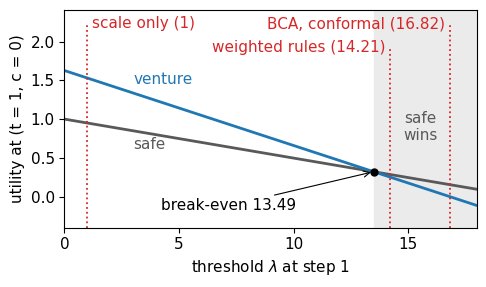

**So:** venture wins only while $\lambda$ is below 13.49, and scale only's $\lambda = 1$ is far below it. Every calibrated threshold is at least its plain 90% quantile: BCA takes the larger of $\hat\lambda$ and $\lambda_\beta$, and split conformal's rank $\lceil 0.9 (n + 1) \rceil$ is at least $\lceil 0.9 n \rceil$ (with weights, likewise). Here that quantile is a score of the noisy venture cell itself: 14.21 with weights, 16.82 without (Step 1.4). Both are above 13.49, so all four calibrated widths turn venture away.

At step 0 the break-even values are 69.27 (context 0) and 25.79 (context 1), far above every step-0 threshold (at most 6.27), so every rule ventures there.

In [47]:
# Check Step 1.5's choice rule against the experiment: the same pick as its make_policy, for every rule and state.
lesson_check(lesson_1_methods == methods, "Step 1.5's list of rules differs from the experiment's")
lesson_check(all(lesson_1_pick(m, t, c)[0] == make_policy(m)[0][t, c]
                 for m in methods for t in (0, 1) for c in (0, 1)),
             "Step 1.5's choice rule differs from the experiment's make_policy")


def lesson_1_break_even(t, c):
    """The threshold above which safe's utility beats venture's at state (t, c)."""
    R = lesson_1_run
    return (R["q"][t, c, 1] - R["q"][t, c, 0]) / (R["scale"][t, c, 1] - R["scale"][t, c, 0])


def lesson_1_flip_plot(star):
    """Step 1.8: both utilities at (t = 1, c = 0) as the threshold grows, with each rule's threshold marked."""
    R = lesson_1_run
    qs, qv, ss, sv = R["q"][1, 0, 0], R["q"][1, 0, 1], R["scale"][1, 0, 0], R["scale"][1, 0, 1]
    lam_w, lam_b = float(R["thresholds"]["weighted BCA"][1, 0]), float(R["thresholds"]["BCA"][1, 0])
    grid = np.linspace(0, 18, 181)
    top = max(qs, qv) + 0.6
    with plt.rc_context({"font.size": 11}):
        fig, ax = plt.subplots(figsize=(5, 3))
        ax.axvspan(star, grid[-1], color="0.92", zorder=0)
        ax.plot(grid, qs - grid * ss, color="0.35", lw=2)
        ax.plot(grid, qv - grid * sv, color="C0", lw=2)
        # Labels sit next to what they name (no legend); all are horizontal and at least 11 points.
        ax.text(3, qv - 3 * sv + 0.08, "venture", color="C0", ha="left", va="bottom", fontsize=11)
        ax.text(3, qs - 3 * ss - 0.08, "safe", color="0.35", ha="left", va="top", fontsize=11)
        ax.text((lam_w + lam_b) / 2, 0.9, "safe\nwins", color="0.35", ha="center", va="center", fontsize=11)
        ax.plot([star], [qs - star * ss], "o", color="black", ms=5)
        ax.annotate(f"break-even {star:.2f}", xy=(star, qs - star * ss), xytext=(4.2, -0.12), va="center",
                    fontsize=11, arrowprops=dict(arrowstyle="->", color="black", lw=0.8))
        for value, label, y, side in [(1.0, "scale only (1)", top, "left"),
                                      (lam_w, f"weighted rules ({lam_w:.2f})", top - 0.3, "right"),
                                      (lam_b, f"BCA, conformal ({lam_b:.2f})", top, "right")]:
            ax.plot([value, value], [-0.4, y], color="C3", ls=":", lw=1.3)
            ax.text(value + 0.2 if side == "left" else value - 0.2, y, label, ha=side, va="center", fontsize=11,
                    color="C3")
        ax.set_xlim(0, 18)
        ax.set_ylim(-0.4, top + 0.18)
        ax.set_xticks([0, 5, 10, 15])
        ax.set_xlabel(r"threshold $\lambda$ at step 1")
        ax.set_ylabel("utility at (t = 1, c = 0)")
        fig.tight_layout()
        plt.show()


def lesson_1_flip():
    """Step 1.8: the break-even threshold at (t = 1, c = 0), and every rule's threshold, utilities and pick there."""
    R = lesson_1_run
    qs, qv, ss, sv = R["q"][1, 0, 0], R["q"][1, 0, 1], R["scale"][1, 0, 0], R["scale"][1, 0, 1]
    star = lesson_1_break_even(1, 0)
    lesson_math(r"\lambda^* &= \frac{Q_{\mathrm{v}} - Q_{\mathrm{s}}}{\sigma_{\mathrm{v}} - \sigma_{\mathrm{s}}}",
                lesson_tex(r"&= \frac{<<qv>> - <<qs>>}{<<sv>> - <<ss>>}", qv=qv, qs=qs, sv=lesson_1_sig(sv),
                           ss=lesson_1_sig(ss)),
                lesson_tex(r"&= \frac{<<dq>>}{<<ds:5>>} = <<st:2>>", dq=qv - qs, ds=sv - ss, st=star))
    rows = []
    for m in lesson_1_methods:
        pick, util, width, lam = lesson_1_pick(m, 1, 0)
        shown = "none" if m in ("no penalty", "support only") else ("1" if m == "scale only" else f"{lam:.4f}")
        if m != "no penalty" and m != "support only":
            lesson_check((lam > star) == (pick == 0), f"{m}'s pick does not follow the break-even rule")
        rows.append([m, shown, f"{lesson_1_u(util[0]):.3f}", f"{lesson_1_u(util[1]):.3f}", lesson_1_name[pick]])
    lesson_table(["rule", "$\\lambda$", "safe", "venture", "picks"], rows,
                 note="Utilities at $(t = 1, c = 0)$; $\\lambda$ is the step-1 threshold.")
    lesson_1_flip_plot(star)
    calibrated = [m for m in lesson_1_methods if m in R["thresholds"]]
    step0_max = max(float(R["thresholds"][m][0, c]) for m in calibrated for c in (0, 1))
    lesson_show(lesson_text(
        r"**So:** venture wins only while $\lambda$ is below <<st:2>>, and scale only's $\lambda = 1$ is far below it. "
        r"Every calibrated threshold is at least its plain 90% quantile: BCA takes the larger of $\hat\lambda$ and "
        r"$\lambda_\beta$, and split conformal's rank $\lceil 0.9 (n + 1) \rceil$ is at least $\lceil 0.9 n \rceil$ "
        r"(with weights, likewise). Here that quantile is a score of the noisy venture cell itself: <<w:2>> with "
        r"weights, <<u:2>> without (Step 1.4). Both are above <<st:2>>, so all four calibrated widths turn venture away."
        "\n\n"
        r"At step 0 the break-even values are <<b0:2>> (context 0) and <<b1:2>> (context 1), far above every step-0 "
        r"threshold (at most <<m0:2>>), so every rule ventures there.",
        st=star, w=float(R["thresholds"]["weighted empirical"][1, 0]), u=float(R["thresholds"]["empirical"][1, 0]),
        b0=lesson_1_break_even(0, 0), b1=lesson_1_break_even(0, 1), m0=step0_max))


lesson_1_flip()

### Step 1.9 · Each rule's regret, in both worlds

Step 1.5 found BCA's regret in the harmful world by hand. The next cell checks it, and every rule's regret in both worlds, against the experiment's policy tables (Step 1.6). The Try-it after it shows where any rule's regret comes from.

In [48]:
lesson_check(all(np.isclose(lesson_1_regret_parts(m, w)[2], results[w][k][1])
                 for k, m in enumerate(methods) for w in ("harmful", "harmless")),
             "a worked regret differs from the experiment's policy table")
lesson_check(np.isclose(lesson_1_bca_regret, results["harmful"][methods.index("BCA")][1]),
             "Step 1.5's regret differs from the experiment's")


def lesson_1_regret_checked(try_method, try_world):
    """Step 1.9: one rule's regret, state by state, checked against the experiment's policy table."""
    if not lesson_1_valid(rule=try_method, world=try_world):
        return
    R = lesson_1_run
    printed = R["results"][try_world][R["methods"].index(try_method)][1]
    lesson_check(np.isclose(lesson_1_regret_parts(try_method, try_world)[2], printed),
                 "the worked regret differs from the experiment's policy table")
    lesson_1_regret(try_method, try_world,
                    f"**So:** {try_method}'s regret in the {try_world} world is {printed:.3f}, as the experiment's "
                    f"policy table prints.")


lesson_show(lesson_text("Checked: Step 1.5's rule makes the same pick as the experiment for all <<k>> rules in all 4 "
                        "states, and every worked regret equals the policy tables'. BCA's regret in the harmful world "
                        "is <<r>>.", k=len(methods), r=results["harmful"][methods.index("BCA")][1]))

Checked: Step 1.5's rule makes the same pick as the experiment for all 7 rules in all 4 states, and every worked regret equals the policy tables'. BCA's regret in the harmful world is 0.175.

In [49]:
# Try it: pick a rule (any of the seven in Step 1.6) and a world ("harmful" or "harmless"), then rerun this cell.
try_method, try_world = "BCA", "harmless"
lesson_1_regret_checked(try_method, try_world)

| state $(t, c)$ | safe | venture | best | BCA picks |
|---|---|---|---|---|
| (0, 0) | 1.1 | 1.3 | venture | venture |
| (0, 1) | 1.1 | 1.3 | venture | venture |
| (1, 0) | 1 | 1.5 | venture | **safe** |
| (1, 1) | 1 | 2 | venture | **safe** |

Safe and venture: each action's true average. At step 0 it includes the 1 that safe pays at step 1, as the critic's values do (Step 1.3). A wrong pick is in bold.

$$
\begin{aligned}
\text{regret} &= 0.35 \times (1.5 - 1) + 0.65 \times (2 - 1) \\ &= 0.175 + 0.650 \\ &= 0.825
\end{aligned}
$$

**So:** BCA's regret in the harmless world is 0.825, as the experiment's policy table prints.

In the harmless world BCA pays twice: 0.175 for safe at $(t = 1, c = 0)$, as before, and 0.650 for refusing the never-tried venture, which pays 2 there. Support only pays just the 0.650.

The chart below repeats the two policy tables as bars: return, regret and failure risk for each rule, harmful world in blue and harmless in orange.

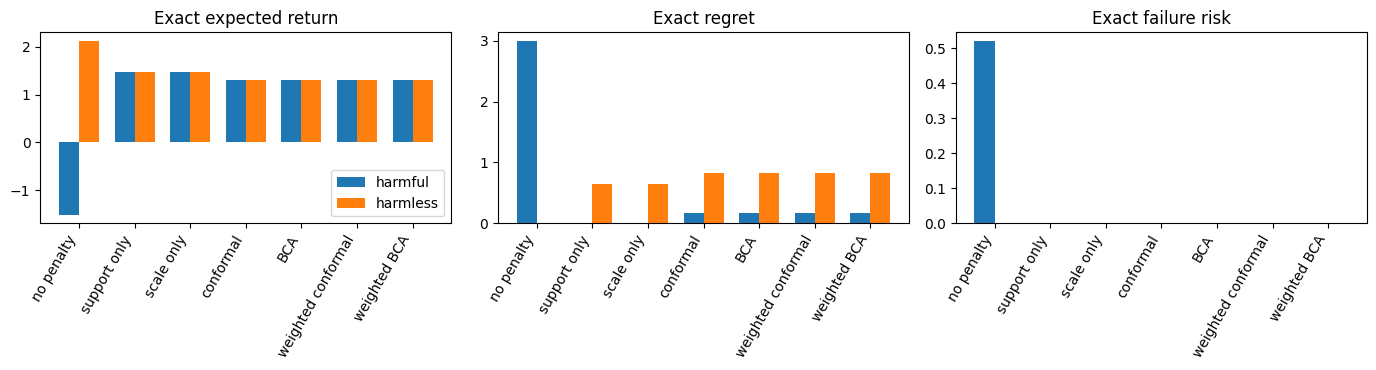

In [50]:
fig, axes = plt.subplots(1,3,figsize=(14,3.8))
x = np.arange(len(methods))
for k, (metric,title) in enumerate(zip(range(3),("Exact expected return","Exact regret","Exact failure risk"))):
    for offset,variant in ((-.18,"harmful"),(.18,"harmless")):
        vals = np.array(results[variant])[:,metric]
        axes[k].bar(x+offset, vals, .36, label=variant)
    axes[k].set_title(title)
    axes[k].set_xticks(x)
    axes[k].set_xticklabels(methods,rotation=60,ha="right")
axes[0].legend()
fig.tight_layout()
plt.show()

### Step 1.10 · Checks and an optional sweep

*Deeper: skip on a first read.*

**Checks.** The next cell confirms that the toy works as described, and stops the notebook if a check fails:
- the probabilities add up, and the weights average 1 over the log's mix;
- the exact evaluation matches a brute-force one over all 16 policies;
- BCA with weights of 1 matches unweighted BCA, and split conformal picks the score at rank $\lceil (n+1)(1-\alpha) \rceil$;
- cells with no training rows always get an infinite width, and every rule except no penalty plays safe there;
- a single score is too little: split conformal and BCA both give an infinite threshold;
- the two worlds give identical logs;
- subtracting the same number from both actions' values changes no choice;
- sampled coverage agrees with exact coverage.

It also prints the effective number of calibration rows under the shift, $n_{\mathrm{eff}}$ (Step A.9), as "ESS".

In [51]:
# 1. All discrete outcome probabilities normalize.
for variant,t,c,a in itertools.product(("harmful","harmless"),range(2),range(2),range(2)):
    oo = outcomes(t,c,a,variant)
    assert np.isclose(sum(p for p,r in oo),1) and all(p>=0 for p,r in oo)

# 2. Known support shift normalizes, and effective sample size is meaningful.
assert np.isclose(P_CAL @ ratio,1.)
assert np.isclose(P_TEST @ ratio,wbar)
ess = cal_weights.sum()**2 / (cal_weights @ cal_weights)
assert 0 < ess <= N_CAL+1e-8

# 3. Bellman identities and independent exhaustive outcome evaluation.
for variant in ("harmful","harmless"):
    oq = oracle_q(variant, np.zeros(2,dtype=int))
    for c,a in itertools.product(range(2),range(2)):
        assert np.isclose(oq[0,c,a],sum(p*r for p,r in outcomes(0,c,a,variant))+oq[1,c,0])
    all_returns = []
    for actions in itertools.product(range(2),repeat=4):
        pi = np.array(actions).reshape(2,2)
        ret = fail = 0.
        for c in range(2):
            for (p0,r0),(p1,r1) in itertools.product(
                outcomes(0,c,int(pi[0,c]),variant),outcomes(1,c,int(pi[1,c]),variant)):
                mass = P_TEST[c]*p0*p1
                ret += mass*(r0+r1)
                fail += mass*(r1<0)
        er,reg,ef = exact_evaluate(pi,variant)
        assert np.isclose(ret,er) and np.isclose(fail,ef) and reg>=-1e-10
        all_returns.append(ret)
    assert np.isclose(max(all_returns),P_TEST @ oracle_q(variant)[0].max(axis=-1))

# 4. Unit-weight BCA identity with identical draws; query CP becomes corrected rank.
s = cal_scores[0]
a = bca_threshold(s,np.random.default_rng(42))
b = bca_threshold(s,np.random.default_rng(42),np.ones(len(s)),1.)
assert np.array_equal(a,b)
cp = weighted_quantile(s,np.ones(len(s)),1-ALPHA,1.)
rank = math.ceil((len(s)+1)*(1-ALPHA))
expected = np.sort(s)[rank-1] if rank<=len(s) else np.inf
assert cp == expected

# 5. Unknown support never gets a finite interval, in either world.
assert counts[1,1,1] == 0 and q[1,1,1] == UNKNOWN_PRIOR
for name in thresholds:
    assert np.isinf(widths(name)[1,1,1])
    assert coverage_report(novel,name,1)[1] == 1.
for name in methods[1:]:
    assert make_policy(name)[0][1,1] == 0
# Even known support may refuse because a posterior/CP test atom is too large.
assert np.isinf(weighted_quantile([1.],[1.],.9,1.))
assert np.isinf(bca_threshold([1.],np.random.default_rng(1),draws=1000)[0])

# 6. Unobserved-world changes cannot change observed data or training/calibration.
d1 = episodes(100,P_CAL,np.random.default_rng(123),"harmful")
d2 = episodes(100,P_CAL,np.random.default_rng(123),"harmless")
assert all(np.array_equal(d1[k],d2[k]) for k in d1)

# 7. Global-penalty negative control, with and without the common support restriction.
assert np.array_equal(q.argmax(-1),(q-0.731).argmax(-1))
masked = np.where(supported,q,-np.inf)
assert np.array_equal(masked.argmax(-1),(masked-0.731).argmax(-1))
# 8. Exact coverage agrees with the sampled test coverage (within 5 standard errors).
for name in thresholds:
    for t in range(2):
        cv,rf,wi = coverage_report(test,name,t)
        ex = exact_coverage(name,t)[0]
        n_finite = round((1-rf)*N_TEST)
        if n_finite:
            assert abs(cv-ex) <= 5*math.sqrt(max(ex*(1-ex),0.)/n_finite) + 1e-12, (name,t,cv,ex)
print("All checks passed. Calibration effective sample size (ESS):",round(ess,2))
print("Main notebook elapsed seconds:",round(time.perf_counter()-START,3))

All checks passed. Calibration effective sample size (ESS): 97.22
Main notebook elapsed seconds: 0.7


**What to notice.** All checks passed. Under the shift, the 300 calibration rows count as only 97.22 equally weighted ones (printed as ESS). The cell below works this out.

In [52]:
def lesson_1_neff():
    """Step 1.10: the effective number of calibration rows under the shift (Step A.9), from the context counts."""
    R = lesson_1_run
    n0, n1 = (int(v) for v in np.bincount(R["cal"]["c"], minlength=2))
    w0, w1 = (float(v) for v in R["ratio"])
    total, squares = n0 * w0 + n1 * w1, n0 * w0 ** 2 + n1 * w1 ** 2
    neff = total ** 2 / squares
    lesson_check(np.isclose(neff, ess), "the worked n_eff differs from the experiment's ESS")
    lesson_math(r"n_{\mathrm{eff}} &= \frac{(\sum_i w_i)^2}{\sum_i w_i^2}",
                lesson_tex(r"&= \frac{(<<n0>> \times <<w0:4>> + <<n1>> \times <<w1:4>>)^2}"
                           r"{<<n0>> \times <<w0:4>>^2 + <<n1>> \times <<w1:4>>^2}", n0=n0, n1=n1, w0=w0, w1=w1),
                lesson_tex(r"&= \frac{<<t:2>>^2}{<<s:2>>} = <<e:2>>", t=total, s=squares, e=neff),
                note=lesson_text("**So:** the <<n1>> context-1 rows carry <<sh:%0>> of the weight, so the <<n>> rows "
                                 "count as only <<e:2>> equally weighted ones.", n1=n1, sh=n1 * w1 / total, n=n0 + n1,
                                 e=neff))


lesson_1_neff()

$$
\begin{aligned}
n_{\mathrm{eff}} &= \frac{(\sum_i w_i)^2}{\sum_i w_i^2} \\ &= \frac{(264 \times 0.4118 + 36 \times 4.3333)^2}{264 \times 0.4118^2 + 36 \times 4.3333^2} \\ &= \frac{264.71^2}{720.76} = 97.22
\end{aligned}
$$

**So:** the 36 context-1 rows carry 59% of the weight, so the 300 rows count as only 97.22 equally weighted ones.

**Optional sweep.** The cell below reruns Part 1 on 200 other seeds to show how typical seed 7 is. It is off by default, and its results are not part of this notebook. To run it, set `RUN_SWEEP = True` in the settings cell of Step 1.2 (the one that sets `SEED = 7`), then rerun Part 1's code cells from there, in order. Afterwards, rerun Parts 2 to 4 (or Run All) before using their Try-it cells.

In [53]:
if RUN_SWEEP:
    sweep_start = time.perf_counter()
    saved = (q,counts,scale,supported,thresholds)
    calibrated = list(thresholds)                       # the six threshold methods
    unweighted = ["empirical","conformal","BCA"]
    worlds = ("harmful","harmless")
    ret, cov_test, cov_cal, kept, skipped, tie_log = [], [], [], [], [], []
    try:
        for seed in range(N_SWEEP):
            rs = [np.random.default_rng(x) for x in np.random.SeedSequence([20261014, seed]).spawn(3)]
            tr = episodes(N_TRAIN,P_CAL,rs[0])
            ca = episodes(N_CAL,P_CAL,rs[1])
            q,counts,scale = fit_tabular(tr)
            supported = counts>0
            if not all(supported[t,ca["c"],ca["a"][:,t]].all() for t in range(2)):
                skipped.append(seed); continue
            thresholds = {name:np.zeros((2,2)) for name in calibrated}
            w = ratio[ca["c"]]
            for t in range(2):
                s = scores(ca,t)
                bb,ee,cc = bca_threshold(s,rs[2])
                wb,we,wc = bca_threshold(s,rs[2],w,wbar)
                for c in range(2):
                    for name,val in (("BCA",bb),("empirical",ee),("weighted BCA",wb),("weighted empirical",we),
                                     ("conformal",weighted_quantile(s,np.ones(len(s)),1-ALPHA,1)),
                                     ("weighted conformal",weighted_quantile(s,w,1-ALPHA,ratio[c]))):
                        thresholds[name][t,c] = val
            policies = [make_policy(name) for name in methods]
            kept.append(seed)
            tied = [name for name,pt in zip(methods,policies) if pt[2].any()]
            if tied: tie_log.append((seed,tied))
            ret.append([[exact_evaluate(pt[0],v)[0] for pt in policies] for v in worlds])
            cov_test.append([[exact_coverage(name,t) for t in range(2)] for name in calibrated])
            cov_cal.append([[exact_coverage(name,t,P_CAL) for t in range(2)] for name in unweighted])
    finally:
        q,counts,scale,supported,thresholds = saved
    print(f"Sweep: {len(kept)} of {N_SWEEP} seeds used; seed k uses SeedSequence([20261014, k]).")
    if skipped:
        print(f"Skipped {len(skipped)} seeds (a calibration cell had no training data):", skipped)
    if kept:
        ret = np.array(ret)                             # [seed, world, method]
        cov_test = np.array(cov_test)                   # [seed, method, stage, (coverage, refusal, width)]
        cov_cal = np.array(cov_cal)
        print(f"Seeds with a tie in some method's choice (taken as safe): {len(tie_log)}", tie_log[:5])
        print("\nExact return, mean over seeds: method | harmful | harmless")
        for m,name in enumerate(methods):
            print(f"{name:20} {ret[:,0,m].mean():7.3f} {ret[:,1,m].mean():7.3f}")
        print("\nPaired return difference (same seed, same data): mean | seeds better / tied / worse")
        so = methods.index("support only")
        for k,v in enumerate(worlds):
            for name in ("BCA","weighted BCA"):
                d = ret[:,k,methods.index(name)] - ret[:,k,so]
                print(f"{v:8} {name+' minus support only':33} {d.mean():+.3f} | "
                      f"{(d>1e-9).sum()} / {(abs(d)<=1e-9).sum()} / {(d<-1e-9).sum()}")
        print("\nExact finite coverage under P_TEST, mean over seeds:")
        print("method | stage 0 | stage 1 | share of seeds with stage 0 >= 0.90")
        for m,name in enumerate(calibrated):
            c0 = cov_test[:,m,0,0]
            print(f"{name:20} {np.nanmean(c0):.4f}  {np.nanmean(cov_test[:,m,1,0]):.4f}  {np.mean(c0 >= 0.9-1e-9):.3f}")
        print("\nNo-shift control, contexts from P_CAL (unweighted methods), same columns:")
        for m,name in enumerate(unweighted):
            c0 = cov_cal[:,m,0,0]
            print(f"{name:20} {np.nanmean(c0):.4f}  {np.nanmean(cov_cal[:,m,1,0]):.4f}  {np.mean(c0 >= 0.9-1e-9):.3f}")
        print("Largest exact refusal rate in any seed, method and stage:",
              round(float(max(cov_test[...,1].max(), cov_cal[...,1].max())),3))
    print("Sweep seconds:", round(time.perf_counter()-sweep_start,1))
else:
    print("Optional seed sweep skipped.")

Optional seed sweep skipped.


## What Part 1 found

*Exploratory: one seed (7), no claims.*

| question | answer on seed 7 |
|---|---|
| Does the width cover 90% of outcomes at deployment? | Not without weights: 0.6750 at step 0 (0.9250 with the log's mix). With weights, weighted BCA did (1.0000); weighted conformal still fell short (0.8375). |
| Does it contain the true values? | BCA's intervals did in 6 of the 7 tried cells; weighted BCA's in all 7. |
| Does the policy choose better? | No. Every calibrated width chose safe at $(t = 1, c = 0)$ and had 0.175 more regret than support only, in each world. |

- **The width punished a good action for being noisy.** BCA's step-1 threshold was the score of venture's own 0 payout, so the width pulled venture (average 1.5, against 1 for safe) down to exactly its worst payout, 0. Safe, certain to pay 1, still had 0.845 subtracted (Step 1.5).
- **Calibration set only the size of the penalty, not where it fell.** Every width is one number per step, $\lambda$, times the count scale $\sigma$. So calibration can only scale the same pattern up or down, and within a step the cells with fewer rows always pay the most. Every calibrated step-1 $\lambda$ (14.21 or 16.82) was above the break-even 13.49, so all four calibrated widths made the same choices (Step 1.8).
- **Refusing the never-tried action is not BCA's doing.** Every rule except no penalty gives a cell with no training rows an infinite width. That refusal is right in the harmful world and costs 0.650 in the harmless one, and no data can say which world this is. No penalty, which trusts the critic's 2.5 guess, lost 2.990 in the harmful world.
- **Limits.** One seed. The optional sweep (Step 1.10) would show the spread over 200 other seeds, but it is off by default and was not run for this notebook. The two steps are separate choices, and the width acts only when the policy chooses, so this toy cannot test a dose during training, where a critic's errors spread through its own training targets.

**The insight.** A width built from errors at logged actions mostly measures reward noise. It penalizes good actions that are merely noisy, and it says nothing about the action the log never tried, which is where the decision matters. To help, BCA has to read outcomes of the risky action itself. Part 2 gives it some.

---
# Part 2 · Where can BCA help? Widths against gates

*Pre-registered. Original notebook: `bca_channel_toy.ipynb`. Kill rules fingerprint `bb9e0325…dbc3`.*

**The question.** Part 1's width did not help the policy choose. Is there any way BCA's calibrated errors can change a decision for the better, where simpler rules cannot?

**What changed since Part 1,** so that a good rule has something to find:
1. **The log holds held-out tries of the risky action,** called **survivors**: 5 to 100 of them. The name comes from ThrusterChain, the repository's larger test environment, where it means the few logged rows of the risky action left after most were removed. It has nothing to do with surviving a disaster: survivors can be disasters. The critic never trains on them. The gates read them directly; BCA's widths see them only inside one pooled threshold (Step 2.4).
2. **The critic makes the same guess in every world.** It values venture at about 1.5 in the never-tried cell, against 1.0 for safe.
3. **Twenty worlds.** Venture's outcomes in that cell come in two harm shapes, each with ten advantages (Step 2.2).
4. **Rewards are noisy,** so no two scores tie.

**In this part**

**Setting up**

1. The world, and the gap
2. The gap's two harm shapes
3. The log, the critic and its guess at the gap
4. The rules

**Before the run**

5. BCA against its exact twin
6. How a rule is scored
7. The six tests and their kill rules

**The run, and one case by hand**

8. The run
9. One case: the survivors and the key identity
10. Gates that need proof that venture is safe
11. The plain average, and gates that need proof of harm
12. The step-1 gate
13. Every gate on one case, checked against the run

**Results**

14. Results
15. Verdicts
16. By number of survivors and by world
17. Checks
18. Information only: decisions by world, and the step-1 gate's comparison group

### Step 2.1 · The world, and the gap

Part 2 keeps Part 1's world (Step 1.1): two steps, two contexts, safe or venture. Two things are new:
- every reward gets random **noise**, a normal draw with spread 0.2;
- the never-tried cell, venture at $t = 1$ in context 1, is now called the **gap**. Its outcomes differ from world to world.

The next two cells hold the experiment's settings and its world: the outcome laws, and how each seed draws its log and its survivors. The table after them lists what each cell pays.

In [54]:
import math, time, hashlib
from fractions import Fraction
from functools import lru_cache
import numpy as np
import matplotlib.pyplot as plt
START = time.perf_counter()

ALPHA, BETA, DRAWS = 0.1, 0.95, 1000        # BCA settings as in production
SIGMA = 0.2                                 # sd of the Gaussian noise on every reward
P_LOG = np.array([0.85, 0.15])              # context mix in the log
P_TEST = np.array([0.35, 0.65])             # context mix at deployment
N_LOG, TRAIN_SHARE, N_MIN = 1800, 2 / 3, 20
EVIDENCE = (5, 10, 20, 30, 45, 60, 100)     # survivors available to calibration
ADVANTAGE = (1.0, 0.5, 0.25, 0.1, -0.1, -0.25, -0.5, -1.0, -2.0, -4.6)
HARMS = ("shortfall", "tail")
N_SEEDS, ROOT_SEED = 200, 20261014
MARGIN = 0.10                               # step-1 certificate margin, value units
GAIN = 1.0                                  # A1: critic minus GAIN x width
BC_WEIGHT, BLEND = 0.4, 0.5                 # host BC weight; A2 multiplier 1 + BLEND x U / (U + unit)
SAFE, VENTURE = 0, 1
CATASTROPHE = -5.0
A_FRAC, B_FRAC = Fraction(str(ALPHA)), Fraction(str(BETA))
assert max(EVIDENCE) <= 100 and 0 < ALPHA < 1 and 0 < BETA < 1

In [55]:
def gap_law(harm, adv):
    """Outcome law of venture at (t=1, context 1) as (probability, mean) pairs; noise is added on top."""
    if harm == "shortfall":
        return [(1.0, 1.0 + adv)]
    p = (1.0 - adv) / 7.0                       # mean 2 - 7p = 1 + adv
    return [(p, CATASTROPHE), (1.0 - p, 2.0)]

def law(t, c, a, harm="tail", adv=-4.6):
    if t == 0:
        if a == SAFE: return [(1.0, 0.1)]
        return [(1.0, 0.3)] if c == 0 else [(0.5, -0.5), (0.5, 1.1)]
    if a == SAFE: return [(1.0, 1.0)]
    if c == 0: return [(0.5, 0.0), (0.5, 3.0)]
    return gap_law(harm, adv)

def mean_of(t, c, a, harm="tail", adv=-4.6):
    return sum(p * m for p, m in law(t, c, a, harm, adv))

def phi(x):
    return 0.5 * (1.0 + math.erf(x / math.sqrt(2.0)))

def below_safe(harm, adv):
    """Exact probability that a gap outcome falls below safe's mean, 1.0."""
    return sum(p * phi((1.0 - m) / SIGMA) for p, m in gap_law(harm, adv))

def draw(lawlist, u, z):
    """Inverse-CDF draw from shared uniforms u and normals z, so every world reuses the same random numbers."""
    cum = np.cumsum([p for p, _ in lawlist])
    k = np.minimum(np.searchsorted(cum, u, side="right"), len(lawlist) - 1)
    return np.array([m for _, m in lawlist])[k] + SIGMA * z

def collect(seed):
    rng = np.random.default_rng([ROOT_SEED, seed])
    c = rng.choice(2, N_LOG, p=P_LOG)
    a = np.zeros((N_LOG, 2), dtype=int)
    a[:, 0] = rng.random(N_LOG) < 0.5
    a[:, 1] = (c == 0) & (rng.random(N_LOG) < 0.25)
    u, z = rng.random((N_LOG, 2)), rng.standard_normal((N_LOG, 2))
    r = np.zeros((N_LOG, 2))
    for t in range(2):
        for cc in range(2):
            for aa in range(2):
                m = (c == cc) & (a[:, t] == aa)
                if m.any(): r[m, t] = draw(law(t, cc, aa), u[m, t], z[m, t])
    train = rng.random(N_LOG) < TRAIN_SHARE
    split = lambda m: {"c": c[m], "a": a[m], "r": r[m]}
    survivors = {"u": rng.random(100), "z": rng.standard_normal(100)}
    return split(train), split(~train), survivors

def survivor_rewards(surv, harm, adv, n):
    return draw(gap_law(harm, adv), surv["u"][:n], surv["z"][:n])

In [56]:
# Step 2.1 tools. Parts 3 and 4 later reuse some of Part 2's names (DRAWS, N_MIN, N_SEEDS, MU, UNSAFE, phi, ...)
# for their own settings. The lesson keeps Part 2's values under lesson_2_ names, so the Try-it cells below
# still work after Run All.
lesson_2_draws, lesson_2_n_min, lesson_2_seeds, lesson_2_root = DRAWS, N_MIN, N_SEEDS, ROOT_SEED
lesson_2_name = {SAFE: "safe", VENTURE: "venture"}


def lesson_2_number(x):
    """A Try-it input as a finite float, or None when it is not a plain number (text, True/False, lists, nan, inf)."""
    if x is None or isinstance(x, (bool, np.bool_, str, bytes)) or (isinstance(x, np.ndarray) and x.ndim > 0):
        return None
    try:
        v = float(x)
    except (TypeError, ValueError, OverflowError):
        return None
    return v if math.isfinite(v) else None


def lesson_2_typed(x, sign=False, latex=True):
    """A typed number as typed (up to 6 decimals, no exponent): -0.255 stays -0.255, 1.0 prints as 1."""
    s = np.format_float_positional(round(float(x), 6) + 0.0, sign=sign, trim="-")
    return s if latex else s.replace("-", "−")


def lesson_2_small(x):
    """3 decimals, or 3 significant digits when a nonzero number is below 0.001 (so the next line can be checked)."""
    x = float(x)
    if x == 0 or abs(x) >= 0.001:
        return f"{x:.3f}"
    return np.format_float_positional(x, precision=3, unique=False, fractional=False, trim="-")


def lesson_2_plural(k, one, many):
    """The count k with the right word: 1 draw crosses, 2 draws cross."""
    return one if k == 1 else many


def lesson_2_cdf(x):
    """The chance that a standard normal draw falls below x (Part 2's phi)."""
    return 0.5 * (1.0 + math.erf(x / math.sqrt(2.0)))


def lesson_2_g(x, latex=True):
    """A short number: rounded to 3 decimals, trailing zeros dropped; text uses a true minus sign."""
    s = f"{round(float(x), 3) + 0.0:.3f}".rstrip("0").rstrip(".")
    s = "0" if s in ("-0", "") else s
    return s if latex else s.replace("-", "−")


def lesson_2_pays(t, c, a):
    """What cell (t, c, a) pays before noise, as text."""
    if (t, c, a) == (1, 1, VENTURE):
        return "**the gap:** depends on the world (Step 2.2)"
    lw = law(t, c, a)
    if len(lw) == 1:
        return lesson_2_g(lw[0][1], False)
    return " or ".join(lesson_2_g(m, False) for p, m in lw) + ", half each"


lesson_check(SIGMA == 0.2 and N_LOG == 1800 and (min(EVIDENCE), max(EVIDENCE)) == (5, 100)
             and len(ADVANTAGE) == 10 and len(HARMS) == 2 and lesson_2_n_min == 20
             and np.allclose(P_LOG, [0.85, 0.15]) and np.allclose(P_TEST, [0.35, 0.65]),
             "Part 2's text quotes settings that differ from the experiment's")
lesson_table(["step $t$", "context $c$", "safe pays", "venture pays"],
             [[str(t), str(c), lesson_2_pays(t, c, SAFE), lesson_2_pays(t, c, VENTURE)]
              for t in (0, 1) for c in (0, 1)],
             note="Every payout also gets the noise. Safe pays a fixed 1 at $t = 1$, so the critic can learn the "
                  "fallback's value well. The gap is the one cell the log never visits, and the only one that "
                  "differs between worlds.")

| step $t$ | context $c$ | safe pays | venture pays |
|---|---|---|---|
| 0 | 0 | 0.1 | 0.3 |
| 0 | 1 | 0.1 | −0.5 or 1.1, half each |
| 1 | 0 | 1 | 0 or 3, half each |
| 1 | 1 | 1 | **the gap:** depends on the world (Step 2.2) |

Every payout also gets the noise. Safe pays a fixed 1 at $t = 1$, so the critic can learn the fallback's value well. The gap is the one cell the log never visits, and the only one that differs between worlds.

### Step 2.2 · The gap's two harm shapes

Each world sets venture's **advantage** at the gap, written adv: how much its average beats safe's average of 1. Ten advantages run from +1 down to −4.6, each in both harm shapes below: 20 worlds. Venture goes wrong in one of two shapes:
- **Shortfall:** every outcome is a little worse. Venture pays $1 + \text{adv}$.
- **Tail:** usually fine, sometimes a disaster. Venture pays $-5$ with chance $p = (1 - \text{adv})/7$, and 2 otherwise.

The tail's chance $p$ is set so that its average matches the shortfall's:

$$
\begin{aligned}
p \times (-5) + (1 - p) \times 2 &= 2 - 7p \\
&= 2 - (1 - \text{adv}) \\
&= 1 + \text{adv}
\end{aligned}
$$

Two labels describe a world:
- **Unsafe:** more than $\alpha$ = 10% of venture's outcomes fall below safe's average, 1.0.
- **Harmful:** venture's average is below 1 ($\text{adv} < 0$), so it is worse on average.

Because of the noise, a cell that pays $m$ before noise gives an outcome below 1.0 with chance $\Phi\big((1.0 - m)/0.2\big)$, where $\Phi(z)$ is the chance that a standard normal draw (a bell curve with average 0 and spread 1) falls below $z$.

In [57]:
def lesson_2_below(harm, adv):
    """The share of venture's outcomes at the gap below 1.0, computed as the experiment's below_safe does."""
    return sum(p * lesson_2_cdf((1.0 - m) / SIGMA) for p, m in gap_law(harm, adv))


def lesson_2_shapes(try_adv):
    """Step 2.2: venture's outcomes at the gap in both harm shapes, for one advantage."""
    adv = lesson_2_number(try_adv)
    if adv is None or not -6.0 <= adv <= 1.0:
        lesson_show("Enter the advantage as a number from −6 to 1, for example `try_adv = -0.25`. Outside that "
                    "range the tail's chance $p$ would not lie between 0 and 1.")
        return
    sf, tl = gap_law("shortfall", adv), gap_law("tail", adv)
    p, mean = tl[0][0], sum(pr * m for pr, m in tl)
    b_sf, b_tl = lesson_2_below("shortfall", adv), lesson_2_below("tail", adv)
    lesson_check(np.isclose(sf[0][1], 1 + adv) and np.isclose(mean, 1 + adv) and np.isclose(p, (1 - adv) / 7),
                 "Step 2.2's formulas differ from the experiment's gap_law")
    z = (1.0 - sf[0][1]) / SIGMA
    verdict = lambda b: (r"> 0.10 \;\Rightarrow\; \text{unsafe}" if b > ALPHA
                         else r"\le 0.10 \;\Rightarrow\; \text{not unsafe}")
    # Typed numbers are shown as typed; computed chances with enough digits to check the next line.
    paren = lambda s: f"({s})" if s.startswith("-") else s
    a_s, m_s, o_s, sm = lesson_2_typed(adv), lesson_2_typed(sf[0][1]), lesson_2_typed(1 - adv), lesson_2_small
    p_s, q_s, z_s, f_s = sm(p), sm(1 - p), lesson_2_typed(z), sm(lesson_2_cdf(-5.0))
    # A step and its result share a line when both are short, so long typed inputs still fit a phone screen.
    step = lambda left, right, a, b, room=14: [left + " = " + right] if len(a) + len(b) <= room else [left, "&= " + right]
    lesson_show("**Shortfall shape.**")
    lesson_math(
        r"\text{pays} &= 1 + \text{adv}",
        *step(f"&= 1 + {paren(a_s)}", m_s, a_s, m_s),
        lesson_tex(r"P(\text{below } 1.0) &= \Phi\left(\frac{1.0 - <<m>>}{0.2}\right)", m=paren(m_s)),
        *step(rf"&= \Phi({z_s})", sm(b_sf), z_s, sm(b_sf)),
        "&" + verdict(b_sf))
    lesson_show("**Tail shape.**")
    phi = ([lesson_tex(r"&= <<p>>\,\Phi(30) + <<q>>\,\Phi(-5)", p=p_s, q=q_s)] if len(p_s) + len(q_s) <= 10 else
           [lesson_tex(r"&= <<p>>\,\Phi(30)", p=p_s), lesson_tex(r"&\quad + <<q>>\,\Phi(-5)", q=q_s)])
    lesson_math(
        r"p &= \frac{1 - \text{adv}}{7}",
        lesson_tex(r"&= \frac{1 - <<a>>}{7}", a=paren(a_s)),
        *step(rf"&= \frac{{{o_s}}}{{7}}", p_s, o_s, p_s),
        r"\text{average} &= 2 - 7p",
        *step(f"&= 2 - {o_s}", lesson_2_typed(mean), o_s, lesson_2_typed(mean)),
        r"P(\text{below } 1.0) &= p\,\Phi\left(\frac{1.0 - (-5)}{0.2}\right)",
        r"&\quad + (1 - p)\,\Phi\left(\frac{1.0 - 2}{0.2}\right)",
        *phi,
        lesson_tex(r"&= <<p>> \times <<f>>", p=p_s, f=sm(lesson_2_cdf(30.0))),
        *([lesson_tex(r"&\quad + <<q>> \times <<f>>", q=q_s, f=f_s)] if len(q_s) + len(f_s) <= 18 else
          [lesson_tex(r"&\quad + <<q>>", q=q_s), lesson_tex(r"&\quad\quad \times <<f>>", f=f_s)]),
        lesson_tex(r"&= <<b>>", b=sm(b_tl)),
        "&" + verdict(b_tl),
        note=lesson_text("**So:** with advantage <<a>>, both shapes average <<m>>, <<cmp>> safe's 1, so the world "
                         "is <<harm>>. The share of outcomes below 1.0 is <<x:%1>> in the shortfall shape and <<y:%1>> in "
                         "the tail shape.", a=lesson_2_typed(adv, sign=adv != 0, latex=False),
                         m=lesson_2_typed(1 + adv, latex=False), x=b_sf, y=b_tl,
                         cmp="below" if adv < 0 else "at or above", harm="harmful" if adv < 0 else "not harmful"))

In [58]:
# Try it: pick venture's advantage at the gap (from -6 to 1). The experiment's ten advantages are
# 1, 0.5, 0.25, 0.1, -0.1, -0.25, -0.5, -1, -2 and -4.6. Then rerun this cell.
try_adv = -0.25
lesson_2_shapes(try_adv)

**Shortfall shape.**

$$
\begin{aligned}
\text{pays} &= 1 + \text{adv} \\ &= 1 + (-0.25) = 0.75 \\ P(\text{below } 1.0) &= \Phi\left(\frac{1.0 - 0.75}{0.2}\right) \\ &= \Phi(1.25) = 0.894 \\ &> 0.10 \;\Rightarrow\; \text{unsafe}
\end{aligned}
$$

**Tail shape.**

$$
\begin{aligned}
p &= \frac{1 - \text{adv}}{7} \\ &= \frac{1 - (-0.25)}{7} \\ &= \frac{1.25}{7} = 0.179 \\ \text{average} &= 2 - 7p \\ &= 2 - 1.25 = 0.75 \\ P(\text{below } 1.0) &= p\,\Phi\left(\frac{1.0 - (-5)}{0.2}\right) \\ &\quad + (1 - p)\,\Phi\left(\frac{1.0 - 2}{0.2}\right) \\ &= 0.179\,\Phi(30) + 0.821\,\Phi(-5) \\ &= 0.179 \times 1.000 \\ &\quad + 0.821 \times 0.000000287 \\ &= 0.179 \\ &> 0.10 \;\Rightarrow\; \text{unsafe}
\end{aligned}
$$

**So:** with advantage −0.25, both shapes average 0.75, below safe's 1, so the world is harmful. The share of outcomes below 1.0 is 89.4% in the shortfall shape and 17.9% in the tail shape.

The table below applies the same arithmetic to all ten advantages, in both shapes. Step 2.14's results print the same shares.

In [59]:
def lesson_2_ladder():
    """Step 2.2: the ten advantages in both shapes, checked against the experiment's below_safe."""
    rows, unsafe_good, unsafe_n = [], 0, 0
    for adv in ADVANTAGE:
        b = [lesson_2_below(h, adv) for h in HARMS]
        # Parts 3 and 4 later give the name phi to another function; compare only while it is Part 2's.
        if abs(phi(0.0) - 0.5) < 1e-12:
            lesson_check(all(abs(b[k] - below_safe(h, adv)) < 1e-12 for k, h in enumerate(HARMS)),
                         "the share below 1.0 differs from the experiment's below_safe")
        flags = [x > ALPHA for x in b]
        unsafe_n += sum(flags)
        unsafe_good += sum(flags) if adv > 0 else 0
        both = {(True, True): "both", (True, False): "shortfall only", (False, True): "tail only",
                (False, False): "no"}[tuple(flags)]
        rows.append([lesson_txt(adv, 2, sign=True), f"{b[0]:.3f}", f"{b[1]:.3f}", both, "yes" if adv < 0 else "no"])
    lesson_table(["adv", "shortfall: below 1.0", "tail: below 1.0", "unsafe", "harmful"], rows,
                 note="The middle columns give the share of venture's outcomes below 1.0 in each shape; *unsafe* "
                      "names the shapes in which that share is above 0.10.\n\n"
                      + lesson_text("**So:** <<u>> of the 20 worlds are unsafe: every advantage of +0.25 or less, in "
                                    "both shapes. <<g>> of them (+0.25 and +0.10) are unsafe yet good on average: there "
                                    "the tail promise asks to fall back, although venture pays more on average.",
                                    u=int(unsafe_n), g=int(unsafe_good)))


lesson_2_ladder()

| adv | shortfall: below 1.0 | tail: below 1.0 | unsafe | harmful |
|---|---|---|---|---|
| +1.00 | 0.000 | 0.000 | no | no |
| +0.50 | 0.006 | 0.071 | no | no |
| +0.25 | 0.106 | 0.107 | both | no |
| +0.10 | 0.309 | 0.129 | both | no |
| −0.10 | 0.691 | 0.157 | both | yes |
| −0.25 | 0.894 | 0.179 | both | yes |
| −0.50 | 0.994 | 0.214 | both | yes |
| −1.00 | 1.000 | 0.286 | both | yes |
| −2.00 | 1.000 | 0.429 | both | yes |
| −4.60 | 1.000 | 0.800 | both | yes |

The middle columns give the share of venture's outcomes below 1.0 in each shape; *unsafe* names the shapes in which that share is above 0.10.

**So:** 16 of the 20 worlds are unsafe: every advantage of +0.25 or less, in both shapes. 4 of them (+0.25 and +0.10) are unsafe yet good on average: there the tail promise asks to fall back, although venture pays more on average.

### Step 2.3 · The log, the critic and its guess at the gap

Each seed draws a log of 1,800 episodes with Part 1's mixes and behavior policy (Step 1.2), which never ventures at the gap. About two thirds of the episodes train the critic. The rest are **held out**: they give the scores behind BCA's widths and the comparison group of one gate (the step-1 gate, Step 2.4).

The critic averages each cell's training targets, as in Step 1.3, wherever a cell has at least 20 rows. The gap has none, so the critic fills it with an **additive guess**: venture beats safe by as much in context 1 as in context 0. Two values at $t = 1$ in context 1 matter most from here on, so they get short names (the run prints them as q_gap and q_safe):
- $Q_{\mathrm{gap}} = Q(1, 1, \text{venture})$, the critic's value at the gap;
- $Q_{\mathrm{safe}} = Q(1, 1, \text{safe})$, the fallback's value there, which the log covers well.

The additive guess, and the critic's version of the advantage, its **claimed advantage**:

$$
\begin{aligned}
Q_{\mathrm{gap}} &= Q_{\mathrm{safe}} + Q(1, 0, \text{venture}) \\
&\quad - Q(1, 0, \text{safe}) \\
\text{claimed} &= Q_{\mathrm{gap}} - Q_{\mathrm{safe}}
\end{aligned}
$$

In [60]:
def targets(data, t, q):
    y = data["r"][:, t].copy()
    if t == 0: y += q[1, data["c"], SAFE]
    return y

def fit_critic(train):
    """Stage 1: cell means where a cell has at least N_MIN rows, else the additive guess
    Q(c, a) = Q(c, safe) + Q(other c, a) - Q(other c, safe). Stage 0: targets r0 + Q(1, c, safe)."""
    q, n = np.zeros((2, 2, 2)), np.zeros((2, 2, 2), dtype=int)
    for t in (1, 0):
        y = targets(train, t, q)
        for c in range(2):
            for a in range(2):
                m = (train["c"] == c) & (train["a"][:, t] == a)
                n[t, c, a] = m.sum()
                if n[t, c, a] >= N_MIN: q[t, c, a] = y[m].mean()
        for c in range(2):
            for a in range(2):
                if n[t, c, a] < N_MIN:
                    o = 1 - c
                    assert t == 1 and min(n[1, c, SAFE], n[1, o, a], n[1, o, SAFE]) >= N_MIN
                    q[1, c, a] = q[1, c, SAFE] + q[1, o, a] - q[1, o, SAFE]
    return q, n

def fit_scale(train, q):
    """Per-cell residual sd from training rows, shrunk toward the stage's pooled sd with 5 pseudo-rows."""
    scale, unit = np.zeros((2, 2, 2)), np.zeros(2)
    for t in range(2):
        res = targets(train, t, q) - q[t, train["c"], train["a"][:, t]]
        pooled, unit[t] = res.var(), res.std()
        for c in range(2):
            for a in range(2):
                m = (train["c"] == c) & (train["a"][:, t] == a)
                k = int(m.sum()); v = res[m].var() if k > 1 else 0.0
                scale[t, c, a] = max(0.05, math.sqrt((k * v + 5 * pooled) / (k + 5)))
    return scale, unit

In [61]:
# Step 2.3 tools. Part 1 has its own function named targets. If Part 1's cells are run again after Part 2's,
# Part 2's fit_critic would call Part 1's version, so this part's Try-it cells check for that first.
lesson_2_targets = targets


def lesson_2_ready():
    """True while `targets` is still Part 2's function; otherwise asks the reader to rerun Part 2's code cells."""
    if targets is lesson_2_targets:
        return True
    lesson_show("Part 1's cells were run again after Part 2's, so the name `targets` now holds Part 1's version, "
                "which Part 2's `fit_critic` cannot use. Rerun Part 2's code cells (or Run All), then this cell.")
    return False


def lesson_2_critic(try_seed):
    """Step 2.3: one seed's critic, cell by cell, and its additive guess at the gap."""
    v = lesson_2_number(try_seed)
    if v is None or not (v.is_integer() and 0 <= v < lesson_2_seeds):
        lesson_show(f"Enter a seed as a whole number from 0 to {lesson_2_seeds - 1}, for example `try_seed = 0`.")
        return
    if not lesson_2_ready():
        return
    seed = int(v)
    train, cal, surv = collect(seed)
    q, n = fit_critic(train)
    rows, thin = [], []
    for t in (0, 1):
        for c in (0, 1):
            for a in (SAFE, VENTURE):
                if n[t, c, a] >= lesson_2_n_min:
                    rows_here = (train["c"] == c) & (train["a"][:, t] == a)
                    lesson_check(np.isclose(targets(train, t, q)[rows_here].mean(), q[t, c, a]),
                                 "a critic value is not the average of its training targets")
                else:
                    thin.append((t, c, a))
                true = "1 + adv (the world)" if (t, c, a) == (1, 1, VENTURE) else \
                    lesson_2_g(mean_of(t, c, a) + (1.0 if t == 0 else 0.0), False)
                rows.append([f"({t}, {c}, {lesson_2_name[a]})", int(n[t, c, a]), f"{q[t, c, a]:.3f}", true])
    lesson_check(thin == [(1, 1, VENTURE)] and n[1, 1, VENTURE] == 0,
                 "the gap should be the only cell with fewer than 20 training rows, and should have none")
    lesson_show(f"**Seed {seed}'s critic.** {int(train['c'].size):,} training episodes and "
                f"{int(cal['c'].size):,} held out.")
    lesson_table(["cell $(t, c, a)$", "training rows", "$Q$", "true average"], rows,
                 note="Each $Q$ is the average of its training rows' targets, except at the gap, "
                      "$(1, 1, \\text{venture})$, which has no rows and gets the additive guess. As in Part 1, step-0 "
                      "targets add $Q(1, c, \\text{safe})$, and so do the true averages.")
    qs, qv0, qs0, qv = q[1, 1, SAFE], q[1, 0, VENTURE], q[1, 0, SAFE], q[1, 1, VENTURE]
    lesson_check(np.isclose(qs + qv0 - qs0, qv), "the additive guess differs from the critic's value at the gap")
    lesson_math(
        r"Q_{\mathrm{gap}} &= Q_{\mathrm{safe}} + Q(1, 0, \text{venture})",
        r"&\quad - Q(1, 0, \text{safe})",
        lesson_tex(r"&= <<a>> + <<b>> - <<c>> = <<d>>", a=qs, b=qv0, c=qs0, d=qv),
        r"\text{claimed} &= Q_{\mathrm{gap}} - Q_{\mathrm{safe}}",
        lesson_tex(r"&= <<d>> - <<a>> = <<e>>", d=qv, a=qs, e=qv - qs),
        note=lesson_text("**So:** seed <<s>>'s critic claims that venture beats safe by <<e>> at the gap. The log "
                         "never visits the gap, so this claim is the same in all twenty worlds, while the true "
                         "advantage runs from +1 to −4.6. Only the survivors can tell the worlds apart.",
                         s=str(seed), e=qv - qs))

In [62]:
# Try it: pick a seed (0 to 199), then rerun this cell.
try_seed = 0
lesson_2_critic(try_seed)

**Seed 0's critic.** 1,175 training episodes and 625 held out.

| cell $(t, c, a)$ | training rows | $Q$ | true average |
|---|---|---|---|
| (0, 0, safe) | 489 | 1.089 | 1.1 |
| (0, 0, venture) | 505 | 1.293 | 1.3 |
| (0, 1, safe) | 88 | 1.086 | 1.1 |
| (0, 1, venture) | 93 | 1.481 | 1.3 |
| (1, 0, safe) | 775 | 1.004 | 1 |
| (1, 0, venture) | 219 | 1.447 | 1.5 |
| (1, 1, safe) | 181 | 1.004 | 1 |
| (1, 1, venture) | 0 | 1.447 | 1 + adv (the world) |

Each $Q$ is the average of its training rows' targets, except at the gap, $(1, 1, \text{venture})$, which has no rows and gets the additive guess. As in Part 1, step-0 targets add $Q(1, c, \text{safe})$, and so do the true averages.

$$
\begin{aligned}
Q_{\mathrm{gap}} &= Q_{\mathrm{safe}} + Q(1, 0, \text{venture}) \\ &\quad - Q(1, 0, \text{safe}) \\ &= 1.004 + 1.447 - 1.004 = 1.447 \\ \text{claimed} &= Q_{\mathrm{gap}} - Q_{\mathrm{safe}} \\ &= 1.447 - 1.004 = 0.443
\end{aligned}
$$

**So:** seed 0's critic claims that venture beats safe by 0.443 at the gap. The log never visits the gap, so this claim is the same in all twenty worlds, while the true advantage runs from +1 to −4.6. Only the survivors can tell the worlds apart.

### Step 2.4 · The rules

Every rule uses the same critic. They differ in whether, and how, they read the survivors. Below, $Q_{\mathrm{safe}}$ (Step 2.3) is the fallback's value.

**Rules that never read the survivors.**

| plain name | printed as | at the gap, it ventures when |
|---|---|---|
| no safeguard | greedy | always: the critic prefers venture |
| refuse thin data | range limit | never: venture has 0 training rows there, fewer than 20 |
| count penalty | count penalty | its value minus $1/\sqrt{\text{rows} + 1}$ is higher; the gap loses a full 1 |
| pull toward the log | host BC actor | the claimed advantage beats a penalty of 0.4 for leaving the logged action, safe |

The last rule is a simple version of TD3+BC, one of the host learners.

**BCA as built: a width at every action.** These read the survivors only through one shared threshold.

| plain name | printed as | what it does |
|---|---|---|
| BCA width penalty | A1 | subtracts BCA's width from every value: threshold × the cell's error scale. Its threshold at $t = 1$ pools all held-out last-step rows, survivors included |
| BCA width in the host | A2 | pull toward the log, with BCA's width raising that pull by up to half, as production code does (`calibration/dose.py`) |

A cell's **error scale** $\sigma(t, c, a)$ is the spread of the critic's training errors in that cell, pulled toward the whole step's spread when the cell has few rows. A cell with no rows gets the step's spread.

**Gates.** They read the survivors' outcomes $r_i$ and change only the gap decision.

| plain name | printed as | ventures at the gap |
|---|---|---|
| exact binomial certificate | G4 | only if the survivors show, with 95% confidence, that at least 90% of outcomes are at or above $Q_{\mathrm{safe}}$ (the exact binomial test, Step A.7) |
| BCA tail certificate | G2 | the same, answered with BCA's 1,000 random draws |
| split-conformal certificate | G3 | the same check with split conformal's rank (Step A.2); its promise holds only on average over data sets |
| plain average | G5 plug-in mean | only if the survivors' average is at least $Q_{\mathrm{safe}}$ |
| t-test harm test | G6 mean harm test | unless a one-sided 95% t-test says their average is below $Q_{\mathrm{safe}}$ |
| BCA harm test | G2R | unless BCA is 95% sure that more than 10% of outcomes fall below $Q_{\mathrm{safe}}$ |
| step-1 gate | G1 | unless BCA is 95% sure that the 90% point of the critic's over-predictions (value minus outcome) on the survivors exceeds the same point for the other last-step held-out rows by more than 0.10 |

Part 2 calls a gate that ventures only with proof that venture is safe a *certificate*. The exact binomial certificate is Step A.7's tail gate; the BCA tail certificate answers the same question with BCA's random draws (Parts 3 and 4 call such a gate a tail gate).

The printouts also call the step-1 gate a certificate (G1 step-1 certificate). Its name comes from a ThrusterChain plan, not from step $t = 1$ (Step 2.12); in that plan it certified that the critic is over-optimistic. Here it works like the harm tests: it ventures unless the survivors show harm.

Steps 2.9 to 2.13 work every gate on one real case: the certificates in Step 2.10, the plain average and the two harm tests in Step 2.11, and the step-1 gate in Step 2.12.

**Yardsticks.** The oracle (printed as oracle switch) knows the world and ventures exactly when the advantage is above 0. The shuffled controls (G1, G2R and G2 shuffled) run the same gates on as many rows, drawn at random from the survivors and the other held-out rows together (mostly other rows, since those number about 600): a gain that survives shuffling cannot come from reading the survivors.

### Step 2.5 · BCA against its exact twin

Step A.6 showed that with equal weights and many draws, BCA's 95% value is one of the sorted scores, picked by the binomial rule: $\lambda_\beta = s_{(n - x(n))}$. So the BCA tail certificate should decide exactly as the exact binomial certificate does, up to the luck of its 1,000 random draws.

**How to read it.** The next cell draws 8 random score sets for each number of scores $n$. It counts how often BCA's threshold equals the exact one, with 1,000 draws (as built) and with 100,000. Its last line gives the fewest scores with any finite threshold.

In [63]:
def crossings_of(s, exps):
    n = s.size
    mass = exps[:, :n]
    total = mass.sum(axis=1) + exps[:, n]
    covered = np.cumsum(mass, axis=1) >= (1 - ALPHA) * total[:, None]
    return np.where(covered.any(axis=1), s[covered.argmax(axis=1)], np.inf)

def bca(scores, exps):
    """Uniform-weight BCA: (threshold max(lambda_hat, lambda_hpd), sorted per-draw crossings).
    exps: standard exponentials, one row per draw; the first n columns go to the sorted scores, column n to the
    test atom. Reusing exps across worlds pairs their Monte Carlo noise."""
    s = np.sort(np.asarray(scores, dtype=float)); n = s.size
    assert n >= 1 and np.all(np.isfinite(s)) and exps.shape[1] > n
    cross = np.sort(crossings_of(s, exps))
    lam_hat = s[math.ceil((1 - A_FRAC) * n) - 1]
    lam_hpd = cross[math.ceil(B_FRAC * len(cross)) - 1]
    return max(lam_hat, lam_hpd), cross

def bca_many(scores, rng, draws, chunk=5000):
    s = np.sort(np.asarray(scores, dtype=float))
    cross = np.sort(np.concatenate([crossings_of(s, rng.standard_exponential((min(chunk, draws - k), s.size + 1)))
                                    for k in range(0, draws, chunk)]))
    return max(s[math.ceil((1 - A_FRAC) * s.size) - 1], cross[math.ceil(B_FRAC * draws) - 1])

def log_pmf(x, n, p):
    return (math.lgamma(n + 1) - math.lgamma(x + 1) - math.lgamma(n - x + 1)
            + x * math.log(p) + (n - x) * math.log1p(-p))

def binom_cdf(x, n, p):
    return 0.0 if x < 0 else min(1.0, sum(math.exp(log_pmf(i, n, p)) for i in range(min(x, n) + 1)))

@lru_cache(maxsize=None)
def certified_above(n):
    """Largest x with P(Binomial(n, ALPHA) <= x) <= 1 - BETA, or -1 when even x = 0 fails."""
    cdf, best = 0.0, -1
    for x in range(n + 1):
        cdf += math.exp(log_pmf(x, n, ALPHA))
        if cdf > 1 - BETA: break
        best = x
    return best

def bca_exact(scores):
    """BCA's threshold with infinitely many draws: the training-conditional split-conformal bound."""
    s = np.sort(np.asarray(scores, dtype=float)); n = s.size
    x = certified_above(n)
    hpd = s[n - x - 1] if x >= 0 else math.inf
    return max(s[math.ceil((1 - A_FRAC) * n) - 1], hpd)

rng = np.random.default_rng([ROOT_SEED, 999])
print("n    BCA with 1,000 draws = exact    BCA with 100,000 draws = exact    (8 random score sets each)")
for n in (10, 28, 29, 30, 36, 45, 100):
    a = b = 0
    for _ in range(8):
        s = rng.standard_normal(n) * rng.uniform(0.5, 2.0)
        ex = bca_exact(s)
        a += bca(s, rng.standard_exponential((1000, n + 1)))[0] == ex
        b += bca_many(s, rng, 100_000) == ex
    print(f"{n:3d}  {a:>14d}/8  {b:>30d}/8")
print("Smallest n with any finite threshold:", next(n for n in range(1, 200) if certified_above(n) >= 0))

n    BCA with 1,000 draws = exact    BCA with 100,000 draws = exact    (8 random score sets each)
 10               8/8                               8/8
 28               4/8                               8/8
 29               4/8                               8/8
 30               7/8                               8/8
 36               8/8                               8/8
 45               5/8                               8/8
100               8/8                               8/8
Smallest n with any finite threshold: 29


**What to notice**
- With 100,000 draws, BCA matched the exact threshold in 8 of 8 score sets at every size.
- With 1,000 draws, it matched in only 4 of 8 at $n$ = 28 and at $n$ = 29, and in 5 of 8 at $n$ = 45.
- No exact threshold is finite below 29 scores (Step A.5): even with no score above it, 28 scores fail, since $0.9^{28} = 0.0523 > 0.05$. BCA's 1,000 draws can still land on a finite one by luck, as at $n$ = 28 here.

*Deeper: skip on a first read.*

**Why 1,000 draws miss near the edge.** Step A.5 showed the edge effect at 28 and 29 scores: one run of 1,000 draws can land on either side of 50 draws that never cross. The same happens wherever a draw's chance of crossing above the exact threshold, or above the next lower score, is near 0.05. BCA's $\lambda_\beta$, the 950th smallest of 1,000 crossings, equals the exact threshold only when at most 50 crossings land above it and at least 51 land above the next lower score. A crossing lands above $s_{(j)}$ with chance $P(\mathrm{Binomial}(n, 0.1) \le n - j)$. The table gives both chances for each $n$.

In [64]:
def lesson_2_twin():
    """Step 2.5: the chance that BCA's 1,000 draws give exactly the exact threshold, for each n of the table."""
    k = int((1 - B_FRAC) * lesson_2_draws)          # 50: at most this many crossings may land above the threshold
    rows, at28 = [], None
    for n_ in (10, 28, 29, 30, 36, 45, 100):
        x = certified_above(n_)
        above = binom_cdf(x, n_, ALPHA)              # a crossing lands above the exact threshold (0 when it is infinite)
        above_next = binom_cdf(x + 1, n_, ALPHA)     # a crossing lands above the next lower score
        if x >= 0:
            match = binom_cdf(k, lesson_2_draws, above) - binom_cdf(k, lesson_2_draws, above_next)
        else:
            match = 1 - binom_cdf(k, lesson_2_draws, above_next)
        if n_ == 28:
            at28 = (above_next, match)
        rows.append([str(n_), lesson_txt(x), "0 (∞)" if x < 0 else f"{above:.4f}", f"{above_next:.4f}",
                     f"{match:.3f} ({8 * match:.1f})"])
    lesson_table(["$n$", "$x(n)$", "above exact", "above next lower", "match (of 8)"], rows,
                 note="*above exact*, *above next lower*: the chance that one draw's crossing lands above the exact "
                      "threshold, or above the next lower score (∞: the exact threshold is infinite). *match*: the "
                      "chance that 1,000 draws give exactly the exact threshold, with the expected count of 8 score "
                      "sets in brackets.\n\n"
                      + lesson_text("**So:** at $n$ = 28 the exact threshold is ∞. Each draw never crosses with chance "
                                  "<<p:4>>, so about <<e:1>> of 1,000 draws never cross, right at the edge of 50, and "
                                  "BCA's threshold is ∞ in only <<m:%0>> of score sets. The same edge effect hits 29 and "
                                  "45. The printed 4, 4 and 5 of 8 are what such chances give with 8 score sets.",
                                  p=at28[0], e=lesson_2_draws * at28[0], m=at28[1]))


lesson_2_twin()

| $n$ | $x(n)$ | above exact | above next lower | match (of 8) |
|---|---|---|---|---|
| 10 | −1 | 0 (∞) | 0.3487 | 1.000 (8.0) |
| 28 | −1 | 0 (∞) | 0.0523 | 0.595 (4.8) |
| 29 | 0 | 0.0471 | 0.1989 | 0.700 (5.6) |
| 30 | 0 | 0.0424 | 0.1837 | 0.896 (7.2) |
| 36 | 0 | 0.0225 | 0.1126 | 1.000 (8.0) |
| 45 | 0 | 0.0087 | 0.0524 | 0.597 (4.8) |
| 100 | 4 | 0.0237 | 0.0576 | 0.831 (6.7) |

*above exact*, *above next lower*: the chance that one draw's crossing lands above the exact threshold, or above the next lower score (∞: the exact threshold is infinite). *match*: the chance that 1,000 draws give exactly the exact threshold, with the expected count of 8 score sets in brackets.

**So:** at $n$ = 28 the exact threshold is ∞. Each draw never crosses with chance 0.0523, so about 52.3 of 1,000 draws never cross, right at the edge of 50, and BCA's threshold is ∞ in only 60% of score sets. The same edge effect hits 29 and 45. The printed 4, 4 and 5 of 8 are what such chances give with 8 score sets.

### Step 2.6 · How a rule is scored

Each rule is scored on 28,000 cases: 200 seeds × 20 worlds (2 harm shapes × 10 advantages) × 7 numbers of survivors.
- **Regret** (Step 1.5): the return lost against the best choices, at deployment's mix. **Pooled regret** is its average over all cases.
- **Room:** the pooled regret of the best rule that never reads the survivors, minus the oracle's (which is 0): the most that reading the survivors could remove.
- **Gain ÷ room:** the share of the room a rule removes. 1 is as good as the oracle, 0 no better than the best rule that never reads the survivors, below 0 worse.
- **Unsafe-deviation rate:** how often a rule ventures at the gap in unsafe worlds.

**Regret at the gap.** The gap decision matters only in context 1, which deployment meets with $p_{\mathrm{dep}}(1) = 0.65$:

$$
\begin{aligned}
\text{falling back} &= p_{\mathrm{dep}}(1) \times \max(\text{adv}, 0) \\
\text{venturing} &= p_{\mathrm{dep}}(1) \times \max(-\text{adv}, 0)
\end{aligned}
$$

In [65]:
def lesson_2_scoring():
    """Step 2.6: the pooled regret of always falling back and of always venturing at the gap; the oracle's unsafe rate."""
    lesson_check(lesson_2_seeds * len(HARMS) * len(ADVANTAGE) * len(EVIDENCE) == 28_000, "the number of cases differs")
    p1, k = float(P_TEST[1]), len(ADVANTAGE)
    good, bad = [a for a in ADVANTAGE if a > 0], [-a for a in ADVANTAGE if a < 0]
    fall, vent = p1 * sum(good) / k, p1 * sum(bad) / k
    unsafe = [a for h in HARMS for a in ADVANTAGE if lesson_2_below(h, a) > ALPHA]
    unsafe_good = [a for a in unsafe if a > 0]
    lesson_math(
        r"& \text{always fall back:}",
        lesson_tex(r"&\quad <<p>> \times \frac{<<s>>}{<<k>>}", p=lesson_2_g(p1),
                   s=" + ".join(lesson_2_g(a) for a in good), k=k),
        lesson_tex(r"&\quad = <<p>> \times <<m>> = <<v:5>>", p=lesson_2_g(p1), m=sum(good) / k, v=fall),
        r"& \text{always venture:}",
        lesson_tex(r"&\quad <<p>> \times \frac{<<s>>}{<<k>>}", p=lesson_2_g(p1),
                   s=" + ".join(lesson_2_g(a) for a in sorted(bad)), k=k),
        lesson_tex(r"&\quad = <<p>> \times <<m>> = <<v:5>>", p=lesson_2_g(p1), m=sum(bad) / k, v=vent),
        r"& \text{oracle's unsafe-deviation rate:}",
        lesson_tex(r"&\quad \frac{<<g>> \text{ good unsafe worlds}}{<<u>> \text{ unsafe worlds}} = <<r:2>>",
                   g=len(unsafe_good), u=len(unsafe), r=len(unsafe_good) / len(unsafe)),
        note=lesson_text("**So:** falling back at the gap costs <<f:5>> per case on average, all of it in the <<ng>> good "
                         "advantages (<<hi>> to <<lo>>, in each shape); venturing every time costs <<v:5>>, all of it in "
                         "the <<nb>> bad ones. Refusing thin data falls back at the gap in every case, so its pooled "
                         "regret, and with it the room, should be close to <<f:5>> (Step 2.14 checks). Even the oracle "
                         "ventures in <<r:2>> of unsafe cases, because <<g>> of the <<u>> unsafe worlds are good on "
                         "average: unsafe and harmful are different questions.",
                         f=fall, v=vent, ng=len(good), nb=len(bad), hi=lesson_txt(max(good), 2, sign=True),
                         lo=lesson_txt(min(good), 2, sign=True), r=len(unsafe_good) / len(unsafe),
                         g=len(unsafe_good), u=len(unsafe)))


lesson_2_scoring()

$$
\begin{aligned}
& \text{always fall back:} \\ &\quad 0.65 \times \frac{1 + 0.5 + 0.25 + 0.1}{10} \\ &\quad = 0.65 \times 0.185 = 0.12025 \\ & \text{always venture:} \\ &\quad 0.65 \times \frac{0.1 + 0.25 + 0.5 + 1 + 2 + 4.6}{10} \\ &\quad = 0.65 \times 0.845 = 0.54925 \\ & \text{oracle's unsafe-deviation rate:} \\ &\quad \frac{4 \text{ good unsafe worlds}}{16 \text{ unsafe worlds}} = 0.25
\end{aligned}
$$

**So:** falling back at the gap costs 0.12025 per case on average, all of it in the 4 good advantages (+1.00 to +0.10, in each shape); venturing every time costs 0.54925, all of it in the 6 bad ones. Refusing thin data falls back at the gap in every case, so its pooled regret, and with it the room, should be close to 0.12025 (Step 2.14 checks). Even the oracle ventures in 0.25 of unsafe cases, because 4 of the 16 unsafe worlds are good on average: unsafe and harmful are different questions.

### Step 2.7 · The six tests and their kill rules

Each test has a **kill rule**: a result, written down before the first run, that would shelve its claim. In plain words:
1. **BCA's width as built.** Shelve A1, and separately A2, if it removes less than a quarter of the room.
2. **The step-1 gate.** Shelve G1 if it removes less than half the room, or if its shuffled control keeps more than half of its gain.
3. **What to compare with.** The step-1 gate compares the survivors' over-predictions with those of all other last-step held-out rows, plus a fixed margin of 0.10. The BCA harm test compares them with the critic's own claimed advantage, which Step 2.9 shows is the same as comparing outcomes with the safe action's value. Shelve "comparing with the critic's claimed advantage beats a fixed margin against the rest" if the BCA harm test's (G2R's) pooled regret is not below the step-1 gate's (G1's). The printout calls this test the "decision-referenced reference point".
4. **What is BCA's own.** Each part is shelved on its own:
   - (a) "BCA decides differently from the exact binomial test": shelved if G2 and G4 agree in at least 99% of cases.
   - (b) "BCA's confidence makes deviations safer than split conformal": shelved unless G3's unsafe-deviation rate is at least 5 points above G2's.
   - (c) "Safety needs a quantile, not an average": shelved unless the plain average's unsafe-deviation rate in tail-shape unsafe worlds is at least 5 points above G2's.

The binding text is in the code of the next cell, which starts collapsed: expand it to read it. The cell prints the text's SHA-256 fingerprint. That fingerprint was recorded before the first run, according to the agent that ran it; the repository's history cannot confirm the timing. The binding text uses two Bayesian words for BCA's random draws. BCA's *posterior* is the whole set of its 1,000 draws of weights, each one a plausible guess at how the scores spread (Steps A.3 and A.4). Its *credibility* is the 95% confidence it reads from them.

In [66]:
KILL_RULES = """
Written before the first run of this notebook. Not to be changed after seeing results.

Shared definitions. Regret: the best exact expected return at the deployment context mix minus the rule's.
Pooled regret: the mean over 200 toy seeds, both harm shapes, the 10 worlds of the advantage ladder and the
7 evidence sizes. Best world-blind rule: whichever of greedy, range limit, count penalty and host BC actor has
the lowest pooled regret. Room: its pooled regret minus the oracle switch's. Gain of a rule: the best
world-blind rule's pooled regret minus the rule's. Unsafe world: a venture outcome at the gap falls below
safe's mean (1.0) with probability above ALPHA. Unsafe-deviation rate: the share of (seed, evidence size)
cases in unsafe worlds where the rule takes venture at the gap.

Test 1, channel A (BCA's width at every action, as built). Shelve A1, and separately A2, if its gain is below
a quarter of the room.

Test 2, channel B (outcome gate, step-1 form G1). Shelve if G1's gain is below half of the room, or if
"G1 shuffled" keeps more than half of G1's gain.

Test 3, the decision-referenced reference point. Shelve "comparing with the critic's own claimed advantage
beats a fixed margin against the rest" if G2R's pooled regret is not below G1's.

Test 4, which parts are BCA's own. Each claim is shelved on its own:
(a) "BCA's posterior decides differently from the exact binomial test": shelved if G2 and G4 agree in at
    least 99% of all cases.
(b) "BCA's credibility makes deviations safer than plain split conformal": shelved if G3's unsafe-deviation
    rate is less than 5 percentage points above G2's, pooled over unsafe worlds and evidence sizes.
(c) "Tail safety needs BCA's quantile semantics, not a mean": shelved if G5's unsafe-deviation rate is less
    than 5 percentage points above G2's in unsafe tail-shape worlds.
Reported, not deciding: G2's return cost against G5, and G2's worst per-world unsafe-deviation rate
(theory: at most 1 - BETA = 5% with exact arithmetic, plus Monte Carlo and seed noise).
"""
print("Kill rules SHA-256:", hashlib.sha256(KILL_RULES.encode()).hexdigest())

Kill rules SHA-256: bb9e03252e9c6be5fc30e72d1172a134498198559d30f51d9552fd86a6afdbc3


### Step 2.8 · The run

The first cell turns each rule into a decision for every world and number of survivors (`run_seed`). The second runs all 200 seeds. For every seed, number of survivors, harm shape, world and rule, it stores the regret in `REG` and whether the rule ventured at the gap in `DEV`.

**How to read it.** After the run time come sanity values, each averaged over the 200 seeds, with the smallest and largest seed's value:

| printed as | meaning |
|---|---|
| claimed | the claimed advantage (Step 2.3) |
| q_gap, q_safe | $Q_{\mathrm{gap}}$ and $Q_{\mathrm{safe}}$ (Step 2.3) |
| r0 | A1's and A2's threshold at $t = 0$ |
| r1_min, r1_max | a seed's smallest and largest threshold at $t = 1$; the survivors join its pooled rows, so it varies from case to case |
| n_rest | other last-step held-out rows: the step-1 gate's comparison group |

In [67]:
METHODS = ["oracle switch", "greedy", "range limit", "count penalty", "host BC actor",
           "A1 width penalty", "A2 width BC multiplier",
           "G1 step-1 certificate", "G1 local reference", "G2R BCA harm test", "G2 BCA tail certificate",
           "G3 split-conformal certificate", "G4 exact binomial certificate", "G5 plug-in mean",
           "G6 mean harm test", "G1 shuffled", "G2R shuffled", "G2 shuffled"]
WORLD_BLIND = ["greedy", "range limit", "count penalty", "host BC actor"]
GATES = [m for m in METHODS if m.startswith("G")]
M = {m: i for i, m in enumerate(METHODS)}
SWEEP = (0.0, 0.05, 0.10, 0.25, 0.5, 1.0)          # information only: G1 at other margins
K05 = math.ceil(Fraction(5, 100) * DRAWS * DRAWS)
ADV = np.array(ADVANTAGE)

MU = np.array([[[mean_of(t, c, a) for a in range(2)] for c in range(2)] for t in range(2)])

def regret(pi, adv):
    mu = MU.copy(); mu[1, 1, VENTURE] = 1.0 + adv
    got = np.take_along_axis(mu, pi[..., None], axis=-1)[..., 0]
    return float(((mu.max(axis=-1) - got) * P_TEST[None, :]).sum())

def bc_policy(q, n, dose):
    beta_hat = n / n.sum(axis=-1, keepdims=True)
    leave = (beta_hat * dose).sum(axis=-1, keepdims=True) - beta_hat * dose   # recorded mass on other actions
    return (q - BC_WEIGHT * leave).argmax(axis=-1)

def t95(df):
    z = 1.6448536269514722                       # one-sided 95% t quantile, Cornish-Fisher expansion
    return (z + (z**3 + z) / (4 * df) + (5 * z**5 + 16 * z**3 + 3 * z) / (96 * df**2)
            + (3 * z**7 + 19 * z**5 + 17 * z**3 - 15 * z) / (384 * df**3))

def step1_off(cross_gap, cross_ref, margin):
    """True when the step-1 certificate stays off: the 5% quantile of (gap crossing - reference crossing)
    over all DRAWS x DRAWS pairs is at most the margin."""
    return np.searchsorted(cross_gap, margin + cross_ref, side="right").sum() >= K05

def run_seed(seed):
    train, cal, surv = collect(seed)
    q, n = fit_critic(train)
    scale, unit = fit_scale(train, q)
    greedy = q.argmax(axis=-1)
    assert n[1, 1, VENTURE] == 0 and greedy[1, 1] == VENTURE
    claimed = q[1, 1, VENTURE] - q[1, 1, SAFE]
    rng = np.random.default_rng([ROOT_SEED, seed, 1])
    e_gap = rng.standard_exponential((DRAWS, max(EVIDENCE) + 1))
    s_rest = q[1, cal["c"], cal["a"][:, 1]] - cal["r"][:, 1]
    cross_rest = bca(s_rest, rng.standard_exponential((DRAWS, s_rest.size + 1)))[1]
    s_local = s_rest[cal["c"] == 1]
    # About 90 local rows: a draw can fail to cross (+inf); step1_off then counts its pairs as at most the margin.
    cross_local = bca(s_local, rng.standard_exponential((DRAWS, s_local.size + 1)))[1]
    assert np.all(np.isfinite(cross_rest))
    a0, a1 = cal["a"][:, 0], cal["a"][:, 1]
    r0 = bca_exact(np.abs(targets(cal, 0, q) - q[0, cal["c"], a0]) / scale[0, cal["c"], a0])
    bank1 = np.abs(s_rest) / scale[1, cal["c"], a1]
    fixed = {"greedy": greedy,
             "range limit": np.where(n >= N_MIN, q, -np.inf).argmax(axis=-1),
             "count penalty": (q - GAIN / np.sqrt(n + 1)).argmax(axis=-1),
             "host BC actor": bc_policy(q, n, np.ones_like(q))}
    shuffle = np.random.default_rng([ROOT_SEED, seed, 2])
    reg = np.zeros((len(EVIDENCE), len(HARMS), len(ADVANTAGE), len(METHODS)))
    dev = np.zeros(reg.shape, dtype=bool)
    sweep = np.zeros((len(EVIDENCE), len(HARMS), len(ADVANTAGE), len(SWEEP)), dtype=bool)
    r1_seen = []
    for i, ne in enumerate(EVIDENCE):
        order = shuffle.permutation(s_rest.size + ne)
        rank = math.ceil((ne + 1) * (1 - A_FRAC))
        for h, harm in enumerate(HARMS):
            for w, adv in enumerate(ADVANTAGE):
                s_gap = q[1, 1, VENTURE] - survivor_rewards(surv, harm, adv, ne)
                thr, cross = bca(s_gap, e_gap)
                thr_f, cross_f = bca(np.concatenate([s_gap, s_rest])[order[:ne]], e_gap)
                above = int((s_gap > claimed).sum())
                venture = {
                    "G1 step-1 certificate": step1_off(cross, cross_rest, MARGIN),
                    "G1 local reference": step1_off(cross, cross_local, MARGIN),
                    "G2R BCA harm test": np.searchsorted(cross, claimed, side="right") >= (1 - B_FRAC) * DRAWS,
                    "G2 BCA tail certificate": thr <= claimed,
                    "G3 split-conformal certificate": rank <= ne and np.sort(s_gap)[rank - 1] <= claimed,
                    "G4 exact binomial certificate": binom_cdf(above, ne, ALPHA) <= 1 - BETA,
                    "G5 plug-in mean": s_gap.mean() <= claimed,
                    "G6 mean harm test": s_gap.mean() - t95(ne - 1) * s_gap.std(ddof=1) / math.sqrt(ne) <= claimed,
                    "G1 shuffled": step1_off(cross_f, cross_rest, MARGIN),
                    "G2R shuffled": np.searchsorted(cross_f, claimed, side="right") >= (1 - B_FRAC) * DRAWS,
                    "G2 shuffled": thr_f <= claimed}
                pol = dict(fixed)
                for name, go in venture.items():
                    pi = greedy.copy(); pi[1, 1] = VENTURE if go else SAFE; pol[name] = pi
                mu = MU.copy(); mu[1, 1, VENTURE] = 1.0 + adv
                pol["oracle switch"] = mu.argmax(axis=-1)
                r1 = bca_exact(np.concatenate([bank1, np.abs(s_gap) / scale[1, 1, VENTURE]]))
                r1_seen.append(r1)
                width = np.stack([r0 * scale[0], r1 * scale[1]])
                assert np.all(np.isfinite(width))
                pol["A1 width penalty"] = (q - GAIN * width).argmax(axis=-1)
                pol["A2 width BC multiplier"] = bc_policy(q, n, 1 + BLEND * width / (width + unit[:, None, None]))
                for name, pi in pol.items():
                    reg[i, h, w, M[name]] = regret(pi, adv)
                    dev[i, h, w, M[name]] = pi[1, 1] == VENTURE
                sweep[i, h, w] = [step1_off(cross, cross_rest, m) for m in SWEEP]
    info = dict(claimed=claimed, q_gap=q[1, 1, VENTURE], q_safe=q[1, 1, SAFE], r0=r0,
                r1_min=min(r1_seen), r1_max=max(r1_seen), n_rest=s_rest.size)
    return reg, dev, sweep, info

In [68]:
T0 = time.perf_counter()
REG = np.zeros((N_SEEDS, len(EVIDENCE), len(HARMS), len(ADVANTAGE), len(METHODS)))
DEV = np.zeros(REG.shape, dtype=bool)
SWP = np.zeros((N_SEEDS, len(EVIDENCE), len(HARMS), len(ADVANTAGE), len(SWEEP)), dtype=bool)
INFO = []
for seed in range(N_SEEDS):
    REG[seed], DEV[seed], SWP[seed], info = run_seed(seed)
    INFO.append(info)
print(f"{N_SEEDS} seeds in {time.perf_counter() - T0:.1f} s")
for key in ("claimed", "q_gap", "q_safe", "r0", "r1_min", "r1_max", "n_rest"):
    v = np.array([d[key] for d in INFO], dtype=float)
    print(f"{key:8} mean {v.mean():8.3f}   min {v.min():8.3f}   max {v.max():8.3f}")

200 seeds in 25.3 s
claimed  mean    0.504   min    0.256   max    0.788
q_gap    mean    1.506   min    1.242   max    1.788
q_safe   mean    1.002   min    0.962   max    1.039
r0       mean    1.712   min    1.511   max    1.960
r1_min   mean    1.473   min    1.292   max    1.648
r1_max   mean    8.896   min    8.093   max    9.934
n_rest   mean  600.655   min  546.000   max  659.000


**What to notice**
- The claimed advantage averaged 0.504 and was positive in every seed (0.256 to 0.788): in every world, the critic believes venture is better at the gap.
- $Q_{\mathrm{safe}}$ stayed near 1 (0.962 to 1.039): the fallback is well logged.
- Within a seed, the threshold at $t = 1$ ranged from 1.473 to 8.896 on average: it rises when many survivors fare badly.
- About 600 other last-step rows (546 to 659) form the step-1 gate's comparison group.

### Step 2.9 · One case: the survivors and the key identity

The run stores only decisions. Steps 2.9 to 2.13 rebuild one case from scratch, with the experiment's own functions and random numbers, and check every gate's decision against the run's record, `DEV`. The case: seed 0, 30 survivors, the tail shape, advantage −0.25. Numbers are rounded to 3 decimals; the arithmetic behind them uses full precision.

The code scores survivor $i$ by the critic's **over-prediction**, $s_i = Q_{\mathrm{gap}} - r_i$: positive means the critic expected too much. Every gate except the step-1 gate compares scores with the claimed advantage. Subtract:

$$
\begin{aligned}
\text{claimed} - s_i &= (Q_{\mathrm{gap}} - Q_{\mathrm{safe}}) - (Q_{\mathrm{gap}} - r_i) \\
&= r_i - Q_{\mathrm{safe}}
\end{aligned}
$$

So $s_i \le \text{claimed}$ exactly when $r_i \ge Q_{\mathrm{safe}}$. The critic's guess at the gap cancels out: each gate really compares outcomes with the fallback's value. As in Step A.7, $b$ counts the survivors below it.

In [69]:
# Steps 2.9-2.13 tools: one case of the run, rebuilt from scratch and checked against the run's record DEV.
lesson_2_gates = ["G1 step-1 certificate", "G1 local reference", "G2R BCA harm test", "G2 BCA tail certificate",
                  "G3 split-conformal certificate", "G4 exact binomial certificate", "G5 plug-in mean",
                  "G6 mean harm test", "G1 shuffled", "G2R shuffled", "G2 shuffled"]


def lesson_2_valid_case(seed, ne, harm, adv):
    """Friendly message for Try-it inputs that are not a case of the run."""
    s, k, a = lesson_2_number(seed), lesson_2_number(ne), lesson_2_number(adv)
    ok = (s is not None and s.is_integer() and 0 <= s < lesson_2_seeds and k in EVIDENCE
          and isinstance(harm, str) and harm in HARMS and a in ADVANTAGE)
    if not ok:
        words = lambda xs, last: ", ".join(xs[:-1]) + f" {last} " + xs[-1]
        lesson_show(lesson_text(
            "Enter a case of the run: a whole-number seed from 0 to <<s>>; a number of survivors: <<n>>; a harm "
            "shape: <<h>>; an advantage: <<a>>.", s=str(lesson_2_seeds - 1), n=words([str(x) for x in EVIDENCE], "or"),
            h=words([f'"{x}"' for x in HARMS], "or"),
            a=words([lesson_2_typed(x, latex=False) for x in ADVANTAGE], "or")))
    return ok


def lesson_2_case_data(seed, ne, harm, adv):
    """Rebuild one case: the same functions and random numbers, drawn in the same order as run_seed draws them."""
    train, cal, surv = collect(seed)
    q, n = fit_critic(train)
    qs, qv = float(q[1, 1, SAFE]), float(q[1, 1, VENTURE])
    claimed = qv - qs
    gen = np.random.default_rng([lesson_2_root, seed, 1])           # run_seed's generator for BCA's draws
    e_gap = gen.standard_exponential((lesson_2_draws, max(EVIDENCE) + 1))
    s_rest = q[1, cal["c"], cal["a"][:, 1]] - cal["r"][:, 1]
    cross_rest = bca(s_rest, gen.standard_exponential((lesson_2_draws, s_rest.size + 1)))[1]
    s_local = s_rest[cal["c"] == 1]
    cross_local = bca(s_local, gen.standard_exponential((lesson_2_draws, s_local.size + 1)))[1]
    shuffle = np.random.default_rng([lesson_2_root, seed, 2])       # run_seed's generator for the shuffled controls
    for k in EVIDENCE:                                              # one permutation per number of survivors, in order
        order = shuffle.permutation(s_rest.size + k)
        if k == ne:
            break
    r = survivor_rewards(surv, harm, adv, ne)
    # In the tail shape a survivor is a disaster when its uniform draw falls below p (gap_law's first outcome).
    disaster = (surv["u"][:ne] < gap_law(harm, adv)[0][0]) if harm == "tail" else np.zeros(ne, dtype=bool)
    lesson_check(np.all(r[disaster] < -2.0) and np.all(r[~disaster] > -2.0) if harm == "tail" else True,
                 "the tail shape's disasters are not the survivors drawn at -5")
    s = qv - r
    thr, cross = bca(s, e_gap)
    thr_f, cross_f = bca(np.concatenate([s, s_rest])[order[:ne]], e_gap)
    srt, b, rank = np.sort(s), int((s > claimed).sum()), math.ceil((ne + 1) * (1 - A_FRAC))
    t, sd = t95(ne - 1), float(s.std(ddof=1))
    d = dict(seed=seed, ne=ne, harm=harm, adv=adv, qs=qs, qv=qv, q10v=float(q[1, 0, VENTURE]), claimed=claimed, r=r,
             s=s, srt=srt, b=b, rank=rank, disaster=disaster,
             x=certified_above(ne), cdf_b=binom_cdf(b, ne, ALPHA), k_hat=math.ceil((1 - A_FRAC) * ne),
             thr=float(thr), thr_f=float(thr_f), cross=cross, cross_rest=cross_rest, n_rest=int(s_rest.size),
             n_local=int(s_local.size), low=int(np.searchsorted(cross, claimed, side="right")),
             low_f=int(np.searchsorted(cross_f, claimed, side="right")), never=int(np.isinf(cross).sum()),
             k_beta=math.ceil(B_FRAC * lesson_2_draws), t=t, sd=sd, mean_r=float(r.mean()), mean_s=float(s.mean()),
             noisy=float(np.mean((cal["c"] == 0) & (cal["a"][:, 1] == VENTURE) & (cal["r"][:, 1] < 1.5))))
    d["lam_hat"], d["lam_beta"] = float(srt[d["k_hat"] - 1]), float(cross[d["k_beta"] - 1])
    d["upper"] = d["mean_r"] + t * sd / math.sqrt(ne)
    d["pairs"] = {name: int(np.searchsorted(g, MARGIN + ref, side="right").sum())
                  for name, g, ref in (("G1 step-1 certificate", cross, cross_rest),
                                       ("G1 local reference", cross, cross_local), ("G1 shuffled", cross_f, cross_rest))}
    need = (1 - B_FRAC) * lesson_2_draws                            # 50 draws at or below the claimed advantage
    # Every gate's decision, written exactly as run_seed writes it.
    dec = {"G1 step-1 certificate": step1_off(cross, cross_rest, MARGIN),
           "G1 local reference": step1_off(cross, cross_local, MARGIN),
           "G2R BCA harm test": d["low"] >= need,
           "G2 BCA tail certificate": thr <= claimed,
           "G3 split-conformal certificate": rank <= ne and srt[rank - 1] <= claimed,
           "G4 exact binomial certificate": d["cdf_b"] <= 1 - BETA,
           "G5 plug-in mean": s.mean() <= claimed,
           "G6 mean harm test": s.mean() - t * sd / math.sqrt(ne) <= claimed,
           "G1 shuffled": step1_off(cross_f, cross_rest, MARGIN),
           "G2R shuffled": d["low_f"] >= need,
           "G2 shuffled": thr_f <= claimed}
    d["dec"] = {name: bool(v) for name, v in dec.items()}
    # The same decisions, read as statements about outcomes and counts (Steps 2.9 to 2.12).
    yes = d["dec"]
    lesson_check(b == int((r < qs).sum()), "scores above the claimed advantage are not the outcomes below Q_safe")
    lesson_check(yes["G4 exact binomial certificate"] == (b <= d["x"]), "exact binomial certificate: b <= x(n)")
    lesson_check(yes["G2 BCA tail certificate"] == (d["lam_hat"] <= claimed and d["low"] >= d["k_beta"]),
                 "BCA tail certificate: 950 draws at or below the claimed advantage")
    lesson_check(yes["G3 split-conformal certificate"] == (rank <= ne and b <= ne - rank), "split conformal: b <= n - k")
    lesson_check(yes["G5 plug-in mean"] == (d["mean_r"] >= qs), "plain average: average outcome >= Q_safe")
    lesson_check(yes["G6 mean harm test"] == (d["upper"] >= qs), "t-test: upper bound >= Q_safe")
    for name, k in d["pairs"].items():
        lesson_check(yes[name] == (k >= K05), "step-1 gate: pairs within the margin")
    # ... and against what the run stored for this case.
    lesson_check(np.isclose(claimed, INFO[seed]["claimed"]) and np.isclose(qs, INFO[seed]["q_safe"])
                 and np.isclose(qv, INFO[seed]["q_gap"]) and d["n_rest"] == INFO[seed]["n_rest"],
                 "the critic or the comparison group differs from the run's")
    where = (seed, EVIDENCE.index(ne), HARMS.index(harm), ADVANTAGE.index(adv))
    d["record"] = {name: bool(DEV[where + (M[name],)]) for name in lesson_2_gates}
    for name in lesson_2_gates:
        lesson_check(yes[name] == d["record"][name], f"{name}: the decision differs from the run's record")
    return d


def lesson_2_word(v):
    return r"\text{yes: venture}" if v else r"\text{no: fall back}"


def lesson_2_fb(v):
    return "ventures" if v else "falls back"


def lesson_2_world_text(d):
    """One sentence on the case's world."""
    u, adv = lesson_2_below(d["harm"], d["adv"]), d["adv"]
    if adv < 0 and u > ALPHA:
        right = "falling back is right, since venture is unsafe and worse on average"
    elif adv > 0 and u <= ALPHA:
        right = "venturing is right, since venture is safe and better on average"
    elif adv > 0:
        right = "venture is better on average but unsafe, so the tail promise asks to fall back"
    else:
        right = "venture is worse on average, though not unsafe"
    return lesson_text("In this world <<u:%1>> of venture's outcomes fall below 1.0 and their average is <<m>>: <<w>>.",
                       u=u, m=lesson_2_g(1 + adv, False), w=right)


def lesson_2_show_survivors(d):
    """Step 2.9: a few survivors' outcomes and scores, the identity with this case's numbers, and the count b."""
    r, s, qs, qv, cl, b, ne = d["r"], d["s"], d["qs"], d["qv"], d["claimed"], d["b"], d["ne"]
    below = r < qs
    lesson_show(lesson_text("**Seed <<s>>, <<n>> survivors, <<h>> shape, advantage <<a:+2>>.** ", s=str(d["seed"]),
                            n=ne, h=d["harm"], a=d["adv"]) + lesson_2_world_text(d))
    order = np.argsort(r)
    picks = [order[0]] + ([order[below[order]][-1]] if below.any() else []) \
        + ([order[~below[order]][0]] if (~below).any() else []) + [order[-1]]
    picks = list(dict.fromkeys(int(i) for i in picks))
    shown = ("The lowest and highest outcomes, and the outcomes on either side of $Q_{\\mathrm{safe}}$."
             if 0 < b < ne else "The lowest and highest outcomes.")
    lesson_table(["$r_i$", "$s_i$", "claimed − $s_i$", "$r_i - Q_{\\mathrm{safe}}$", "below?"],
                 [[lesson_txt(r[i]), lesson_txt(s[i]), lesson_txt(cl - s[i]), lesson_txt(r[i] - qs),
                   "yes" if below[i] else "no"] for i in picks],
                 note=shown + " The two middle columns agree, survivor by survivor. *below?* asks whether the "
                              "outcome is below $Q_{\\mathrm{safe}}$, the fallback's value.")
    tail_words = ""
    if d["harm"] == "tail" and b > 0 and d["disaster"][below].all():
        tail_words = ", all of them disasters of the tail shape" if b > 1 else ", a disaster of the tail shape"
    lesson_math(
        r"\text{claimed} &= Q_{\mathrm{gap}} - Q_{\mathrm{safe}}",
        lesson_tex(r"&= <<v>> - <<f>> = <<c>>", v=qv, f=qs, c=cl),
        lesson_tex(r"s_i \le <<c>> &\iff r_i \ge <<f>>", c=cl, f=qs),
        r"b &= \#\{i : s_i > \text{claimed}\}",
        lesson_tex(r"&= \#\{i : r_i < Q_{\mathrm{safe}}\} = <<b>> \text{ of } <<n>>", b=b, n=ne),
        note=lesson_text("**So:** <<b>> of the <<n>> survivors <<verb>> below the fallback's value<<w>>. ($\\#$ counts "
                         "the survivors that meet the condition.)", b=b, n=ne, w=tail_words,
                         verb="falls" if b == 1 else "fall"))


lesson_2_case_a = lesson_2_case_data(0, 30, "tail", -0.25)
lesson_2_show_survivors(lesson_2_case_a)

**Seed 0, 30 survivors, tail shape, advantage −0.25.** In this world 17.9% of venture's outcomes fall below 1.0 and their average is 0.75: falling back is right, since venture is unsafe and worse on average.

| $r_i$ | $s_i$ | claimed − $s_i$ | $r_i - Q_{\mathrm{safe}}$ | below? |
|---|---|---|---|---|
| −5.436 | 6.883 | −6.440 | −6.440 | yes |
| −4.516 | 5.964 | −5.521 | −5.521 | yes |
| 1.568 | −0.121 | 0.564 | 0.564 | no |
| 2.430 | −0.982 | 1.425 | 1.425 | no |

The lowest and highest outcomes, and the outcomes on either side of $Q_{\mathrm{safe}}$. The two middle columns agree, survivor by survivor. *below?* asks whether the outcome is below $Q_{\mathrm{safe}}$, the fallback's value.

$$
\begin{aligned}
\text{claimed} &= Q_{\mathrm{gap}} - Q_{\mathrm{safe}} \\ &= 1.447 - 1.004 = 0.443 \\ s_i \le 0.443 &\iff r_i \ge 1.004 \\ b &= \#\{i : s_i > \text{claimed}\} \\ &= \#\{i : r_i < Q_{\mathrm{safe}}\} = 5 \text{ of } 30
\end{aligned}
$$

**So:** 5 of the 30 survivors fall below the fallback's value, all of them disasters of the tail shape. ($\#$ counts the survivors that meet the condition.)

### Step 2.10 · Gates that need proof that venture is safe

Three gates venture only if the survivors pass a tail check: at least 90% of outcomes at or above $Q_{\mathrm{safe}}$. The exact binomial and BCA certificates demand it with 95% confidence for the data in hand (Step A.7's tail promise). Split conformal asks it only on average over many data sets (Step A.2), so it lets more survivors fall below. By the identity of Step 2.9, all three turn on $b$.
- **Exact binomial certificate (G4):** Step A.7's tail gate: yes when $b \le x(n)$.
- **BCA tail certificate (G2):** the same question, answered with 1,000 random draws (Step A.4): yes when $\lambda_{\mathrm{BCA}} = \max(\hat\lambda, \lambda_\beta) \le \text{claimed}$.
- **Split-conformal certificate (G3):** yes when $s_{(k)} \le \text{claimed}$, with split conformal's rank $k = \lceil (n+1)(1-\alpha) \rceil$ (Step A.2).

In [70]:
def lesson_2_split(d, names):
    """'all three fall back', or which of the named gates venture and which fall back."""
    short = {"G1 step-1 certificate": "the step-1 gate", "G2R BCA harm test": "the BCA harm test",
             "G2 BCA tail certificate": "BCA's tail certificate", "G3 split-conformal certificate": "split conformal",
             "G4 exact binomial certificate": "the exact test", "G5 plug-in mean": "the plain average",
             "G6 mean harm test": "the t-test harm test"}
    go = [short[m] for m in names if d["dec"][m]]
    stay = [short[m] for m in names if not d["dec"][m]]
    if not go or not stay:
        if len(names) == 1:
            return f"{short[names[0]]} {'ventures' if go else 'falls back'}"
        return f"{'both' if len(names) == 2 else 'all three'} {'venture' if go else 'fall back'}"
    return f"{' and '.join(go)} {'venture' if len(go) > 1 else 'ventures'}; {' and '.join(stay)} " \
           f"{'fall back' if len(stay) > 1 else 'falls back'}"


def lesson_2_show_proof(d):
    """Step 2.10: the exact binomial, BCA tail and split-conformal certificates, with this case's numbers."""
    ne, b, x, cl, yes = d["ne"], d["b"], d["x"], d["claimed"], d["dec"]
    lesson_show("**Exact binomial certificate (G4).**")
    if x >= 0:
        xl = [lesson_tex(r"& P(\mathrm{Binomial}(<<n>>, 0.1) \le <<x>>) = <<p:4>> \le 0.05",
                         n=ne, x=x, p=binom_cdf(x, ne, ALPHA)),
              lesson_tex(r"& P(\mathrm{Binomial}(<<n>>, 0.1) \le <<y>>) = <<p:4>> > 0.05",
                         n=ne, y=x + 1, p=binom_cdf(x + 1, ne, ALPHA)),
              lesson_tex(r"& \text{so } x(<<n>>) = <<x>>", n=ne, x=x)]
    else:
        xl = [lesson_tex(r"& P(\mathrm{Binomial}(<<n>>, 0.1) \le 0) = <<p:4>> > 0.05", n=ne, p=binom_cdf(0, ne, ALPHA)),
              lesson_tex(r"& \text{so } x(<<n>>) = -1 \text{ (none may fall below)}", n=ne)]
    g4 = yes["G4 exact binomial certificate"]
    lesson_math(*xl, lesson_tex(r"& b = <<b>> <<op>> x(<<n>>) = <<x>> \;\Rightarrow\; <<w>>", b=b,
                                op=r"\le" if g4 else ">", n=ne, x=x, w=lesson_2_word(g4)),
                note=lesson_text("The code asks the same question as $P(\\mathrm{Binomial}(<<n>>, 0.1) \\le b) \\le 0.05$: "
                                 "here <<c:4>>, <<op>> 0.05.", n=ne, c=d["cdf_b"],
                                 op="at most" if d["cdf_b"] <= 1 - BETA else "above"))
    lesson_show("**BCA tail certificate (G2).**")
    g2 = yes["G2 BCA tail certificate"]
    lesson_math(
        lesson_tex(r"\hat\lambda &= s_{(\lceil 0.9 \times <<n>> \rceil)} = s_{(<<k>>)} = <<l>>", n=ne, k=d["k_hat"],
                   l=d["lam_hat"]),
        lesson_tex(r"\lambda_\beta &= \text{<<k>>th smallest crossing} = <<l>>", k=str(d["k_beta"]), l=d["lam_beta"]),
        lesson_tex(r"\lambda_{\mathrm{BCA}} &= \max(<<a>>, <<b>>) = <<t>>", a=d["lam_hat"], b=d["lam_beta"], t=d["thr"]),
        lesson_tex(r"&<<op>> <<c>> \;\Rightarrow\; <<w>>", op=r"\le" if g2 else ">", c=cl, w=lesson_2_word(g2)),
        note=lesson_text("In words: a yes needs at least <<k>> of the <<m>> draws to cross at or below the claimed "
                         "advantage (and $\\hat\\lambda$ too). Here <<l>> <<do>>, and <<v>> never <<cross>>.",
                         k=d["k_beta"], m=lesson_2_draws, l=d["low"], v=d["never"],
                         do=lesson_2_plural(d["low"], "does", "do"),
                         cross=lesson_2_plural(d["never"], "crosses", "cross")))
    lesson_show("**Split-conformal certificate (G3).**")
    k, g3 = d["rank"], yes["G3 split-conformal certificate"]
    kl = lesson_tex(r"k &= \lceil (n+1)(1-\alpha) \rceil = \lceil <<m>> \times 0.9 \rceil", m=ne + 1)
    if k <= ne:
        lesson_math(kl, lesson_tex(r"&= \lceil <<p:1>> \rceil = <<k>>", p=(ne + 1) * 0.9, k=k),
                    lesson_tex(r"s_{(<<k>>)} &= <<v>>", k=k, v=float(d["srt"][k - 1])),
                    lesson_tex(r"&<<op>> <<c>> \;\Rightarrow\; <<w>>", op=r"\le" if g3 else ">", c=cl,
                               w=lesson_2_word(g3)),
                    note=lesson_text("Rank <<k>> of <<n>> lets $n - k$ = <<a>> <<w>> below the fallback's value; "
                                     "this case has $b$ = <<b>>.", k=k, n=ne, a=ne - k, b=b,
                                     w=lesson_2_plural(ne - k, "survivor fall", "survivors fall")))
    else:
        lesson_math(kl, lesson_tex(r"&= \lceil <<p:1>> \rceil = <<k>> > n = <<n>>", p=(ne + 1) * 0.9, k=k, n=ne),
                    lesson_tex(r"& \text{no } s_{(<<k>>)}\text{, so the threshold is } \infty", k=k),
                    lesson_tex(r"&\Rightarrow\; <<w>>", w=lesson_2_word(g3)))
    allow = (lesson_text("the exact test lets at most <<x>> of them fall below the fallback's value", x=x) if x >= 0
             else "the exact test cannot say yes at all")
    allow += (lesson_text(", split conformal at most <<a>>", a=ne - k) if k <= ne else ", nor can split conformal")
    lesson_show(lesson_text("**So:** <<sum>>, as the run recorded. With <<n>> survivors, <<allow>>; this case has "
                            "$b$ = <<b>>.", n=ne, b=b, allow=allow,
                            sum=lesson_2_split(d, ["G4 exact binomial certificate", "G2 BCA tail certificate",
                                                   "G3 split-conformal certificate"])))


lesson_2_show_proof(lesson_2_case_a)

**Exact binomial certificate (G4).**

$$
\begin{aligned}
& P(\mathrm{Binomial}(30, 0.1) \le 0) = 0.0424 \le 0.05 \\ & P(\mathrm{Binomial}(30, 0.1) \le 1) = 0.1837 > 0.05 \\ & \text{so } x(30) = 0 \\ & b = 5 > x(30) = 0 \;\Rightarrow\; \text{no: fall back}
\end{aligned}
$$

The code asks the same question as $P(\mathrm{Binomial}(30, 0.1) \le b) \le 0.05$: here 0.9268, above 0.05.

**BCA tail certificate (G2).**

$$
\begin{aligned}
\hat\lambda &= s_{(\lceil 0.9 \times 30 \rceil)} = s_{(27)} = 6.473 \\ \lambda_\beta &= \text{950th smallest crossing} = 6.883 \\ \lambda_{\mathrm{BCA}} &= \max(6.473, 6.883) = 6.883 \\ &> 0.443 \;\Rightarrow\; \text{no: fall back}
\end{aligned}
$$

In words: a yes needs at least 950 of the 1,000 draws to cross at or below the claimed advantage (and $\hat\lambda$ too). Here 75 do, and 48 never cross.

**Split-conformal certificate (G3).**

$$
\begin{aligned}
k &= \lceil (n+1)(1-\alpha) \rceil = \lceil 31 \times 0.9 \rceil \\ &= \lceil 27.9 \rceil = 28 \\ s_{(28)} &= 6.576 \\ &> 0.443 \;\Rightarrow\; \text{no: fall back}
\end{aligned}
$$

Rank 28 of 30 lets $n - k$ = 2 survivors fall below the fallback's value; this case has $b$ = 5.

**So:** all three fall back, as the run recorded. With 30 survivors, the exact test lets at most 0 of them fall below the fallback's value, split conformal at most 2; this case has $b$ = 5.

### Step 2.11 · The plain average, and gates that need proof of harm

The **plain average** (G5) compares the survivors' average outcome, $\bar r = \frac{1}{n}\sum_{i=1}^{n} r_i$, with $Q_{\mathrm{safe}}$. The two **harm tests** flip the burden of proof: they venture unless the survivors prove harm.
- **t-test harm test (G6):** falls back only if the t-test's 95% upper bound on the average outcome, $\bar r + t_{0.95}(n-1)\,\mathrm{sd}/\sqrt{n}$, is below $Q_{\mathrm{safe}}$. Here sd is the outcomes' standard deviation (their spread), and $t_{0.95}(n-1)$ is the one-sided 95% point of Student's t distribution with $n - 1$ degrees of freedom.
- **BCA harm test (G2R):** falls back only if more than 950 of the 1,000 crossings lie above the claimed advantage: BCA is 95% sure that more than 10% of outcomes fall below $Q_{\mathrm{safe}}$.

In [71]:
def lesson_2_show_harm(d):
    """Step 2.11: the plain average, the t-test harm test and the BCA harm test, with this case's numbers."""
    ne, qs, cl, yes = d["ne"], d["qs"], d["claimed"], d["dec"]
    g5, g6, g2r = yes["G5 plug-in mean"], yes["G6 mean harm test"], yes["G2R BCA harm test"]
    lesson_show("**Plain average (G5).**")
    lesson_math(
        lesson_tex(r"\bar r &= \frac{1}{<<n>>}\sum_{i=1}^{<<n>>} r_i = <<m>>", n=ne, m=d["mean_r"]),
        lesson_tex(r"&<<op>> Q_{\mathrm{safe}} = <<q>> \;\Rightarrow\; <<w>>", op=r"\ge" if g5 else "<", q=qs,
                   w=lesson_2_word(g5)),
        note=lesson_text("The code compares the average score, <<s>>, with the claimed advantage, <<c>>: the same test, by "
                         "Step 2.9's identity.", s=d["mean_s"], c=cl))
    lesson_show("**t-test harm test (G6).**")
    lesson_math(
        lesson_tex(r"& \mathrm{sd} = <<sd>>, \quad t_{0.95}(<<k>>) = <<t>>", sd=d["sd"], k=ne - 1, t=d["t"]),
        lesson_tex(r"& \bar r + t_{0.95}(<<k>>)\,\frac{\mathrm{sd}}{\sqrt{<<n>>}}", k=ne - 1, n=ne),
        lesson_tex(r"&\quad = <<m>> + <<t>> \times \frac{<<sd>>}{\sqrt{<<n>>}}", m=d["mean_r"], t=d["t"], sd=d["sd"],
                   n=ne),
        lesson_tex(r"&\quad = <<u>>", u=d["upper"]),
        lesson_tex(r"& <<u>> <<op>> <<q>> \;\Rightarrow\; <<w>>", u=d["upper"], op=r"\ge" if g6 else "<", q=qs,
                   w=lesson_2_word(g6)))
    lesson_show("**BCA harm test (G2R).** It counts the crossings above the claimed advantage.")
    above = lesson_2_draws - d["low"]
    lesson_math(
        lesson_tex(r"<<m>> - <<l>> &= <<a>> \quad (<<v>> \text{ never <<w>>})", m=lesson_2_draws, l=d["low"], a=above,
                   v=d["never"], w=lesson_2_plural(d["never"], "crosses", "cross")),
        lesson_tex(r"<<a>> &<<op>> <<k>> \;\Rightarrow\; <<w>>", a=above, op=r"\le" if g2r else ">", k=d["k_beta"],
                   w=lesson_2_word(g2r)))
    unsafe = lesson_2_below(d["harm"], d["adv"]) > ALPHA
    why = lesson_text(" Both harm tests venture unless the survivors prove harm, and these <<n>> survivors, <<b>> of "
                      "them below the fallback's value, do not prove it.", n=ne, b=d["b"]) if (g6 and g2r and unsafe) else ""
    lesson_show(lesson_text("**So:** <<sum>>, as the run recorded.<<why>>", why=why,
                            sum=lesson_2_split(d, ["G5 plug-in mean", "G6 mean harm test", "G2R BCA harm test"])))


lesson_2_show_harm(lesson_2_case_a)

**Plain average (G5).**

$$
\begin{aligned}
\bar r &= \frac{1}{30}\sum_{i=1}^{30} r_i = 0.827 \\ &< Q_{\mathrm{safe}} = 1.004 \;\Rightarrow\; \text{no: fall back}
\end{aligned}
$$

The code compares the average score, 0.621, with the claimed advantage, 0.443: the same test, by Step 2.9's identity.

**t-test harm test (G6).**

$$
\begin{aligned}
& \mathrm{sd} = 2.684, \quad t_{0.95}(29) = 1.699 \\ & \bar r + t_{0.95}(29)\,\frac{\mathrm{sd}}{\sqrt{30}} \\ &\quad = 0.827 + 1.699 \times \frac{2.684}{\sqrt{30}} \\ &\quad = 1.659 \\ & 1.659 \ge 1.004 \;\Rightarrow\; \text{yes: venture}
\end{aligned}
$$

**BCA harm test (G2R).** It counts the crossings above the claimed advantage.

$$
\begin{aligned}
1{,}000 - 75 &= 925 \quad (48 \text{ never cross}) \\ 925 &\le 950 \;\Rightarrow\; \text{yes: venture}
\end{aligned}
$$

**So:** the t-test harm test and the BCA harm test venture; the plain average falls back, as the run recorded. Both harm tests venture unless the survivors prove harm, and these 30 survivors, 5 of them below the fallback's value, do not prove it.

BCA's tail certificate (Step 2.10) and the BCA harm test read the same 1,000 crossings. The certificate ventures only when at least 950 cross at or below the claimed advantage; the harm test falls back only when more than 950 cross above it. Between those two bars lies a gray zone, where the certificate falls back and the harm test ventures. This case sits in it.

### Step 2.12 · The step-1 gate

The step-1 gate is named after step 1 of the ThrusterChain restructure: the repository's staged plan for testing BCA in ThrusterChain, its larger test environment. This rule was first proposed in that plan's step 1. The name has nothing to do with step $t = 1$ of an episode, though every gate here does decide at $t = 1$.

The step-1 gate asks a different question: is the critic more over-optimistic at the gap than elsewhere? Its yardstick is a **reference group**: every other last-step held-out row, scored the same way, $s = Q(1, c, a) - r_1$.

BCA turns each group's scores into 1,000 crossings. The gate pairs every survivor draw with every reference draw: 1,000 × 1,000 = 1,000,000 pairs. It falls back only if, in more than 95% of the pairs, the survivors' crossing exceeds the reference's by more than the margin 0.10. So it ventures when at least 5% of the pairs, 50,000, lie within the margin:

$$
\begin{aligned}
& \#\{(m, m') : \lambda^{(m)}_{\text{surv}} - \lambda^{(m')}_{\text{ref}} \le 0.10\} \\
&\quad \ge 50{,}000
\end{aligned}
$$

- $\lambda^{(m)}_{\text{surv}}$: the crossing of the survivors' draw $m$;
- $\lambda^{(m')}_{\text{ref}}$: the crossing of the reference group's draw $m'$.

| the survivors' draws | how many | reference draws within 0.10 |
|---|---|---|
| crossing at or below 0.328 + 0.10 = 0.428 | 75 | all 1,000 |
| crossing above 1.431 + 0.10 = 1.531 | 925 (48 never cross) | none |
| in between | 0 | some |

The reference group: 625 other last-step held-out rows. Their 1,000 crossings run from 0.328 to 1.431.

**Pairs within 0.10,** out of 1,000,000:

$$
\begin{aligned}
\text{pairs} &= 75 \times 1{,}000 = 75{,}000 \\ &\ge 50{,}000 \;\Rightarrow\; \text{yes: venture}
\end{aligned}
$$

**So:** the step-1 gate ventures, as the run recorded, like the BCA harm test. No survivor draw lands in between, and the 75 low draws are exactly the draws at or below the claimed advantage. So both gates count the same 75 draws against the same 5% bar.

**Its yardstick wobbles.** 9.9% of the reference rows are the noisy cell's low payouts (venture at $(t = 1, c = 0)$ paying about 0, an over-prediction near 1.447), close to the 10% that a 90% point cuts. So the reference's crossing swings between the ordinary rows' noise and those over-predictions: here from 0.328 to 1.431.

**The draws, drawn** (seed 0, tail shape, advantage −0.25; 1,000 draws per group). Each dot is one draw's crossing: the survivors' on top, the reference group's below (dots are spread up and down only to be visible). The dashed line is the claimed advantage, the yardstick of Steps 2.10 and 2.11. Draws that never cross sit at *never*.

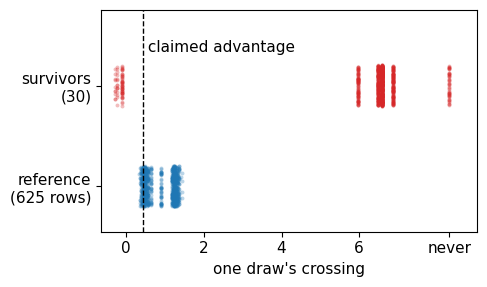

In [72]:
def lesson_2_figure(d):
    """Step 2.12: every draw's crossing, survivors on top and the reference group below, with the claimed advantage."""
    g, ref, cl = d["cross"], d["cross_rest"], d["claimed"]
    fin = g[np.isfinite(g)]
    lo = min([float(ref.min()), cl] + ([float(fin.min())] if fin.size else []))
    hi = max([float(ref.max()), cl] + ([float(fin.max())] if fin.size else []))
    pad = 0.05 * (hi - lo)
    never_x = hi + 4 * pad
    jitter = np.random.default_rng(2026)                            # spreads the dots up and down, nothing else
    with plt.rc_context({"font.size": 11}):
        fig, ax = plt.subplots(figsize=(5, 3))
        ax.scatter(np.where(np.isfinite(g), g, never_x), 1 + jitter.uniform(-0.2, 0.2, g.size), s=8, alpha=0.3,
                   color="C3", linewidths=0)
        ax.scatter(ref, jitter.uniform(-0.2, 0.2, ref.size), s=8, alpha=0.3, color="C0", linewidths=0)
        ax.axvline(cl, color="k", ls="--", lw=1)
        ax.text(cl, 1.3, " claimed advantage", fontsize=11, va="bottom")
        ax.set_xlim(lo - pad, never_x + 2 * pad)
        ticks = [v for v in ax.get_xticks() if lo - pad <= v <= hi + pad]
        ax.set_xticks(ticks + [never_x])
        ax.set_xticklabels([f"{v:g}".replace("-", "−") for v in ticks] + ["never"])
        ax.set_yticks([0, 1])
        ax.set_yticklabels([f"reference\n({d['n_rest']} rows)", f"survivors\n({d['ne']})"])
        ax.set_ylim(-0.45, 1.75)
        ax.set_xlabel("one draw's crossing")
        fig.tight_layout()
        plt.show()


def lesson_2_show_step1(d):
    """Step 2.12: the step-1 gate's comparison, counted from this case's draws, then the chart."""
    g, ref, yes = d["cross"], d["cross_rest"], d["dec"]["G1 step-1 certificate"]
    lo_band, hi_band = float(ref.min()) + MARGIN, float(ref.max()) + MARGIN
    n_low, n_high = int((g <= lo_band).sum()), int((g > hi_band).sum())
    n_mid = g.size - n_low - n_high
    pairs, total = d["pairs"]["G1 step-1 certificate"], g.size * ref.size
    lesson_table(["the survivors' draws", "how many", "reference draws within 0.10"],
                 [[lesson_text("crossing at or below <<a>> + 0.10 = <<b>>", a=float(ref.min()), b=lo_band), n_low,
                   lesson_text("all <<k>>", k=ref.size)],
                  [lesson_text("crossing above <<a>> + 0.10 = <<b>>", a=float(ref.max()), b=hi_band),
                   lesson_text("<<k>> (<<v>> never <<w>>)", k=n_high, v=d["never"],
                               w=lesson_2_plural(d["never"], "crosses", "cross")), "none"],
                  ["in between", n_mid, "some"]],
                 note=lesson_text("The reference group: <<m>> other last-step held-out rows. Their <<k>> crossings run "
                                  "from <<a>> to <<b>>.", m=d["n_rest"], k=ref.size, a=float(ref.min()),
                                  b=float(ref.max())))
    lesson_show(lesson_text("**Pairs within 0.10,** out of <<t>>:", t=total))
    if n_mid:
        lines = [lesson_tex(r"\text{pairs} &= <<l>> \times <<r>> + <<x>>", l=n_low, r=ref.size, x=pairs - n_low * ref.size),
                 lesson_tex(r"&= <<p>>", p=pairs)]
        how = lesson_text("The first term counts the low draws, each within 0.10 of all <<r>> reference draws; the "
                          "second counts the close pairs of the <<m>> <<w>> in between.", r=ref.size, m=n_mid,
                          w=lesson_2_plural(n_mid, "draw", "draws"))
    else:
        lines, how = [lesson_tex(r"\text{pairs} &= <<l>> \times <<r>> = <<p>>", l=n_low, r=ref.size, p=pairs)], None
    lesson_math(*lines, lesson_tex(r"&<<op>> <<k>> \;\Rightarrow\; <<w>>", op=r"\ge" if yes else "<", k=int(K05),
                                   w=lesson_2_word(yes)), note=how)
    g2r = d["dec"]["G2R BCA harm test"]
    so = lesson_text("**So:** the step-1 gate <<fb>>, as the run recorded, <<cmp>> the BCA harm test.",
                     fb=lesson_2_fb(yes), cmp="like" if yes == g2r else "unlike")
    if n_mid == 0 and n_low == d["low"]:
        so += lesson_text(" No survivor draw lands in between, and <<low>> below the claimed advantage. So both gates "
                          "count the same <<l>> <<d>> against the same 5% bar.", l=n_low,
                          d=lesson_2_plural(n_low, "draw", "draws"),
                          low=lesson_2_plural(n_low, "the one low draw is exactly the draw at or",
                                              lesson_text("the <<l>> low draws are exactly the draws at or", l=n_low)))
    lesson_show(so)
    share, lo, hi = d["noisy"], float(ref.min()), float(ref.max())
    rel = "close to" if abs(share - ALPHA) <= 0.02 else ("more than" if share > ALPHA else "fewer than")
    rows_txt = lesson_text("<<p:%1>> of the reference rows are the noisy cell's low payouts (venture at "
                           "$(t = 1, c = 0)$ paying about 0, an over-prediction near <<q>>), <<rel>> the 10% that a "
                           "90% point cuts.", p=share, q=d["q10v"], rel=rel)
    if lo < 1.0 < hi:
        lead = "**Its yardstick wobbles.** "
        tail = (" So the reference's crossing swings" if rel == "close to" else " Its crossing still swings") + \
            lesson_text(" between the ordinary rows' noise and those over-predictions: here from <<a>> to <<b>>.",
                        a=lo, b=hi)
    else:
        lead = "**Its yardstick.** "
        tail = lesson_text(" Here the reference's crossings all land <<where>>, from <<a>> to <<b>>.", a=lo, b=hi,
                           where="among those over-predictions" if lo >= 1.0 else "in the ordinary rows' noise")
    lesson_show(lead + rows_txt + tail)
    lesson_show(lesson_text("**The draws, drawn** (seed <<s>>, <<h>> shape, advantage <<a:+2>>; <<m>> draws per "
                            "group). Each dot is one draw's crossing: the survivors' on top, the reference group's "
                            "below (dots are spread up and down only to be visible). The dashed line is the claimed "
                            "advantage, the yardstick of Steps 2.10 and 2.11. Draws that never cross sit at *never*.",
                            s=str(d["seed"]), h=d["harm"], a=d["adv"], m=lesson_2_draws))
    lesson_2_figure(d)


lesson_2_show_step1(lesson_2_case_a)

In [73]:
def lesson_2_agreement():
    """Step 2.12: how often the step-1 gate and the BCA harm test decided alike over the run, by harm shape."""
    g1, g2r = DEV[..., M["G1 step-1 certificate"]], DEV[..., M["G2R BCA harm test"]]
    same = {h: float((g1[:, :, k] == g2r[:, :, k]).mean()) for k, h in enumerate(HARMS)}
    lesson_show(lesson_text(
        "*Deeper: skip on a first read.*\n\n"
        "**Why the two gates agree in the tail shape.** A draw's crossing lands on one survivor's score, or never. "
        "A tail-shape survivor paid about 2, for a score near $Q_{\\mathrm{gap}} - 2$, below both yardsticks (the "
        "claimed advantage, and every reference crossing plus 0.10); or about −5, for a score near "
        "$Q_{\\mathrm{gap}} + 5$, far above both. So both gates count the same low draws against the same 5% bar: over "
        "the run they decided alike in <<t:%1>> of tail-shape cases. Shortfall outcomes sit near $1 + \\text{adv}$, in "
        "several worlds close to $Q_{\\mathrm{safe}}$, so crossings can land in between, where the step-1 gate's answer "
        "depends on its wobbling yardstick: there the two agreed in only <<s:%1>> of cases. The Try-it after Step 2.13 "
        "shows one such disagreement.", t=same["tail"], s=same["shortfall"]))


lesson_2_agreement()

*Deeper: skip on a first read.*

**Why the two gates agree in the tail shape.** A draw's crossing lands on one survivor's score, or never. A tail-shape survivor paid about 2, for a score near $Q_{\mathrm{gap}} - 2$, below both yardsticks (the claimed advantage, and every reference crossing plus 0.10); or about −5, for a score near $Q_{\mathrm{gap}} + 5$, far above both. So both gates count the same low draws against the same 5% bar: over the run they decided alike in 100.0% of tail-shape cases. Shortfall outcomes sit near $1 + \text{adv}$, in several worlds close to $Q_{\mathrm{safe}}$, so crossings can land in between, where the step-1 gate's answer depends on its wobbling yardstick: there the two agreed in only 61.4% of cases. The Try-it after Step 2.13 shows one such disagreement.

### Step 2.13 · Every gate on one case, checked against the run

The table lists all eleven gates for the case of Steps 2.9 to 2.12: the decision, the number it rests on, and the run's record. It adds four gates not worked above. The step-1 gate's local version (printed as G1 local reference) keeps only the context-1 rows of its reference group; it is information only. The three shuffled controls (Step 2.4) read random rows from the pool of survivors and other held-out rows instead of the survivors.

In [74]:
def lesson_2_show_all(d):
    """Step 2.13: all eleven gates for this case, with the number each decision rests on, checked against DEV."""
    ne, cl, qs = d["ne"], d["claimed"], d["qs"]
    rank_txt = (lesson_text("$s_{(<<k>>)}$ = <<v>> against <<c>>", k=d["rank"], v=float(d["srt"][d["rank"] - 1]), c=cl)
                if d["rank"] <= ne else lesson_text("rank <<k>> is above $n$ = <<n>>", k=d["rank"], n=ne))
    key = {"G1 step-1 certificate": lesson_text("<<p>> pairs within 0.10; <<k>> needed",
                                                p=d["pairs"]["G1 step-1 certificate"], k=int(K05)),
           "G1 local reference": lesson_text("<<p>> pairs within 0.10, against <<m>> context-1 rows",
                                             p=d["pairs"]["G1 local reference"], m=d["n_local"]),
           "G2R BCA harm test": lesson_text("<<l>> draws at or below the claimed advantage; 50 needed", l=d["low"]),
           "G2 BCA tail certificate": lesson_text("$\\lambda_{\\mathrm{BCA}}$ = <<t>> against <<c>>", t=d["thr"], c=cl),
           "G3 split-conformal certificate": rank_txt,
           "G4 exact binomial certificate": lesson_text("$b$ = <<b>> against $x(n)$ = <<x>>", b=d["b"], x=d["x"]),
           "G5 plug-in mean": lesson_text("$\\bar r$ = <<m>> against <<q>>", m=d["mean_r"], q=qs),
           "G6 mean harm test": lesson_text("upper bound <<u>> against <<q>>", u=d["upper"], q=qs),
           "G1 shuffled": lesson_text("<<p>> pairs within 0.10", p=d["pairs"]["G1 shuffled"]),
           "G2R shuffled": lesson_text("<<l>> draws at or below the claimed advantage", l=d["low_f"]),
           "G2 shuffled": lesson_text("$\\lambda_{\\mathrm{BCA}}$ = <<t>> against <<c>>", t=d["thr_f"], c=cl)}
    word = lambda v: "venture" if v else "fall back"
    lesson_table(["gate (printed as)", "decision", "the number it rests on", "the run's record"],
                 [[name, word(d["dec"][name]), key[name], word(d["record"][name])] for name in lesson_2_gates],
                 note=lesson_text("**So:** all <<k>> decisions, worked from scratch, match the run's record for seed "
                                  "<<s>>, <<n>> survivors, <<h>> shape, advantage <<a:+2>>.", k=len(lesson_2_gates),
                                  s=str(d["seed"]), n=ne, h=d["harm"], a=d["adv"]))


def lesson_2_case(try_seed, try_survivors, try_harm, try_adv):
    """Steps 2.9 to 2.13 for any case of the run: every line recomputed and checked against the run's record."""
    if not lesson_2_valid_case(try_seed, try_survivors, try_harm, try_adv):
        return
    if not lesson_2_ready():
        return
    d = lesson_2_case_data(int(try_seed), int(try_survivors), try_harm, float(try_adv))
    for show in (lesson_2_show_survivors, lesson_2_show_proof, lesson_2_show_harm, lesson_2_show_step1,
                 lesson_2_show_all):
        show(d)


lesson_2_show_all(lesson_2_case_a)

| gate (printed as) | decision | the number it rests on | the run's record |
|---|---|---|---|
| G1 step-1 certificate | venture | 75,000 pairs within 0.10; 50,000 needed | venture |
| G1 local reference | venture | 75,925 pairs within 0.10, against 91 context-1 rows | venture |
| G2R BCA harm test | venture | 75 draws at or below the claimed advantage; 50 needed | venture |
| G2 BCA tail certificate | fall back | $\lambda_{\mathrm{BCA}}$ = 6.883 against 0.443 | fall back |
| G3 split-conformal certificate | fall back | $s_{(28)}$ = 6.576 against 0.443 | fall back |
| G4 exact binomial certificate | fall back | $b$ = 5 against $x(n)$ = 0 | fall back |
| G5 plug-in mean | fall back | $\bar r$ = 0.827 against 1.004 | fall back |
| G6 mean harm test | venture | upper bound 1.659 against 1.004 | venture |
| G1 shuffled | venture | 348,474 pairs within 0.10 | venture |
| G2R shuffled | venture | 168 draws at or below the claimed advantage | venture |
| G2 shuffled | fall back | $\lambda_{\mathrm{BCA}}$ = 6.576 against 0.443 | fall back |

**So:** all 11 decisions, worked from scratch, match the run's record for seed 0, 30 survivors, tail shape, advantage −0.25.

**Your own case.** The cell below repeats Steps 2.9 to 2.13 for any case of the run. Its default keeps seed 0, 30 survivors and advantage −0.25, but switches to the shortfall shape: every payout is now 0.75 before noise, a little below 1, instead of sometimes a disaster. There the step-1 gate ventures while the BCA harm test falls back: test 3 in a single case.

**Seed 0, 30 survivors, shortfall shape, advantage −0.25.** In this world 89.4% of venture's outcomes fall below 1.0 and their average is 0.75: falling back is right, since venture is unsafe and worse on average.

| $r_i$ | $s_i$ | claimed − $s_i$ | $r_i - Q_{\mathrm{safe}}$ | below? |
|---|---|---|---|---|
| 0.314 | 1.133 | −0.690 | −0.690 | yes |
| 0.944 | 0.503 | −0.060 | −0.060 | yes |
| 1.013 | 0.434 | 0.009 | 0.009 | no |
| 1.234 | 0.214 | 0.229 | 0.229 | no |

The lowest and highest outcomes, and the outcomes on either side of $Q_{\mathrm{safe}}$. The two middle columns agree, survivor by survivor. *below?* asks whether the outcome is below $Q_{\mathrm{safe}}$, the fallback's value.

$$
\begin{aligned}
\text{claimed} &= Q_{\mathrm{gap}} - Q_{\mathrm{safe}} \\ &= 1.447 - 1.004 = 0.443 \\ s_i \le 0.443 &\iff r_i \ge 1.004 \\ b &= \#\{i : s_i > \text{claimed}\} \\ &= \#\{i : r_i < Q_{\mathrm{safe}}\} = 25 \text{ of } 30
\end{aligned}
$$

**So:** 25 of the 30 survivors fall below the fallback's value. ($\#$ counts the survivors that meet the condition.)

**Exact binomial certificate (G4).**

$$
\begin{aligned}
& P(\mathrm{Binomial}(30, 0.1) \le 0) = 0.0424 \le 0.05 \\ & P(\mathrm{Binomial}(30, 0.1) \le 1) = 0.1837 > 0.05 \\ & \text{so } x(30) = 0 \\ & b = 25 > x(30) = 0 \;\Rightarrow\; \text{no: fall back}
\end{aligned}
$$

The code asks the same question as $P(\mathrm{Binomial}(30, 0.1) \le b) \le 0.05$: here 1.0000, above 0.05.

...

**Pairs within 0.10,** out of 1,000,000:

$$
\begin{aligned}
\text{pairs} &= 0 \times 1{,}000 + 468{,}838 \\ &= 468{,}838 \\ &\ge 50{,}000 \;\Rightarrow\; \text{yes: venture}
\end{aligned}
$$

The first term counts the low draws, each within 0.10 of all 1,000 reference draws; the second counts the close pairs of the 952 draws in between.

**So:** the step-1 gate ventures, as the run recorded, unlike the BCA harm test.

**Its yardstick wobbles.** 9.9% of the reference rows are the noisy cell's low payouts (venture at $(t = 1, c = 0)$ paying about 0, an over-prediction near 1.447), close to the 10% that a 90% point cuts. So the reference's crossing swings between the ordinary rows' noise and those over-predictions: here from 0.328 to 1.431.

**The draws, drawn** (seed 0, shortfall shape, advantage −0.25; 1,000 draws per group). Each dot is one draw's crossing: the survivors' on top, the reference group's below (dots are spread up and down only to be visible). The dashed line is the claimed advantage, the yardstick of Steps 2.10 and 2.11. Draws that never cross sit at *never*.

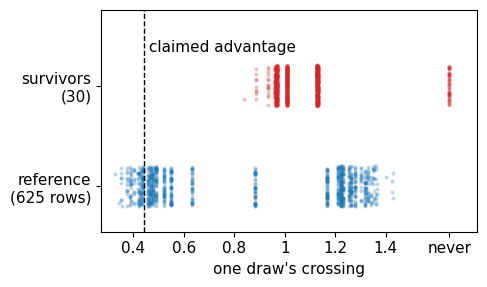

| gate (printed as) | decision | the number it rests on | the run's record |
|---|---|---|---|
| G1 step-1 certificate | venture | 468,838 pairs within 0.10; 50,000 needed | venture |
| G1 local reference | fall back | 1,000 pairs within 0.10, against 91 context-1 rows | fall back |
| G2R BCA harm test | fall back | 0 draws at or below the claimed advantage; 50 needed | fall back |
| G2 BCA tail certificate | fall back | $\lambda_{\mathrm{BCA}}$ = 1.133 against 0.443 | fall back |
| G3 split-conformal certificate | fall back | $s_{(28)}$ = 1.009 against 0.443 | fall back |
| G4 exact binomial certificate | fall back | $b$ = 25 against $x(n)$ = 0 | fall back |
| G5 plug-in mean | fall back | $\bar r$ = 0.744 against 1.004 | fall back |
| G6 mean harm test | fall back | upper bound 0.818 against 1.004 | fall back |
| G1 shuffled | venture | 335,009 pairs within 0.10 | venture |
| G2R shuffled | fall back | 25 draws at or below the claimed advantage | fall back |
| G2 shuffled | fall back | $\lambda_{\mathrm{BCA}}$ = 1.794 against 0.443 | fall back |

**So:** all 11 decisions, worked from scratch, match the run's record for seed 0, 30 survivors, shortfall shape, advantage −0.25.

In [75]:
# Try it: pick a seed (0 to 199), a number of survivors (5, 10, 20, 30, 45, 60 or 100), a harm shape
# ("shortfall" or "tail") and an advantage (1, 0.5, 0.25, 0.1, -0.1, -0.25, -0.5, -1, -2 or -4.6),
# then rerun this cell. Every line is recomputed and checked against the run's record.
try_seed, try_survivors, try_harm, try_adv = 0, 30, "shortfall", -0.25
lesson_2_case(try_seed, try_survivors, try_harm, try_adv)

### Step 2.14 · Results

**How to read it.** The first lines repeat Step 2.2's shares of venture's outcomes below 1.0, world by world; above 0.10 makes a world unsafe. Next come the best rule that never reads the survivors and the room. Then one row per rule, pooled over all 28,000 cases:
- **pooled regret:** lower is better; 0 is perfect;
- **gain / room:** 1 is as good as the oracle, 0 no better than refusing thin data, below 0 worse;
- **unsafe-deviation:** how often the rule ventured at the gap in unsafe worlds; lower is safer. **(tail worlds)** is the same in tail-shape unsafe worlds only.

In [76]:
UNSAFE = np.array([[below_safe(h, a) > ALPHA for a in ADVANTAGE] for h in HARMS])          # (harm, world)
unsafe_mask = np.broadcast_to(UNSAFE[None, None], DEV.shape[:4])
tail_mask = unsafe_mask.copy(); tail_mask[:, :, HARMS.index("shortfall")] = False
pooled = REG.mean(axis=(0, 1, 2, 3))
best_wb = min(WORLD_BLIND, key=lambda m: pooled[M[m]])
room = pooled[M[best_wb]] - pooled[M["oracle switch"]]
gain = {m: pooled[M[best_wb]] - pooled[M[m]] for m in METHODS}
unsafe_rate = {m: DEV[..., M[m]][unsafe_mask].mean() for m in METHODS}
unsafe_tail = {m: DEV[..., M[m]][tail_mask].mean() for m in METHODS}

print("P(venture outcome at the gap < 1.0), by world; above 0.10 is an unsafe world:")
for harm in HARMS:
    print(f"  {harm:9}", "  ".join(f"{a:+.2f}: {below_safe(harm, a):.3f}" for a in ADVANTAGE))
print(f"\nBest world-blind rule: {best_wb}.  Room = {room:.4f} (its pooled regret minus the oracle's)\n")
print(f"{'rule':31} {'pooled regret':>13} {'gain / room':>11} {'unsafe-deviation':>17} {'(tail worlds)':>14}")
for m in METHODS:
    print(f"{m:31} {pooled[M[m]]:13.4f} {gain[m] / room:11.2f} {unsafe_rate[m]:17.3f} {unsafe_tail[m]:14.3f}")

P(venture outcome at the gap < 1.0), by world; above 0.10 is an unsafe world:
  shortfall +1.00: 0.000  +0.50: 0.006  +0.25: 0.106  +0.10: 0.309  -0.10: 0.691  -0.25: 0.894  -0.50: 0.994  -1.00: 1.000  -2.00: 1.000  -4.60: 1.000
  tail      +1.00: 0.000  +0.50: 0.071  +0.25: 0.107  +0.10: 0.129  -0.10: 0.157  -0.25: 0.179  -0.50: 0.214  -1.00: 0.286  -2.00: 0.429  -4.60: 0.800

Best world-blind rule: range limit.  Room = 0.1215 (its pooled regret minus the oracle's)

rule                            pooled regret gain / room  unsafe-deviation  (tail worlds)
oracle switch                          0.0000        1.00             0.250          0.250
greedy                                 0.5505       -3.53             1.000          1.000
range limit                            0.1215        0.00             0.000          0.000
count penalty                          0.1222       -0.01             0.000          0.000
host BC actor                          0.4939       -3.06             0.8

**What to notice**
- **The widths did worse than refusing thin data.** Instead of removing part of the room, they added regret: gain ÷ room was −2.50 for A1 and −2.09 for A2 (pooled regret 0.4253 and 0.3755, against 0.1215).
- **Every gate that reads the survivors helped:** from 0.38 of the room (G2 and G4) to 0.87 (the plain average, G5).
- **Shuffling the survivors away erased the help:** G1 shuffled −2.58, G2R shuffled −1.91, G2 shuffled 0.00.
- **Safety split the gates:** in unsafe worlds the tail certificates ventured in 0.002 (G2) and 0.001 (G4) of cases, split conformal in 0.057, the plain average in 0.270 and the step-1 gate in 0.517.

*Deeper: skip on a first read.*

The cell below checks Step 2.6's prediction of the room, shows where the widths' regret comes from, and works out why A1 almost never ventures at the gap.

In [77]:
def lesson_2_where_regret():
    """Step 2.14: each rule's pooled regret, split into the gap decision and the other states; A1 at the gap."""
    if not lesson_2_ready():
        return
    adv = np.array(ADVANTAGE)
    gap_cost_of = lambda venture: float(P_TEST[1]) * np.where(venture, np.maximum(0, -adv), np.maximum(0, adv))
    split = {}
    for name in ("range limit", "greedy", "A1 width penalty", "A2 width BC multiplier"):
        total = float(REG[..., M[name]].mean())
        split[name] = (total, float(gap_cost_of(DEV[..., M[name]]).mean()))
    lesson_check(best_wb == "range limit" and abs(room - split["range limit"][0]) < 1e-12,
                 "the room is not refusing thin data's pooled regret")
    extra = (REG[..., M["range limit"]] - gap_cost_of(DEV[..., M["range limit"]])).mean(axis=(1, 2, 3))
    flipped = int((extra > 1e-12).sum())
    lesson_table(["rule (printed as)", "pooled regret", "at the gap", "elsewhere"],
                 [[name, f"{t:.5f}", f"{g:.5f}", f"{t - g:.5f}"] for name, (t, g) in split.items()],
                 note=lesson_text(
                     "**So:** refusing thin data loses <<g:5>> at the gap, as Step 2.6 predicted, plus <<e:5>> "
                     "elsewhere: in <<k>> of the <<n>> seeds the critic's noise flipped a step-0 choice, which greedy, "
                     "refusing thin data and every gate share. That makes the room <<r:5>> (the printout rounds it to "
                     "0.1215). A1 is about as cautious as refusing thin data at the gap, but loses <<a:5>> elsewhere. A2 "
                     "loses <<b:5>> at the gap, where it ventured in <<v:%1>> of all cases, whatever the world.",
                     g=split["range limit"][1], e=split["range limit"][0] - split["range limit"][1], k=flipped,
                     n=lesson_2_seeds, r=room, a=split["A1 width penalty"][0] - split["A1 width penalty"][1],
                     b=split["A2 width BC multiplier"][1], v=float(DEV[..., M["A2 width BC multiplier"]].mean())))
    # A1 ventures at the gap when its utility there beats safe's: lambda below the break-even lambda* (Step 1.8).
    fits = []
    for seed in range(lesson_2_seeds):
        train, cal, surv = collect(seed)
        q, n = fit_critic(train)
        fits.append((q,) + fit_scale(train, q))
    cut = np.array([(q[1, 1, VENTURE] - q[1, 1, SAFE]) / (sc[1, 1, VENTURE] - sc[1, 1, SAFE]) for q, sc, u in fits])
    r1_min = np.array([INFO[k]["r1_min"] for k in range(lesson_2_seeds)])
    r1_max = np.array([INFO[k]["r1_max"] for k in range(lesson_2_seeds)])
    a1 = DEV[..., M["A1 width penalty"]]
    lesson_check(np.array_equal(a1.any(axis=(1, 2, 3)), r1_min < cut) and not np.any(r1_max < cut),
                 "A1 should venture at the gap exactly in the seeds whose smallest threshold is below the break-even")
    q, sc, unit = fits[0]
    lam, ss, sv = float(r1_min[0]), float(sc[1, 1, SAFE]), float(sc[1, 1, VENTURE])
    us, uv = q[1, 1, SAFE] - GAIN * lam * ss, q[1, 1, VENTURE] - GAIN * lam * sv
    lesson_check(np.isclose(sv, unit[1]) and uv < us and lam > cut[0], "A1's gap decision in seed 0 is not as described")
    lesson_show(lesson_text(
        "**Why A1 almost never ventures at the gap.** A1 picks the action with the higher utility, $Q - \\lambda\\sigma$ "
        "(Step 1.5). Write $\\sigma_{\\mathrm{safe}}$ and $\\sigma_{\\mathrm{gap}}$ for the error scales of safe and of "
        "venture at the gap. In seed 0, the smallest threshold at $t = 1$ that A1 met in any of its <<c>> cases was "
        "$\\lambda$ = <<l:4>>:", c=int(a1[0].size), l=lam))
    lesson_math(
        r"\text{safe} &= Q_{\mathrm{safe}} - \lambda\,\sigma_{\mathrm{safe}}",
        lesson_tex(r"&= <<q:4>> - <<l:4>> \times <<s:4>>", q=q[1, 1, SAFE], l=lam, s=ss),
        lesson_tex(r"&= <<u:4>>", u=us),
        r"\text{venture} &= Q_{\mathrm{gap}} - \lambda\,\sigma_{\mathrm{gap}}",
        lesson_tex(r"&= <<q:4>> - <<l:4>> \times <<s:4>>", q=q[1, 1, VENTURE], l=lam, s=sv),
        lesson_tex(r"&= <<u:4>>", u=uv),
        r"\lambda^* &= \frac{\text{claimed}}{\sigma_{\mathrm{gap}} - \sigma_{\mathrm{safe}}}",
        lesson_tex(r"&= \frac{<<c:4>>}{<<a:4>> - <<b:4>>} = <<x>>", c=q[1, 1, VENTURE] - q[1, 1, SAFE], a=sv, b=ss,
                   x=cut[0]),
        lesson_tex(r"\lambda &= <<l:4>> > \lambda^* \;\Rightarrow\; \text{fall back}", l=lam),
        note=lesson_text("Venture wins only when $\\lambda$ is below the break-even $\\lambda^*$, as in Step 1.8. The gap "
                         "has no training rows, so $\\sigma_{\\mathrm{gap}}$ is the step's pooled spread, <<a:4>>, "
                         "<<k:1>> times safe's: every threshold hits venture harder. In seed 0 none came near <<x>>.",
                         a=sv, k=sv / ss, x=cut[0]))
    seeds = np.flatnonzero(a1.any(axis=(1, 2, 3)))
    claimed_all = np.array([INFO[k]["claimed"] for k in range(lesson_2_seeds)])
    lesson_check(len(seeds) == 1 and int(np.argmax(claimed_all)) == int(seeds[0]),
                 "the text below describes one seed, the one with the largest claimed advantage")
    s = int(seeds[0])
    q, sc, unit = fits[s]
    lesson_check(np.isclose(q[1, 1, VENTURE] - q[1, 1, SAFE], claimed_all[s]) and cut[s] > r1_min[s]
                 and int(a1[s].sum()) == int(a1.sum()), "seed's claimed advantage or break-even differs")
    lesson_show(lesson_text("Only seed <<s>>, with the largest claimed advantage (<<c:4>>), has a break-even above its "
                            "smallest threshold (<<x>> against <<l:4>>): all <<k>> of A1's ventures at the gap, out of "
                            "<<t>> cases, are there.", s=str(s), c=claimed_all[s], x=cut[s], l=r1_min[s],
                            k=int(a1.sum()), t=int(a1.size)))


lesson_2_where_regret()

| rule (printed as) | pooled regret | at the gap | elsewhere |
|---|---|---|---|
| range limit | 0.12155 | 0.12025 | 0.00130 |
| greedy | 0.55055 | 0.54925 | 0.00130 |
| A1 width penalty | 0.42525 | 0.12025 | 0.30500 |
| A2 width BC multiplier | 0.37548 | 0.37353 | 0.00195 |

**So:** refusing thin data loses 0.12025 at the gap, as Step 2.6 predicted, plus 0.00130 elsewhere: in 2 of the 200 seeds the critic's noise flipped a step-0 choice, which greedy, refusing thin data and every gate share. That makes the room 0.12155 (the printout rounds it to 0.1215). A1 is about as cautious as refusing thin data at the gap, but loses 0.30500 elsewhere. A2 loses 0.37353 at the gap, where it ventured in 65.3% of all cases, whatever the world.

**Why A1 almost never ventures at the gap.** A1 picks the action with the higher utility, $Q - \lambda\sigma$ (Step 1.5). Write $\sigma_{\mathrm{safe}}$ and $\sigma_{\mathrm{gap}}$ for the error scales of safe and of venture at the gap. In seed 0, the smallest threshold at $t = 1$ that A1 met in any of its 140 cases was $\lambda$ = 1.4748:

$$
\begin{aligned}
\text{safe} &= Q_{\mathrm{safe}} - \lambda\,\sigma_{\mathrm{safe}} \\ &= 1.0042 - 1.4748 \times 0.2391 \\ &= 0.6516 \\ \text{venture} &= Q_{\mathrm{gap}} - \lambda\,\sigma_{\mathrm{gap}} \\ &= 1.4474 - 1.4748 \times 0.6765 \\ &= 0.4497 \\ \lambda^* &= \frac{\text{claimed}}{\sigma_{\mathrm{gap}} - \sigma_{\mathrm{safe}}} \\ &= \frac{0.4432}{0.6765 - 0.2391} = 1.013 \\ \lambda &= 1.4748 > \lambda^* \;\Rightarrow\; \text{fall back}
\end{aligned}
$$

Venture wins only when $\lambda$ is below the break-even $\lambda^*$, as in Step 1.8. The gap has no training rows, so $\sigma_{\mathrm{gap}}$ is the step's pooled spread, 0.6765, 2.8 times safe's: every threshold hits venture harder. In seed 0 none came near 1.013.

Only seed 91, with the largest claimed advantage (0.7882), has a break-even above its smallest threshold (1.696 against 1.5702): all 93 of A1's ventures at the gap, out of 28,000 cases, are there.

### Step 2.15 · Verdicts

**How to read it.** Each line gives a test's bar, its result, and ALIVE or SHELVED. The last lines are reported but decide nothing. In the printout, BCA's *posterior* and *credibility* refer to its 1,000 random draws (Step 2.7).

In [78]:
def verdict(shelved):
    return "SHELVED" if shelved else "ALIVE"

print("Test 1, width channel (bar: gain at least 0.25 of the room)")
for m in ("A1 width penalty", "A2 width BC multiplier"):
    print(f"  {m}: gain / room = {gain[m] / room:+.2f} -> {verdict(gain[m] < 0.25 * room)}")
g1, g1s = gain["G1 step-1 certificate"], gain["G1 shuffled"]
kept = g1s / g1 if g1 > 0 else float("nan")
print("Test 2, step-1 gate (bars: gain at least 0.50 of the room; shuffled keeps at most half)")
print(f"  gain / room = {g1 / room:+.2f}; shuffled keeps {kept:+.2f} of it -> {verdict(g1 < 0.5 * room or g1s > 0.5 * g1)}")
p2r, p1 = pooled[M["G2R BCA harm test"]], pooled[M["G1 step-1 certificate"]]
print("Test 3, decision-referenced reference point (bar: G2R's pooled regret below G1's)")
print(f"  G2R {p2r:.4f} against G1 {p1:.4f} -> {verdict(p2r >= p1)}")
agree = (DEV[..., M["G2 BCA tail certificate"]] == DEV[..., M["G4 exact binomial certificate"]]).mean()
print("Test 4a, 'BCA's posterior decides differently from the exact binomial test' (shelved if agreement >= 0.99)")
print(f"  agreement {agree:.4f} -> {verdict(agree >= 0.99)}")
d_b = unsafe_rate["G3 split-conformal certificate"] - unsafe_rate["G2 BCA tail certificate"]
print("Test 4b, 'BCA's credibility makes deviations safer than split conformal' (bar: 0.05 more unsafe deviations)")
print(f"  split conformal {unsafe_rate['G3 split-conformal certificate']:.3f} against BCA "
      f"{unsafe_rate['G2 BCA tail certificate']:.3f} (difference {d_b:+.3f}) -> {verdict(d_b < 0.05)}")
d_c = unsafe_tail["G5 plug-in mean"] - unsafe_tail["G2 BCA tail certificate"]
print("Test 4c, 'tail safety needs quantile semantics, not a mean' (bar: 0.05, tail-shape unsafe worlds)")
print(f"  plug-in mean {unsafe_tail['G5 plug-in mean']:.3f} against BCA {unsafe_tail['G2 BCA tail certificate']:.3f} "
      f"(difference {d_c:+.3f}) -> {verdict(d_c < 0.05)}")
print("Reported, not deciding:")
print(f"  G2's pooled regret minus G5's: {pooled[M['G2 BCA tail certificate']] - pooled[M['G5 plug-in mean']]:+.4f}")
for name in ("G2 BCA tail certificate", "G4 exact binomial certificate"):
    worst = [DEV[:, i, :, :, M[name]].mean(axis=0)[UNSAFE].max() for i in range(len(EVIDENCE))]
    print(f"  {name}: worst unsafe-world deviation rate by evidence size:",
          "  ".join(f"n={ne}: {v:.3f}" for ne, v in zip(EVIDENCE, worst)))

Test 1, width channel (bar: gain at least 0.25 of the room)
  A1 width penalty: gain / room = -2.50 -> SHELVED
  A2 width BC multiplier: gain / room = -2.09 -> SHELVED
Test 2, step-1 gate (bars: gain at least 0.50 of the room; shuffled keeps at most half)
  gain / room = +0.58; shuffled keeps -4.44 of it -> ALIVE
Test 3, decision-referenced reference point (bar: G2R's pooled regret below G1's)
  G2R 0.0282 against G1 0.0508 -> ALIVE
Test 4a, 'BCA's posterior decides differently from the exact binomial test' (shelved if agreement >= 0.99)
  agreement 0.9961 -> SHELVED
Test 4b, 'BCA's credibility makes deviations safer than split conformal' (bar: 0.05 more unsafe deviations)
  split conformal 0.057 against BCA 0.002 (difference +0.055) -> ALIVE
Test 4c, 'tail safety needs quantile semantics, not a mean' (bar: 0.05, tail-shape unsafe worlds)
  plug-in mean 0.290 against BCA 0.002 (difference +0.288) -> ALIVE
Reported, not deciding:
  G2's pooled regret minus G5's: +0.0601
  G2 BCA tail ce

**What to notice**
- **Test 1, shelved** for both widths: gain ÷ room −2.50 and −2.09, against a bar of +0.25.
- **Test 2, alive:** the step-1 gate removed 0.58 of the room, and its shuffled control kept −4.44 of that gain: shuffled, it did far worse than refusing thin data.
- **Test 3, alive:** the BCA harm test's pooled regret was 0.0282, against the step-1 gate's 0.0508.
- **Test 4a, shelved:** BCA's tail certificate and the exact binomial certificate agreed in 0.9961 of cases.
- **Test 4b, alive, narrowly:** split conformal 0.057 against BCA 0.002, a difference of +0.055 against a bar of 0.05.
- **Test 4c, alive:** the plain average 0.290 against BCA 0.002 in tail-shape unsafe worlds.
- **Reported:** the tail certificate's regret was 0.0601 above the plain average's. In its worst unsafe world it ventured in at most 0.030 of seeds at every number of survivors; theory allows about 0.05.

In [79]:
def lesson_2_disagreements():
    """Step 2.15: where BCA's tail certificate and the exact binomial certificate disagree (test 4a)."""
    d2, d4 = DEV[..., M["G2 BCA tail certificate"]], DEV[..., M["G4 exact binomial certificate"]]
    lesson_check(abs((d2 == d4).mean() - agree) < 1e-12, "the agreement differs from the verdict's")
    rows = [[str(ne), int((d2 != d4)[:, i].sum()), int((d2 & ~d4)[:, i].sum()), int((~d2 & d4)[:, i].sum())]
            for i, ne in enumerate(EVIDENCE)]
    i30 = EVIDENCE.index(30)
    cautious, bold = int((~d2 & d4)[:, i30].sum()), int((d2 & ~d4)[:, i30 + 1:].sum())
    lesson_check(int((d2 != d4)[:, :i30].sum()) == 0 and int((d2 & ~d4)[:, i30].sum()) == 0
                 and int((~d2 & d4)[:, i30 + 1:].sum()) == 0, "the pattern of disagreements differs from the text")
    lesson_table(["survivors", "cases that differ", "BCA yes, exact no", "BCA no, exact yes"], rows,
                 note=lesson_text(
                     "**So:** <<k>> of the <<t>> cases differ, none with fewer than 29 survivors, where both always "
                     "fall back. With 30 survivors, BCA said no where the exact test said yes (<<c>> times): more than "
                     "50 of its 1,000 draws happened never to cross, which put its 950th crossing above the exact "
                     "threshold. With 45 or more, it said yes where the exact test said no (<<b>> times): its 950th "
                     "crossing happened to land below the exact threshold. Both are slips of the 1,000 draws "
                     "(Step 2.5).", k=int((d2 != d4).sum()), t=int(d2.size), c=cautious, b=bold))


lesson_2_disagreements()

| survivors | cases that differ | BCA yes, exact no | BCA no, exact yes |
|---|---|---|---|
| 5 | 0 | 0 | 0 |
| 10 | 0 | 0 | 0 |
| 20 | 0 | 0 | 0 |
| 30 | 54 | 0 | 54 |
| 45 | 34 | 34 | 0 |
| 60 | 18 | 18 | 0 |
| 100 | 4 | 4 | 0 |

**So:** 110 of the 28,000 cases differ, none with fewer than 29 survivors, where both always fall back. With 30 survivors, BCA said no where the exact test said yes (54 times): more than 50 of its 1,000 draws happened never to cross, which put its 950th crossing above the exact threshold. With 45 or more, it said yes where the exact test said no (56 times): its 950th crossing happened to land below the exact threshold. Both are slips of the 1,000 draws (Step 2.5).

### Step 2.16 · By number of survivors and by world

*Deeper: skip on a first read.*

**How to read it.** The printout has four blocks; columns are numbers of survivors.
1. Pooled regret, over both shapes and all ten advantages.
2. The unsafe-deviation rate.
3. The share of (seed, harm shape) pairs in which the rule's gap decision changes somewhere along the ten advantages. A rule whose decision never changes cannot be reading the outcomes.
4. Information only: the step-1 gate's pooled regret at other margins (its rule uses 0.10).

In [80]:
show = ["greedy", "range limit", "count penalty", "host BC actor", "A1 width penalty", "A2 width BC multiplier",
        "G1 step-1 certificate", "G1 local reference", "G2R BCA harm test", "G2 BCA tail certificate",
        "G3 split-conformal certificate", "G5 plug-in mean", "G6 mean harm test", "oracle switch"]
head = f"{'evidence size (survivors)':31}" + "".join(f"{ne:>8d}" for ne in EVIDENCE)
print("Pooled regret by evidence size (both shapes, whole ladder)\n" + head)
for m in show:
    print(f"{m:31}" + "".join(f"{REG[:, i, ..., M[m]].mean():8.4f}" for i in range(len(EVIDENCE))))
print("\nUnsafe-deviation rate by evidence size (unsafe worlds only)\n" + head)
for m in ["G1 step-1 certificate", "G2R BCA harm test", "G2 BCA tail certificate", "G3 split-conformal certificate",
          "G4 exact binomial certificate", "G5 plug-in mean", "G6 mean harm test"]:
    print(f"{m:31}" + "".join(f"{DEV[:, i, ..., M[m]][unsafe_mask[:, i]].mean():8.3f}" for i in range(len(EVIDENCE))))
print("\nShare of (seed, harm shape) where the gap decision changes somewhere along the ladder\n" + head)
for m in ["range limit", "host BC actor", "A1 width penalty", "A2 width BC multiplier", "G1 step-1 certificate",
          "G2R BCA harm test", "G2 BCA tail certificate", "G5 plug-in mean"]:
    d = DEV[..., M[m]]
    varies = d.any(axis=-1) & ~d.all(axis=-1)
    print(f"{m:31}" + "".join(f"{varies[:, i].mean():8.2f}" for i in range(len(EVIDENCE))))

gap_cost = lambda venture: P_TEST[1] * np.where(venture, np.maximum(0, -ADV), np.maximum(0, ADV))
away = REG[..., M["greedy"]] - gap_cost(np.ones(SWP.shape[:4], dtype=bool))
print("\nInformation only: the step-1 certificate at other margins (its rule uses 0.10)")
for k, m in enumerate(SWEEP):
    print(f"  margin {m:4.2f}: pooled regret {(away + gap_cost(SWP[..., k])).mean():.4f}")

Pooled regret by evidence size (both shapes, whole ladder)
evidence size (survivors)             5      10      20      30      45      60     100
greedy                           0.5505  0.5505  0.5505  0.5505  0.5505  0.5505  0.5505
range limit                      0.1215  0.1215  0.1215  0.1215  0.1215  0.1215  0.1215
count penalty                    0.1222  0.1222  0.1222  0.1222  0.1222  0.1222  0.1222
host BC actor                    0.4939  0.4939  0.4939  0.4939  0.4939  0.4939  0.4939
A1 width penalty                 0.4274  0.4253  0.4250  0.4250  0.4247  0.4247  0.4247
A2 width BC multiplier           0.4075  0.4075  0.4018  0.3985  0.3872  0.3368  0.2891
G1 step-1 certificate            0.0854  0.0693  0.0482  0.0441  0.0397  0.0362  0.0329
G1 local reference               0.0661  0.0505  0.0296  0.0264  0.0224  0.0191  0.0161
G2R BCA harm test                0.0619  0.0457  0.0256  0.0219  0.0176  0.0139  0.0108
G2 BCA tail certificate          0.1215  0.1215  0.1215  0.04

**What to notice**
- **The tail certificate needs 29 survivors.** Its regret stays at 0.1215, refusing thin data's, with 5, 10 and 20; it drops to 0.0485 at 30. Split conformal can say yes from 10 survivors.
- **The plain average had the lowest regret at every size:** 0.0297 with 5 survivors, 0.0065 with 100.
- **Unsafe deviations:** the tail certificate at most 0.003 at every size; split conformal 0.050 to 0.089 from 10 survivors; the plain average 0.257 to 0.306; the BCA harm test fell from 0.392 to 0.196 as survivors grew.
- **Who reads the outcomes:** refusing thin data and pulling toward the log never change their gap decision (0.00), A1 in at most 0.01 of pairs, A2 in up to 0.35 and only with many survivors; the gates almost always (G2 from 30 survivors).
- **Margins (information only):** the step-1 gate's regret was 0.0491 at margin 0 and 0.0837 at 1.00; its 0.10 gave 0.0508.

**How to read the figures.** The first shows each rule's regret in each world with 30 survivors, one panel per harm shape; the vertical scale is stretched near 0 (symlog), and lower is better. The second shows return (left) and safety (right) as the number of survivors grows; the dashed line on the right marks 5%.

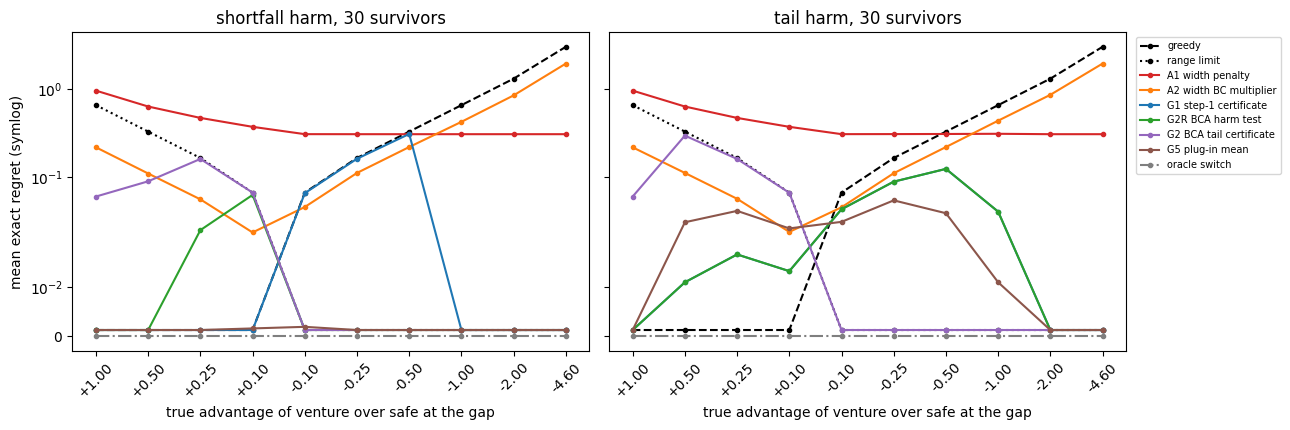

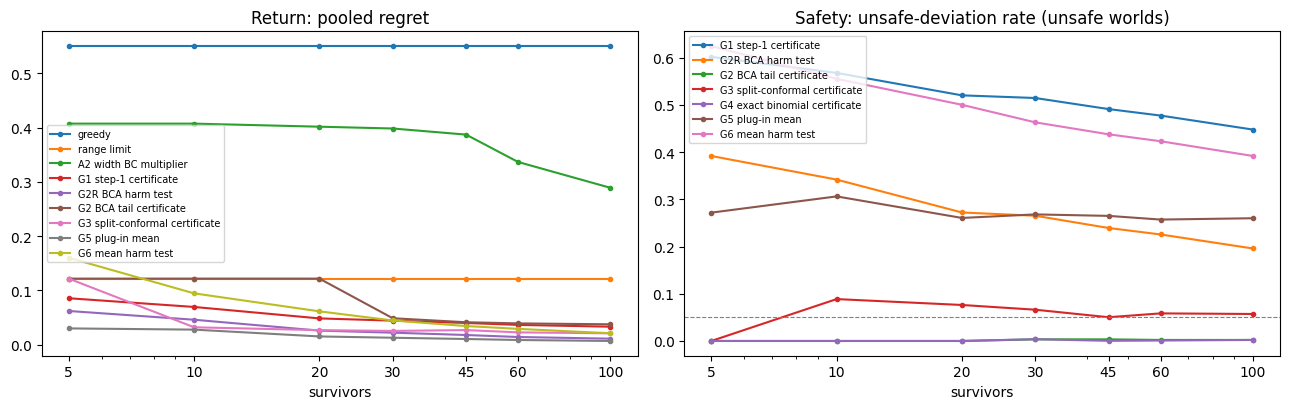

In [81]:
lines = ["greedy", "range limit", "A1 width penalty", "A2 width BC multiplier", "G1 step-1 certificate",
         "G2R BCA harm test", "G2 BCA tail certificate", "G5 plug-in mean", "oracle switch"]
styles = dict(zip(lines, ["k--", "k:", "C3-", "C1-", "C0-", "C2-", "C4-", "C5-", "C7-."]))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
i30 = EVIDENCE.index(30)
for h, harm in enumerate(HARMS):
    ax = axes[h]
    for m in lines:
        ax.plot(range(len(ADV)), REG[:, i30, h, :, M[m]].mean(axis=0), styles[m], marker="o", ms=3, label=m)
    ax.set_xticks(range(len(ADV))); ax.set_xticklabels([f"{a:+.2f}" for a in ADV], rotation=45)
    ax.set_yscale("symlog", linthresh=0.02)
    ax.set_title(f"{harm} harm, 30 survivors")
    ax.set_xlabel("true advantage of venture over safe at the gap")
axes[0].set_ylabel("mean exact regret (symlog)")
axes[1].legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1.0))
fig.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for m in ["greedy", "range limit", "A2 width BC multiplier", "G1 step-1 certificate", "G2R BCA harm test",
          "G2 BCA tail certificate", "G3 split-conformal certificate", "G5 plug-in mean", "G6 mean harm test"]:
    axes[0].plot(EVIDENCE, [REG[:, i, ..., M[m]].mean() for i in range(len(EVIDENCE))], marker="o", ms=3, label=m)
for m in ["G1 step-1 certificate", "G2R BCA harm test", "G2 BCA tail certificate", "G3 split-conformal certificate",
          "G4 exact binomial certificate", "G5 plug-in mean", "G6 mean harm test"]:
    axes[1].plot(EVIDENCE, [DEV[:, i, ..., M[m]][unsafe_mask[:, i]].mean() for i in range(len(EVIDENCE))],
                 marker="o", ms=3, label=m)
axes[1].axhline(1 - BETA, color="grey", lw=0.8, ls="--")
axes[0].set_title("Return: pooled regret"); axes[1].set_title("Safety: unsafe-deviation rate (unsafe worlds)")
for ax in axes:
    ax.set_xscale("log"); ax.set_xticks(EVIDENCE); ax.set_xticklabels(EVIDENCE); ax.set_xlabel("survivors")
    ax.legend(fontsize=7)
fig.tight_layout(); plt.show()

**What to notice**
- **Regret by world (first figure).** Refusing thin data loses only where venture is better on average (advantage above 0), and greedy only where it is worse. The tail certificate loses almost nothing where venture is worse and gives up return where it is better. The step-1 gate's large losses sit in the shortfall worlds from −0.10 to −0.50.
- **By number of survivors (second figure).** The plain average has the lowest regret throughout, and A2 improves mainly with 60 or more survivors. In safety, the tail certificate and its exact twin stay at or below 0.004 at every size; split conformal stays above the 5% line from 10 survivors on (0.050 to 0.089); the plain average (0.257 to 0.306) and the harm tests (0.196 to 0.625) stay far above it (the printout's second block).

### Step 2.17 · Checks

*Deeper: skip on a first read.*

The next cell confirms that the toy works as described; any failure stops the notebook.
1. The outcome laws add up, and the gap's average is $1 + \text{adv}$ in both shapes.
2. Worlds are paired: the same log and the same survivor random numbers.
3. The critic never trains on the survivors.
4. Regrets are never negative, the oracle's is 0, and the gates differ from greedy only at the gap.
5. Test 4a's algebra: with infinitely many draws, BCA's certificate equals the exact binomial test, on 2,000 random score sets.
6. The width is calibrated where it is measured: A1's widths cover fresh logged rows (printed).

In [82]:
# 1. Outcome laws normalize, and the gap mean is 1 + advantage in both shapes.
for harm in HARMS:
    for adv in ADVANTAGE:
        lw = gap_law(harm, adv)
        assert np.isclose(sum(p for p, _ in lw), 1) and all(p >= 0 for p, _ in lw)
        assert np.isclose(sum(p * m for p, m in lw), 1 + adv)
# 2. Worlds are paired: the same log and the same survivor random numbers.
tr, ca, sv = collect(0)
tr2, ca2, sv2 = collect(0)
assert all(np.array_equal(tr[k], tr2[k]) and np.array_equal(ca[k], ca2[k]) for k in tr)
assert np.allclose(survivor_rewards(sv, "shortfall", 0.5, 30) - survivor_rewards(sv, "shortfall", -1.0, 30), 1.5)
# 3. The critic never trains on survivors, and wants the gap action in every seed (asserted in run_seed).
q0, n0 = fit_critic(tr)
assert n0[1, 1, VENTURE] == 0
# 4. Regrets are non-negative, the oracle's is zero, and the gate rules differ from greedy only at the gap.
assert np.all(REG >= -1e-12) and np.allclose(REG[..., M["oracle switch"]], 0)
away = REG[..., M["greedy"]] - gap_cost(np.ones(DEV.shape[:4], dtype=bool))
for m in GATES:
    assert np.allclose(REG[..., M[m]], away + gap_cost(DEV[..., M[m]]))
# 5. Exact algebra behind test 4a: BCA's infinite-draw certificate equals the exact binomial test.
rng = np.random.default_rng([ROOT_SEED, 998])
for _ in range(2000):
    n = int(rng.integers(5, 120)); s = rng.standard_normal(n); a = float(rng.normal(1.0, 0.5))
    assert (bca_exact(s) <= a) == (binom_cdf(int((s > a).sum()), n, ALPHA) <= 1 - BETA)
# 6. The width is calibrated where it is measured: coverage of A1's widths on fresh logged rows.
sc0, un0 = fit_scale(tr, q0)
r0_ = bca_exact(np.abs(targets(ca, 0, q0) - q0[0, ca["c"], ca["a"][:, 0]]) / sc0[0, ca["c"], ca["a"][:, 0]])
r1_ = bca_exact(np.abs(targets(ca, 1, q0) - q0[1, ca["c"], ca["a"][:, 1]]) / sc0[1, ca["c"], ca["a"][:, 1]])
fresh = collect(10_000)[1]
for t, r_ in ((0, r0_), (1, r1_)):
    cov = (np.abs(targets(fresh, t, q0) - q0[t, fresh["c"], fresh["a"][:, t]])
           <= r_ * sc0[t, fresh["c"], fresh["a"][:, t]]).mean()
    print(f"A1 width coverage at recorded actions, stage {t}: {cov:.3f} (target at least {1 - ALPHA:.2f})")
    assert cov >= 0.85
print("All checks passed. Notebook seconds:", round(time.perf_counter() - START, 1))

A1 width coverage at recorded actions, stage 0: 0.902 (target at least 0.90)
A1 width coverage at recorded actions, stage 1: 0.935 (target at least 0.90)
All checks passed. Notebook seconds: 29.0


**What to notice.** All checks passed. A1's widths covered 0.902 (at $t = 0$) and 0.935 (at $t = 1$) of fresh logged rows, against the 0.90 target: BCA's width is calibrated where it is measured, at logged actions. It still did not help the decision at the gap, where no logged action is.

### Step 2.18 · Information only: decisions by world, and the step-1 gate's comparison group

*Deeper: skip on a first read.*

*Added after the run; it decides nothing.*

**How to read it.**
1. For each harm shape, the share of seeds that venture at the gap in each world, with 30 survivors. A * marks unsafe worlds; venture is better on average when the advantage is above 0.
2. The worst single unsafe world: the highest share of seeds that venture there, by number of survivors.
3. The step-1 gate's comparison group over the 200 seeds: the median and the 5% point of its crossings (printed as "posterior median" and "5% posterior quantile"), and the share of its rows that are the noisy cell's low payouts.

In [83]:
# Added after the run, information only: per-world decisions at 30 survivors, the worst single unsafe world,
# and the spread of the reference group that the step-1 gate compares against.
i30 = EVIDENCE.index(30)
show = ["range limit", "A2 width BC multiplier", "G1 step-1 certificate", "G2R BCA harm test",
        "G2 BCA tail certificate", "G3 split-conformal certificate", "G5 plug-in mean"]
for h, harm in enumerate(HARMS):
    print(f"{harm}: share of seeds that venture at the gap with 30 survivors "
          "(* unsafe world; venture is better on average when the advantage is above 0)")
    print(f"{'rule':31}" + "".join(f"{a:+7.2f}{'*' if UNSAFE[h, w] else ' '}" for w, a in enumerate(ADV)))
    for m in show:
        print(f"{m:31}" + "".join(f"{DEV[:, i30, h, w, M[m]].mean():7.2f} " for w in range(len(ADV))))
    print()
print("Worst single unsafe world: share of seeds that venture there, by evidence size")
for m in ["G2 BCA tail certificate", "G4 exact binomial certificate", "G3 split-conformal certificate",
          "G2R BCA harm test", "G5 plug-in mean"]:
    worst = [DEV[:, k, :, :, M[m]].mean(axis=0)[UNSAFE].max() for k in range(len(EVIDENCE))]
    print(f"{m:31}", "  ".join(f"n={ne}: {v:.2f}" for ne, v in zip(EVIDENCE, worst)))
med, low, share = [], [], []
for seed in range(N_SEEDS):
    train, cal, _ = collect(seed)
    q, _ = fit_critic(train)
    rng = np.random.default_rng([ROOT_SEED, seed, 1])
    rng.standard_exponential((DRAWS, max(EVIDENCE) + 1))   # the gap's draws, as in run_seed
    s_rest = q[1, cal["c"], cal["a"][:, 1]] - cal["r"][:, 1]
    cross = bca(s_rest, rng.standard_exponential((DRAWS, s_rest.size + 1)))[1]
    med.append(np.median(cross)); low.append(np.quantile(cross, 0.05))
    share.append(np.mean((cal["c"] == 0) & (cal["a"][:, 1] == VENTURE) & (cal["r"][:, 1] < 1.5)))
print(f"\nThe step-1 gate's reference group (all other final-step calibration rows), over {N_SEEDS} seeds:")
print(f"  posterior median of its 90% crossing: mean {np.mean(med):.2f}, from {min(med):.2f} to {max(med):.2f}")
print(f"  5% posterior quantile of that crossing: mean {np.mean(low):.2f}")
print(f"  share of its rows that are the noisy cell's low outcomes (over-prediction near 1.5): {np.mean(share):.3f}")

shortfall: share of seeds that venture at the gap with 30 survivors (* unsafe world; venture is better on average when the advantage is above 0)
rule                             +1.00   +0.50   +0.25*  +0.10*  -0.10*  -0.25*  -0.50*  -1.00*  -2.00*  -4.60*
range limit                       0.00    0.00    0.00    0.00    0.00    0.00    0.00    0.00    0.00    0.00 
A2 width BC multiplier            0.67    0.67    0.67    0.67    0.67    0.67    0.67    0.65    0.65    0.65 
G1 step-1 certificate             1.00    1.00    1.00    1.00    0.98    0.98    0.94    0.00    0.00    0.00 
G2R BCA harm test                 1.00    1.00    0.85    0.06    0.00    0.00    0.00    0.00    0.00    0.00 
G2 BCA tail certificate           0.91    0.73    0.03    0.00    0.00    0.00    0.00    0.00    0.00    0.00 
G3 split-conformal certificate    1.00    0.99    0.35    0.01    0.00    0.00    0.00    0.00    0.00    0.00 
G5 plug-in mean                   1.00    1.00    1.00    0.99    0.01 

**What it showed**
- **A2 ventured in 0.65 to 0.67 of seeds in every world,** good or bad: the same caution everywhere, not a reading of the survivors.
- **In the shortfall shape, the step-1 gate ventured in 0.98, 0.98 and 0.94 of seeds** at advantages −0.10, −0.25 and −0.50, where venture is worse; the BCA harm test ventured in none of them. In the tail shape, the two gates decided alike: each survivor draw crosses at a usual outcome, below both gates' yardsticks, or at a disaster (or never), far above both, so both gates count the same draws against the same 5% bar (Step 2.12).
- **Worst single unsafe world:** the tail certificate and its exact twin at most 0.03; split conformal 0.32 to 0.38 from 10 survivors; the BCA harm test 0.85 to 0.92; the plain average 1.00 at every size.
- **The comparison group is an unstable yardstick:** its median crossing averaged 1.04 and ran from 0.35 to 1.50 across seeds; 0.107 of its rows are the noisy cell's low payouts.

## What Part 2 found

| Claim | Result | Verdict |
|---|---|---|
| 1. BCA's width at every action (A1, A2) removes at least a quarter of the room | gain ÷ room −2.50 and −2.09 | shelved |
| 2. The step-1 gate removes at least half the room, and shuffled outcomes keep at most half of that | +0.58; shuffled keeps −4.44 | alive |
| 3. Comparing with the critic's claimed advantage (the same as comparing outcomes with the safe action's value) beats a fixed margin against the rest | pooled regret 0.0282 against 0.0508 | alive |
| 4a. BCA decides differently from the exact binomial test | agreement 0.9961 | shelved |
| 4b. BCA's confidence makes deviations safer than split conformal | 0.002 against 0.057: 5.5 points, bar 5 | alive, narrowly |
| 4c. Safety needs a quantile, not an average | 0.002 against 0.290 in tail worlds | alive |

- **Test 1, shelved: BCA's width did worse than refusing thin data.**
  - *The idea:* BCA's calibrated width puts caution where the critic is wrong: as a penalty at every action (A1), or as production's multiplier on the pull toward logged actions (A2).
  - *What we tested (and the kill rule):* both against refusing thin data, over 200 seeds, both harm shapes, ten advantages and seven numbers of survivors. Each is shelved if it removes less than a quarter of the room.
  - *What happened:* pooled regret 0.4253 (A1) and 0.3755 (A2), against 0.1215. A2 beat plain pulling toward the log (0.4939) only by venturing less often everywhere: with 30 survivors it ventured in 0.65 to 0.67 of seeds in every world, good or bad. A1's gap decision changed across the ten advantages in at most 0.01 of pairs. The widths were still calibrated where measured: 0.902 and 0.935 coverage of fresh logged rows.
  - *Why:* the width is measured at logged actions, and the gap has none. Its error scale falls back to the pooled spread, so A1 almost never ventures at the gap (93 of the 28,000 cases, all in one seed; Step 2.14), and the survivors reach it only through one threshold shared with about 600 other rows. Meanwhile the width also hits good actions that are merely noisy. The hosts use the width during training (point 1 of the closing *What this means for BCA*), where a critic's errors spread through its own training targets; this toy tests it only when a decision is made, so it cannot test that.
- **Gates that read the survivors helped.** They removed 0.38 to 0.87 of the room. With shuffled outcomes, the step-1 gate and the harm test did worse than refusing thin data, and the tail certificate only matched it.
- **Compare outcomes with the fallback's value.** Comparing scores with the critic's claimed advantage is the same as comparing outcomes with $Q_{\mathrm{safe}}$ (Step 2.9), which the log covers well. The step-1 gate's yardstick, all other last-step rows, is unstable (its median crossing ran from 0.35 to 1.50 across seeds); in the shortfall shape it ventured in 0.94 to 0.98 of seeds at advantages −0.10 to −0.50. The BCA harm test stopped those, and regret fell from 0.0508 to 0.0282.
- **For return, the plain average won:** the lowest regret at every number of survivors, 0.0157 overall and 0.0297 even with 5 survivors.
- **For safety, BCA's tail certificate won.** It and its exact twin ventured in at most 0.03 of seeds in every unsafe world. Split conformal reached 0.32 to 0.38 in its worst world, because its promise holds only on average over many data sets, not for the data in hand. The plain average ventured in every seed of its worst unsafe world. The certificate's price: 0.0601 more regret than the plain average, and no yes at all below 29 survivors.
- **Test 4a, shelved: with equal weights, BCA is a textbook test.**
  - *The idea:* BCA's 1,000 random draws of weights (Step A.4; in Bayesian terms, its posterior, Step 2.7) add information that a classical test lacks.
  - *What we tested (and the kill rule):* the BCA tail certificate (G2) against the exact binomial certificate (G4), case by case; shelved if they agree in at least 99% of cases.
  - *What happened:* they agreed in 0.9961 of cases. The 110 that differ are slips of the 1,000 draws (Step 2.15); with 100,000 draws, BCA matched the exact threshold on every score set tested (Step 2.5).
  - *Why:* with equal weights, BCA's threshold is one of the sorted scores, picked by a binomial tail (Step A.6). That is the exact binomial (Clopper–Pearson) test, which is also Wilks' (1941) tolerance limit and Vovk's (2012) training-conditional conformal bound.

**The insight.** The useful signal is the risky action's own held-out outcomes, measured against the fallback's value. Which statistic to use depends on the promise: an average for return, a tail certificate for "rarely worse than the fallback". With equal weights, BCA adds no information over the exact binomial test; what it adds over split conformal is the kind of promise, one that holds for the data in hand. Its one non-textbook part, weighting, could not matter here, since every survivor comes from the state being decided. Part 3 tests a BCA gate built for return, and Part 4 tests the weights.

---
# Part 3 · Can a BCA gate raise return? The mean gate

*Pre-registered. Original notebook: `bca_mean_gate_toy.ipynb`. Kill rules fingerprint `50a0f49d…b1d3`.*

**The question.** Part 2 ended on a split. For return, the plain average of the held-out tries won, but it promised nothing; BCA's tail certificate kept its promise, but cost 0.0601 more regret. Return depends on the average outcome, so BCA's *mean gate* asks whether the risky action beats the fallback on average, and promises to say yes to a harmful one at most 5% of the time. When every gate must be equally safe, does the mean gate earn the most?

**What changed since Part 2.**
- Each situation offers several risky actions, the **candidates**. A critic picks one from training tries, and a gate then checks that pick on separate held-out tries.
- The score is return: the true average gain of the final choice, instead of Part 2's regret.
- Outcomes come in three shapes, including rare disasters that small samples often miss.

**In this part**

**Setting up**

1. Situations, candidates and a two-stage decision
2. Three outcome shapes, and the floor
3. 36 worlds, 200 seeds
4. The gates

**Before the run**

5. How much clean evidence each gate needs
6. Why rare disasters fool the t-test
7. The six claims and their kill rules

**The run, and one situation by hand**

8. The run
9. One situation from the run: the critic's lucky pick
10. One proposal through every gate

**Results**

11. Results
12. Verdicts
13. Equal harm: tuned on seeds 0–99, scored on seeds 100–199
14. Where each gate earns its gain
15. Information only: stricter caps, lost return, the hardest worlds
16. Checks

### Step 3.1 · Situations, candidates and a two-stage decision

Part 3's words:
- A **situation** is one decision: take the safe action (the fallback, worth 0) or one of several candidates.
- The **candidates** are this part's risky actions.
- A try's **gain** is its outcome minus the safe action's.
- A candidate is **good** if its true average gain $\mu$ is above 0, and *harmful* if it is below; only the scoring knows $\mu$.
- Each candidate has $n$ training tries and $n$ separate held-out tries, with $n$ between 5 and 100.

Each situation is decided in two stages, then scored:
1. **The critic proposes.** From the training tries alone, it picks the candidate with the best average, if that average is above 0. This pick is the *proposal*.
2. **A gate decides.** From held-out tries, never the training tries, it accepts the proposal or stays safe.
3. **The score** is the true average gain $\mu$ of the final choice; staying safe scores 0.

This mirrors offline reinforcement learning: the critic likes actions the log barely covers, and the safe action is what the log usually did. The next cell holds the experiment's settings.

In [84]:
import math, time, hashlib
from fractions import Fraction
from functools import lru_cache
import numpy as np
import matplotlib.pyplot as plt

START = time.perf_counter()
ROOT_SEED, STREAM = 20261014, 41
N_SEEDS, SITUATIONS, CMAX = 200, 20, 30
TUNE_SEEDS, EVAL_SEEDS = np.arange(0, 100), np.arange(100, 200)
SHAPES = ("steady", "rare disaster", "rare jackpot")
GOOD_SHARES = (0.1, 0.3, 0.5)
CANDIDATES = (1, 3, 10, 30)
N_MIN, N_MAX = 5, 100
FLOOR = {"steady": -3.0, "rare disaster": -8.0, "rare jackpot": -3.0}
CEILING = {"steady": 3.0, "rare disaster": 3.0, "rare jackpot": 8.0}
BIG = 8.0
DELTA = 0.05                    # stated level: accept a harmful proposal at most 5% of the time
DRAWS = 10_000                  # BCA's random weightings per decision
TAIL, CONFIDENCE = 0.1, 0.95    # BCA's tail gate as built: at least 90% of tries beat 0, 95% sure
COUNT_NEED = 30
BUDGET = 0.10                   # harm budget of the shared-budget gate
MARGINS = (0.0, 0.02, 0.05, 0.1, 0.2, 0.3, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0)
LEVELS = (0.5, 0.3, 0.2, 0.1, 0.05, 0.02, 0.01, 0.005, 0.002, 0.001)
TAIL_SHARES = (0.5, 0.4, 0.3, 0.2, 0.1, 0.05)
COUNTS = (5, 10, 20, 30, 50, 80, 100)
assert CMAX == max(CANDIDATES) and 0 < DELTA < 1

### Step 3.2 · Three outcome shapes, and the floor

In each world, the tries' gains follow one of three shapes. Within a shape, a gain stays inside a known range. The bottom of the range is the **floor**, $g_{\min}$: the worst gain a try can possibly have. Gates may use the range.

In [85]:
def lesson_3_ready(after_run=True):
    """True while the names this part reads still hold Part 3's experiment.

    Part 4 reuses several of the same names (FLOOR, MU, DEC, ...). After a Run All, this part's worked examples
    therefore ask you to rerun Part 3's cells first, instead of quietly reading Part 4's numbers."""
    try:
        ok = STREAM == 41 and N_SEEDS == 200 and isinstance(FLOOR, dict)
        if after_run:
            ok = ok and isinstance(DEC, dict) and "BCA mean gate, shared budget" in DEC and len(MU) == N_SEEDS
    except (NameError, TypeError):
        ok = False
    if not ok:
        lesson_show("This cell reads Part 3's experiment, but a later part has since reused some of its names. "
                    "Rerun Part 3's code cells in order, from the settings cell in Step 3.1 down to this cell. "
                    "Part 4's worked examples will then ask you to rerun Part 4's cells.")
    return bool(ok)


def lesson_3_block(*lines):
    """One aligned display-math block as Markdown, so that one output can hold several blocks and their lead-ins."""
    return "$$\n\\begin{aligned}\n" + r" \\ ".join(lines) + "\n\\end{aligned}\n$$"


def lesson_3_number(x):
    """True for a plain finite number (not text, not True or False): what the Try-it cells accept."""
    return (isinstance(x, (int, float, np.integer, np.floating)) and not isinstance(x, (bool, np.bool_))
            and math.isfinite(x))


def lesson_3_places(total, *terms, least=3, most=8, nonzero=True):
    """The fewest decimals (from least to most) at which the shown terms add up to the shown total, and (with
    nonzero) a total that is not 0 does not show as 0. With no terms, only the second condition applies."""
    for d in range(least, most + 1):
        shown = round(float(total), d)
        adds_up = not terms or abs(sum(round(float(t), d) for t in terms) - shown) < 0.5 * 10 ** -d
        if adds_up and (shown != 0 or total == 0 or not nonzero):
            return d
    return most


def lesson_3_shapes():
    """The three outcome shapes; each range comes from the settings cell above."""
    if not lesson_3_ready(after_run=False):
        return
    typical = {"steady": "the true average plus noise (spread 1)",
               "rare disaster": lesson_text("usually a small gain near its own center (0.2 to 0.6, give or take "
                                            "0.3), but sometimes a loss of <<b:0>>", b=BIG),
               "rare jackpot": lesson_text("usually a small loss near its own center (−0.1 to −0.4, give or take "
                                           "0.3), but sometimes a gain of <<b:0>>", b=BIG)}
    hard = {"steady": "the noise is large next to the average",
            "rare disaster": "a few tries often show no disaster",
            "rare jackpot": "a few tries often show no jackpot"}
    lesson_table(["Shape", "A typical try", "Range of a try's gain", "Why it is hard"],
                 [[shape, typical[shape], lesson_text("<<a:0>> to <<b:0>>", a=FLOOR[shape], b=CEILING[shape]),
                   hard[shape]] for shape in SHAPES])


lesson_3_shapes()

| Shape | A typical try | Range of a try's gain | Why it is hard |
|---|---|---|---|
| steady | the true average plus noise (spread 1) | −3 to 3 | the noise is large next to the average |
| rare disaster | usually a small gain near its own center (0.2 to 0.6, give or take 0.3), but sometimes a loss of 8 | −8 to 3 | a few tries often show no disaster |
| rare jackpot | usually a small loss near its own center (−0.1 to −0.4, give or take 0.3), but sometimes a gain of 8 | −3 to 8 | a few tries often show no jackpot |

In the rare-disaster shape, a candidate's true average mixes its usual gains with its disasters:

$$
\mu = (1-p)\,u - 8p
$$

- $p$ is the candidate's **disaster chance**: the chance that a try loses 8 instead of making a usual gain.
- $u$ is the average of its usual gains: about its center, between 0.2 and 0.6.

The rare-jackpot shape mirrors this, with a usual small loss and a rare gain of 8. The next cell finds the disaster chance at which a candidate turns harmful.

In [86]:
def lesson_3_even(u):
    """The disaster chance at which a rare-disaster candidate with usual gain u breaks even."""
    if not lesson_3_ready(after_run=False):
        return
    even = u / (u + BIG)
    lesson_math(r"\mu < 0 &\iff (1-p)\,u < 8p",
                r"&\iff p > \frac{u}{u+8}",
                lesson_tex(r"\frac{u}{u+8} &= \frac{<<u:1>>}{<<u:1>> + <<b:0>>} = <<e:4>>", u=u, b=BIG, e=even),
                note=lesson_text("**So:** with usual gains of <<u:1>>, a candidate is harmful once disasters strike more "
                                 "than <<e:%1>> of its tries. The run keeps candidates clear of that edge: a good "
                                 "candidate's disaster chance is below 0.7 times it (<<g:%1>> here), and a harmful "
                                 "one's lies between 1.3 times it (<<h:%1>>) and 20%.",
                                 u=u, e=even, g=0.7 * even, h=1.3 * even))


lesson_3_even(0.4)

$$
\begin{aligned}
\mu < 0 &\iff (1-p)\,u < 8p \\ &\iff p > \frac{u}{u+8} \\ \frac{u}{u+8} &= \frac{0.4}{0.4 + 8} = 0.0476
\end{aligned}
$$

**So:** with usual gains of 0.4, a candidate is harmful once disasters strike more than 4.8% of its tries. The run keeps candidates clear of that edge: a good candidate's disaster chance is below 0.7 times it (3.3% here), and a harmful one's lies between 1.3 times it (6.2%) and 20%.

### Step 3.3 · 36 worlds, 200 seeds

A **world** combines one outcome shape (3), one share of good candidates (10%, 30% or 50%) and one number of candidates per situation (1, 3, 10 or 30): $3 \times 3 \times 4 = 36$ worlds. Each world runs on 200 *seeds*, sets of random numbers, with 20 situations per seed. All 36 worlds reuse the same random numbers, so differences between worlds come from the worlds, not from luck.

Seeds 0–99 are used only to tune the gates' knobs (Step 3.13). Every other result uses seeds 100–199.

### Step 3.4 · The gates

Each gate reads held-out tries and the known range of gains, then says yes (accept) or no (stay safe). Most read only the proposal's own tries; the shrunk average also looks at every candidate's held-out average, and the shared budget at the seed's other proposals. Below, $g_1, \ldots, g_n$ are the gains of the proposal's $n$ held-out tries and $\bar g$ is their average.
- A **95% lower bound** is a value that the true average exceeds with 95% confidence.
- A gate's **harm rate** in a world is the share of harmful proposals it accepts.
- A 5% **promise** means a harm rate of at most 5% in every world.

| Gate | Says yes when | Promise |
|---|---|---|
| always safe | never | nothing to promise |
| no gate | always: the critic decides alone | none |
| count rule | the proposal has at least 30 held-out tries (like SPIBB, a count-based safe-improvement method) | none |
| plain average | $\bar g > 0$ | none |
| shrunk average | $\bar g$, pulled toward the average of all candidates in the seed's 20 situations, is above 0 | none |
| BCA's cautious average (printed "BCA average") | $(\sum_i g_i + g_{\min})/(n+1) > 0$: one more try, at the floor | none |
| t-test | the t-test's 95% lower bound is above 0 | 5%, if outcomes are roughly bell-shaped |
| Hoeffding | Hoeffding's 95% lower bound (it uses the range) is above 0 | 5% |
| empirical Bernstein | the empirical Bernstein 95% lower bound (range and spread) is above 0 | 5% |
| **BCA mean gate** | at most 500 of 10,000 weighted averages $\bar g^{(m)}$ are below 0 (Step A.8) | 5%, by a proof not yet peer reviewed (below) |
| BCA tail gate | at most $x(n)$ tries fall below 0 (Step A.7) | 95% sure that at least 90% of outcomes beat 0 |
| split-conformal tail | fewer than $\lfloor 0.1\,(n+1) \rfloor$ tries fall below 0 (Step A.2's "+1") | the same share, only on average over data sets |
| BCA mean gate, shared budget | the seed's 20 situations are decided together (Benjamini–Hochberg; Step 3.10) | on average, at most 10% of acceptances are harmful |
| oracle gate | the proposal is truly good | none needed: scoring reference only |

BCA's mean gate is the one Step A.8 built: the extra weight on the floor makes a candidate pay for the disaster its tries may be hiding. It is Gaffke's (2005) bound on an average, computed with BCA's random weights; the [Learned-Miller–Thomas bound](https://arxiv.org/abs/1905.06208) matches it ([Ming and others](https://arxiv.org/html/2607.18661)), and the repository's literature review (`reports/Calibrated bounds in policy optimization.md`) found it the tightest guaranteed small-sample bound on a mean among the sources it reviewed. Its proof is in a July 2026 preprint ([Vlassis and Thomas](https://arxiv.org/abs/2607.08415), version 1) that is not yet peer reviewed; claim 1 tests the promise. If every random weight $E_i$ were fixed at 1 instead of drawn, the weighted average would be BCA's cautious average. BCA's tail gate is computed in its exact form; Part 2 found that BCA's random draws almost always give the same decision.

### Step 3.5 · How much clean evidence each gate needs

Suppose the evidence is as clean as it can be: every held-out try shows the same gain $g$. How large must $g$ be before each gate says yes? For $n$ tries with average $\bar g$, the three classical 95% lower bounds are:

**t-test:**

$$
\bar g - t_{0.95}(n-1)\,\frac{\mathrm{sd}}{\sqrt{n}}
$$

**Hoeffding:**

$$
\bar g - (g_{\max} - g_{\min})\sqrt{\frac{\ln 20}{2n}}
$$

**Empirical Bernstein:**

$$
\bar g - \sqrt{\frac{2\,\mathrm{sd}^2 \ln 40}{n}} - \frac{7\,(g_{\max} - g_{\min})\ln 40}{3\,(n-1)}
$$

- $\mathrm{sd}$ is the tries' standard deviation (their spread): $\mathrm{sd}^2 = \frac{1}{n-1}\sum_{i=1}^{n} (g_i - \bar g)^2$.
- $t_{0.95}(n-1)$ is the one-sided 95% point of Student's t distribution with $n-1$ degrees of freedom: the value it exceeds with chance 5%.
- $g_{\max}$ is the **ceiling**, the best gain a try can have. The 20 and 40 come from the 5% level: $1/0.05$ and $2/0.05$.

**How to read it.** In the table, gains range from −1 to 1. Each row is a number of held-out tries; each column gives the smallest $g$ with which a gate says yes, and "never" means not even $g = 1$ is enough. Step 3.6 explains the paragraph below the table.

In [87]:
def smallest_gain_mean_gate(n, floor=-1.0):
    """Smallest gain the BCA mean gate accepts when all n tries show that same gain (exact; see check 2)."""
    r = DELTA ** (1 / n)
    return -floor * (1 - r) / r

print("Every held-out try shows the same gain g; gains range from -1 to +1. Smallest g each gate accepts:")
print("held-out tries   BCA mean gate   Hoeffding   empirical Bernstein   t-test")
show = lambda v: f"{v:.2f}" if v <= 1 else "never"
for n in (10, 29, 100):
    hoeffding = 2 * math.sqrt(math.log(1 / DELTA) / (2 * n))
    bernstein = 7 * 2 * math.log(2 / DELTA) / (3 * (n - 1))
    print(f"{n:>14}   {show(smallest_gain_mean_gate(n)):>13}   {show(hoeffding):>9}   {show(bernstein):>19}   any g above 0")

n, p_loss = 29, 0.05
clean = (1 - p_loss) ** n
print(f"\nA candidate gains 0.4 on 95% of tries and loses 10 on the rest (true average -0.12, so harmful).")
print(f"With {n} tries, {clean:.0%} of samples contain no loss. The t-test sees no spread in those and accepts,")
print(f"so it accepts this harmful action about {clean:.0%} of the time instead of 5%.")
print(f"Told that the floor is -10, the BCA mean gate puts {(10 / 10.4) ** n:.0%} of its weighted averages below 0")
print("for those same clean samples, far more than 5%, so it refuses.")

Every held-out try shows the same gain g; gains range from -1 to +1. Smallest g each gate accepts:
held-out tries   BCA mean gate   Hoeffding   empirical Bernstein   t-test
            10            0.35        0.77                 never   any g above 0
            29            0.11        0.45                  0.61   any g above 0
           100            0.03        0.24                  0.17   any g above 0

A candidate gains 0.4 on 95% of tries and loses 10 on the rest (true average -0.12, so harmful).
With 29 tries, 23% of samples contain no loss. The t-test sees no spread in those and accepts,
so it accepts this harmful action about 23% of the time instead of 5%.
Told that the floor is -10, the BCA mean gate puts 32% of its weighted averages below 0
for those same clean samples, far more than 5%, so it refuses.


**What to notice.**
- With 29 tries, BCA's mean gate says yes once every try gains 0.11; Hoeffding needs about 0.45 and empirical Bernstein about 0.61 (the Try-it below gives 0.455 and 0.615).
- With 10 tries, empirical Bernstein can never say yes.
- The t-test says yes to any gain above 0, with any number of tries.

The next cell works each column for one $n$.

In [88]:
lesson_3_orig39 = {"n": n, "p_loss": p_loss, "clean": clean}   # the example printed above, kept for Step 3.6's check
lesson_3_ranges = sorted({CEILING[shape] - FLOOR[shape] for shape in SHAPES})   # kept too: Part 4 reuses FLOOR


def lesson_3_evidence(n_tries):
    """The smallest identical gain each gate accepts, for gains between -1 and 1, worked for n tries."""
    if not (lesson_3_number(n_tries) and float(n_tries).is_integer() and 2 <= n_tries <= 10_000):
        lesson_show("Choose a whole number of tries from 2 to 10,000, written as a plain number such as 29.")
        return
    n_tries = int(n_tries)
    root = 0.05 ** (-1 / n_tries)
    need = root - 1
    lesson_check(abs(need - smallest_gain_mean_gate(n_tries)) < 1e-12, "the mean gate's smallest gain")
    q = math.sqrt(math.log(20) / (2 * n_tries))
    hoef = 2 * q
    dq = lesson_3_places(hoef, q, q, least=4)         # enough decimals that 2 times the shown q gives the shown result
    bern = 7 * 2 * math.log(40) / (3 * (n_tries - 1))

    def never(v):      # gains stop at 1, so a gate that needs more can never say yes
        return [r"&> 1 \;\Rightarrow\; \text{never}"] if v > 1 else []

    def says_from(v, first=False):
        if v > 1:
            return "never says yes" if first else "never"
        return lesson_text(("says yes from a gain of " if first else "from ") + "<<v:3>>", v=v)

    lesson_show("\n\n".join([
        "Every try shows the same gain $g$, so $\\bar g = g$ and $\\mathrm{sd} = 0$. Gains range from $-1$ to $1$, so "
        "$g_{\\min} = -1$ and $g_{\\max} - g_{\\min} = 2$.",
        "**Mean gate.** Step A.8's chance for identical gains, $\\left(\\frac{-g_{\\min}}{g - g_{\\min}}\\right)^{n}$, "
        "becomes $\\left(\\frac{1}{1+g}\\right)^{n}$:",
        lesson_3_block(lesson_tex(r"\left(\frac{1}{1+g}\right)^{<<n>>} &\le 0.05", n=n_tries),
                       lesson_tex(r"\iff g &\ge 0.05^{-1/<<n>>} - 1", n=n_tries),
                       lesson_tex(r"&= <<r:4>> - 1 = <<g:4>>", r=root, g=need), *never(need)),
        "**Hoeffding:**",
        lesson_3_block(lesson_tex(r"g - 2\sqrt{\frac{\ln 20}{2 \times <<n>>}} &> 0", n=n_tries),
                       lesson_tex(r"\iff g &> 2 \times <<q>> = <<h>>", q=lesson_num(q, dq), h=lesson_num(hoef, dq)),
                       *never(hoef)),
        "**Empirical Bernstein:**",
        lesson_3_block(lesson_tex(r"g - 0 - \frac{7 \times 2 \times \ln 40}{3 \times <<m>>} &> 0", m=n_tries - 1),
                       lesson_tex(r"\iff g &> <<b:4>>", b=bern), *never(bern)),
        "**t-test:**",
        lesson_3_block(lesson_tex(r"g - t_{0.95}(<<m>>) \times \frac{0}{\sqrt{<<n>>}} &> 0", m=n_tries - 1,
                                  n=n_tries),
                       r"\iff g &> 0"),
        lesson_text(
            "**So:** with <<n>> identical tries, BCA's mean gate <<a>>, Hoeffding <<b>> and empirical Bernstein <<c>>. "
            "The t-test says yes to any gain above 0: a sample with no spread leaves it no margin at all. In the "
            "experiment, gains span <<r1:0>> or <<r2:0>> instead of 2, which multiplies Hoeffding's margin by <<k1>> "
            "or <<k2>>.", n=n_tries, a=says_from(need, first=True), b=says_from(hoef), c=says_from(bern),
            r1=lesson_3_ranges[0], r2=lesson_3_ranges[-1], k1=f"{lesson_3_ranges[0] / 2:g}",
            k2=f"{lesson_3_ranges[-1] / 2:g}")]))

In [89]:
# Try it: change the number of held-out tries (a whole number from 2 to 10,000), then rerun this cell.
try_tries = 29
lesson_3_evidence(try_tries)

Every try shows the same gain $g$, so $\bar g = g$ and $\mathrm{sd} = 0$. Gains range from $-1$ to $1$, so $g_{\min} = -1$ and $g_{\max} - g_{\min} = 2$.

**Mean gate.** Step A.8's chance for identical gains, $\left(\frac{-g_{\min}}{g - g_{\min}}\right)^{n}$, becomes $\left(\frac{1}{1+g}\right)^{n}$:

$$
\begin{aligned}
\left(\frac{1}{1+g}\right)^{29} &\le 0.05 \\ \iff g &\ge 0.05^{-1/29} - 1 \\ &= 1.1088 - 1 = 0.1088
\end{aligned}
$$

**Hoeffding:**

$$
\begin{aligned}
g - 2\sqrt{\frac{\ln 20}{2 \times 29}} &> 0 \\ \iff g &> 2 \times 0.22727 = 0.45454
\end{aligned}
$$

**Empirical Bernstein:**

$$
\begin{aligned}
g - 0 - \frac{7 \times 2 \times \ln 40}{3 \times 28} &> 0 \\ \iff g &> 0.6148
\end{aligned}
$$

**t-test:**

$$
\begin{aligned}
g - t_{0.95}(28) \times \frac{0}{\sqrt{29}} &> 0 \\ \iff g &> 0
\end{aligned}
$$

**So:** with 29 identical tries, BCA's mean gate says yes from a gain of 0.109, Hoeffding from 0.455 and empirical Bernstein from 0.615. The t-test says yes to any gain above 0: a sample with no spread leaves it no margin at all. In the experiment, gains span 6 or 11 instead of 2, which multiplies Hoeffding's margin by 3 or 5.5.

### Step 3.6 · Why rare disasters fool the t-test

The paragraph below the table shows the t-test's weakness. Its candidate usually gains $u = 0.4$ but loses 10 with chance $p = 0.05$. This loss of 10, with a floor of −10, is a little harsher than the experiment's rare disasters (8 and −8, Step 3.2); the Try-it below can set either. Each try misses the disaster with chance $1-p$, independently of the others, so

$$
P(\text{no disaster in } n \text{ tries}) = (1-p)^n
$$

A sample with no disaster, a **clean** sample, shows a gain of 0.4 on every try. Its spread is $\mathrm{sd} = 0$, so the t-test's margin $t_{0.95}(n-1)\,\mathrm{sd}/\sqrt{n}$ is 0 and its bound is 0.4: it says yes. The cell below also finds how many disasters a sample may hold before the t-test says no. Told that the floor is −10, the mean gate still counts the disaster a clean sample may be hiding, through Step A.8's chance for identical gains.

In [90]:
def lesson_3_t_tail(t, df):
    """P(T > t) for Student's t distribution with df degrees of freedom, for t >= 0.

    Exact finite sums for P(|T| <= t), with th = atan(t / sqrt(df)) (Abramowitz and Stegun 26.7.3 and 26.7.4)."""
    th = math.atan(t / math.sqrt(df))
    c2 = math.cos(th) ** 2
    term, total = 1.0, 1.0
    if df % 2 == 0:            # sin(th) (1 + c2/2 + (1*3)/(2*4) c2^2 + ...), df/2 terms
        for j in range(1, df // 2):
            term *= c2 * (2 * j - 1) / (2 * j)
            total += term
        inside = math.sin(th) * total
    else:                      # (2/pi) (th + sin(th) cos(th) (1 + (2/3) c2 + (2*4)/(3*5) c2^2 + ...)), (df-1)/2 terms
        for j in range(1, (df - 1) // 2):
            term *= c2 * (2 * j) / (2 * j + 1)
            total += term
        inside = 2 / math.pi * (th + (math.sin(th) * math.cos(th) * total if df > 1 else 0.0))
    return (1 - inside) / 2


def lesson_3_t95(df):
    """t_{0.95}(df): the value Student's t distribution with df degrees of freedom exceeds with chance 5%."""
    lo, hi = 0.0, 1.0
    while lesson_3_t_tail(hi, df) > 0.05:
        hi *= 2
    for _ in range(60):
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if lesson_3_t_tail(mid, df) > 0.05 else (lo, mid)
    return hi


lesson_check(all(abs(lesson_3_t95(df) - v) < 1e-3 for df, v in ((9, 1.8331), (28, 1.7011), (99, 1.6604))),
             "Student's t values against published tables")


def lesson_3_clean(p, n_tries, usual, loss):
    """A rare-disaster candidate: how often n tries hold no disaster, and what the t-test and the mean gate do."""
    if not (all(lesson_3_number(v) for v in (p, n_tries, usual, loss)) and 0 < p < 1
            and float(n_tries).is_integer() and 2 <= n_tries <= 10_000 and 0.001 <= usual <= 100
            and -100 <= loss <= -0.001):
        lesson_show("Choose a disaster chance between 0 and 1, from 2 to 10,000 tries, a usual gain from 0.001 to "
                    "100 and a loss from −100 to −0.001, each written as a plain number such as 0.05.")
        return
    p, usual, loss, n = float(p), float(usual), float(loss), int(n_tries)
    mu = (1 - p) * usual + p * loss
    clean = (1 - p) ** n
    below = (-loss / (usual - loss)) ** n
    t95 = lesson_3_t95(n - 1)

    def fmt(x, digits=6):  # a number as typed (0.05, 0.4, -10), or with a power of ten (10^{-9}) when it is tiny
        s = f"{x:.{digits}g}"
        if "e" not in s:
            return s
        mant, ex = f"{x:.3g}".split("e")
        power = "10^{" + str(int(ex)) + "}"
        return power if mant == "1" else "-" + power if mant == "-1" else mant + r" \times " + power

    def base(s):           # a number raised to a power: in parentheses unless it is a plain number
        return s if re.fullmatch(r"[0-9.]+", s) or (s.startswith("(") and s.endswith(")")) else "(" + s + ")"

    q_shown = fmt(1 - p, 8)            # 1 - p, with enough digits to differ from 1 when p is small

    def share(x):          # a chance as a percentage, with one decimal when it is small
        if x < 0.0005:
            return "less than 0.1%"
        if x > 0.995:
            return "more than 99%"
        return lesson_pct(x, 1 if x < 0.1 else 0, latex=False)

    def in_share(x, only=False):
        s = share(x)
        return ("in only " if only and not s.startswith("less") else "in ") + s

    def sample(k):         # k disasters among the n tries: the average, the standard deviation and the t-test's bound
        avg = ((n - k) * usual + k * loss) / n
        sd = (usual - loss) * math.sqrt(k * (n - k) / (n * (n - 1)))
        return avg, sd, avg - t95 * sd / math.sqrt(n)

    def log_binom(k, hit):  # the log of the chance of exactly k hits in n tries, each a hit with chance hit
        return (math.lgamma(n + 1) - math.lgamma(k + 1) - math.lgamma(n - k + 1)
                + k * math.log(hit) + (n - k) * math.log1p(-hit))

    def chance(k):         # the chance of exactly k disasters among the n tries
        return math.exp(log_binom(k, p))

    passes = [k for k in range(n + 1) if sample(k)[2] > 0]
    top = len(passes) - 1                    # the t-test passes the samples with 0 to top disasters
    lesson_check(passes == list(range(top + 1)), "the samples the t-test passes")
    accept = sum(chance(k) for k in passes)
    if (p, n, usual, loss) == (lesson_3_orig39["p_loss"], lesson_3_orig39["n"], 0.4, -10.0):
        lesson_check(abs(clean - lesson_3_orig39["clean"]) < 1e-15 and top == 0,
                     "the printout's share of clean samples, and the t-test passing exactly those")

    # The mean gate. With k disasters, k + 1 of the n + 1 weights sit on the floor (one per disaster, plus the extra
    # one), and a weighted average is below 0 when they carry more than the share x of the total weight. Exponential
    # weights make that chance P(Binomial(n, x) <= k); for k = 0 it is Step A.8's formula, (1 - x)^n.
    x = usual / (usual - loss)
    mean_below, total = [], 0.0
    for k in range(n + 1):
        total += math.exp(log_binom(k, x))
        mean_below.append(total)
        if total > 0.05:
            break
    lesson_check(math.isclose(mean_below[0], below, rel_tol=1e-9, abs_tol=1e-300),
                 "the clean sample's chance, two ways")
    top_m = sum(v <= 0.05 for v in mean_below) - 1     # the mean gate says yes with 0 to top_m disasters
    mean_yes = top_m >= 0
    mean_accept = sum(chance(k) for k in range(top_m + 1))

    lesson_math(lesson_tex(r"\mu &= (1-p)\,u + p \times (<<l>>)", l=fmt(loss)),
                lesson_tex(r"&= <<q>> \times <<u>>", q=q_shown, u=fmt(usual)),
                lesson_tex(r"&\quad + <<p>> \times (<<l>>)", p=fmt(p, 8), l=fmt(loss)),
                lesson_tex(r"&= <<m>>", m=lesson_num(mu, lesson_3_places(mu), sign=True) if mu != 0 else "0"),
                lesson_tex(r"P(\text{no disaster}) &= (1-p)^{<<n>>} = <<q>>^{<<n>>}", n=n, q=base(q_shown)),
                lesson_tex(r"&= <<c:4>>", c=clean))
    k1 = top + 1
    avg1, sd1, bound1 = sample(k1)
    margin1 = t95 * sd1 / math.sqrt(n)
    d1 = lesson_3_places(bound1, avg1, -margin1)        # enough decimals that the bound's line adds up as shown
    lesson_show("\n\n".join([
        lesson_text("**t-test.** With $k$ disasters among the $n$ tries, each a gain of $g_{\\min} = <<l>>$ (the "
                    "floor), the average is $\\bar g = ((n-k)\\,u + k\\,g_{\\min})/n$ and the standard deviation is "
                    "$\\mathrm{sd} = (u - g_{\\min})\\sqrt{k\\,(n-k)/(n\\,(n-1))}$. The t-test says yes when its bound, "
                    "$\\bar g - t_{0.95}(n-1)\\,\\mathrm{sd}/\\sqrt{n}$, is above 0. Here $t_{0.95}(<<d>>) = <<t>>$.",
                    l=fmt(loss), d=n - 1, t=lesson_num(t95)),
        "**A clean sample** ($k = 0$, so $\\mathrm{sd} = 0$):",
        lesson_3_block(lesson_tex(r"\text{bound} &= \bar g - t_{0.95}(<<d>>)\,\frac{\mathrm{sd}}{\sqrt{n}}", d=n - 1),
                       lesson_tex(r"&= <<u>> - <<t>> \times \frac{0}{\sqrt{<<n>>}}", u=fmt(usual), t=t95, n=n),
                       lesson_tex(r"&= <<u>> > 0 \;\Rightarrow\; \text{yes}", u=fmt(usual))),
        f"**{k1} disaster{'s' if k1 > 1 else ''}** ($k = {k1}$), the fewest that make the t-test say no:",
        lesson_3_block(lesson_tex(r"\bar g &= \frac{<<a>> \times <<u>> + <<k>> \times (<<l>>)}{<<n>>}",
                                  a=n - k1, u=fmt(usual), k=k1, l=fmt(loss), n=n),
                       lesson_tex(r"&= <<g>>", g=lesson_num(avg1, d1)),
                       lesson_tex(r"\mathrm{sd} &= <<w>> \times \sqrt{\frac{<<k>> \times <<a>>}{<<n>> \times <<d>>}}",
                                  w=fmt(usual - loss), k=k1, a=n - k1, n=n, d=n - 1),
                       lesson_tex(r"&= <<s>>", s=sd1),
                       lesson_tex(r"\text{bound} &= <<g>> - <<t>> \times \frac{<<s>>}{\sqrt{<<n>>}}",
                                  g=lesson_num(avg1, d1), t=t95, s=sd1, n=n),
                       lesson_tex(r"&= <<g>> - <<x>> = <<b>>", g=lesson_num(avg1, d1), x=lesson_num(margin1, d1),
                                  b=lesson_num(bound1, d1)),
                       r"&\le 0 \;\Rightarrow\; \text{no}")]))
    if top >= 1:
        ks = list(range(top + 2)) if top + 2 <= 7 else [0, 1, 2, None, top - 1, top, top + 1]
        rows = []
        for k in ks:
            if k is None:
                rows.append(["…", "", "", "", ""])
                continue
            avg, _, bound = sample(k)
            rows.append([str(k), lesson_txt(chance(k), 4), lesson_txt(avg, lesson_3_places(avg)),
                         lesson_txt(bound, lesson_3_places(bound)), "yes" if bound > 0 else "no"])
        lesson_table(["Disasters $k$", "Chance", "$\\bar g$", "Bound", "t-test"], rows,
                     note="Chance: the chance that $n$ tries hold exactly $k$ disasters.")

    def chance_sum(title, last, total):      # P(gate says yes) = P(k <= last), as a sum of the chances above
        lines = [r"& P(\text{" + title + r"})",
                 r"&= P(\text{no disaster})" if last == 0 else lesson_tex(r"&= P(k \le <<t>>)", t=last)]
        shown = 1 <= last <= 3                # the chances are shown as a sum only when there are 2 to 4 of them
        d = lesson_3_places(total, *[chance(k) for k in range(last + 1)], least=4, most=6, nonzero=False) \
            if shown else 4
        if shown:
            lines.append("&= " + " + ".join(lesson_num(chance(k), d) for k in range(last + 1)))
        lines.append("&= " + lesson_num(total, d))
        lesson_math(*lines)

    chance_sum("t-test says yes", top, accept)

    lesson_show("**Mean gate, clean sample:**\n\n"
                + lesson_3_block(r"P(\bar g^{(m)} < 0) &= \left(\frac{-g_{\min}}{u - g_{\min}}\right)^{n}",
                                 lesson_tex(r"&= \left(\frac{<<a>>}{<<b>>}\right)^{<<n>>} = <<r:4>>",
                                            a=fmt(-loss), b=fmt(usual - loss), n=n, r=below),
                                 r"&\le 0.05 \;\Rightarrow\; \text{yes}" if mean_yes else
                                 r"&> 0.05 \;\Rightarrow\; \text{no}"))
    if mean_yes:
        lesson_show("**Mean gate, every sample.** With $k$ disasters, $k + 1$ of the $n + 1$ weights sit on the floor: "
                    "one for each disaster, plus the extra one. A weighted average is below 0 when those weights carry "
                    "more than a share $x = u/(u - g_{\\min})$ of the total weight. For Exponential weights, the chance "
                    "of that is $P(\\mathrm{Binomial}(n, x) \\le k)$, the exact share that the gate's 10,000 draws "
                    "estimate; for $k = 0$ it is the clean-sample chance above. Here the gate is judged by these "
                    "exact shares.")
        lesson_math(lesson_tex(r"x &= \frac{<<u>>}{<<w>>} = <<x>>", u=fmt(usual), w=fmt(usual - loss),
                               x=lesson_num(x, lesson_3_places(x, least=4))))
        ks = list(range(top_m + 2)) if top_m + 2 <= 7 else [0, 1, 2, None, top_m - 1, top_m, top_m + 1]
        rows = []
        for k in ks:
            if k is None:
                rows.append(["…", "", "", ""])
                continue
            rows.append([str(k), lesson_txt(chance(k), 4), lesson_txt(mean_below[k], 4),
                         "yes" if mean_below[k] <= 0.05 else "no"])
        lesson_table(["Disasters $k$", "Chance", "Below 0", "Mean gate"], rows,
                     note="Chance: the chance that $n$ tries hold exactly $k$ disasters. Below 0: the share of "
                          "weighted averages below 0, $P(\\mathrm{Binomial}(n, x) \\le k)$. The gate says yes when it "
                          "is at most 0.05.")
        chance_sum("mean gate says yes", top_m, mean_accept)

    if top == 0:
        which = "exactly the clean samples, since one disaster already pulls its bound below 0"
    else:
        which = lesson_text("every sample with at most <<k>> disaster<<s>> (clean samples alone are <<c>>)",
                            k=top, s="s" if top > 1 else "", c=share(clean))
    if mu < 0:
        first = (f"**So:** this candidate is harmful, yet the t-test says yes {in_share(accept)} of samples, more "
                 f"than the 5% it promises." if accept > 0.05 else
                 f"**So:** this candidate is harmful, and the t-test says yes {in_share(accept, only=True)} of "
                 f"samples, within the 5% it promises: the samples it accepts are rare here.") + f" It accepts {which}."
    else:
        first = ("**So:** this candidate is good on average, so saying yes is right." if mu > 0 else
                 "**So:** this candidate breaks even ($\\mu = 0$).") \
            + f" The t-test says yes {in_share(accept)} of samples: it accepts {which}."
    if mean_yes:
        m_which = ("only the clean samples" if top_m == 0 else
                   lesson_text("every sample with at most <<k>> disaster<<s>>", k=top_m, s="s" if top_m > 1 else ""))
        second = (f" On a clean sample the mean gate puts {share(below)} of its weighted averages below 0, at most "
                  f"5%, so it says yes too. Over all samples it says yes {in_share(mean_accept)} of them ({m_which})")
        if mu < 0:
            second += (", within the 5% it promises." if mean_accept <= 0.05 else ", more than the 5% it promises.")
        else:
            second += "."
    elif mu < 0:
        second = (f" On a clean sample the mean gate puts {share(below)} of its weighted averages below 0, more than "
                  f"5%, so it says no: the weight on the floor stands in for the disaster the sample may be hiding. "
                  f"A disaster only lowers every weighted average, so the mean gate says no to every sample of this "
                  f"candidate.")
    else:
        second = (f" On a clean sample the mean gate still says no ({share(below)} of its weighted averages below 0, "
                  f"more than 5%), and a disaster only lowers every weighted average. That is the price of its "
                  f"caution: it turns this candidate away.")
    lesson_show(first + second)

In [91]:
# Try it: the disaster chance p, the number of tries n (2 to 10,000), the usual gain u and a disaster's gain
# (also the floor; the experiment's rare disasters use -8.0); then rerun this cell. To see both gates accept
# some samples that hold a disaster, try 0.05, 100, 0.4, -8.0.
try_p, try_n, try_usual, try_loss = 0.05, 29, 0.4, -10.0
lesson_3_clean(try_p, try_n, try_usual, try_loss)

$$
\begin{aligned}
\mu &= (1-p)\,u + p \times (-10) \\ &= 0.95 \times 0.4 \\ &\quad + 0.05 \times (-10) \\ &= -0.120 \\ P(\text{no disaster}) &= (1-p)^{29} = 0.95^{29} \\ &= 0.2259
\end{aligned}
$$

**t-test.** With $k$ disasters among the $n$ tries, each a gain of $g_{\min} = -10$ (the floor), the average is $\bar g = ((n-k)\,u + k\,g_{\min})/n$ and the standard deviation is $\mathrm{sd} = (u - g_{\min})\sqrt{k\,(n-k)/(n\,(n-1))}$. The t-test says yes when its bound, $\bar g - t_{0.95}(n-1)\,\mathrm{sd}/\sqrt{n}$, is above 0. Here $t_{0.95}(28) = 1.701$.

**A clean sample** ($k = 0$, so $\mathrm{sd} = 0$):

$$
\begin{aligned}
\text{bound} &= \bar g - t_{0.95}(28)\,\frac{\mathrm{sd}}{\sqrt{n}} \\ &= 0.4 - 1.701 \times \frac{0}{\sqrt{29}} \\ &= 0.4 > 0 \;\Rightarrow\; \text{yes}
\end{aligned}
$$

**1 disaster** ($k = 1$), the fewest that make the t-test say no:

$$
\begin{aligned}
\bar g &= \frac{28 \times 0.4 + 1 \times (-10)}{29} \\ &= 0.041 \\ \mathrm{sd} &= 10.4 \times \sqrt{\frac{1 \times 28}{29 \times 28}} \\ &= 1.931 \\ \text{bound} &= 0.041 - 1.701 \times \frac{1.931}{\sqrt{29}} \\ &= 0.041 - 0.610 = -0.569 \\ &\le 0 \;\Rightarrow\; \text{no}
\end{aligned}
$$

$$
\begin{aligned}
& P(\text{t-test says yes}) \\ &= P(\text{no disaster}) \\ &= 0.2259
\end{aligned}
$$

**Mean gate, clean sample:**

$$
\begin{aligned}
P(\bar g^{(m)} < 0) &= \left(\frac{-g_{\min}}{u - g_{\min}}\right)^{n} \\ &= \left(\frac{10}{10.4}\right)^{29} = 0.3207 \\ &> 0.05 \;\Rightarrow\; \text{no}
\end{aligned}
$$

**So:** this candidate is harmful, yet the t-test says yes in 23% of samples, more than the 5% it promises. It accepts exactly the clean samples, since one disaster already pulls its bound below 0. On a clean sample the mean gate puts 32% of its weighted averages below 0, more than 5%, so it says no: the weight on the floor stands in for the disaster the sample may be hiding. A disaster only lowers every weighted average, so the mean gate says no to every sample of this candidate.

**Building blocks.** The next cell (hidden, no output) defines the experiment's tools: each candidate's exact average gain, its tries, the shrunk average, Student's t values and the exact tail gate.

In [92]:
_erf = np.frompyfunc(math.erf, 1, 1)
def Phi(x): return 0.5 * (1 + np.asarray(_erf(np.asarray(x, dtype=float) / math.sqrt(2)), dtype=float))
def phi(x):
    x = np.asarray(x, dtype=float)
    return np.exp(-0.5 * x * x) / math.sqrt(2 * math.pi)

def clipped_mean(center, spread, lo=-3.0, hi=3.0):
    """Exact average of clip(center + spread * Z, lo, hi) for a standard normal Z."""
    a, b = (lo - center) / spread, (hi - center) / spread
    return lo * Phi(a) + hi * (1 - Phi(b)) + center * (Phi(b) - Phi(a)) + spread * (phi(a) - phi(b))

def candidates(shape, good, v1, v2):
    """Outcome parameters and exact average gain of each candidate; v1 and v2 are uniform numbers in (0, 1)."""
    if shape == "steady":
        center = np.where(good, 0.05 + 0.45 * v1, -(0.05 + 0.55 * v1))
        return {"center": center, "spread": 1.0, "chance": np.zeros_like(v1), "mean": clipped_mean(center, 1.0)}
    if shape == "rare disaster":
        center = 0.2 + 0.4 * v2
        usual = clipped_mean(center, 0.3)
        even = usual / (usual + BIG)                       # disaster chance that makes the average exactly 0
        chance = np.where(good, 0.7 * even * v1, 1.3 * even + (0.2 - 1.3 * even) * v1)
        return {"center": center, "spread": 0.3, "chance": chance, "mean": (1 - chance) * usual - chance * BIG}
    center = -(0.1 + 0.3 * v2)
    usual = clipped_mean(center, 0.3)                      # the usual small loss (negative)
    even = -usual / (BIG - usual)                          # jackpot chance that makes the average exactly 0
    chance = np.where(good, 1.3 * even + (0.12 - 1.3 * even) * v1, 0.7 * even * v1)
    return {"center": center, "spread": 0.3, "chance": chance, "mean": (1 - chance) * usual + chance * BIG}

def tries(shape, cand, u, z):
    """Gains of tries; u and z hold one uniform and one normal number per try (last axis)."""
    usual = np.clip(cand["center"][..., None] + cand["spread"] * z, -3.0, 3.0)
    if shape == "steady":
        return usual
    big = -BIG if shape == "rare disaster" else BIG
    return np.where(u < cand["chance"][..., None], big, usual)

def shrink(means, variances, counts):
    """Empirical-Bayes shrinkage of each candidate's held-out average toward the average of all candidates in play."""
    pooled = ((counts - 1) * variances).sum() / (counts - 1).sum()
    noise = pooled / counts
    center = means.mean()
    spread = max(0.0, ((means - center) ** 2).mean() - noise.mean())
    return center + spread / (spread + noise) * (means - center)

@lru_cache(maxsize=None)
def t_upper(level, df):
    """t with P(T > t) = level for Student's t with df degrees of freedom (Simpson's rule and bisection)."""
    c = math.exp(math.lgamma((df + 1) / 2) - math.lgamma(df / 2)) / math.sqrt(df * math.pi)
    w = np.ones(2001)
    w[1:-1:2], w[2:-1:2] = 4, 2
    def tail(t):
        x = np.linspace(0.0, t, 2001)
        return 0.5 - t / 6000 * (w * c * (1 + x * x / df) ** (-(df + 1) / 2)).sum()
    lo, hi = 0.0, 1.0
    while tail(hi) > level:
        hi *= 2
    for _ in range(60):
        mid = 0.5 * (lo + hi)
        lo, hi = (mid, hi) if tail(mid) > level else (lo, mid)
    return hi

@lru_cache(maxsize=None)
def allowed_below(n, share, confidence=CONFIDENCE):
    """BCA's tail gate as built, in exact form: the most tries that may fall below 0, or -1 if none may."""
    cdf, best = 0.0, -1
    for x in range(n + 1):
        cdf += math.exp(math.lgamma(n + 1) - math.lgamma(x + 1) - math.lgamma(n - x + 1)
                        + x * math.log(share) + (n - x) * math.log1p(-share))
        if cdf > 1 - confidence:
            break
        best = x
    return best

def by_count(fn):
    """fn evaluated at every possible number of tries 0..N_MAX, for lookups by count."""
    return np.array([fn(k) for k in range(N_MAX + 1)])

### Step 3.7 · The six claims and their kill rules

As in Part 2 (Step 2.7), each claim has a kill rule. Three terms recur:
- A world's **allowance** on a 5% harm rate is $0.05 + 3\sqrt{0.05 \times 0.95 / n_{\mathrm{harm}}}$, where $n_{\mathrm{harm}}$ is the world's number of harmful proposals: 5% plus three standard errors, a margin for chance (worked in Step 3.12).
- **Pooled** means averaged over the 36 worlds, each counting the same.
- The **crowded worlds** are the 12 with 10 or 30 candidates and 10% or 30% good ones.

1. **BCA's mean gate keeps its promise.** Shelved if its harm rate is above the allowance in any world.
2. **It is the tightest guaranteed mean gate.** Shelved unless the share of good proposals it accepts is at least 0.05 above both Hoeffding's and empirical Bernstein's.
3. **A t-test gate is not safe when disasters are rare.** Shelved if the t-test's harm rate is within the allowance in every rare-disaster world.
4. **Where many candidates compete and few are good, the mean gate earns more than simple averaging.** Shelved unless its pooled gain over the crowded worlds is above both the plain and the shrunk average's.
5. **At equal harm, the mean gate earns the most.** Each gate is tuned on seeds 0–99 (Step 3.13). Shelved if any other tuned gate earns at least as much on seeds 100–199.
6. **Deciding the 20 situations together, with a shared 10% harm budget, earns more than deciding each alone.** Shelved unless it earns more, with an average share of harmful acceptances of at most 0.12 in every world.

The binding text is in the code of the next cell, which starts collapsed: expand it to read it. The cell prints the text's SHA-256 fingerprint. That fingerprint was recorded before the first run, according to the agent that ran it; the repository's history cannot confirm the timing.

In [93]:
KILL_RULES = """
Written before the first run of this notebook. Not to be changed after seeing the results.

Words used. A proposal is harmful when its true average gain over the safe action is below zero, and good when
it is above zero. In a world, a gate's harm rate is the share of harmful proposals it accepts, and its gain is
the true average gain of the final choice per situation (always staying safe scores 0). A world is one
combination of outcome shape (3), share of good candidates (3) and number of candidates (4), so there are 36.
Results use seeds 100-199 (20 situations each) and each gate's stated setting, unless a claim says otherwise.
Pooled means averaged over the 36 worlds with equal weight. Crowded worlds are the 12 worlds with 10 or 30
candidates and 10% or 30% good candidates. A world's allowance on a 5% harm rate is 0.05 plus three standard
errors, 3 * sqrt(0.05 * 0.95 / h), where h is that world's number of harmful proposals.

Claim 1. BCA's mean gate keeps its promise. Shelved if its harm rate is above the allowance in any world.

Claim 2. BCA's mean gate is the tightest of the guaranteed mean gates. Shelved unless, over all worlds together,
the share of good proposals it accepts is at least 0.05 above Hoeffding's and at least 0.05 above empirical
Bernstein's.

Claim 3. A t-test gate is not safe when disasters are rare. Shelved if the t-test gate's harm rate is within the
allowance in every rare-disaster world.

Claim 4. Where many candidates compete and few are good, BCA's mean gate earns more than simple averaging.
Shelved if its pooled gain over the crowded worlds is not above both the plain-average gate's and the
shrunk-average gate's.

Claim 5. At equal harm, BCA's mean gate earns the most. On seeds 0-99, each tunable gate takes the setting from
its fixed grid with the highest pooled gain among settings whose harm rate is at most 0.05 in every world; a
gate with no such setting always stays safe. Shelved if, on seeds 100-199, any other tuned gate's pooled gain
is at least the tuned BCA mean gate's.

Claim 6. Deciding the 20 situations together under a 10% harm budget (Benjamini-Hochberg on BCA's mean-gate
p-values) earns more than deciding each situation alone. Shelved if its pooled gain is not above the
per-situation BCA mean gate's, or if, in any world, the average share of harmful proposals among its
acceptances is above 0.12.
"""
print("Kill rules fingerprint (SHA-256):", hashlib.sha256(KILL_RULES.encode()).hexdigest())

Kill rules fingerprint (SHA-256): 50a0f49d678b2205e2dba3af5ea741d8cbc887679127ccdd8612f2c43f93b1d3


### Step 3.8 · The run

For each seed, the next cell draws every candidate, its tries and BCA's 10,000 random weightings once, and reuses them in all 36 worlds. For every seed, world and situation it stores the proposal's **record**: whether the critic proposed anything, the proposal's true average $\mu$ and number of tries $n$, and its held-out average and squared spread $\mathrm{sd}^2$ (Step 3.5). The record also counts the held-out tries below 0 and the weighted averages below 0 (of 10,000), and keeps the shrunk average. The cell after it turns the records into decisions: `DEC[gate]` holds a yes or no for every gate, seed, world and situation.

In [94]:
FIELDS = ("exists", "mu", "n", "mean", "var", "below", "neg", "shrunk", "best")

def run_seed(seed, flip_held=False):
    rng = np.random.default_rng([ROOT_SEED, STREAM, seed])
    n = np.rint(np.exp(rng.uniform(math.log(N_MIN), math.log(N_MAX), (SITUATIONS, CMAX)))).astype(int)
    good_u, v1, v2 = rng.random((3, SITUATIONS, CMAX))
    tr_u, ho_u = rng.random((2, SITUATIONS, CMAX, N_MAX))
    tr_z, ho_z = rng.standard_normal((2, SITUATIONS, CMAX, N_MAX))
    if flip_held:                                                # used only by check 6
        ho_u, ho_z = 1 - ho_u, -ho_z
    weights = rng.standard_exponential((DRAWS, N_MAX + 1))       # one per try, and the last one for the floor
    inside = np.arange(N_MAX) < n[..., None]
    rows = np.arange(SITUATIONS)
    rec = {f: np.zeros((len(SHAPES), len(GOOD_SHARES), len(CANDIDATES), SITUATIONS)) for f in FIELDS}
    for si, shape in enumerate(SHAPES):
        for gi, share in enumerate(GOOD_SHARES):
            cand = candidates(shape, good_u < share, v1, v2)
            train = np.where(inside, tries(shape, cand, tr_u, tr_z), 0.0)
            held = np.where(inside, tries(shape, cand, ho_u, ho_z), 0.0)
            tr_mean, ho_mean = train.sum(-1) / n, held.sum(-1) / n
            ho_var = np.where(inside, (held - ho_mean[..., None]) ** 2, 0.0).sum(-1) / (n - 1)
            ho_below = (inside & (held < 0)).sum(-1)
            picks = []
            for mi, m in enumerate(CANDIDATES):
                j = tr_mean[:, :m].argmax(axis=1)                  # the critic sees training tries only
                picks.append(j)
                shrunk = shrink(ho_mean[:, :m], ho_var[:, :m], n[:, :m])
                values = {"exists": tr_mean[rows, j] > 0, "mu": cand["mean"][rows, j], "n": n[rows, j],
                          "mean": ho_mean[rows, j], "var": ho_var[rows, j], "below": ho_below[rows, j],
                          "shrunk": shrunk[rows, j], "best": np.maximum(0.0, cand["mean"][:, :m].max(axis=1))}
                for f, v in values.items():
                    rec[f][si, gi, mi] = v
            # BCA mean gate: count the weighted averages below 0. A weighted average is below 0 exactly when
            # its weighted sum is, because the weights are positive.
            pairs = sorted({(s, int(j[s])) for j in picks for s in rows})
            index = {p: k for k, p in enumerate(pairs)}
            x = np.stack([held[s, c] for s, c in pairs], axis=1)   # one column per proposal, 0 past its n
            sums = weights[:, :N_MAX] @ x + weights[:, N_MAX:] * FLOOR[shape]
            negative = (sums < 0).sum(axis=0)
            for mi, j in enumerate(picks):
                rec["neg"][si, gi, mi] = negative[[index[(s, int(j[s]))] for s in rows]]
    return rec

records = [run_seed(s) for s in range(N_SEEDS)]
R = {f: np.stack([r[f] for r in records]) for f in FIELDS}     # axes: seed, shape, good share, candidates, situation
EXISTS = R["exists"].astype(bool)
MU, NTRY, MEAN, VAR = R["mu"], R["n"].astype(int), R["mean"], R["var"]
BELOW, NEG, SHRUNK, BEST = R["below"].astype(int), R["neg"].astype(int), R["shrunk"], R["best"]
FLOORS = np.array([FLOOR[s] for s in SHAPES])[None, :, None, None, None]
RANGES = np.array([CEILING[s] - FLOOR[s] for s in SHAPES])[None, :, None, None, None]
HARMFUL, GOOD = EXISTS & (MU < 0), EXISTS & (MU > 0)
print(f"{N_SEEDS} seeds in {time.perf_counter() - START:.0f} s. The critic proposed something in "
      f"{EXISTS.mean():.0%} of situations: {GOOD.sum():,} good proposals and {HARMFUL.sum():,} harmful ones.")

200 seeds in 10 s. The critic proposed something in 75% of situations: 79,355 good proposals and 28,508 harmful ones.


In [95]:
def bh(neg, budget):
    """Benjamini-Hochberg across the 20 situations of each seed and world, on the mean gate's p-values."""
    p = np.where(EXISTS, (neg + 1) / (DRAWS + 1), np.inf)
    out = np.zeros_like(EXISTS)
    flat_p, flat_out = p.reshape(-1, SITUATIONS), out.reshape(-1, SITUATIONS)
    for k in range(flat_p.shape[0]):
        m = np.isfinite(flat_p[k]).sum()
        if m == 0:
            continue
        order = np.argsort(flat_p[k])
        passed = flat_p[k][order] <= budget * np.arange(1, SITUATIONS + 1) / m
        if passed.any():
            flat_out[k, order[:np.nonzero(passed)[0].max() + 1]] = True
    return out

def limit(level):
    return math.floor(Fraction(str(level)) * DRAWS)

def accept(gate, knob=None):
    """Which proposals a gate accepts, at its stated setting or at knob."""
    level = DELTA if knob is None else knob
    margin = 0.0 if knob is None else knob
    if gate == "always safe":
        d = np.zeros_like(EXISTS)
    elif gate == "no gate":
        d = np.ones_like(EXISTS)
    elif gate == "oracle gate":
        d = MU > 0
    elif gate == "count rule":
        d = NTRY >= (COUNT_NEED if knob is None else knob)
    elif gate == "plain average":
        d = MEAN > margin
    elif gate == "shrunk average":
        d = SHRUNK > margin
    elif gate == "BCA average":
        d = (MEAN * NTRY + FLOORS) / (NTRY + 1) > margin
    elif gate == "t-test":
        tq = by_count(lambda k: t_upper(level, k - 1) if k >= 2 else math.inf)[NTRY]
        d = MEAN - tq * np.sqrt(VAR / NTRY) > 0
    elif gate == "Hoeffding":
        d = MEAN - RANGES * np.sqrt(math.log(1 / level) / (2 * NTRY)) > 0
    elif gate == "empirical Bernstein":
        d = (MEAN - np.sqrt(2 * VAR * math.log(2 / level) / NTRY)
             - 7 * RANGES * math.log(2 / level) / (3 * (NTRY - 1))) > 0
    elif gate == "BCA mean gate":
        d = NEG <= limit(level)
    elif gate == "BCA mean gate, shared budget":
        d = bh(NEG, BUDGET if knob is None else knob)
    elif gate == "BCA tail gate":
        share = TAIL if knob is None else knob
        d = BELOW <= by_count(lambda k: allowed_below(k, share) if k >= 1 else -1)[NTRY]
    elif gate == "split-conformal tail":
        share = TAIL if knob is None else knob
        rank = by_count(lambda k: math.floor(Fraction(str(share)) * (k + 1)))[NTRY]
        d = (rank >= 1) & (BELOW < rank)
    else:
        raise KeyError(gate)
    return d & EXISTS

def harm_by_world(d, seeds):
    h = HARMFUL[seeds]
    return (d[seeds] & h).sum(axis=(0, 4)) / np.maximum(h.sum(axis=(0, 4)), 1)

def gain_by_world(d, seeds):
    return np.where(d[seeds], MU[seeds], 0.0).mean(axis=(0, 4))

def good_accepted(d, seeds):
    return (d[seeds] & GOOD[seeds]).sum() / GOOD[seeds].sum()

def false_share_by_world(d, seeds):
    accepted, bad = d[seeds].sum(axis=4), (d[seeds] & HARMFUL[seeds]).sum(axis=4)
    return np.where(accepted > 0, bad / np.maximum(accepted, 1), 0.0).mean(axis=0)

def allowance(seeds):
    h = HARMFUL[seeds].sum(axis=(0, 4))
    return DELTA + 3 * np.sqrt(DELTA * (1 - DELTA) / np.maximum(h, 1))

GATES = ["always safe", "no gate", "count rule", "plain average", "shrunk average", "BCA average", "t-test",
         "Hoeffding", "empirical Bernstein", "BCA mean gate", "BCA tail gate", "split-conformal tail",
         "BCA mean gate, shared budget", "oracle gate"]
DEC = {g: accept(g) for g in GATES}
ORACLE_GAIN = gain_by_world(DEC["oracle gate"], EVAL_SEEDS).mean()

**What to notice.** About one proposal in four is harmful (28,508, against 79,355 good). Those are what a gate must turn away, without turning away the good ones.

### Step 3.9 · One situation from the run: the critic's lucky pick

The critic picks the best training average. When many candidates compete, the best training average often belongs to a candidate whose tries were lucky: in a rare-disaster world, one whose training tries happened to miss the disasters. This is the **winner's curse**: the winner of a contest among noisy scores tends to be overrated.

The next cells replay the run's random numbers for one seed, exactly as `run_seed` draws them, and check the replay against the stored records. By default: seed 100, rare disasters, 10% good candidates, 30 candidates, situation 16. The chart then shows the critic's pick in each of the seed's 20 situations.

In [96]:
def lesson_3_valid(seed, shape, share, m, s):
    """Check the Try-it inputs: a message instead of an error for anything else."""
    def whole(v):
        return isinstance(v, (int, np.integer)) and not isinstance(v, (bool, np.bool_))

    try:
        ok = bool(whole(seed) and 0 <= seed < N_SEEDS and isinstance(shape, str) and shape in SHAPES
                  and lesson_3_number(share) and share in GOOD_SHARES and whole(m) and m in CANDIDATES
                  and whole(s) and 0 <= s < SITUATIONS)
    except (TypeError, ValueError):
        ok = False
    if not ok:
        lesson_show(f"Choose a seed from 0 to {N_SEEDS - 1}, a shape from {list(SHAPES)}, a share of good candidates "
                    f"from {list(GOOD_SHARES)}, a number of candidates from {list(CANDIDATES)} and a situation from 0 "
                    f"to {SITUATIONS - 1}.")
    return ok


def lesson_3_world(seed, shape, share):
    """One seed's candidates and tries in one world, drawn exactly as run_seed draws them."""
    gen = np.random.default_rng([ROOT_SEED, STREAM, seed])            # the same generator and calls as run_seed
    n = np.rint(np.exp(gen.uniform(math.log(N_MIN), math.log(N_MAX), (SITUATIONS, CMAX)))).astype(int)
    good_u, v1, v2 = gen.random((3, SITUATIONS, CMAX))
    tr_u, ho_u = gen.random((2, SITUATIONS, CMAX, N_MAX))
    tr_z, ho_z = gen.standard_normal((2, SITUATIONS, CMAX, N_MAX))
    weights = gen.standard_exponential((DRAWS, N_MAX + 1))            # one per try, and the last one for the floor
    inside = np.arange(N_MAX) < n[..., None]
    cand = candidates(shape, good_u < share, v1, v2)
    train = np.where(inside, tries(shape, cand, tr_u, tr_z), 0.0)
    held = np.where(inside, tries(shape, cand, ho_u, ho_z), 0.0)
    tr_mean, ho_mean = train.sum(-1) / n, held.sum(-1) / n
    ho_var = np.where(inside, (held - ho_mean[..., None]) ** 2, 0.0).sum(-1) / (n - 1)
    return {"n": n, "cand": cand, "train": train, "held": held, "tr_mean": tr_mean, "ho_mean": ho_mean,
            "ho_var": ho_var, "weights": weights}


def lesson_3_curse(seed, shape, share, m, s):
    """The critic's pick in one situation, replayed from the run's random numbers and checked against its records."""
    if not (lesson_3_ready() and lesson_3_valid(seed, shape, share, m, s)):
        return
    si, gi, mi = SHAPES.index(shape), GOOD_SHARES.index(share), CANDIDATES.index(m)
    key = (seed, si, gi, mi, s)
    w = lesson_3_world(seed, shape, share)
    cand = w["cand"]
    n, tr, mu = w["n"][s, :m], w["tr_mean"][s, :m], cand["mean"][s, :m]
    j, best = int(tr.argmax()), int(mu.argmax())
    proposed_here = bool(tr[j] > 0)                 # the critic proposes only a best training average above 0
    lesson_check(proposed_here == bool(EXISTS[key]), "whether the critic proposes")
    lesson_check(n[j] == NTRY[key] and abs(mu[j] - MU[key]) < 1e-12 and abs(w["ho_mean"][s, j] - MEAN[key]) < 1e-12,
                 "the pick's record")
    lesson_check(abs(max(0.0, float(mu.max())) - BEST[key]) < 1e-12, "the best candidate's true average")
    big = {"rare disaster": -BIG, "rare jackpot": BIG}.get(shape)
    word = {"rare disaster": "disasters", "rare jackpot": "jackpots"}.get(shape)
    order = [int(k) for k in np.argsort(-tr, kind="stable")]
    shown = order[:5] + ([best] if best not in order[:5] else [])
    header = ["Candidate", "$n$", "Training average", "True $\\mu$"]
    if big is not None:
        header.insert(3, f"{word.capitalize()} in training")
    pick_tag = "the pick" if proposed_here else "best in training, not proposed"
    rows = []
    for k in shown:
        tags = [tag for tag, hit in ((pick_tag, k == j), ("truly best", k == best)) if hit]
        row = [f"{k}" + (f" ({', '.join(tags)})" if tags else ""), int(n[k]), lesson_txt(float(tr[k]), 3, sign=True),
               lesson_txt(float(mu[k]), 3, sign=True)]
        if big is not None:
            row.insert(3, int((w["train"][s, k, :n[k]] == big).sum()))
        rows.append(row)
    lesson_show(lesson_text("**Situation <<s>> of seed <<seed>>** (<<shape>>, <<share>> good, <<m>>): the highest "
                            "training averages.", s=s, seed=seed, shape=shape, share=f"{share:.0%}",
                            m="1 candidate" if m == 1 else f"{m} candidates"))
    lesson_table(header, rows, note=lesson_text("The truly best candidate ranks <<r>> of <<m>> by training average.",
                                                r=order.index(best) + 1, m=m))
    if proposed_here:
        luck = float(tr[j] - mu[j])
        for dl in range(3, 7):        # enough decimals that the difference can be redone by hand from what is shown
            if f"{round(float(tr[j]), dl) - round(float(mu[j]), dl):.{dl}f}" == f"{luck:.{dl}f}":
                break
        lines = [r"\text{luck} &= \text{training average} - \mu",
                 lesson_tex(r"&= <<a>> - (<<b>>) = <<c>>", a=lesson_num(float(tr[j]), dl, sign=True),
                            b=lesson_num(float(mu[j]), dl, sign=True), c=lesson_num(luck, dl, sign=True))]
        blocks, story = [], ""
        if big is not None:
            p = float(cand["chance"][s, j])
            u = float(clipped_mean(cand["center"][s, j], cand["spread"]))
            lesson_check(abs((1 - p) * u + big * p - mu[j]) < 1e-12, "the pick's true average, by hand")
            hits, nj = int((w["train"][s, j, :n[j]] == big).sum()), int(n[j])
            chance = (1 - p) ** nj if hits == 0 else 1 - (1 - p) ** nj
            for d in range(4, 9):     # enough decimals that the lines below can be redone by hand from what is shown
                q_d, u_d, p_d = round(1 - p, d), round(u, d), round(p, d)
                again = q_d ** nj if hits == 0 else 1 - q_d ** nj
                if f"{q_d * u_d + big * p_d:.3f}" == f"{float(mu[j]):.3f}" and f"{again:.2f}" == f"{chance:.2f}":
                    break
            sign = "-" if big < 0 else "+"
            u_shown = lesson_num(u, d) if u >= 0 else "(" + lesson_num(u, d) + ")"
            lines += [r"\mu &= (1-p)\,u " + sign + r" 8p",
                      lesson_tex(r"&= <<q>> \times <<u>> " + sign + r" 8 \times <<p>>", q=lesson_num(1 - p, d),
                                 u=u_shown, p=lesson_num(p, d)),
                      lesson_tex(r"&= <<m:+3>>", m=float(mu[j]))]
            if hits == 0:
                blocks.append(lesson_3_block(
                    r"& P(\text{no " + word[:-1] + r"})",
                    lesson_tex(r"&= (1-p)^{<<n>>} = <<q>>^{<<n>>} = <<c:2>>", n=nj, q=lesson_num(1 - p, d),
                               c=chance)))
                story = lesson_text(" Its <<n>> training tries held no <<w>>, which happens with chance <<c:2>>.",
                                    n=nj, w=word[:-1], c=chance)
            else:
                blocks.append(lesson_3_block(
                    r"& P(\text{at least one " + word[:-1] + r"})",
                    lesson_tex(r"&= 1 - (1-p)^{<<n>>}", n=nj),
                    lesson_tex(r"&= 1 - <<q>>^{<<n>>} = <<c:2>>", n=nj, q=lesson_num(1 - p, d), c=chance)))
                story = lesson_text(" Its <<n>> training tries held <<h>> <<w>>; at least one turns up with chance "
                                    "<<c:2>>.", n=nj, h=hits, w=word if hits > 1 else word[:-1], c=chance)
        verdict = (lesson_text("luck added <<c>>.", c=lesson_txt(luck, dl, sign=True)) if luck >= 0 else
                   lesson_text("its training tries were unlucky, and the training average underrated it by <<c>>.",
                               c=lesson_txt(-luck, dl)))
        lesson_show("\n\n".join([lesson_3_block(*lines)] + blocks + [
            lesson_text("**So:** the critic saw a training average of <<a>>, but the pick's true average is <<b>>: ",
                        a=lesson_txt(float(tr[j]), dl, sign=True), b=lesson_txt(float(mu[j]), dl, sign=True))
            + verdict + story]))
    else:
        lesson_show(lesson_text("**So:** here the critic proposes nothing: the best training average, <<a:+3>>, is not "
                                "above 0, so the safe action is kept and no gate is asked. Try another situation, or a "
                                "world with more candidates.", a=float(tr[j])))
    # The critic's pick in all 20 situations of this seed and world.
    rows20 = np.arange(SITUATIONS)
    picks = w["tr_mean"][:, :m].argmax(axis=1)
    tr_p, ho_p, mu_p = w["tr_mean"][rows20, picks], w["ho_mean"][rows20, picks], cand["mean"][rows20, picks]
    proposed = tr_p > 0
    rec = key[:4]
    lesson_check(np.array_equal(proposed, EXISTS[rec]) and np.allclose(mu_p, MU[rec], rtol=0, atol=1e-12)
                 and np.allclose(ho_p, MEAN[rec], rtol=0, atol=1e-12), "the 20 picks' records")
    chart = lesson_text("**The chart** shows the critic's pick in each of this seed's <<t>> situations: its training "
                        "average (what the critic saw), its held-out average (what a gate sees) and its true average "
                        "$\\mu$.", t=SITUATIONS)
    if not proposed.all():
        chart += (" Hollow gray circles mark situations where the critic proposes nothing; they show the best "
                  "training average, which is not above 0.")
    lesson_show(chart)
    with plt.rc_context({"font.size": 11}):
        fig, ax = plt.subplots(figsize=(5, 3.6))
        x = np.arange(SITUATIONS)
        ax.axvspan(s - 0.45, s + 0.45, color="#f3e6b3", zorder=0)
        ax.axhline(0, color="gray", lw=0.8, zorder=1)
        ax.scatter(x[proposed], tr_p[proposed], s=30, color="#3b6ea8", label="training average", zorder=3)
        ax.scatter(x[proposed], ho_p[proposed], s=30, marker="^", color="#d98c2b", label="held-out average",
                   zorder=3)
        ax.scatter(x[proposed], mu_p[proposed], s=40, marker="x", color="black", label="true average $\\mu$",
                   zorder=4)
        if not proposed.all():
            ax.scatter(x[~proposed], tr_p[~proposed], s=30, facecolors="none", edgecolors="gray",
                       label="no proposal", zorder=3)
        ax.set_xticks(x[::2])
        ax.set_xlim(-0.7, SITUATIONS - 0.3)
        ax.set_xlabel("situation (shaded: the one in the table)")
        ax.set_title("gain over the safe action", loc="left", fontsize=11)
        ax.legend(fontsize=11, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.27), frameon=False)
        fig.tight_layout()
        plt.show()
    k = int(proposed.sum())
    if k == 0:
        lesson_show("**So:** in this seed and world the critic proposed nothing in any situation.")
        return
    h = int((proposed & (mu_p < 0)).sum())
    if k == 1:
        note = lesson_text("**So:** the critic proposed something in 1 of the <<t>> situations. That proposal's "
                           "training average is <<a:+3>>, its held-out average <<b:+3>> and its true average <<c:+3>>, "
                           "so it is <<v>>.", t=SITUATIONS, a=float(tr_p[proposed][0]), b=float(ho_p[proposed][0]),
                           c=float(mu_p[proposed][0]), v="harmful" if h else "good")
    else:
        harmful = ("none of them is harmful" if h == 0 else
                   lesson_text("1 of the <<k>> proposals is harmful", k=k) if h == 1 else
                   lesson_text("<<h>> of the <<k>> proposals are harmful", h=h, k=k))
        note = lesson_text("**So:** the critic proposed something in <<k>> of the <<t>> situations. Averaged over "
                           "those proposals, the training average is <<a:+3>>, the held-out average <<b:+3>> and the "
                           "true average <<c:+3>>; <<f>>.", k=k, t=SITUATIONS, a=float(tr_p[proposed].mean()),
                           b=float(ho_p[proposed].mean()), c=float(mu_p[proposed].mean()), f=harmful)
    if big is not None:
        hits20 = sum(int((w["train"][i, picks[i], :w["n"][i, picks[i]]] == big).sum())
                     for i in range(SITUATIONS) if proposed[i])
        whose = "Its training tries" if k == 1 else "Together, their training tries"
        note += (f" {whose} held no {word} at all." if hits20 == 0 else
                 lesson_text(" <<o>> held <<d>> <<w>>.", o=whose, d=hits20, w=word if hits20 > 1 else word[:-1]))
    lesson_show(note + " The held-out tries are fresh, so their average does not inherit the luck that won the pick.")

**Situation 16 of seed 100** (rare disaster, 10% good, 30 candidates): the highest training averages.

| Candidate | $n$ | Training average | Disasters in training | True $\mu$ |
|---|---|---|---|---|
| 23 (the pick) | 10 | +0.598 | 0 | −0.219 |
| 5 | 9 | +0.447 | 0 | −1.227 |
| 11 | 6 | +0.397 | 0 | −0.511 |
| 17 | 14 | +0.382 | 0 | +0.084 |
| 1 | 8 | +0.337 | 0 | −0.233 |
| 28 (truly best) | 26 | +0.189 | 0 | +0.217 |

The truly best candidate ranks 7 of 30 by training average.

$$
\begin{aligned}
\text{luck} &= \text{training average} - \mu \\ &= +0.598 - (-0.219) = +0.817 \\ \mu &= (1-p)\,u - 8p \\ &= 0.9198 \times 0.4597 - 8 \times 0.0802 \\ &= -0.219
\end{aligned}
$$

$$
\begin{aligned}
& P(\text{no disaster}) \\ &= (1-p)^{10} = 0.9198^{10} = 0.43
\end{aligned}
$$

**So:** the critic saw a training average of +0.598, but the pick's true average is −0.219: luck added +0.817. Its 10 training tries held no disaster, which happens with chance 0.43.

**The chart** shows the critic's pick in each of this seed's 20 situations: its training average (what the critic saw), its held-out average (what a gate sees) and its true average $\mu$.

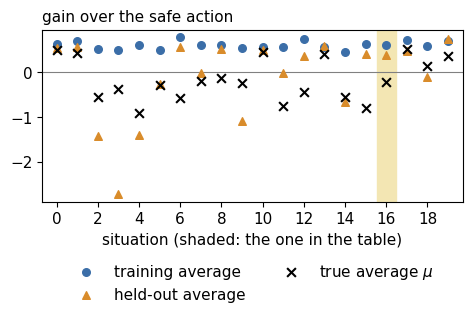

**So:** the critic proposed something in 20 of the 20 situations. Averaged over those proposals, the training average is +0.600, the held-out average −0.109 and the true average −0.164; 13 of the 20 proposals are harmful. Together, their training tries held no disasters at all. The held-out tries are fresh, so their average does not inherit the luck that won the pick.

In [97]:
# Try it: a seed (0 to 199), a shape ("steady", "rare disaster" or "rare jackpot"), a share of good candidates
# (0.1, 0.3 or 0.5), a number of candidates (1, 3, 10 or 30) and a situation (0 to 19); then rerun this cell.
try_seed, try_shape, try_share, try_candidates, try_situation = 100, "rare disaster", 0.1, 30, 16
lesson_3_curse(try_seed, try_shape, try_share, try_candidates, try_situation)

The stored records show how the curse grows with the number of candidates.

In [98]:
def lesson_3_curse_pooled():
    """From the stored records: how often the critic proposes something where every candidate is harmful."""
    if not lesson_3_ready():
        return
    ev = EVAL_SEEDS
    rows, shares = [], []
    for mi, m in enumerate(CANDIDATES):
        none_good = BEST[ev][:, :, :, mi] == 0
        proposed = none_good & EXISTS[ev][:, :, :, mi]
        share = float(proposed.sum() / none_good.sum())
        shares.append(share)
        rows.append([str(m), int(none_good.sum()), lesson_pct(share, 0, latex=False)])
    lesson_table(["Candidates per situation", "Situations where every candidate is harmful",
                  "The critic still proposed one"], rows,
                 note=lesson_text("Seeds 100–199, all shapes and shares of good candidates. **So:** a single harmful "
                                  "candidate looks good in training <<a:%0>> of the time; among 30 harmful candidates, "
                                  "one almost always does (<<b:%0>>). The more candidates compete, the more the winner "
                                  "of the training contest owes to luck.", a=shares[0], b=shares[-1]))


lesson_3_curse_pooled()

| Candidates per situation | Situations where every candidate is harmful | The critic still proposed one |
|---|---|---|
| 1 | 12,723 | 14% |
| 3 | 7,212 | 38% |
| 10 | 2,340 | 79% |
| 30 | 240 | 98% |

Seeds 100–199, all shapes and shares of good candidates. **So:** a single harmful candidate looks good in training 14% of the time; among 30 harmful candidates, one almost always does (98%). The more candidates compete, the more the winner of the training contest owes to luck.

### Step 3.10 · One proposal through every gate

Now every gate reads the proposal's held-out tries. By default it is the proposal from Step 3.9. The cell works the gates in five groups: (1) rules with no promise, (2) the classical 95% lower bounds, (3) BCA's mean gate, (4) the tail gates, (5) the shared budget. A table at the end lists all 14 decisions and checks each against the run's `DEC`.

In [99]:
def lesson_3_join(items):
    """Join names as 'a', 'a and b' or 'a, b and c'."""
    items = list(items)
    return items[0] if len(items) == 1 else ", ".join(items[:-1]) + " and " + items[-1]


def lesson_3_gates(seed, shape, share, m, s):
    """Every gate's arithmetic on one proposal's held-out tries, checked against the run's decisions in DEC."""
    if not (lesson_3_ready() and lesson_3_valid(seed, shape, share, m, s)):
        return
    si, gi, mi = SHAPES.index(shape), GOOD_SHARES.index(share), CANDIDATES.index(m)
    key = (seed, si, gi, mi, s)
    w = lesson_3_world(seed, shape, share)
    j = int(w["tr_mean"][s, :m].argmax())
    if not w["tr_mean"][s, j] > 0:
        lesson_check(not any(bool(DEC[gate][key]) for gate in GATES), "no proposal, so no gate accepts")
        lesson_show(lesson_text("Here the critic proposes nothing: the best training average, <<t:+3>>, is not above "
                                "0. Every gate stays safe, as the run decided. Try another situation.",
                                t=float(w["tr_mean"][s, j])))
        return
    n = int(w["n"][s, j])
    g = w["held"][s, j, :n]
    gbar, var = float(w["ho_mean"][s, j]), float(w["ho_var"][s, j])
    sd, total, b = math.sqrt(var), float(g.sum()), int((g < 0).sum())
    mu = float(w["cand"]["mean"][s, j])
    lo, hi = FLOOR[shape], CEILING[shape]
    width = hi - lo
    lesson_check(n == NTRY[key] and abs(gbar - MEAN[key]) < 1e-12 and abs(var - VAR[key]) < 1e-12
                 and b == BELOW[key] and abs(mu - MU[key]) < 1e-12, "the proposal's record")
    says = {"always safe": False, "no gate": True, "oracle gate": mu > 0}

    def yes_no(ok):
        return r" \;\Rightarrow\; \text{yes}" if ok else r" \;\Rightarrow\; \text{no}"

    def against_zero(x):     # the comparison with 0 that a gate's yes or no rests on
        return "> 0" if x > 0 else r"\le 0"

    # The proposal and its held-out tries.
    hits_note = ""
    if shape != "steady":
        big = -BIG if shape == "rare disaster" else BIG
        word = "disaster" if shape == "rare disaster" else "jackpot"
        hits = int((g == big).sum())
        hits_note = (f" None of them is a {word}" if hits == 0 else
                     f" {hits} of them {'is a ' + word if hits == 1 else 'are ' + word + 's'}")
        dips = b - hits if shape == "rare disaster" else 0       # usual gains below 0 (every disaster is below 0)
        if dips:
            if hits == 0:
                hits_note += ("; the one below 0 is a usual gain that dipped" if dips == 1 else
                              f"; the {dips} below 0 are usual gains that dipped")
            else:
                hits_note += (", and 1 usual gain also dipped" if dips == 1 else
                              f", and {dips} usual gains also dipped")
            hits_note += lesson_text(" under 0 (usual gains vary by about <<v:1>> around their center)",
                                     v=float(w["cand"]["spread"]))
        hits_note += "."
    lesson_show(lesson_text("**The proposal: candidate <<j>>.** Its true average is <<mu:+3>>, so it is <<k>>. The "
                            "gates see only its <<n>> held-out tries.", j=j, mu=mu, k="good" if mu > 0 else "harmful",
                            n=n) + hits_note)
    lesson_math(lesson_tex(r"\bar g &= \frac{1}{n}\sum_{i=1}^{n} g_i = \frac{<<t>>}{<<n>>} = <<a>>",
                           t=total, n=n, a=gbar),
                lesson_tex(r"\mathrm{sd} &= \sqrt{\frac{1}{n-1}\sum_{i=1}^{n} (g_i - \bar g)^2} = <<s>>", s=sd),
                lesson_tex(r"b &= <<b>> \text{ of the } <<n>> \text{ tries below } 0", b=b, n=n))

    # 1. Rules with no promise.
    says["plain average"] = gbar > 0
    cautious = (gbar * n + lo) / (n + 1)
    says["BCA average"] = cautious > 0
    says["count rule"] = n >= COUNT_NEED
    lesson_show("**1. Rules with no promise.**")
    lesson_math(
        lesson_tex(r"\text{plain average} &= \bar g = <<a>> ", a=gbar) + against_zero(gbar)
        + yes_no(says["plain average"]),
        r"\text{cautious average} &= \frac{\sum_i g_i + g_{\min}}{n+1}",
        lesson_tex(r"&= \frac{<<t>> + (<<f:0>>)}{<<k>>} = <<c>>", t=total, f=lo, k=n + 1, c=cautious),
        "&" + against_zero(cautious) + yes_no(says["BCA average"]),
        lesson_tex(r"\text{count rule: } n &= <<n>> ", n=n) + (r"\ge" if says["count rule"] else "<")
        + lesson_tex(r" <<c>>", c=COUNT_NEED) + yes_no(says["count rule"]))
    # The run shrinks across every candidate in play: the m candidates of each of the seed's 20 situations.
    means, varis, counts = w["ho_mean"][:, :m], w["ho_var"][:, :m], w["n"][:, :m]
    shr = float(shrink(means, varis, counts)[s, j])
    lesson_check(abs(shr - SHRUNK[key]) < 1e-12, "the shrunk average")
    says["shrunk average"] = shr > 0
    pooled = float(((counts - 1) * varis).sum() / (counts - 1).sum())
    center = float(means.mean())
    noise = pooled / counts
    between = float(((means - center) ** 2).mean())
    tau2 = max(0.0, between - float(noise.mean()))
    k = tau2 / (tau2 + float(noise[s, j]))
    lesson_check(abs(center + k * (gbar - center) - shr) < 1e-12, "the shrunk average, by hand")
    lesson_show(lesson_text(
        "**Shrunk average.** It pulls $\\bar g$ toward $\\bar g_{\\mathrm{all}}$, the average held-out average of all "
        "<<c>> candidates in this seed's <<t>> situations (<<m>> per situation). $v$ is the average of their squared "
        "spreads $\\mathrm{sd}^2$ (Step 3.5), each weighted by its $n - 1$, so $v/n$ measures the noise in $\\bar g$. "
        "$\\tau^2$ estimates how much the true averages differ: the spread of the <<c>> held-out averages (their "
        "average squared distance from $\\bar g_{\\mathrm{all}}$) minus their average noise. The noisier $\\bar g$ is "
        "next to $\\tau^2$, the harder the pull.", c=SITUATIONS * m, t=SITUATIONS, m=m))
    # Enough decimals that the subtraction and the last line can be redone by hand from the numbers shown.
    for ds in range(3, 9):
        c_r, d_r, k_r = round(center, ds), round(gbar - center, ds), round(k, max(4, ds))
        if (abs(round(gbar, ds) - c_r - d_r) < 0.5 * 10 ** -ds
                and abs(c_r + k_r * d_r - round(shr, ds)) < 0.5 * 10 ** -ds):
            break
    dk = max(4, ds)
    dtau = lesson_3_places(tau2, between, -float(noise.mean()), least=4) if tau2 > 0 else 4

    def paren_d(x):          # a number inside a difference, with ds decimals: negative numbers in parentheses
        return "(" + lesson_num(x, ds) + ")" if x < 0 else lesson_num(x, ds)

    lesson_math(
        lesson_tex(r"\bar g_{\mathrm{all}} &= <<c>>", c=lesson_num(center, ds)),
        lesson_tex(r"\bar g - \bar g_{\mathrm{all}} &= <<a>> - <<p>> = <<d>>", a=lesson_num(gbar, ds),
                   p=paren_d(center), d=lesson_num(gbar - center, ds)),
        lesson_tex(r"v &= <<v:4>>", v=pooled),
        lesson_tex(r"\frac{v}{n} &= \frac{<<v:4>>}{<<n>>} = <<q:4>>", v=pooled, n=n, q=float(noise[s, j])),
        lesson_tex(r"\tau^2 &= \max(0,\ <<a>> - <<b>>)", a=lesson_num(between, dtau),
                   b=lesson_num(float(noise.mean()), dtau)),
        lesson_tex(r"&= <<t>>", t=lesson_num(tau2, dtau)),
        lesson_tex(r"\frac{\tau^2}{\tau^2 + v/n} &= \frac{<<t>>}{<<t>> + <<q:4>>} = <<k>>",
                   t=lesson_num(tau2, dtau), q=float(noise[s, j]), k=lesson_num(k, dk)),
        lesson_tex(r"\text{shrunk} &= \bar g_{\mathrm{all}} + <<k>>\,(\bar g - \bar g_{\mathrm{all}})",
                   k=lesson_num(k, dk)),
        lesson_tex(r"&= <<c>> + <<k>> \times <<d>>", c=lesson_num(center, ds), k=lesson_num(k, dk),
                   d=paren_d(gbar - center)),
        lesson_tex(r"&= <<r>> ", r=lesson_num(shr, ds)) + against_zero(shr) + yes_no(says["shrunk average"]))

    # 2. 95% lower bounds on the average.
    tq = t_upper(DELTA, n - 1)
    lesson_check(abs(lesson_3_t95(n - 1) - tq) < 1e-6, "Student's t value, against Step 3.6's")
    t_margin = tq * math.sqrt(var / n)
    says["t-test"] = gbar - t_margin > 0
    h_margin = width * math.sqrt(math.log(1 / DELTA) / (2 * n))
    says["Hoeffding"] = gbar - h_margin > 0
    b1 = math.sqrt(2 * var * math.log(2 / DELTA) / n)
    b2 = 7 * width * math.log(2 / DELTA) / (3 * (n - 1))
    says["empirical Bernstein"] = gbar - b1 - b2 > 0
    # Enough decimals that each subtraction below can be redone by hand from the numbers shown.
    dt = lesson_3_places(gbar - t_margin, gbar, -t_margin)
    dh = lesson_3_places(gbar - h_margin, gbar, -h_margin)
    de = lesson_3_places(gbar - b1 - b2, gbar, -b1, -b2)
    lesson_show("\n\n".join([
        lesson_text("**2. Gates that promise 5%: 95% lower bounds on the average** (Step 3.5). In this shape gains "
                    "range from <<lo:0>> to <<hi:0>>, so $g_{\\max} - g_{\\min} = <<w:0>>$.", lo=lo, hi=hi, w=width),
        lesson_3_block(
            lesson_tex(r"\text{t-test} &= \bar g - t_{0.95}(<<d>>)\,\frac{\mathrm{sd}}{\sqrt{n}}", d=n - 1),
            lesson_tex(r"&= <<a>> - <<t>> \times \frac{<<s>>}{\sqrt{<<n>>}}", a=lesson_num(gbar, dt), t=tq, s=sd, n=n),
            lesson_tex(r"&= <<a>> - <<x>> = <<y>>", a=lesson_num(gbar, dt), x=lesson_num(t_margin, dt),
                       y=lesson_num(gbar - t_margin, dt)),
            "&" + against_zero(gbar - t_margin) + yes_no(says["t-test"]),
            lesson_tex(r"\text{Hoeffding} &= \bar g - <<w:0>>\sqrt{\frac{\ln 20}{2 \times <<n>>}}", w=width, n=n),
            lesson_tex(r"&= <<a>> - <<x>> = <<y>>", a=lesson_num(gbar, dh), x=lesson_num(h_margin, dh),
                       y=lesson_num(gbar - h_margin, dh)),
            "&" + against_zero(gbar - h_margin) + yes_no(says["Hoeffding"])),
        lesson_text("**Empirical Bernstein**, with $\\mathrm{sd}^2 = <<v:4>>$:", v=var),
        lesson_3_block(
            lesson_tex(r"& \bar g - \sqrt{\frac{2 \times <<v:4>> \times \ln 40}{<<n>>}} - \frac{7 \times <<w:0>> "
                       r"\times \ln 40}{3 \times <<m>>}", v=var, n=n, w=width, m=n - 1),
            lesson_tex(r"&= <<a>> - <<x>> - <<y>>", a=lesson_num(gbar, de), x=lesson_num(b1, de),
                       y=lesson_num(b2, de)),
            lesson_tex(r"&= <<z>> ", z=lesson_num(gbar - b1 - b2, de)) + against_zero(gbar - b1 - b2)
            + yes_no(says["empirical Bernstein"]))]))

    # 3. BCA's mean gate: the run's 10,000 random draws (draw m is row m - 1; the floor's weight is the last column).
    E = w["weights"]
    sums = (E[:, :N_MAX] @ w["held"][s, j][:, None])[:, 0] + E[:, N_MAX] * lo
    neg = int((sums < 0).sum())
    lesson_check(neg == NEG[key], "the mean gate's count of weighted averages below 0")
    allowed = limit(DELTA)
    says["BCA mean gate"] = neg <= allowed
    e1, x1 = E[0, :n], float(E[0, N_MAX])
    rows = [[str(i + 1), lesson_txt(float(g[i]), 3), lesson_txt(float(e1[i]), 3), lesson_txt(float(e1[i] * g[i]), 3)]
            for i in range(min(n, 12))]
    if n > 12:
        rows.append(["…", "", "", ""])
    num1, den1 = float(e1 @ g) + x1 * lo, float(e1.sum()) + x1
    rows.append(["$n+1$ (floor)", lesson_txt(lo, 0), lesson_txt(x1, 3), lesson_txt(x1 * lo, 3)])
    rows.append(["sum", "", lesson_txt(den1, 3), lesson_txt(num1, 3)])
    lesson_show(lesson_text("**3. BCA's mean gate** (Step A.8). Each of <<d>> random draws gives every try a weight "
                            "$E_i$ and the floor an extra weight $E_{n+1}$. Draw 1:", d=DRAWS))
    lesson_table(["$i$", "Gain $g_i$", "Weight $E_i$", "$E_i\\, g_i$"], rows)
    lesson_math(
        r"\bar g^{(1)} &= \frac{\sum_{i=1}^{n} E_i g_i + E_{n+1}\, g_{\min}}{\sum_{i=1}^{n+1} E_i}",
        lesson_tex(r"&= \frac{<<a>>}{<<b>>} = <<r>>", a=num1, b=den1, r=num1 / den1)
        + (r" < 0" if num1 < 0 else r" \ge 0"),
        lesson_tex(r"\text{below } 0 &= <<k>> \text{ of } <<d>> \text{ draws}", k=neg, d=DRAWS),
        "&" + (r"\le " if says["BCA mean gate"] else "> ") + lesson_num(allowed) + yes_no(says["BCA mean gate"]),
        note=lesson_text("The table's two sums are the fraction's top and bottom. Since every weight is positive, a "
                         "weighted average is below 0 exactly when its top is. The gate allows at most <<l>> of the "
                         "<<d>> weighted averages below 0 (5%).", l=allowed, d=DRAWS))

    # 4. Tail gates.
    x = allowed_below(n, TAIL)
    says["BCA tail gate"] = b <= x

    def cdf(k):
        return sum(math.comb(n, i) * TAIL ** i * (1 - TAIL) ** (n - i) for i in range(k + 1))

    lesson_check(cdf(x + 1) > 1 - CONFIDENCE and (x < 0 or cdf(x) <= 1 - CONFIDENCE), "x(n), by hand")
    if x < 0:
        tail = [lesson_tex(r"& P(\mathrm{Binomial}(<<n>>, 0.1) \le 0)", n=n),
                lesson_tex(r"&\quad = 0.9^{<<n>>} = <<p:3>> > 0.05", n=n, p=cdf(0)),
                lesson_tex(r"& \text{so } x(<<n>>) = -1 \text{ (none may)}", n=n)]
    else:
        tail = [lesson_tex(r"& P(\mathrm{Binomial}(<<n>>, 0.1) \le <<x>>) = <<p:4>> \le 0.05", n=n, x=x, p=cdf(x)),
                lesson_tex(r"& P(\mathrm{Binomial}(<<n>>, 0.1) \le <<y>>) = <<q:4>> > 0.05", n=n, y=x + 1,
                           q=cdf(x + 1)),
                lesson_tex(r"& \text{so } x(<<n>>) = <<x>>", n=n, x=x)]
    tail.append(lesson_tex(r"& b = <<b>> ", b=b) + (r"\le" if says["BCA tail gate"] else ">")
                + lesson_tex(r" x(<<n>>) = <<x>>", n=n, x=x) + yes_no(says["BCA tail gate"]))
    r = math.floor(Fraction(str(TAIL)) * (n + 1))
    says["split-conformal tail"] = r >= 1 and b < r
    lesson_show("\n\n".join([
        "**4. Tail gates:** Part 2's kind of promise, that at least 90% of outcomes beat 0.",
        "**BCA tail gate:**",
        lesson_3_block(*tail),
        "**Split-conformal tail:**",
        lesson_3_block(lesson_tex(r"& r = \lfloor 0.1 \times (n+1) \rfloor = \lfloor 0.1 \times <<k>> \rfloor = <<r>>",
                                  k=n + 1, r=r),
                       r"& \text{yes needs } r \ge 1 \text{ and } b < r",
                       lesson_tex(r"& b = <<b>>,\ r = <<r>>", b=b, r=r) + yes_no(says["split-conformal tail"]))]))

    # 5. Shared budget: Benjamini-Hochberg across this seed's 20 situations, as the run's bh() does it.
    rec = key[:4]
    p_row = np.where(EXISTS[rec], (NEG[rec] + 1) / (DRAWS + 1), np.inf)
    mprop = int(np.isfinite(p_row).sum())
    order = np.argsort(p_row)
    passed = p_row[order] <= BUDGET * np.arange(1, SITUATIONS + 1) / mprop
    K = int(np.nonzero(passed)[0].max()) + 1 if passed.any() else 0
    rank = int(np.nonzero(order == s)[0][0]) + 1
    says["BCA mean gate, shared budget"] = rank <= K
    p_this = (neg + 1) / (DRAWS + 1)
    lesson_check(abs(p_this - p_row[s]) < 1e-15, "the p-value")
    want = set(range(1, min(mprop, max(rank, K + 1, 3)) + 1))
    if len(want) > 8:
        want = set(range(1, 6)) | {k for k in (K, K + 1, rank) if 1 <= k <= mprop}
    rows, prev = [], 0
    for k in sorted(want):
        if k > prev + 1:
            rows.append(["…", "", "", "", ""])
        idx = int(order[k - 1])
        bar = BUDGET * k / mprop
        rows.append([str(k), f"{idx}" + (" (this one)" if idx == s else ""), lesson_txt(float(p_row[idx]), 4),
                     lesson_txt(bar, 4), "yes" if p_row[idx] <= bar else "no"])
        prev = k
    lesson_show(lesson_text(
        "**5. Shared budget** (Benjamini–Hochberg). A proposal's *p-value* is the share of its weighted averages "
        "below 0, counted as (count + 1) / <<d>> so that it is never 0; a small p-value means the proposal looks "
        "clearly good. This seed and world have $M = <<m>>$ <<p>>, sorted by p-value. The $K$ smallest pass, where "
        "$K$ is the largest rank $k$ whose p-value is at or below its bar, $0.10\\,k/M$.",
        d=DRAWS + 1, m=mprop, p="proposal" if mprop == 1 else "proposals"))
    lesson_table(["Rank $k$", "Situation", "p-value", "Bar $0.10\\,k/M$", "≤ bar?"], rows)
    lesson_math(lesson_tex(r"p &= \frac{<<c>> + 1}{<<d>>} = <<p:4>>", c=neg, d=DRAWS + 1, p=p_this),
                lesson_tex(r"K &= <<K>>", K=K) + (r" \text{ (none pass)}" if K == 0 else ""),
                lesson_tex(r"\text{rank} &= <<r>> ", r=rank) + (r"\le" if says["BCA mean gate, shared budget"] else ">")
                + r" K" + yes_no(says["BCA mean gate, shared budget"]))

    # 6. Every decision, checked against the run.
    for gate in GATES:
        lesson_check(bool(says[gate]) == bool(DEC[gate][key]), "the decision of " + gate)
    checked = {"always safe": "never says yes", "no gate": "always says yes",
               "count rule": lesson_text("n = <<n>>", n=n),
               "plain average": lesson_text("average <<a:+3>>", a=gbar),
               "shrunk average": lesson_text("shrunk average <<a:+3>>", a=shr),
               "BCA average": lesson_text("cautious average <<a:+3>>", a=cautious),
               "t-test": lesson_text("bound <<a:+3>>", a=gbar - t_margin),
               "Hoeffding": lesson_text("bound <<a:+3>>", a=gbar - h_margin),
               "empirical Bernstein": lesson_text("bound <<a:+3>>", a=gbar - b1 - b2),
               "BCA mean gate": lesson_text("<<k>> of <<d>> draws below 0", k=neg, d=DRAWS),
               "BCA tail gate": lesson_text("b = <<b>>, x(n) = <<x>>", b=b, x=x),
               "split-conformal tail": lesson_text("b = <<b>>, r = <<r>>", b=b, r=r),
               "BCA mean gate, shared budget": lesson_text("rank <<r>>; <<K>> pass", r=rank, K=K),
               "oracle gate": lesson_text("true average <<a:+3>>", a=mu)}
    lesson_show("**All the gates, as printed in the results.**")
    lesson_table(["Gate", "What it checked", "Says"],
                 [[gate, checked[gate], "yes" if says[gate] else "no"] for gate in GATES])
    yes_real = [gate for gate in GATES if says[gate] and gate not in ("no gate", "oracle gate")]
    names = [{"BCA average": "BCA's cautious average", "BCA mean gate, shared budget": "the shared-budget mean gate"}
             .get(gate, gate) for gate in yes_real]
    lesson_show(lesson_text("**So:** this proposal is <<v>> (true average <<mu:+3>>). Gates that said yes: <<y>>. "
                            "BCA's mean gate said <<z>>: <<k>> of its <<d>> weighted averages <<are>> below 0, and it "
                            "allows at most <<l>>. All <<g>> decisions match the run's `DEC`.",
                            v="good" if mu > 0 else "harmful", mu=mu,
                            y=lesson_3_join(names) if names else "none apart from the critic alone",
                            z="yes" if says["BCA mean gate"] else "no", k=neg, d=DRAWS,
                            are="is" if neg == 1 else "are", l=allowed, g=len(GATES)))

In [100]:
# Try it: the same five inputs as in Step 3.9; then rerun this cell. For a good proposal that BCA's mean gate
# accepts, try 100, "steady", 0.1, 30, 14.
try_seed, try_shape, try_share, try_candidates, try_situation = 100, "rare disaster", 0.1, 30, 16
lesson_3_gates(try_seed, try_shape, try_share, try_candidates, try_situation)

**The proposal: candidate 23.** Its true average is −0.219, so it is harmful. The gates see only its 10 held-out tries. None of them is a disaster; the 2 below 0 are usual gains that dipped under 0 (usual gains vary by about 0.3 around their center).

$$
\begin{aligned}
\bar g &= \frac{1}{n}\sum_{i=1}^{n} g_i = \frac{3.698}{10} = 0.370 \\ \mathrm{sd} &= \sqrt{\frac{1}{n-1}\sum_{i=1}^{n} (g_i - \bar g)^2} = 0.310 \\ b &= 2 \text{ of the } 10 \text{ tries below } 0
\end{aligned}
$$

**1. Rules with no promise.**

$$
\begin{aligned}
\text{plain average} &= \bar g = 0.370 > 0 \;\Rightarrow\; \text{yes} \\ \text{cautious average} &= \frac{\sum_i g_i + g_{\min}}{n+1} \\ &= \frac{3.698 + (-8)}{11} = -0.391 \\ &\le 0 \;\Rightarrow\; \text{no} \\ \text{count rule: } n &= 10 < 30 \;\Rightarrow\; \text{no}
\end{aligned}
$$

**Shrunk average.** It pulls $\bar g$ toward $\bar g_{\mathrm{all}}$, the average held-out average of all 600 candidates in this seed's 20 situations (30 per situation). $v$ is the average of their squared spreads $\mathrm{sd}^2$ (Step 3.5), each weighted by its $n - 1$, so $v/n$ measures the noise in $\bar g$. $\tau^2$ estimates how much the true averages differ: the spread of the 600 held-out averages (their average squared distance from $\bar g_{\mathrm{all}}$) minus their average noise. The noisier $\bar g$ is next to $\tau^2$, the harder the pull.

...

| Rank $k$ | Situation | p-value | Bar $0.10\,k/M$ | ≤ bar? |
|---|---|---|---|---|
| 1 | 10 | 0.1362 | 0.0050 | no |
| 2 | 1 | 0.2770 | 0.0100 | no |
| 3 | 13 | 0.5259 | 0.0150 | no |
| 4 | 0 | 0.5277 | 0.0200 | no |
| 5 | 19 | 0.5829 | 0.0250 | no |
| 6 | 16 (this one) | 0.6314 | 0.0300 | no |

$$
\begin{aligned}
p &= \frac{6{,}314 + 1}{10{,}001} = 0.6314 \\ K &= 0 \text{ (none pass)} \\ \text{rank} &= 6 > K \;\Rightarrow\; \text{no}
\end{aligned}
$$

**All the gates, as printed in the results.**

| Gate | What it checked | Says |
|---|---|---|
| always safe | never says yes | no |
| no gate | always says yes | yes |
| count rule | n = 10 | no |
| plain average | average +0.370 | yes |
| shrunk average | shrunk average −0.384 | no |
| BCA average | cautious average −0.391 | no |
| t-test | bound +0.190 | yes |
| Hoeffding | bound −3.887 | no |
| empirical Bernstein | bound −10.417 | no |
| BCA mean gate | 6,314 of 10,000 draws below 0 | no |
| BCA tail gate | b = 2, x(n) = −1 | no |
| split-conformal tail | b = 2, r = 1 | no |
| BCA mean gate, shared budget | rank 6; 0 pass | no |
| oracle gate | true average −0.219 | no |

**So:** this proposal is harmful (true average −0.219). Gates that said yes: plain average and t-test. BCA's mean gate said no: 6,314 of its 10,000 weighted averages are below 0, and it allows at most 500. All 14 decisions match the run's `DEC`.

### Step 3.11 · Results

**How to read it.** One row per gate at its stated setting, on seeds 100–199.
- **gain:** the true average gain per situation, pooled over the 36 worlds. Higher is better; always staying safe scores 0.
- **of oracle:** that gain as a share of the oracle gate's, the best any gate can do with the critic's proposals.
- **good accepted:** the share of all good proposals the gate accepted.
- **worst harm:** the highest harm rate over the 36 worlds. A gate that promises 5% should stay near or below 5% here.
- **worst disaster harm:** the same, over the rare-disaster worlds only.

In [101]:
print(f"{'gate':31}{'gain':>8}{'of oracle':>11}{'good accepted':>15}{'worst harm':>12}{'worst disaster harm':>21}")
for g in GATES:
    gain, harm = gain_by_world(DEC[g], EVAL_SEEDS), harm_by_world(DEC[g], EVAL_SEEDS)
    print(f"{g:31}{gain.mean():8.3f}{gain.mean() / ORACLE_GAIN:11.0%}{good_accepted(DEC[g], EVAL_SEEDS):15.0%}"
          f"{harm.max():12.1%}{harm[1].max():21.1%}")
print(f"\nFor reference, picking the truly best candidate in every situation would gain {BEST[EVAL_SEEDS].mean():.3f}:")
print("the critic's proposals already lose part of that before any gate acts.")

gate                               gain  of oracle  good accepted  worst harm  worst disaster harm
always safe                       0.000         0%             0%        0.0%                 0.0%
no gate                           0.138        66%           100%      100.0%               100.0%
count rule                        0.065        31%            32%       43.2%                12.4%
plain average                     0.158        76%            83%       41.4%                36.2%
shrunk average                    0.151        73%            69%       90.0%                16.4%
BCA average                       0.136        65%            60%       11.8%                 1.7%
t-test                            0.080        39%            44%       31.3%                31.3%
Hoeffding                         0.000         0%             0%        0.0%                 0.0%
empirical Bernstein               0.000         0%             0%        0.0%                 0.0%
BCA mean g

**What to notice.**
- **Of the real gates, the plain average earned the most:** 0.158 per situation, 76% of the oracle's 0.208. It has no promise: in one world it accepted 41.4% of the harmful proposals.
- **BCA's mean gate kept its harm rate at or below 0.3% in every world.** At its stated 5% level it is cautious here: it earned 0.045, less than a third of the plain average's 0.158.
- **The t-test accepted up to 31.3% of harmful proposals**, in a rare-disaster world. Hoeffding and empirical Bernstein accepted almost nothing (0% of good proposals) and earned 0.000.
- **The critic's choice already costs return:** picking the truly best candidate in every situation would gain 0.294, while the oracle gate, which can only accept or refuse the critic's proposals, gains 0.208.

**How to read the chart.** Each gate is one point: its worst-world harm rate (left to right; the scale is linear below 1% and logarithmic above) and its gain (up). Up and to the left is better; the dashed line is the 5% promise.

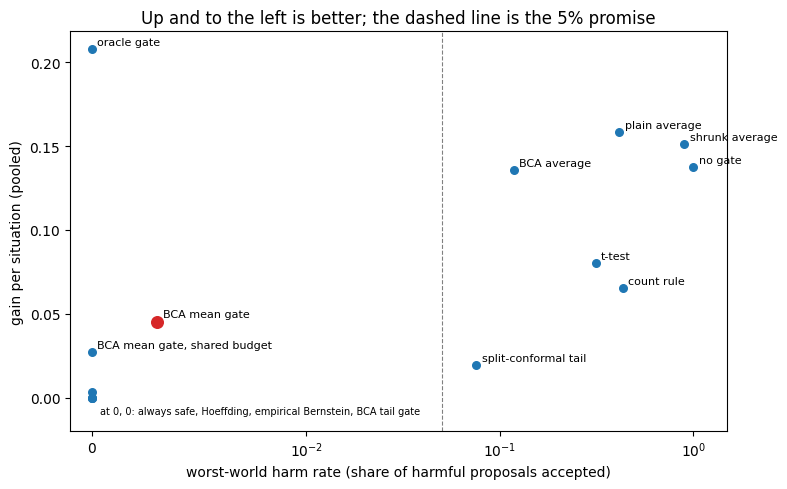

In [102]:
fig, ax = plt.subplots(figsize=(8, 5))
near_zero = []
for g in GATES:
    harm = harm_by_world(DEC[g], EVAL_SEEDS).max()
    gain = gain_by_world(DEC[g], EVAL_SEEDS).mean()
    star = g == "BCA mean gate"
    ax.scatter(harm, gain, s=70 if star else 30, color="C3" if star else "C0", zorder=3)
    if harm < 0.002 and gain < 0.01:
        near_zero.append(g)
    else:
        ax.annotate(g, (harm, gain), fontsize=8, xytext=(4, 3), textcoords="offset points")
ax.annotate("at 0, 0: " + ", ".join(near_zero), (0, 0), fontsize=7, xytext=(6, -12), textcoords="offset points")
ax.axvline(DELTA, color="grey", ls="--", lw=0.8)
ax.set_xscale("symlog", linthresh=0.01)
ax.set_xlim(-0.001, 1.5); ax.set_ylim(bottom=-0.02)
ax.set_xlabel("worst-world harm rate (share of harmful proposals accepted)")
ax.set_ylabel("gain per situation (pooled)")
ax.set_title("Up and to the left is better; the dashed line is the 5% promise")
fig.tight_layout(); plt.show()

**What to notice.** Left of the dashed line, apart from the oracle, BCA's mean gate (the large red point) earns the most. Every gate that earns more sits right of the line: in some world it accepted more than 5% of the harmful proposals.

### Step 3.12 · Verdicts

Claims 1 and 3 compare a harm rate with each world's allowance (Step 3.7). The allowance depends on how many harmful proposals a world has: the fewer there are, the noisier its harm rate, and the more slack the allowance gives. The next cell works it out.

In [103]:
def lesson_3_allowance():
    """Each world's allowance on a 5% harm rate, worked where harmful proposals are most and least plentiful."""
    if not lesson_3_ready():
        return
    h = HARMFUL[EVAL_SEEDS].sum(axis=(0, 4))
    allow = allowance(EVAL_SEEDS)

    def name(idx):
        return f"{SHAPES[idx[0]]}, {GOOD_SHARES[idx[1]]:.0%} good, {CANDIDATES[idx[2]]} candidates"

    def worst(rates):
        return tuple(int(i) for i in np.unravel_index(int(rates.argmax()), rates.shape))

    most, fewest = worst(h), worst(-h)
    rows = []
    for idx in (most, fewest):
        a = DELTA + 3 * math.sqrt(DELTA * (1 - DELTA) / h[idx])
        lesson_check(abs(a - allow[idx]) < 1e-12, "the allowance")
        rows.append([name(idx), int(h[idx]), lesson_txt(a, 3)])
    lesson_math(r"\text{allowance} &= 0.05 + 3\sqrt{\frac{0.05 \times 0.95}{n_{\mathrm{harm}}}}",
                lesson_tex(r"&= 0.05 + 3\sqrt{\frac{0.0475}{<<h>>}}", h=int(h[most])),
                lesson_tex(r"&= 0.05 + 3 \times <<e:4>> = <<a:3>>", e=math.sqrt(0.0475 / h[most]), a=allow[most]),
                note=lesson_text("Here $n_{\\mathrm{harm}}$ is a world's number of harmful proposals on seeds 100–199; "
                                 "the lines above work the world with the most, <<h>>. The two extremes:",
                                 h=int(h[most])))
    lesson_table(["World", "Harmful proposals $n_{\\mathrm{harm}}$", "Allowance"], rows)
    h1 = harm_by_world(DEC["BCA mean gate"], EVAL_SEEDS)
    w1 = worst(h1)
    ht = harm_by_world(DEC["t-test"], EVAL_SEEDS)
    rd = SHAPES.index("rare disaster")
    wt = (rd,) + worst(ht[rd])
    lesson_show(lesson_text("**So:** BCA's mean gate's worst world is <<a>>, where it accepted <<b:3>> of the harmful "
                            "proposals against an allowance of <<c:3>> (claim 1). The t-test's worst rare-disaster "
                            "world is <<d>>: <<e:3>> against <<f:3>> (claim 3).",
                            a=name(w1), b=float(h1[w1]), c=float(allow[w1]), d=name(wt), e=float(ht[wt]),
                            f=float(allow[wt])))


lesson_3_allowance()

$$
\begin{aligned}
\text{allowance} &= 0.05 + 3\sqrt{\frac{0.05 \times 0.95}{n_{\mathrm{harm}}}} \\ &= 0.05 + 3\sqrt{\frac{0.0475}{1{,}321}} \\ &= 0.05 + 3 \times 0.0060 = 0.068
\end{aligned}
$$

Here $n_{\mathrm{harm}}$ is a world's number of harmful proposals on seeds 100–199; the lines above work the world with the most, 1,321. The two extremes:

| World | Harmful proposals $n_{\mathrm{harm}}$ | Allowance |
|---|---|---|
| rare disaster, 10% good, 30 candidates | 1,321 | 0.068 |
| steady, 50% good, 30 candidates | 67 | 0.130 |

**So:** BCA's mean gate's worst world is rare jackpot, 30% good, 3 candidates, where it accepted 0.003 of the harmful proposals against an allowance of 0.086 (claim 1). The t-test's worst rare-disaster world is rare disaster, 10% good, 30 candidates: 0.313 against 0.068 (claim 3).

**How to read it.** The next cell applies each kill rule. Each line names the claim, gives the numbers its rule compares, and ends in ALIVE or SHELVED. Claim 5 uses the tuning that Step 3.13 explains.

In [104]:
ev = EVAL_SEEDS
allow = allowance(ev)
verdict = lambda alive: "ALIVE" if alive else "SHELVED"

h1 = harm_by_world(DEC["BCA mean gate"], ev)
print(f"Claim 1, BCA's mean gate keeps its promise: worst harm rate {h1.max():.3f}; "
      f"worlds above their allowance: {(h1 > allow).sum()} -> {verdict(not (h1 > allow).any())}")

ga = {g: good_accepted(DEC[g], ev) for g in ("BCA mean gate", "Hoeffding", "empirical Bernstein")}
c2 = ga["BCA mean gate"] - max(ga["Hoeffding"], ga["empirical Bernstein"]) >= 0.05
print(f"Claim 2, tightest guaranteed mean gate: good proposals accepted {ga['BCA mean gate']:.1%} against "
      f"Hoeffding {ga['Hoeffding']:.1%} and empirical Bernstein {ga['empirical Bernstein']:.1%} -> {verdict(c2)}")

ht = harm_by_world(DEC["t-test"], ev)
c3 = bool((ht[1] > allow[1]).any())
print(f"Claim 3, the t-test is unsafe with rare disasters: worst rare-disaster harm rate {ht[1].max():.3f} "
      f"-> {verdict(c3)}")

crowded = np.zeros((len(SHAPES), len(GOOD_SHARES), len(CANDIDATES)), bool)
crowded[:, :2, 2:] = True
gc = {g: gain_by_world(DEC[g], ev)[crowded].mean() for g in ("BCA mean gate", "plain average", "shrunk average")}
c4 = gc["BCA mean gate"] > max(gc["plain average"], gc["shrunk average"])
print(f"Claim 4, crowded worlds: gain {gc['BCA mean gate']:.4f} against plain average {gc['plain average']:.4f} "
      f"and shrunk average {gc['shrunk average']:.4f} -> {verdict(c4)}")

TUNABLE = {"plain average": MARGINS, "shrunk average": MARGINS, "BCA average": MARGINS, "t-test": LEVELS,
           "Hoeffding": LEVELS, "empirical Bernstein": LEVELS, "BCA mean gate": LEVELS,
           "BCA tail gate": TAIL_SHARES, "split-conformal tail": TAIL_SHARES, "count rule": COUNTS}
FRONTIER, TUNED = {}, {}
for g, grid in TUNABLE.items():
    points = []
    for k in grid:
        d = accept(g, k)
        points.append((k, harm_by_world(d, TUNE_SEEDS).max(), gain_by_world(d, TUNE_SEEDS).mean(), d))
    FRONTIER[g] = points
    qualified = [p for p in points if p[1] <= DELTA]
    if qualified:
        k, _, tune_gain, d = max(qualified, key=lambda p: p[2])
        TUNED[g] = (k, tune_gain, gain_by_world(d, ev).mean(), harm_by_world(d, ev).max())
    else:
        TUNED[g] = (None, 0.0, 0.0, 0.0)
best_rival = max((g for g in TUNED if g != "BCA mean gate"), key=lambda g: TUNED[g][2])
c5 = TUNED["BCA mean gate"][2] > TUNED[best_rival][2]
print(f"Claim 5, at equal harm: tuned BCA mean gate gains {TUNED['BCA mean gate'][2]:.4f}; best tuned rival "
      f"{best_rival} gains {TUNED[best_rival][2]:.4f} -> {verdict(c5)}")

gb = gain_by_world(DEC["BCA mean gate, shared budget"], ev).mean()
gm = gain_by_world(DEC["BCA mean gate"], ev).mean()
fs = false_share_by_world(DEC["BCA mean gate, shared budget"], ev)
c6 = gb > gm and fs.max() <= 0.12
print(f"Claim 6, shared 10% harm budget: gain {gb:.4f} against {gm:.4f} deciding alone; worst average harmful "
      f"share of acceptances {fs.max():.3f} -> {verdict(c6)}")

Claim 1, BCA's mean gate keeps its promise: worst harm rate 0.003; worlds above their allowance: 0 -> ALIVE
Claim 2, tightest guaranteed mean gate: good proposals accepted 17.4% against Hoeffding 0.0% and empirical Bernstein 0.0% -> ALIVE
Claim 3, the t-test is unsafe with rare disasters: worst rare-disaster harm rate 0.313 -> ALIVE
Claim 4, crowded worlds: gain 0.0567 against plain average 0.1829 and shrunk average 0.1625 -> SHELVED
Claim 5, at equal harm: tuned BCA mean gate gains 0.0845; best tuned rival BCA average gains 0.0400 -> ALIVE
Claim 6, shared 10% harm budget: gain 0.0270 against 0.0453 deciding alone; worst average harmful share of acceptances 0.000 -> SHELVED


**What to notice.**
- Claims 1, 2, 3 and 5 are alive; claims 4 and 6 are shelved.
- Claim 2: BCA's mean gate accepted 17.4% of good proposals, Hoeffding and empirical Bernstein 0.0%.
- Claim 4: in the crowded worlds the mean gate earned 0.0567, against 0.1829 for the plain average and 0.1625 for the shrunk average.
- Claim 6: deciding together earned 0.0270, against 0.0453 deciding alone, though harm was no problem (worst harmful share 0.000).

### Step 3.13 · Equal harm: tuned on seeds 0–99, scored on seeds 100–199

At its stated setting each gate makes its own trade between harm and gain, so their gains are not directly comparable. Claim 5 first makes every gate equally safe. Each gate has one knob: a margin for the averages (say yes when the average is above the margin), a confidence level for the bounds, a share for the tail gates, and a count for the count rule.

1. **Tune on seeds 0–99.** Try every setting on the knob's fixed grid. Keep the settings whose harm rate is at most 5% in every world, and choose the one with the highest pooled gain. A gate with no such setting always stays safe.
2. **Score on seeds 100–199.** Report the chosen setting's pooled gain on these fresh seeds. A setting chosen and scored on the same seeds could look good partly by luck; fresh seeds remove that.

Tuning needs to know which proposals are harmful, which only a toy world knows; a real deployment cannot tune this way. The next cell shows the mean gate's knob.

In [105]:
def lesson_3_tuning():
    """BCA's mean gate's knob on seeds 0-99: every level, the chosen one, and its score on seeds 100-199."""
    if not lesson_3_ready():
        return
    rows = []
    for level, harm, gain, _ in FRONTIER["BCA mean gate"]:
        rows.append([f"{level:g}", f"{limit(level):,}", lesson_txt(harm, 4), lesson_txt(gain, 4),
                     "yes" if harm <= DELTA else "no"])
    level, tune_gain, eval_gain, eval_harm = TUNED["BCA mean gate"]
    best = max((p for p in FRONTIER["BCA mean gate"] if p[1] <= DELTA), key=lambda p: p[2])
    lesson_check(best[0] == level and best[2] == tune_gain, "the chosen level")
    lesson_table(["Level", "Draws allowed below 0", "Worst-world harm", "Gain", "Harm at most 0.05?"], rows,
                 note=lesson_text("Seeds 0–99. At level $L$ the gate says yes when at most $L \\times 10{,}000$ of its "
                                  "weighted averages are below 0; its stated level is 0.05. **So:** of the levels with "
                                  "at most 5% harm in every world, <<l>> earned the most (<<a:4>>). On the fresh seeds "
                                  "100–199 it earned <<b:4>>, with a worst-world harm rate of <<h:%1>>.",
                                  l=f"{level:g}", a=tune_gain, b=eval_gain, h=eval_harm))
    plain = TUNED["plain average"]
    t_lowest = min(p[1] for p in FRONTIER["t-test"])
    lesson_show(lesson_text("The other gates follow the same rule. The plain average's best setting with at most 5% "
                            "harm is a margin of <<m>> (say yes when $\\bar g > <<m>>$), which earns <<g:4>> on seeds "
                            "0–99. No t-test level qualifies: its lowest worst-world harm rate is <<t:3>>, so the tuned "
                            "t-test always stays safe.", m=f"{plain[0]:g}", g=plain[1], t=t_lowest))


lesson_3_tuning()

| Level | Draws allowed below 0 | Worst-world harm | Gain | Harm at most 0.05? |
|---|---|---|---|---|
| 0.5 | 5,000 | 0.1300 | 0.1391 | no |
| 0.3 | 3,000 | 0.0588 | 0.1044 | no |
| 0.2 | 2,000 | 0.0273 | 0.0864 | yes |
| 0.1 | 1,000 | 0.0137 | 0.0624 | yes |
| 0.05 | 500 | 0.0137 | 0.0452 | yes |
| 0.02 | 200 | 0.0000 | 0.0309 | yes |
| 0.01 | 100 | 0.0000 | 0.0230 | yes |
| 0.005 | 50 | 0.0000 | 0.0170 | yes |
| 0.002 | 20 | 0.0000 | 0.0113 | yes |
| 0.001 | 10 | 0.0000 | 0.0087 | yes |

Seeds 0–99. At level $L$ the gate says yes when at most $L \times 10{,}000$ of its weighted averages are below 0; its stated level is 0.05. **So:** of the levels with at most 5% harm in every world, 0.2 earned the most (0.0864). On the fresh seeds 100–199 it earned 0.0845, with a worst-world harm rate of 2.3%.

The other gates follow the same rule. The plain average's best setting with at most 5% harm is a margin of 1.5 (say yes when $\bar g > 1.5$), which earns 0.0061 on seeds 0–99. No t-test level qualifies: its lowest worst-world harm rate is 0.145, so the tuned t-test always stays safe.

**How to read it.** The chart shows every setting of every gate on seeds 0–99: its worst-world harm rate (left to right; the dashed line is 5%) and its gain (up). The table lists each gate's chosen setting ("chosen knob"), its gain on the tuning seeds and on the fresh seeds, and its worst harm rate on the fresh seeds, best first.

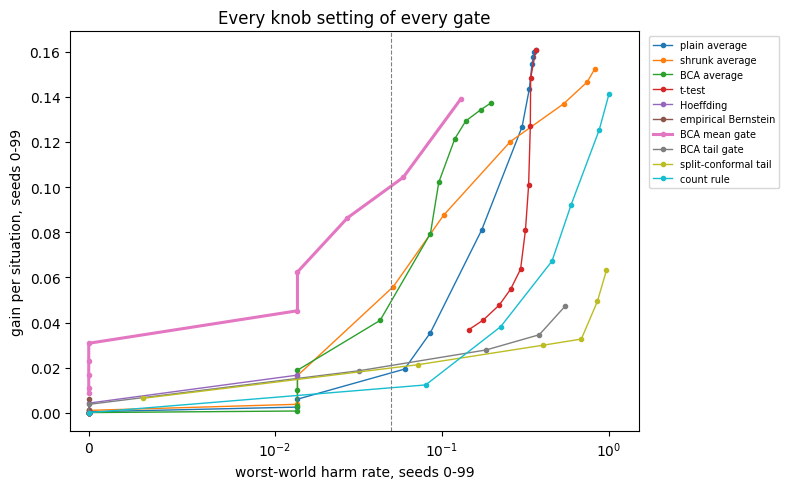

gate                      chosen knob  gain, seeds 0-99  gain, seeds 100-199  worst harm, 100-199
BCA mean gate                     0.2            0.0864               0.0845                 2.3%
BCA average                       0.5            0.0410               0.0400                 3.8%
shrunk average                    0.5            0.0165               0.0187                 1.6%
Hoeffding                         0.5            0.0167               0.0174                 0.1%
BCA tail gate                     0.2            0.0187               0.0172                 2.9%
plain average                     1.5            0.0061               0.0070                 0.8%
empirical Bernstein               0.5            0.0061               0.0061                 0.0%
split-conformal tail             0.05            0.0064               0.0056                 0.3%
count rule                        100            0.0001               0.0003                 0.2%
t-test              

In [106]:
fig, ax = plt.subplots(figsize=(8, 5))
for i, (g, points) in enumerate(FRONTIER.items()):
    xs, ys = [p[1] for p in points], [p[2] for p in points]
    ax.plot(xs, ys, marker="o", ms=3, lw=2.2 if g == "BCA mean gate" else 1, color=f"C{i}", label=g)
ax.axvline(DELTA, color="grey", ls="--", lw=0.8)
ax.set_xscale("symlog", linthresh=0.01)
ax.set_xlim(-0.001, 1.5)
ax.set_xlabel("worst-world harm rate, seeds 0-99")
ax.set_ylabel("gain per situation, seeds 0-99")
ax.set_title("Every knob setting of every gate")
ax.legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1.0))
fig.tight_layout(); plt.show()

print(f"{'gate':24}{'chosen knob':>13}{'gain, seeds 0-99':>18}{'gain, seeds 100-199':>21}{'worst harm, 100-199':>21}")
for g, (k, tune_gain, eval_gain, eval_harm) in sorted(TUNED.items(), key=lambda kv: -kv[1][2]):
    print(f"{g:24}{'none' if k is None else str(k):>13}{tune_gain:18.4f}{eval_gain:21.4f}{eval_harm:21.1%}")

**What to notice.**
- In the chart, left of the dashed line, the mean gate's thick pink line runs above every other gate's. The t-test's points all sit right of the line.
- The tuned mean gate earned 0.0845 on the fresh seeds, about twice the next gate, BCA's cautious average (0.0400). Then came the shrunk average (0.0187), Hoeffding (0.0174) and BCA's tail gate (0.0172).
- Its gain on the fresh seeds stayed close to its gain on the tuning seeds (0.0864), and its worst harm rate there was 2.3%, within 5%.
- The t-test had no safe setting, so tuned it always stays safe (gain 0.0000).

### Step 3.14 · Where each gate earns its gain

*Deeper: skip on a first read.*

**How to read it.** Four tables, all on seeds 100–199 at each gate's stated setting: gain by outcome shape; gain by number of candidates; the worst harm rate within each shape; and the share of good proposals accepted, by the proposal's number of held-out tries.

In [107]:
key = ["plain average", "shrunk average", "t-test", "Hoeffding", "empirical Bernstein", "BCA mean gate",
       "BCA tail gate", "BCA mean gate, shared budget", "oracle gate"]
print("Gain per situation by outcome shape (seeds 100-199, pooled over the other two factors)")
print(f"{'gate':31}" + "".join(f"{s:>15}" for s in SHAPES))
for g in key:
    print(f"{g:31}" + "".join(f"{v:15.4f}" for v in gain_by_world(DEC[g], ev).mean(axis=(1, 2))))

print("\nGain per situation by number of candidates (seeds 100-199)")
print(f"{'gate':31}" + "".join(f"{m:>10}" for m in CANDIDATES))
for g in key:
    print(f"{g:31}" + "".join(f"{v:10.4f}" for v in gain_by_world(DEC[g], ev).mean(axis=(0, 1))))

print("\nHarm rate by outcome shape, worst over the other factors (seeds 100-199)")
print(f"{'gate':31}" + "".join(f"{s:>15}" for s in SHAPES))
for g in key:
    print(f"{g:31}" + "".join(f"{v:15.1%}" for v in harm_by_world(DEC[g], ev).max(axis=(1, 2))))

bins = [(5, 9), (10, 19), (20, 39), (40, 69), (70, 100)]
print("\nShare of good proposals accepted, by number of held-out tries (seeds 100-199)")
print(f"{'gate':31}" + "".join(f"{f'{a}-{b}':>9}" for a, b in bins))
for g in key:
    row = []
    for a, b in bins:
        sel = GOOD[ev] & (NTRY[ev] >= a) & (NTRY[ev] <= b)
        row.append((DEC[g][ev] & sel).sum() / max(sel.sum(), 1))
    print(f"{g:31}" + "".join(f"{v:9.0%}" for v in row))

Gain per situation by outcome shape (seeds 100-199, pooled over the other two factors)
gate                                    steady  rare disaster   rare jackpot
plain average                           0.1755         0.0951         0.2038
shrunk average                          0.1616         0.0765         0.2156
t-test                                  0.0993         0.0843         0.0567
Hoeffding                               0.0000         0.0000         0.0001
empirical Bernstein                     0.0000         0.0000         0.0000
BCA mean gate                           0.0540         0.0138         0.0681
BCA tail gate                           0.0000         0.0099         0.0000
BCA mean gate, shared budget            0.0370         0.0032         0.0407
oracle gate                             0.1987         0.1565         0.2690

Gain per situation by number of candidates (seeds 100-199)
gate                                    1         3        10        30
plain avera

**What to notice.**
- BCA's mean gate earned least in rare-disaster worlds (0.0138) and most in rare-jackpot worlds (0.0681).
- More candidates gave the plain average more to gain: 0.0597 with 1 candidate, 0.2381 with 30. The mean gate's gain peaked at 10 candidates (0.0637; 0.0585 with 30).
- The shrunk average accepted 90.0% of harmful proposals in one rare-jackpot world, and the t-test 31.3% in a rare-disaster world.
- The mean gate needs many tries: it accepted 1% of good proposals with 5–9 tries and 64% with 70–100, where the plain average accepted 71% and 96%.

### Step 3.15 · Information only: stricter caps, lost return, the hardest worlds

*Deeper: skip on a first read.*

*Written after the run; not part of the claims.* The printout answers three questions the claims did not ask.
1. Does the winner depend on how strict the safety cap is? Each gate is tuned on seeds 0–99 to its best setting under a cap on worst-world harm (1% to 20%, or no cap: 100%), then scored on seeds 100–199.
2. Does any gate **lose return**, doing worse than always staying safe in some world?
3. How do the gates fare in the hardest worlds: rare disasters with 10% good candidates?

In [108]:
CAPS = (0.01, 0.02, 0.05, 0.1, 0.2, 1.0)
print("1. Gain per situation on seeds 100-199, after tuning on seeds 0-99 to each cap on worst-world harm")
print(f"{'gate':22}" + "".join(f"{f'cap {c:.0%}':>10}" for c in CAPS))
held = True
for g, points in FRONTIER.items():
    cells = []
    for cap in CAPS:
        ok = [p for p in points if p[1] <= cap]
        if not ok:
            cells.append(f"{'none':>10}")
            continue
        d = max(ok, key=lambda p: p[2])[3]
        held &= bool(harm_by_world(d, ev).max() <= cap)
        cells.append(f"{gain_by_world(d, ev).mean():10.3f}")
    print(f"{g:22}" + "".join(cells))
print("On seeds 100-199, every tuned gate stayed within its cap:", held)

print("\n2. Worlds (of 36) where each gate loses return at its stated setting, seeds 100-199")
print(f"{'gate':31}{'worlds below 0':>16}{'lowest world gain':>19}")
for g in GATES:
    gw = gain_by_world(DEC[g], ev)
    print(f"{g:31}{(gw < 0).sum():16d}{gw.min():19.4f}")

print("\nThe hardest worlds: rare disasters and 10% good candidates. Gain by number of candidates, seeds 100-199")
print(f"{'gate':31}" + "".join(f"{m:>10}" for m in CANDIDATES))
for g in ("no gate", "plain average", "t-test", "shrunk average", "BCA mean gate", "BCA average", "oracle gate"):
    print(f"{g:31}" + "".join(f"{v:10.4f}" for v in gain_by_world(DEC[g], ev)[1, 0]))

1. Gain per situation on seeds 100-199, after tuning on seeds 0-99 to each cap on worst-world harm
gate                      cap 1%    cap 2%    cap 5%   cap 10%   cap 20%  cap 100%
plain average              0.001     0.007     0.007     0.036     0.078     0.158
shrunk average             0.001     0.019     0.019     0.056     0.087     0.151
BCA average                0.000     0.021     0.040     0.098     0.136     0.136
t-test                      none      none      none      none     0.040     0.158
Hoeffding                  0.005     0.017     0.017     0.017     0.017     0.017
empirical Bernstein        0.006     0.006     0.006     0.006     0.006     0.006
BCA mean gate              0.030     0.061     0.084     0.103     0.137     0.137
BCA tail gate              0.003     0.003     0.017     0.017     0.027     0.046
split-conformal tail       0.006     0.006     0.006     0.019     0.019     0.062
count rule                 0.000     0.000     0.000     0.011     0.01

**What it showed.**
- BCA's mean gate earned the most at every cap from 1% (0.030) to 20% (0.137). With no cap, the plain average and the t-test earned the most (0.158). Every tuned gate stayed within its cap on seeds 100–199.
- Without a gate, the critic alone lost return in 5 worlds (as low as −0.2512); the plain average lost return in 4 (−0.0109 at worst) and the t-test in 4 (−0.0085). BCA's mean gate never did (its lowest world gain was 0.0008), nor did BCA's cautious average (0.0078).
- In the hardest worlds, the plain average and the t-test lost return at every number of candidates. BCA's cautious average earned 0.0078 to 0.0482 there, the most of the gates printed apart from the oracle.

### Step 3.16 · Checks

*Deeper: skip on a first read.*

These confirm that the toy works as described; any failure stops the notebook.
1. Each candidate's exact average gain matches 200,000 simulated tries, sits inside its shape's range, and has the intended sign.
2. For identical tries, the mean gate's 10,000 draws match the exact chance $\left(\frac{-g_{\min}}{g - g_{\min}}\right)^n$ (Step A.8).
3. Student's t values match published tables.
4. BCA's tail gate cannot say yes with fewer than 29 tries.
5. Gates accept only real proposals, and none gains more than the oracle gate in any world.
6. The critic never sees held-out tries: rerunning seed 0 with different held-out tries changes no proposal.

In [109]:
# 1. The exact average gains match simulation, sit inside the stated range, and have the intended sign.
rng = np.random.default_rng([ROOT_SEED, 999])
for shape in SHAPES:
    good = rng.random(6) < 0.5
    cand = candidates(shape, good, rng.random(6), rng.random(6))
    sim = tries(shape, cand, rng.random((6, 200_000)), rng.standard_normal((6, 200_000)))
    se = sim.std(axis=1) / math.sqrt(sim.shape[1])
    assert np.all(np.abs(sim.mean(axis=1) - cand["mean"]) < 5 * se), shape
    assert np.all((cand["mean"] > 0) == good), shape
    assert sim.min() >= FLOOR[shape] and sim.max() <= CEILING[shape], shape
# 2. The mean gate's sampler matches the exact answer for identical tries: with n tries of gain g and floor a,
#    the chance that a weighted average is below 0 is (-a / (g - a)) ** n.
w = np.random.default_rng([ROOT_SEED, 998]).standard_exponential((DRAWS, N_MAX + 1))
for n_, g_, a_ in ((10, 0.35, -1.0), (29, 0.11, -1.0), (29, 0.4, -10.0), (100, 0.03, -1.0)):
    estimate = ((w[:, :n_] * g_).sum(axis=1) + w[:, N_MAX] * a_ < 0).mean()
    exact = (-a_ / (g_ - a_)) ** n_
    assert abs(estimate - exact) < 4 * math.sqrt(exact * (1 - exact) / DRAWS), (n_, g_, a_, estimate, exact)
# 3. Student's t quantiles match published tables.
for level, df, want in ((0.05, 4, 2.1318), (0.05, 9, 1.8331), (0.01, 29, 2.4620), (0.005, 99, 2.6264)):
    assert abs(t_upper(level, df) - want) < 1e-3, (level, df)
# 4. BCA's tail gate cannot accept anything below 29 tries.
assert allowed_below(28, TAIL) == -1 and allowed_below(29, TAIL) == 0
# 5. Gates accept only real proposals, and none gains more than the oracle gate in any world.
oracle_by_world = gain_by_world(DEC["oracle gate"], EVAL_SEEDS)
for g, d in DEC.items():
    assert not (d & ~EXISTS).any(), g
    assert np.all(gain_by_world(d, EVAL_SEEDS) <= oracle_by_world + 1e-12), g
# 6. The critic never sees held-out tries: rerunning seed 0 with different held-out tries changes no proposal.
same, flipped = run_seed(0), run_seed(0, flip_held=True)
for f in ("exists", "mu", "n", "best"):
    assert np.array_equal(same[f], flipped[f]), f
assert not np.array_equal(same["mean"], flipped["mean"])
print("All checks passed. Notebook seconds:", round(time.perf_counter() - START, 1))

All checks passed. Notebook seconds: 12.9


## What Part 3 found

| Claim | Result | Verdict |
|---|---|---|
| 1. BCA's mean gate keeps its promise | worst harm rate 0.003 in any world | alive |
| 2. It is the tightest guaranteed mean gate | 17.4% of good proposals accepted, against 0.0% for Hoeffding and empirical Bernstein | alive |
| 3. A t-test gate is unsafe when disasters are rare | worst rare-disaster harm rate 0.313 | alive |
| 4. Where many candidates compete, it beats simple averaging | 0.0567 per situation, against 0.1829 (plain) and 0.1625 (shrunk) | shelved |
| 5. At equal harm, it earns the most | 0.0845, against 0.0400 for the next gate (BCA's cautious average) | alive |
| 6. Deciding the 20 situations together earns more | 0.0270, against 0.0453 deciding each alone | shelved |

- **The promise held, with margin to spare.** At its stated 5% level, BCA's mean gate accepted at most 0.3% of harmful proposals in any world. That caution has a price: it earned 0.045 per situation, less than a third of the plain average's 0.158.
- **The t-test, the usual shortcut, fails when disasters are rare.** A small sample often holds no disaster, with chance $(1-p)^n$, and the t-test then sees a steady small gain and says yes (Step 3.6). In one rare-disaster world it accepted 31.3% of harmful proposals, and no t-test setting stayed within 5% harm in every world.
- **At equal harm, the mean gate earned the most.** Tuned on seeds 0–99 to at most 5% harm in every world, it earned 0.0845 per situation on seeds 100–199, at level 0.2, with a worst harm rate of 2.3%. Next came BCA's cautious average (0.0400), the shrunk average (0.0187), Hoeffding (0.0174) and BCA's tail gate (0.0172). It also earned the most at every harm cap from 1% to 20% (information only). This verdict rests on tuning against toy worlds whose truth is known.
- **It did not beat simple averaging where many candidates compete (claim 4, shelved).**
  - *The idea:* where many candidates compete and few are good, the critic is often fooled by a lucky candidate (Step 3.9), so a cautious gate should earn more than simply checking the held-out average.
  - *What we tested (and the kill rule):* pooled gain over the 12 crowded worlds (10 or 30 candidates, 10% or 30% good); shelved unless the mean gate earned more than both the plain and the shrunk average.
  - *What happened:* 0.0567 per situation, against 0.1829 and 0.1625.
  - *Why:* the held-out tries are fresh, so their average is an honest estimate of a proposal's gain, however lucky its training tries were (Step 3.9). After that, extra caution mostly turns good proposals away. With 5–9, 10–19 and 20–39 tries, the mean gate accepted 1%, 5% and 17% of good proposals; the plain average accepted 71%, 80% and 89%.
- **Deciding all situations together earned less (claim 6, shelved).**
  - *The idea:* deciding the 20 situations together, with a shared budget of 10% harmful acceptances, should let more good proposals through than deciding each alone at 5%.
  - *What we tested (and the kill rule):* pooled gain against the mean gate deciding each situation alone; shelved unless it earned more, with an average share of harmful acceptances of at most 0.12 in every world.
  - *What happened:* 0.0270 per situation, against 0.0453. Harm was not the problem: the worst average harmful share of its acceptances was 0.000.
  - *Why:* Benjamini–Hochberg's bar for the $k\text{-th}$ smallest of $M$ p-values is $0.10\,k/M$ (Step 3.10). It is looser than deciding alone at 0.05 only when $k > M/2$, that is, when more than half of the seed's proposals pass together. Here few pass at all: alone, the mean gate accepted 17.4% of good proposals. So the shared bar was usually the stricter one.
- **A lead, not a claim.** BCA's cautious average, $(\sum_i g_i + g_{\min})/(n+1)$, needs no confidence level: at its stated setting (yes when it is above 0) nothing is chosen from data. There it earned 0.136 per situation, against 0.158 for the plain average, and it never lost return in any world (its lowest world gain was 0.0078). In the hardest worlds (rare disasters, 10% good candidates), where the plain average and the t-test lost return, it earned 0.0078 to 0.0482, the most of any real gate printed there (only the oracle earned more).

**The insight.** At equal safety, BCA's mean gate earned the most, for two reasons: it needs less clean evidence than the other guaranteed bounds (29 identical tries, with gains from −1 to 1, need a gain of 0.11 each, against 0.45 for Hoeffding; Step 3.5), and, unlike the t-test, it charges a clean sample for the disaster the sample may be hiding (Step 3.6). That win rests on tuning in toy worlds whose truth is known, and the gate's promise rests on a proof not yet peer reviewed; at its stated 5% level the gate is cautious, and the plain average of fresh held-out tries earns more. Here every try came from the state being decided, so every try counted equally; Part 4 asks what BCA's weights add when the tries come from a different mix of states.

---
# Part 4 · Do BCA's weights help under a shift?

*Pre-registered. Original notebook: `bca_weights_toy.ipynb`. Kill rules fingerprint `e32e04d7…f44e`.*

**The question.** With equal weights, BCA's tail gate is a textbook test, the exact binomial test (Step A.6). Its one part that is not textbook is its **weights** (Step A.9). When the held-out tries come from a different mix of states than deployment, do the weights keep BCA's promises? And do they use the evidence better than the simple alternatives that also keep the promise (rejection sampling and a per-condition bound, Step 4.3)?

**What changed since Part 3.**
- In Parts 2 and 3, the held-out tries came from the same mix of states that the policy meets at deployment. Here they do not. That difference is the **shift**.
- There is one risky action, decided once for a whole region of states. No critic proposes it.
- Both promises are tested side by side: the tail promise (Part 2) and the mean promise (Part 3).

**In this part**

**Setting up**

1. The setup: one deviation, five conditions
2. The weights, worked
3. The gates
4. How much evidence each tail gate needs

**The worlds and the claims**

5. A try's gain: which disaster chances are unsafe or harmful
6. Where disasters sit, and how the log can hide them
7. 288 worlds, and how a gate is scored
8. The six claims and their kill rules

**The run, and one decision by hand**

9. The run
10. One decision, worked by hand

**What the run shows**

11. Results
12. Verdicts
13. Equal harm: every gate tuned to the same safety
14. Where the differences come from
15. Checks
16. Information only: a weighted mean gate that a proof covers

### Step 4.1 · The setup: one deviation, five conditions

A policy wants to **deviate**: to take a risky action (think full throttle) instead of the fallback, the safe, well-logged action. It decides once for a whole region of states: deviate everywhere in the region, or fall back everywhere.

- The region has five **conditions**, $c = 0, 1, 2, 3, 4$, from mild (0) to harsh (4).
- A try's **gain** $g_i$ is its outcome minus the fallback's. It is usually small and positive, about 0.5. Sometimes it is a **disaster**, a gain of $-4$, which is also the worst gain possible: the floor $g_{\min} = -4$.
- The held-out tries come from the log, mostly from mild conditions. Deployment may meet harsh conditions more often.

The next cell holds the experiment's settings. The table after it shows the three mixes of conditions.

In [110]:
import math, os, sys, time, hashlib
from fractions import Fraction
from functools import lru_cache
import numpy as np
import matplotlib.pyplot as plt

START = time.perf_counter()
ROOT_SEED, STREAM = 20261014, 43
N_SEEDS = 800
TUNE_SEEDS, EVAL_SEEDS = np.arange(0, 400), np.arange(400, 800)
SHIFTS = ("none", "moderate", "strong")
LOG_PCT = np.array([35, 25, 20, 12, 8])                          # conditions 0 (mild) to 4 (harsh), in percent
DEPLOY_PCT = {"none": LOG_PCT, "moderate": np.array([15, 20, 25, 20, 20]), "strong": np.array([5, 10, 15, 30, 40])}
PROFILES = ("harm everywhere alike", "harm in harsh conditions", "harm in mild conditions")
STEEPNESS = 0.6                                                  # how sharply harm rises or falls across conditions
RUNGS = (0.0, 0.02, 0.05, 0.08, 0.10, 0.12, 0.15, 0.20)          # disaster chance at deployment
SIZES = (30, 60, 120, 240)                                       # held-out tries the gate reads
N_MAX = max(SIZES)
CENTER, SPREAD, LO, HI = 0.5, 0.2, -1.0, 2.0                     # usual gain: clip(0.5 + 0.2 Z, -1, 2)
DISASTER = FLOOR = -4.0                                          # a disaster's gain, also the worst possible gain
TAIL, CONFIDENCE, DELTA = 0.10, 0.95, 0.05
TAIL_DRAWS, MEAN_DRAWS = 1000, 10_000                            # 1,000 as built for the tail gate
TAIL_SHARES = (0.5, 0.4, 0.3, 0.2, 0.15, 0.1, 0.05)              # knob grids for claim 6
LEVELS = (0.5, 0.3, 0.2, 0.1, 0.05, 0.02, 0.01, 0.005, 0.001)
MARGINS = (0.0, 0.02, 0.05, 0.1, 0.15, 0.2, 0.3, 0.5, 0.75, 1.0)

LOG_MIX = LOG_PCT / 100
DEPLOY_MIX = {s: DEPLOY_PCT[s] / 100 for s in SHIFTS}
STRATA_LEVEL = DELTA / LOG_MIX.size
WEIGHT = np.array([DEPLOY_PCT[s] / LOG_PCT for s in SHIFTS])     # (shift, condition): deployment share / log share
WBAR = np.array([float(sum(Fraction(int(d) ** 2, int(l)) for d, l in zip(DEPLOY_PCT[s], LOG_PCT)) / 100)
                 for s in SHIFTS])                               # average weight at deployment (BCA's test mass)
WMAX = WEIGHT.max(axis=1)
assert all(DEPLOY_PCT[s].sum() == 100 for s in SHIFTS) and TAIL in TAIL_SHARES and DELTA in LEVELS

In [111]:
lesson_4_names = ["0 (mild)", "1", "2", "3", "4 (harsh)"]


def lesson_4_ready(stage="run"):
    """True while the names this part reads still hold Part 4's experiment.

    Parts 2 and 3 use some of the same names (STREAM, N_SEEDS, N_MAX, FLOOR, MU, R, DEC, ...). If their cells are
    rerun after Part 4's, this part's worked examples ask you to rerun Part 4's cells first, instead of quietly
    reading another part's numbers. The stage says which of Part 4's cells a worked example needs: "settings"
    (Step 4.1), "truths" (Step 4.5) or "run" (Step 4.9)."""
    try:
        ok = (ROOT_SEED == 20261014 and STREAM == 43 and N_SEEDS == 800 and N_MAX == 240
              and isinstance(FLOOR, float) and FLOOR == -4.0 and TAIL == 0.1 and CONFIDENCE == 0.95
              and DELTA == 0.05 and TAIL_SHARES == (0.5, 0.4, 0.3, 0.2, 0.15, 0.1, 0.05))
        if ok and stage in ("truths", "run"):
            ok = all(np.shape(x) == (len(RUNGS),) for x in (MU, BAD, UNSAFE, HARMFUL))
        if ok and stage == "run":
            ok = (isinstance(DEC, dict) and "BCA tail, weighted" in DEC and isinstance(R, dict) and "cross" in R
                  and R["bad"].shape == (N_SEEDS,) + WORLD)
    except (NameError, TypeError, KeyError, AttributeError):
        ok = False
    if not ok:
        lesson_show("This cell reads Part 4's experiment, but an earlier part's cells have been rerun since and "
                    "reused some of its names. Rerun Part 4's code cells in order, from the settings cell in "
                    "Step 4.1 down to this cell.")
    return bool(ok)


def lesson_4_lines(terms, lead, per=2, end=""):
    """A long sum laid out `per` terms to a line, so that it fits a phone screen. The terms are LaTeX strings (a
    term starting with '-' is subtracted); the first line starts with `lead`, the others with '&\\quad'."""
    signed = [t if k == 0 else (" - " + t[1:] if t.startswith("-") else " + " + t) for k, t in enumerate(terms)]
    lines = [(lead if k == 0 else r"&\quad") + "".join(signed[k:k + per]) for k in range(0, len(signed), per)]
    lines[-1] += end
    return lines


def lesson_4_holds(test):
    """True when test() is true; False when it is false or cannot even be checked (a Try-it input of the wrong kind)."""
    try:
        return bool(test())
    except (TypeError, ValueError, OverflowError):
        return False


def lesson_4_number(v):
    """True for a number, False for text, True/False or anything else."""
    return isinstance(v, (int, float, np.integer, np.floating)) and not isinstance(v, (bool, np.bool_))


def lesson_4_quoted(names):
    """'"a", "b" or "c"': the choices a Try-it input accepts, quoted as you would type them."""
    names = [f'"{x}"' for x in names]
    return ", ".join(names[:-1]) + " or " + names[-1]


lesson_table(["Condition $c$", "Log's tries", "Moderate shift", "Strong shift"],
             [[lesson_4_names[k], f"{LOG_PCT[k]}%", f"{DEPLOY_PCT['moderate'][k]}%", f"{DEPLOY_PCT['strong'][k]}%"]
              for k in range(LOG_PCT.size)],
             note=lesson_text("The last two columns are deployment's mix under each shift. **So:** conditions 3 and 4 "
                              "hold <<a>>% of the log's tries, but <<b>>% of deployment under the moderate shift and "
                              "<<c>>% under the strong one. With no shift, deployment's mix is the log's. From here "
                              "on, $p_{\\mathrm{log}}(c)$ and $p_{\\mathrm{dep}}(c)$ are condition $c$'s shares in the "
                              "log and at deployment.",
                              a=int(LOG_PCT[3:].sum()), b=int(DEPLOY_PCT["moderate"][3:].sum()),
                              c=int(DEPLOY_PCT["strong"][3:].sum())))

| Condition $c$ | Log's tries | Moderate shift | Strong shift |
|---|---|---|---|
| 0 (mild) | 35% | 15% | 5% |
| 1 | 25% | 20% | 10% |
| 2 | 20% | 25% | 15% |
| 3 | 12% | 20% | 30% |
| 4 (harsh) | 8% | 20% | 40% |

The last two columns are deployment's mix under each shift. **So:** conditions 3 and 4 hold 20% of the log's tries, but 40% of deployment under the moderate shift and 70% under the strong one. With no shift, deployment's mix is the log's. From here on, $p_{\mathrm{log}}(c)$ and $p_{\mathrm{dep}}(c)$ are condition $c$'s shares in the log and at deployment.

### Step 4.2 · The weights, worked

Step A.9's weights carry over unchanged. A try from condition $c$ counts $w_c = p_{\mathrm{dep}}(c)/p_{\mathrm{log}}(c)$: try $i$'s random weight $E_i$ is multiplied by its condition's weight, $w_i$. The extra worst-case weight is multiplied by $\bar w$, the average weight at deployment. And $n$ tries from the log are worth about $n/\bar w$ equally weighted ones: that is their effective number, $n_{\mathrm{eff}}$.

Here they are for the five conditions.

In [112]:
def lesson_4_weights(deploy_pct):
    """Shift weights, the average weight at deployment and the effective tries per try, worked for one mix."""
    try:
        values = list(deploy_pct)
        dep = np.asarray(values, dtype=float)
        ok = (not isinstance(deploy_pct, str) and not any(isinstance(v, (str, bool, np.bool_)) for v in values)
              and dep.shape == LOG_PCT.shape and bool(np.all(np.isfinite(dep))) and bool(np.all(dep > 0))
              and abs(float(dep.sum()) - 100) <= 1e-9)
    except (TypeError, ValueError, OverflowError):
        ok = False
    if not ok:
        lesson_show("Give five positive percentages, one per condition from 0 (mild) to 4 (harsh), adding up to 100, "
                    "for example (5, 10, 15, 30, 40).")
        return
    p_log, p_dep = LOG_PCT / 100, dep / 100
    w = p_dep / p_log
    terms = p_dep ** 2 / p_log
    wbar = float(terms.sum())
    for si, shift in enumerate(SHIFTS):
        if np.array_equal(dep, DEPLOY_PCT[shift]):
            lesson_check(np.allclose(w, WEIGHT[si]) and abs(wbar - WBAR[si]) < 1e-12, f"weights, {shift} shift")
    # Whole percentages need 2 decimals as shares; others get up to 4, so that the shares shown are the shares used.
    dd = 2
    while dd < 4 and np.any(np.abs(np.round(p_dep, dd) - p_dep) > 1e-12):
        dd += 1
    lesson_table(["$c$", "$p_{\\mathrm{log}}(c)$", "$p_{\\mathrm{dep}}(c)$", "$w_c$",
                  "$p_{\\mathrm{dep}}^2 / p_{\\mathrm{log}}$"],
                 [[lesson_4_names[k], f"{p_log[k]:.2f}", f"{p_dep[k]:.{dd}f}", lesson_txt(w[k], 3),
                   lesson_txt(terms[k], 4)] for k in range(w.size)],
                 note="The last column is $p_{\\mathrm{dep}}(c)^2 / p_{\\mathrm{log}}(c)$, each condition's term in "
                      "the sum for $\\bar w$.")
    fracs = [lesson_tex(r"\frac{<<d>>^2}{<<l:2>>}", d=lesson_num(p_dep[k], dd), l=p_log[k]) for k in range(w.size)]
    nums = [lesson_num(terms[k], 4) for k in range(w.size)]
    lesson_math(*lesson_4_lines(fracs, r"\bar w &= "),
                *lesson_4_lines(nums, r"&= ", end=lesson_tex(r" = <<v:4>>", v=wbar)),
                note="That is the average weight at deployment. For $n$ tries in the log's mix, the effective "
                     "number of tries is then about:")
    lesson_math(lesson_tex(r"n_{\mathrm{eff}} &\approx \frac{n}{\bar w} = \frac{n}{<<v:4>>} "
                           r"= <<r:2>> \times n", v=wbar, r=1 / wbar),
                note=lesson_text("**So:** each try from the log is worth about <<r:2>> of an equally weighted try; "
                                 "120 tries count as about <<e:0>>.", r=1 / wbar, e=120 / wbar))

In [113]:
# Try it: deployment's share of each condition, 0 (mild) to 4 (harsh), in percent; they must add up to 100.
# The experiment's mixes: strong (5, 10, 15, 30, 40), moderate (15, 20, 25, 20, 20), no shift (35, 25, 20, 12, 8).
try_deploy_pct = (5, 10, 15, 30, 40)
lesson_4_weights(try_deploy_pct)

| $c$ | $p_{\mathrm{log}}(c)$ | $p_{\mathrm{dep}}(c)$ | $w_c$ | $p_{\mathrm{dep}}^2 / p_{\mathrm{log}}$ |
|---|---|---|---|---|
| 0 (mild) | 0.35 | 0.05 | 0.143 | 0.0071 |
| 1 | 0.25 | 0.10 | 0.400 | 0.0400 |
| 2 | 0.20 | 0.15 | 0.750 | 0.1125 |
| 3 | 0.12 | 0.30 | 2.500 | 0.7500 |
| 4 (harsh) | 0.08 | 0.40 | 5.000 | 2.0000 |

The last column is $p_{\mathrm{dep}}(c)^2 / p_{\mathrm{log}}(c)$, each condition's term in the sum for $\bar w$.

$$
\begin{aligned}
\bar w &= \frac{0.05^2}{0.35} + \frac{0.10^2}{0.25} \\ &\quad + \frac{0.15^2}{0.20} + \frac{0.30^2}{0.12} \\ &\quad + \frac{0.40^2}{0.08} \\ &= 0.0071 + 0.0400 \\ &\quad + 0.1125 + 0.7500 \\ &\quad + 2.0000 = 2.9096
\end{aligned}
$$

That is the average weight at deployment. For $n$ tries in the log's mix, the effective number of tries is then about:

$$
\begin{aligned}
n_{\mathrm{eff}} &\approx \frac{n}{\bar w} = \frac{n}{2.9096} = 0.34 \times n
\end{aligned}
$$

**So:** each try from the log is worth about 0.34 of an equally weighted try; 120 tries count as about 41.

### Step 4.3 · The gates

Every gate reads the same held-out tries and says yes (deviate) or no (fall back). The first column gives each gate's name as the code prints it. "Kept for" says which mix of conditions the promise is about.

**Gates for the tail promise:** 95% sure that at most 10% of outcomes fall below the fallback.

| Gate | Says yes when | Kept for |
|---|---|---|
| BCA tail, unweighted | at most $x(n)$ of the $n$ tries fall below the fallback (Step A.7) | the log's mix |
| **BCA tail, weighted** | BCA's tail gate with 1,000 draws, each $E_i$ multiplied by $w_i$ and the extra weight $E_{n+1}\bar w$ (Step 4.10 works one case) | deployment: claim 2 |
| weighted split conformal | tries at or above the fallback carry at least 90% of the weight, counting an extra weight $\bar w$ for the unseen try (Step A.2's "+1", weighted; [Tibshirani and others, 2019](https://ar5iv.labs.arxiv.org/html/1904.06019)) | deployment, only on average over data sets |
| rejection-sampled exact | **rejection sampling** keeps each try with chance $w_i / w_{\max}$, where $w_{\max}$ is the largest weight; then Step A.7's exact test passes on the kept tries (Park and others, 2022) | deployment |
| stratified exact | a 99% upper bound for each condition's share below the fallback, mixed in deployment's proportions, is at most 10% | deployment |

The weighted tail gate is the one built in the repository's production code, `calibration/wbcp.py`.

**Gates for the mean promise:** 95% sure that the average gain is above 0.

| Gate | Says yes when | Kept for |
|---|---|---|
| BCA mean, unweighted | Step A.8's mean gate passes on all tries, with floor $-4$ and 10,000 draws | the log's mix |
| **BCA mean, weighted** | the same, with each $E_i$ multiplied by $w_i$ and the floor's weight $E_{n+1}\bar w$ | deployment: claim 5, with no proof |
| rejection-sampled BCA mean | the mean gate passes on the kept tries | deployment |
| weighted t-test | the weighted average minus a t-test margin is above 0 | deployment, roughly, if gains are bell-shaped |
| weighted average | the weighted average gain is above 0 | none |
| plain average | the plain average gain is above 0 | none |

Three references complete the list: **never deviate**, **always deviate**, and the **oracle**, which deviates exactly when the deviation is truly good on average at deployment (for scoring only). The two bold gates are under test. Rejection sampling and the stratified bound are the simple ways to keep a valid promise under a shift; both throw evidence away.

### Step 4.4 · How much evidence each tail gate needs

Even when every try beats the fallback, a valid tail gate cannot say yes until it has enough tries: 29 with equal weights (Step A.5). A shift raises that minimum.

**How to read it.** One row per shift. *Effective tries per try* is $1/\bar w$ (Step 4.2). *Tries kept by rejection* is the share of tries that rejection sampling keeps. The last three columns give the fewest tries with which each gate can say yes at all.

In [114]:
def tries_needed_weighted(si):
    """About how many tries weighted BCA's tail gate needs to say yes when every try beats the fallback."""
    c = TAIL / ((1 - TAIL) * WBAR[si])
    return math.ceil(math.log(1 / (1 - CONFIDENCE)) / (LOG_MIX @ np.log1p(c * WEIGHT[si])))

def tries_needed_stratified(si):
    """About how many tries the stratified exact gate needs, with condition counts at their expected values."""
    for n in range(1, 5000):
        bound = DEPLOY_MIX[SHIFTS[si]] @ (1 - STRATA_LEVEL ** (1 / (n * LOG_MIX)))
        if bound <= TAIL:
            return n
    return math.inf

print("shift      effective tries   tries kept by       tries needed to say yes at all (about)")
print("           per try           rejection           weighted BCA   rejection-sampled exact   stratified exact")
for si, shift in enumerate(SHIFTS):
    print(f"{shift:10}{1 / WBAR[si]:>11.2f}{1 / WMAX[si]:>17.2f}{tries_needed_weighted(si):>22d}"
          f"{math.ceil(29 * WMAX[si]):>20d}{tries_needed_stratified(si):>23d}")

shift      effective tries   tries kept by       tries needed to say yes at all (about)
           per try           rejection           weighted BCA   rejection-sampled exact   stratified exact
none             1.00             1.00                    29                  29                    216
moderate         0.73             0.40                    39                  73                    287
strong           0.34             0.20                    83                 145                    382


**What to notice.** With no shift, weighted BCA and rejection sampling need 29 tries, as in Step A.5, and the stratified bound 216. Under the moderate and strong shifts, weighted BCA needs about 39 and 83, rejection sampling 73 and 145, and the stratified bound 287 and 382, more than any world has (240 at most).

*Deeper: skip on a first read.*

**Why weighted BCA needs more.** Suppose every try beats the fallback. A draw crosses at or below the fallback (Step A.3) when the tries' weight reaches 90% of the total, the extra weight included:

$$
\begin{aligned}
\sum_i E_i\, w_i &\ge (1-\alpha)\Big(\sum_i E_i\, w_i + E_{n+1}\,\bar w\Big) \\
\iff E_{n+1} &\le k \sum_i E_i\, w_i
\end{aligned}
$$

where $k = \alpha / \big((1-\alpha)\,\bar w\big)$. So a draw fails to cross only when the extra weight alone is too heavy. For an Exponential(1) weight $E$, $P(E > u) = e^{-u}$, and the average of $e^{-vE}$ is $1/(1+v)$. The weights are drawn independently, so

$$
\begin{aligned}
& P(\text{a draw fails to cross}) \\
&\quad = \text{average of } e^{-k \sum_i E_i\, w_i} \\
&\quad = \prod_{i=1}^{n} \text{average of } e^{-k\, w_i\, E_i} \\
&\quad = \prod_{i=1}^{n} \frac{1}{1 + k\, w_i}
\end{aligned}
$$

With equal weights, $k = 1/9$ and each factor is $0.9$: Step A.5's $0.9^n$. The gate needs this chance to be at most 5%, so that about 950 of the 1,000 draws cross. The cell below works it out for one shift, then the other two gates' minimums.

In [115]:
def lesson_4_evidence(shift):
    """The three 'tries needed' columns of the table above, worked for one shift."""
    if not lesson_4_ready("settings"):
        return
    if not lesson_4_holds(lambda: isinstance(shift, str) and shift in SHIFTS):
        lesson_show("Choose a shift: " + lesson_4_quoted(SHIFTS) + ", in quotes.")
        return
    si = SHIFTS.index(shift)
    label = {"none": "no shift", "moderate": "moderate shift", "strong": "strong shift"}[shift]
    w, wbar, wmax = WEIGHT[si], float(WBAR[si]), float(WMAX[si])
    # Weighted BCA: the chance that a draw fails to cross, with each condition at its expected count.
    k = TAIL / ((1 - TAIL) * wbar)
    logs = np.log1p(k * w)
    per_try = float(LOG_MIX @ logs)
    need = math.log(1 / (1 - CONFIDENCE)) / per_try
    lesson_check(math.ceil(need) == tries_needed_weighted(si), "weighted BCA's minimum")
    # Enough decimals that the shown terms add up to the shown rate, and ln 20 over the shown rate gives the shown n.
    dl = 4
    while dl < 7 and (round(sum(round(float(LOG_MIX[c]), 2) * round(float(logs[c]), dl) for c in range(w.size)), dl)
                      != round(per_try, dl)
                      or round(round(math.log(20), 3) / round(per_try, dl), 1) != round(need, 1)):
        dl += 1
    terms = [lesson_tex(r"<<p:2>> \times <<t>>", p=LOG_MIX[c], t=lesson_num(logs[c], dl)) for c in range(w.size)]
    # One term on the first line (it also carries "-n x ("), then two to a line, so that every line fits a phone.
    sum_lines = [r"&\quad = -n \times (" + terms[0]] + [
        r"&\qquad" + "".join(" + " + t for t in terms[k:k + 2]) for k in range(1, len(terms), 2)]
    sum_lines[-1] += ")"
    lesson_show(f"**Weighted BCA, {label}.**")
    lesson_math(lesson_tex(r"k &= \frac{\alpha}{(1-\alpha)\,\bar w} = \frac{0.1}{0.9 \times <<v:4>>} = <<k:4>>",
                           v=wbar, k=k))
    lesson_math(r"& \ln P(\text{a draw fails to cross})",
                r"&\quad = -\textstyle\sum_{i=1}^{n} \ln(1 + k\, w_i)",
                r"&\quad \approx -n \textstyle\sum_c p_{\mathrm{log}}(c)\, \ln(1 + k\, w_c)",
                *sum_lines,
                lesson_tex(r"&\quad = -<<r>> \times n", r=lesson_num(per_try, dl)),
                r"& P(\text{a draw fails to cross}) \le 0.05",
                lesson_tex(r"&\quad \iff <<r>> \times n \ge \ln 20 = <<l:3>>", r=lesson_num(per_try, dl),
                           l=math.log(20)),
                lesson_tex(r"&\quad \iff n \ge <<n:1>>", n=need),
                note=lesson_text("The step marked $\\approx$ puts $n\\,p_{\\mathrm{log}}(c)$ tries in condition $c$, "
                                 "their expected number. **So:** weighted BCA needs about <<n>> tries.",
                                 n=math.ceil(need)))
    # Rejection sampling: keep each try with chance w_i / w_max, then the exact test needs 29 kept tries.
    short = f"{wmax:g}"
    lesson_check(abs(float(LOG_MIX @ (w / wmax)) - 1 / wmax) < 1e-12, "the share that rejection sampling keeps")
    lesson_show(f"**Rejection-sampled exact, {label}.** Rejection sampling keeps each try with chance "
                "$w_i / w_{\\max}$ (Step 4.3), so the kept tries follow deployment's mix.")
    lesson_math(r"\text{share kept} &= \sum_c p_{\mathrm{log}}(c)\,\frac{w_c}{w_{\max}}",
                lesson_tex(r"&= \frac{\sum_c p_{\mathrm{dep}}(c)}{w_{\max}} = \frac{1}{<<m>>} = <<s:2>>",
                           m=short, s=1 / wmax),
                lesson_tex(r"\text{kept tries} &\approx n \times <<s:2>> \ge 29", s=1 / wmax),
                lesson_tex(r"&\iff n \ge 29 \times <<m>> = <<n>>", m=short, n=f"{29 * wmax:g}"),
                note=lesson_text("**So:** rejection sampling needs about <<n>> tries, so that Step A.7's exact test "
                                 "gets its 29 kept tries on average.", n=math.ceil(29 * wmax)))
    # Stratified: a 99% Clopper-Pearson bound per condition (1% each, 5% in all), mixed by deployment's shares.
    n_s = tries_needed_stratified(si)
    bounds = {n: 1 - STRATA_LEVEL ** (1 / (n * LOG_MIX)) for n in (n_s - 1, n_s)}
    mixed = {n: float(DEPLOY_MIX[shift] @ b) for n, b in bounds.items()}
    lesson_check(mixed[n_s] <= TAIL < mixed[n_s - 1], "stratified exact's minimum")
    lesson_show(f"**Stratified exact, {label}.** Suppose a condition's $m$ tries show none below the "
                "fallback. The largest share below the fallback still consistent with that, at the 1% level, solves "
                "$(1-p)^m = 0.01$, so $p = 1 - 0.01^{1/m}$ (the Clopper–Pearson bound). Each of the five conditions "
                "gets 1% of the 5%.")
    lesson_table(["$c$", "tries $m$", "bound", "$p_{\\mathrm{dep}}(c)$", "$p_{\\mathrm{dep}}(c) \\times$ bound"],
                 [[lesson_4_names[c], lesson_txt(n_s * LOG_MIX[c], 1), lesson_txt(bounds[n_s][c], 4),
                   f"{DEPLOY_MIX[shift][c]:.2f}", lesson_txt(DEPLOY_MIX[shift][c] * bounds[n_s][c], 4)]
                  for c in range(w.size)],
                 note=lesson_text("The table uses $n = <<n>>$ tries, with each condition at its expected count, "
                                  "$m = n\\,p_{\\mathrm{log}}(c)$, and its bound $1 - 0.01^{1/m}$.", n=n_s))

    def shown(v):
        """The mixed bound with enough decimals that its comparison with 0.10 stays visible."""
        digits = 4
        while digits < 8 and round(v, digits) == TAIL:
            digits += 1
        return lesson_num(v, digits)

    lesson_math(lesson_tex(r"n = <<a>>:\quad & \textstyle\sum_c p_{\mathrm{dep}}(c)\,\text{bound}_c = <<x>>",
                           a=n_s, x=shown(mixed[n_s])),
                r"& \le 0.10 \;\Rightarrow\; \text{can say yes}",
                lesson_tex(r"n = <<a>>:\quad & \textstyle\sum_c p_{\mathrm{dep}}(c)\,\text{bound}_c = <<x>>",
                           a=n_s - 1, x=shown(mixed[n_s - 1])),
                r"& > 0.10 \;\Rightarrow\; \text{cannot}",
                note=lesson_text("**So:** the stratified bound needs <<n>> tries. Each condition gets only its share "
                                 "of the tries and a stricter 1% level; under a shift, the conditions that deployment "
                                 "meets more often than the log cost the most (last column).", n=n_s))

In [116]:
# Try it: choose the shift: "none", "moderate" or "strong".
try_shift = "strong"
lesson_4_evidence(try_shift)

**Weighted BCA, strong shift.**

$$
\begin{aligned}
k &= \frac{\alpha}{(1-\alpha)\,\bar w} = \frac{0.1}{0.9 \times 2.9096} = 0.0382
\end{aligned}
$$

$$
\begin{aligned}
& \ln P(\text{a draw fails to cross}) \\ &\quad = -\textstyle\sum_{i=1}^{n} \ln(1 + k\, w_i) \\ &\quad \approx -n \textstyle\sum_c p_{\mathrm{log}}(c)\, \ln(1 + k\, w_c) \\ &\quad = -n \times (0.35 \times 0.00544 \\ &\qquad + 0.25 \times 0.01516 + 0.20 \times 0.02824 \\ &\qquad + 0.12 \times 0.09118 + 0.08 \times 0.17474) \\ &\quad = -0.03626 \times n \\ & P(\text{a draw fails to cross}) \le 0.05 \\ &\quad \iff 0.03626 \times n \ge \ln 20 = 2.996 \\ &\quad \iff n \ge 82.6
\end{aligned}
$$

The step marked $\approx$ puts $n\,p_{\mathrm{log}}(c)$ tries in condition $c$, their expected number. **So:** weighted BCA needs about 83 tries.

**Rejection-sampled exact, strong shift.** Rejection sampling keeps each try with chance $w_i / w_{\max}$ (Step 4.3), so the kept tries follow deployment's mix.

$$
\begin{aligned}
\text{share kept} &= \sum_c p_{\mathrm{log}}(c)\,\frac{w_c}{w_{\max}} \\ &= \frac{\sum_c p_{\mathrm{dep}}(c)}{w_{\max}} = \frac{1}{5} = 0.20 \\ \text{kept tries} &\approx n \times 0.20 \ge 29 \\ &\iff n \ge 29 \times 5 = 145
\end{aligned}
$$

**So:** rejection sampling needs about 145 tries, so that Step A.7's exact test gets its 29 kept tries on average.

**Stratified exact, strong shift.** Suppose a condition's $m$ tries show none below the fallback. The largest share below the fallback still consistent with that, at the 1% level, solves $(1-p)^m = 0.01$, so $p = 1 - 0.01^{1/m}$ (the Clopper–Pearson bound). Each of the five conditions gets 1% of the 5%.

| $c$ | tries $m$ | bound | $p_{\mathrm{dep}}(c)$ | $p_{\mathrm{dep}}(c) \times$ bound |
|---|---|---|---|---|
| 0 (mild) | 133.7 | 0.0339 | 0.05 | 0.0017 |
| 1 | 95.5 | 0.0471 | 0.10 | 0.0047 |
| 2 | 76.4 | 0.0585 | 0.15 | 0.0088 |
| 3 | 45.8 | 0.0956 | 0.30 | 0.0287 |
| 4 (harsh) | 30.6 | 0.1399 | 0.40 | 0.0560 |

The table uses $n = 382$ tries, with each condition at its expected count, $m = n\,p_{\mathrm{log}}(c)$, and its bound $1 - 0.01^{1/m}$.

$$
\begin{aligned}
n = 382:\quad & \textstyle\sum_c p_{\mathrm{dep}}(c)\,\text{bound}_c = 0.0998 \\ & \le 0.10 \;\Rightarrow\; \text{can say yes} \\ n = 381:\quad & \textstyle\sum_c p_{\mathrm{dep}}(c)\,\text{bound}_c = 0.1001 \\ & > 0.10 \;\Rightarrow\; \text{cannot}
\end{aligned}
$$

**So:** the stratified bound needs 382 tries. Each condition gets only its share of the tries and a stricter 1% level; under a shift, the conditions that deployment meets more often than the log cost the most (last column).

### Step 4.5 · A try's gain: which disaster chances are unsafe or harmful

At deployment, a try is a disaster with chance $p$. The eight chances tested, 0, 0.02, 0.05, 0.08, 0.10, 0.12, 0.15 and 0.20, form a ladder, and each one is called a **rung**. Otherwise a try's gain is a usual one, $\mathrm{clip}(0.5 + 0.2\,Z,\ -1,\ 2)$: a standard normal draw $Z$, scaled by 0.2 and shifted by 0.5, then held between $-1$ and 2. Two formulas give the truth at deployment, the share of outcomes below the fallback ("share below") and the true average gain $\mu$:

$$
\begin{aligned}
\text{share below} &= p + (1-p)\, P(\text{usual gain} < 0) \\
\mu &= (1-p) \times 0.5 + p \times (-4)
\end{aligned}
$$

- A usual gain averages exactly 0.5, because the clip at $-1$ and 2 is symmetric around 0.5.
- The deviation is **unsafe** when its share below the fallback is above $\alpha = 0.10$, and **harmful** when $\mu < 0$.

The next cell (hidden) builds these truths and the gates' arithmetic. The cell after it works them.

In [117]:
def Phi(x):
    return 0.5 * (1 + math.erf(x / math.sqrt(2)))

def phi(x):
    return math.exp(-0.5 * x * x) / math.sqrt(2 * math.pi)

def clipped_mean(center, spread, lo, hi):
    """Exact average of clip(center + spread * Z, lo, hi) for a standard normal Z."""
    a, b = (lo - center) / spread, (hi - center) / spread
    return lo * Phi(a) + hi * (1 - Phi(b)) + center * (Phi(b) - Phi(a)) + spread * (phi(a) - phi(b))

PROFILE_SHAPE = {"harm everywhere alike": np.ones(LOG_MIX.size),
                 "harm in harsh conditions": np.exp(STEEPNESS * (np.arange(LOG_MIX.size) - 2)),
                 "harm in mild conditions": np.exp(-STEEPNESS * (np.arange(LOG_MIX.size) - 2))}

def disaster_chances(profile, rung, shift):
    """Disaster chance in each condition, scaled so that deployment's overall chance is the rung."""
    shape = PROFILE_SHAPE[profile]
    return rung * shape / (DEPLOY_MIX[shift] @ shape)

P_K = np.array([[[disaster_chances(p, r, s) for s in SHIFTS] for r in RUNGS] for p in PROFILES])  # (profile, rung, shift, condition)
USUAL_MEAN = clipped_mean(CENTER, SPREAD, LO, HI)
USUAL_BELOW = Phi(-CENTER / SPREAD)                             # chance that a usual gain is below 0
RUNG = np.array(RUNGS)
MU = (1 - RUNG) * USUAL_MEAN + RUNG * DISASTER                  # true average gain at deployment, by rung
BAD = RUNG + (1 - RUNG) * USUAL_BELOW                           # true share of outcomes below the fallback at deployment
UNSAFE, HARMFUL = BAD > TAIL, MU < 0
WORLD = (len(PROFILES), len(RUNGS), len(SHIFTS), len(SIZES))

@lru_cache(maxsize=None)
def t_upper(level, df):
    """t with P(T > t) = level for Student's t with df degrees of freedom (Simpson's rule and bisection)."""
    c = math.exp(math.lgamma((df + 1) / 2) - math.lgamma(df / 2)) / math.sqrt(df * math.pi)
    w = np.ones(2001)
    w[1:-1:2], w[2:-1:2] = 4, 2
    def tail(t):
        x = np.linspace(0.0, t, 2001)
        return 0.5 - t / 6000 * (w * c * (1 + x * x / df) ** (-(df + 1) / 2)).sum()
    lo, hi = 0.0, 1.0
    while tail(hi) > level:
        hi *= 2
    for _ in range(60):
        mid = 0.5 * (lo + hi)
        lo, hi = (mid, hi) if tail(mid) > level else (lo, mid)
    return hi

@lru_cache(maxsize=None)
def allowed_below(n, share, confidence=CONFIDENCE):
    """BCA's equal-weight tail gate in exact form: the most tries that may fall below the fallback, or -1 if none may."""
    cdf, best = 0.0, -1
    for x in range(n + 1):
        cdf += math.exp(math.lgamma(n + 1) - math.lgamma(x + 1) - math.lgamma(n - x + 1)
                        + x * math.log(share) + (n - x) * math.log1p(-share))
        if cdf > 1 - confidence:
            break
        best = x
    return best

def by_count(fn):
    """fn evaluated at every possible number of tries 0..N_MAX, for lookups by count."""
    return np.array([fn(k) for k in range(N_MAX + 1)])

LOGFACT = np.concatenate([[0.0], np.cumsum(np.log(np.arange(1, N_MAX + 1)))])

def cp_upper(b, n, level):
    """Clopper-Pearson upper bounds for arrays of (bad, tries): the largest p with P(Binomial(n, p) <= b) >= level."""
    b, n = np.asarray(b, dtype=int), np.asarray(n, dtype=int)
    out = np.ones(b.shape)
    todo = b < n
    bb, nn = b[todo], n[todo]
    x = np.arange(N_MAX + 1)[None, :]
    inside = x <= bb[:, None]
    logc = LOGFACT[nn][:, None] - LOGFACT[x] - LOGFACT[np.clip(nn[:, None] - x, 0, None)]
    lo, hi = np.zeros(bb.size), np.ones(bb.size)
    for _ in range(60):
        mid = 0.5 * (lo + hi)
        logpmf = logc + x * np.log(mid)[:, None] + (nn[:, None] - x) * np.log1p(-mid)[:, None]
        cdf = np.exp(np.where(inside, logpmf, -np.inf)).sum(axis=1)
        up = cdf >= level
        lo, hi = np.where(up, mid, lo), np.where(up, hi, mid)
    out[todo] = lo
    return out

def limit(level):
    return math.floor(Fraction(str(level)) * MEAN_DRAWS)

In [118]:
def lesson_4_rungs():
    """Share below the fallback and average gain at deployment, for every rung."""
    if not lesson_4_ready("truths"):
        return
    below_usual = Phi(-CENTER / SPREAD)
    lesson_check(abs(below_usual - USUAL_BELOW) < 1e-15 and abs(USUAL_MEAN - 0.5) < 1e-12, "the usual gain")
    lesson_math(r"P(\text{usual gain} < 0) &= P(0.5 + 0.2\,Z < 0)",
                r"&= P\Big(Z < \frac{0 - 0.5}{0.2}\Big)",
                lesson_tex(r"&= P(Z < -2.5) = <<b:4>>", b=below_usual),
                note="The clip at $-1$ and 2 never changes a gain's sign, so it does not matter here.")
    for rung in (0.10, 0.12):
        ri = RUNGS.index(rung)
        share = rung + (1 - rung) * below_usual
        mu = (1 - rung) * 0.5 + rung * DISASTER
        lesson_check(abs(share - BAD[ri]) < 1e-12 and abs(mu - MU[ri]) < 1e-12, f"the truth at rung {rung}")
        lesson_check(UNSAFE[ri] == (share > TAIL) and HARMFUL[ri] == (mu < 0), f"the verdicts at rung {rung}")
        lesson_show(lesson_text("**Rung <<p:2>>.**", p=rung))
        lesson_math(lesson_tex(r"\text{share below} &= <<p:2>> + <<q:2>> \times <<b:4>>", p=rung, q=1 - rung,
                               b=below_usual),
                    lesson_tex(r"&= <<s:4>>", s=share)
                    + (r" > 0.10 \;\Rightarrow\; \text{unsafe}" if share > TAIL else r" \le 0.10 \;\Rightarrow\; \text{safe}"),
                    lesson_tex(r"\mu &= <<q:2>> \times 0.5 + <<p:2>> \times (-4)", p=rung, q=1 - rung),
                    lesson_tex(r"&= <<m:4>>", m=mu)
                    + (r" < 0 \;\Rightarrow\; \text{harmful}" if mu < 0 else r" \ge 0 \;\Rightarrow\; \text{not harmful}"))
    lesson_table(["Rung $p$", "Share below", "Unsafe?", "Average gain $\\mu$", "Harmful?"],
                 [[f"{r:.2f}", lesson_txt(BAD[i], 4), "yes" if UNSAFE[i] else "no", lesson_txt(MU[i], 4),
                   "yes" if HARMFUL[i] else "no"] for i, r in enumerate(RUNGS)],
                 note=lesson_text("**So:** rungs <<u:2>> and above are unsafe, and rungs <<h:2>> and above are "
                                  "harmful; the average gain crosses 0 at rung $0.5 / 4.5 = <<x>>$. At rung <<u:2>> "
                                  "the deviation is unsafe but still good on average: a tail gate should refuse it, "
                                  "and a mean gate may take it.",
                                  u=RUNGS[int(np.argmax(UNSAFE))], h=RUNGS[int(np.argmax(HARMFUL))], x=0.5 / 4.5))


lesson_4_rungs()

$$
\begin{aligned}
P(\text{usual gain} < 0) &= P(0.5 + 0.2\,Z < 0) \\ &= P\Big(Z < \frac{0 - 0.5}{0.2}\Big) \\ &= P(Z < -2.5) = 0.0062
\end{aligned}
$$

The clip at $-1$ and 2 never changes a gain's sign, so it does not matter here.

**Rung 0.10.**

$$
\begin{aligned}
\text{share below} &= 0.10 + 0.90 \times 0.0062 \\ &= 0.1056 > 0.10 \;\Rightarrow\; \text{unsafe} \\ \mu &= 0.90 \times 0.5 + 0.10 \times (-4) \\ &= 0.0500 \ge 0 \;\Rightarrow\; \text{not harmful}
\end{aligned}
$$

**Rung 0.12.**

$$
\begin{aligned}
\text{share below} &= 0.12 + 0.88 \times 0.0062 \\ &= 0.1255 > 0.10 \;\Rightarrow\; \text{unsafe} \\ \mu &= 0.88 \times 0.5 + 0.12 \times (-4) \\ &= -0.0400 < 0 \;\Rightarrow\; \text{harmful}
\end{aligned}
$$

| Rung $p$ | Share below | Unsafe? | Average gain $\mu$ | Harmful? |
|---|---|---|---|---|
| 0.00 | 0.0062 | no | 0.5000 | no |
| 0.02 | 0.0261 | no | 0.4100 | no |
| 0.05 | 0.0559 | no | 0.2750 | no |
| 0.08 | 0.0857 | no | 0.1400 | no |
| 0.10 | 0.1056 | yes | 0.0500 | no |
| 0.12 | 0.1255 | yes | −0.0400 | yes |
| 0.15 | 0.1553 | yes | −0.1750 | yes |
| 0.20 | 0.2050 | yes | −0.4000 | yes |

**So:** rungs 0.10 and above are unsafe, and rungs 0.12 and above are harmful; the average gain crosses 0 at rung $0.5 / 4.5 = 0.111$. At rung 0.10 the deviation is unsafe but still good on average: a tail gate should refuse it, and a mean gate may take it.

### Step 4.6 · Where disasters sit, and how the log can hide them

The rung fixes deployment's overall disaster chance. How that chance spreads over the conditions is the **profile**: harm everywhere alike, in harsh conditions, or in mild conditions. Condition $c$'s disaster chance is

$$
p_c = \text{rung} \times \frac{\text{shape}_c}{\sum_{c'} p_{\mathrm{dep}}(c')\, \text{shape}_{c'}}
$$

- $\text{shape}_c$ is $e^{0.6\,(c-2)}$ with harm in harsh conditions, $e^{-0.6\,(c-2)}$ with harm in mild ones, and 1 with harm everywhere alike.
- Dividing by the sum makes deployment's overall chance, $\sum_c p_{\mathrm{dep}}(c)\, p_c$, exactly the rung.

The log's tries meet the same $p_c$, but in the log's mix, so the log sees the chance $\sum_c p_{\mathrm{log}}(c)\, p_c$.

In [119]:
def lesson_4_profile(profile, rung, shift):
    """Disaster chances by condition, and the deviation as deployment and the log see it."""
    if not lesson_4_ready("truths"):
        return
    for good, what in [
            (lesson_4_holds(lambda: isinstance(profile, str) and profile in PROFILES),
             "where harm sits: " + lesson_4_quoted(PROFILES) + ", in quotes"),
            (lesson_4_holds(lambda: lesson_4_number(rung) and 0 <= float(rung) <= 0.2),
             "a rung: a number from 0 to 0.2"),
            (lesson_4_holds(lambda: isinstance(shift, str) and shift in SHIFTS),
             "a shift: " + lesson_4_quoted(SHIFTS) + ", in quotes")]:
        if not good:
            lesson_show(f"Choose {what}.")
            return
    rung = float(rung)
    # The rung with as many decimals as it has (2 to 4), so that the formulas show the rung used.
    rd = 2
    while rd < 4 and abs(round(rung, rd) - rung) > 1e-12:
        rd += 1
    si = SHIFTS.index(shift)
    label = {"none": "no shift", "moderate": "moderate shift", "strong": "strong shift"}[shift]
    shape = PROFILE_SHAPE[profile]
    p_dep, p_log = DEPLOY_MIX[shift], LOG_MIX
    total = float(p_dep @ shape)
    pk = disaster_chances(profile, rung, shift)
    if rung in RUNGS:
        lesson_check(np.allclose(pk, P_K[PROFILES.index(profile), RUNGS.index(rung), si]), "disaster chances")
    shape_terms = [lesson_tex(r"<<d:2>> \times <<s>>", d=p_dep[c], s=shape[c]) for c in range(shape.size)]
    lesson_math(r"& \textstyle\sum_c p_{\mathrm{dep}}(c)\, \text{shape}_c",
                *lesson_4_lines(shape_terms, r"&= ", end=lesson_tex(r" = <<t>>", t=total)),
                lesson_tex(r"& p_c = <<r>> \times \text{shape}_c \,/\, <<t>>", r=lesson_num(rung, rd), t=total))
    lesson_table(["$c$", "$\\text{shape}_c$", "disaster chance $p_c$", "$p_{\\mathrm{log}}(c)$",
                  "$p_{\\mathrm{dep}}(c)$"],
                 [[lesson_4_names[c], lesson_txt(shape[c], 3), lesson_txt(pk[c], 4), f"{p_log[c]:.2f}",
                   f"{p_dep[c]:.2f}"] for c in range(shape.size)])
    dep_p, log_p = float(p_dep @ pk), float(p_log @ pk)
    weighted_p = float(p_log @ (WEIGHT[si] * pk))
    log_below = log_p + (1 - log_p) * USUAL_BELOW
    log_mu = (1 - log_p) * USUAL_MEAN + log_p * DISASTER
    dep_below = dep_p + (1 - dep_p) * USUAL_BELOW
    dep_mu = (1 - dep_p) * USUAL_MEAN + dep_p * DISASTER
    lesson_check(abs(dep_p - rung) < 1e-12 and abs(weighted_p - rung) < 1e-12, "deployment's chance is the rung")
    log_terms = [lesson_tex(r"<<l:2>> \times <<p:4>>", l=p_log[c], p=pk[c]) for c in range(shape.size)]
    lesson_show("**What the log sees:** its disaster chance, then Step 4.5's two formulas with that chance in "
                "place of $p$.")
    lesson_math(r"& \text{chance} = \textstyle\sum_c p_{\mathrm{log}}(c)\, p_c",
                *lesson_4_lines(log_terms, r"&\quad = ", end=lesson_tex(r" = <<x:4>>", x=log_p)),
                lesson_tex(r"& \text{share below} = <<x:4>> + <<q:4>> \times <<b:4>>", x=log_p, q=1 - log_p,
                           b=USUAL_BELOW),
                lesson_tex(r"&\quad = <<y:4>>", y=log_below),
                lesson_tex(r"& \text{average} = <<q:4>> \times 0.5 + <<x:4>> \times (-4)", x=log_p, q=1 - log_p),
                lesson_tex(r"&\quad = <<m:4>>", m=log_mu))
    lesson_show("**What a weighted gate sees:** weighting each try by $w_c$ turns the log's mix into deployment's, "
                "since $p_{\\mathrm{log}}(c)\\, w_c = p_{\\mathrm{dep}}(c)$.")
    lesson_math(r"\text{weighted chance} &= \sum_c p_{\mathrm{log}}(c)\, w_c\, p_c",
                r"&= \sum_c p_{\mathrm{dep}}(c)\, p_c" + lesson_tex(r" = <<z:4>>", z=weighted_p),
                note="That is the rung again: deployment's own disaster chance.")

    def verdict(below, mu):
        if below > TAIL:
            return "unsafe and harmful" if mu < 0 else "unsafe but good on average"
        return "safe but harmful" if mu < 0 else "safe and good on average"

    truth, seen = verdict(dep_below, dep_mu), verdict(log_below, log_mu)
    if truth != seen:
        story = lesson_text("**So:** at deployment this deviation is <<t>>; the log's tries make it look <<s>>.",
                            t=truth, s=seen)
    else:
        story = lesson_text("**So:** here the log's view gives the same verdict as deployment's: <<t>>.", t=truth)
    lesson_table(["Seen by", "Disaster chance", "Share below the fallback", "Average gain"],
                 [["deployment (the truth)", lesson_txt(dep_p, 4), lesson_txt(dep_below, 4), lesson_txt(dep_mu, 4)],
                  ["the log's tries", lesson_txt(log_p, 4), lesson_txt(log_below, 4), lesson_txt(log_mu, 4)]],
                 note=story + " A gate that ignores the shift answers for the log's mix; a weighted gate answers for "
                              "deployment's.")
    with plt.rc_context({"font.size": 11}):
        fig, axes = plt.subplots(2, 1, figsize=(5, 5.5), sharex=True)
        x = np.arange(shape.size)
        axes[0].bar(x - 0.2, p_log, 0.4, color="#7a9cc6", label="log")
        axes[0].bar(x + 0.2, p_dep, 0.4, color="#d98c5f", label=f"deployment ({label})")
        axes[0].set_ylabel("share of the mix")
        axes[0].set_ylim(0, 1.5 * max(p_log.max(), p_dep.max()))
        axes[0].legend(fontsize=11, loc="upper left")
        axes[1].bar(x, pk, 0.6, color="#b05050")
        axes[1].axhline(log_p, color="#7a9cc6", ls="--", lw=1.5, label=f"the log sees {log_p:.3f}")
        axes[1].axhline(dep_p, color="#d98c5f", ls="-", lw=1.5, label=f"deployment meets {dep_p:.3f}")
        axes[1].set_ylim(0, 1.5 * max(pk.max(), log_p, dep_p, 0.02))
        axes[1].set_xticks(x)
        axes[1].set_xlabel("condition (0 mild, 4 harsh)")
        axes[1].set_ylabel("disaster chance $p_c$")
        axes[1].legend(fontsize=11, loc="upper left")
        fig.tight_layout()
        plt.show()

$$
\begin{aligned}
& \textstyle\sum_c p_{\mathrm{dep}}(c)\, \text{shape}_c \\ &= 0.05 \times 0.301 + 0.10 \times 0.549 \\ &\quad + 0.15 \times 1.000 + 0.30 \times 1.822 \\ &\quad + 0.40 \times 3.320 = 2.095 \\ & p_c = 0.12 \times \text{shape}_c \,/\, 2.095
\end{aligned}
$$

| $c$ | $\text{shape}_c$ | disaster chance $p_c$ | $p_{\mathrm{log}}(c)$ | $p_{\mathrm{dep}}(c)$ |
|---|---|---|---|---|
| 0 (mild) | 0.301 | 0.0173 | 0.35 | 0.05 |
| 1 | 0.549 | 0.0314 | 0.25 | 0.10 |
| 2 | 1.000 | 0.0573 | 0.20 | 0.15 |
| 3 | 1.822 | 0.1044 | 0.12 | 0.30 |
| 4 (harsh) | 3.320 | 0.1902 | 0.08 | 0.40 |

**What the log sees:** its disaster chance, then Step 4.5's two formulas with that chance in place of $p$.

$$
\begin{aligned}
& \text{chance} = \textstyle\sum_c p_{\mathrm{log}}(c)\, p_c \\ &\quad = 0.35 \times 0.0173 + 0.25 \times 0.0314 \\ &\quad + 0.20 \times 0.0573 + 0.12 \times 0.1044 \\ &\quad + 0.08 \times 0.1902 = 0.0531 \\ & \text{share below} = 0.0531 + 0.9469 \times 0.0062 \\ &\quad = 0.0590 \\ & \text{average} = 0.9469 \times 0.5 + 0.0531 \times (-4) \\ &\quad = 0.2610
\end{aligned}
$$

**What a weighted gate sees:** weighting each try by $w_c$ turns the log's mix into deployment's, since $p_{\mathrm{log}}(c)\, w_c = p_{\mathrm{dep}}(c)$.

$$
\begin{aligned}
\text{weighted chance} &= \sum_c p_{\mathrm{log}}(c)\, w_c\, p_c \\ &= \sum_c p_{\mathrm{dep}}(c)\, p_c = 0.1200
\end{aligned}
$$

That is the rung again: deployment's own disaster chance.

| Seen by | Disaster chance | Share below the fallback | Average gain |
|---|---|---|---|
| deployment (the truth) | 0.1200 | 0.1255 | −0.0400 |
| the log's tries | 0.0531 | 0.0590 | 0.2610 |

**So:** at deployment this deviation is unsafe and harmful; the log's tries make it look safe and good on average. A gate that ignores the shift answers for the log's mix; a weighted gate answers for deployment's.

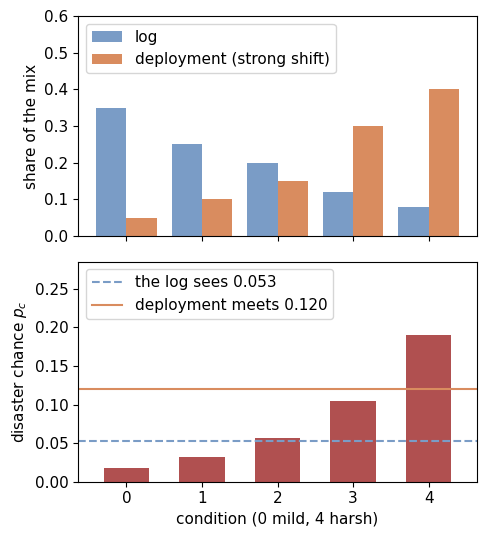

In [120]:
# Try it: where harm sits ("harm everywhere alike", "harm in harsh conditions", "harm in mild conditions"),
# the rung (0 to 0.2) and the shift ("none", "moderate", "strong").
try_profile, try_rung, try_shift = "harm in harsh conditions", 0.12, "strong"
lesson_4_profile(try_profile, try_rung, try_shift)

### Step 4.7 · 288 worlds, and how a gate is scored

A **world** combines four settings:

| Setting | Values |
|---|---|
| where harm sits | everywhere alike; in harsh conditions; in mild conditions |
| rung | 0, 0.02, 0.05, 0.08, 0.10, 0.12, 0.15, 0.20 |
| shift | none; moderate; strong |
| held-out tries $n$ | 30, 60, 120, 240 |

That makes $3 \times 8 \times 3 \times 4 = 288$ worlds, each run on 800 seeds (repetitions with fresh random numbers). A world is unsafe or harmful when its deviation is (Step 4.5). The **safe shifted worlds** are the safe ones with a moderate or strong shift.

- A gate's **deviation rate** in a world is the share of seeds in which it deviates. In an unsafe world, that is how often it breaks the tail promise; in a harmful world, the mean promise.
- A 5% promise is judged against an **allowance**: 0.05 plus three standard errors over 800 seeds.
- **Pooled gain** is the deviation rate times $\mu$, averaged over all 288 worlds. Always falling back scores 0.

In [121]:
def lesson_4_scoring():
    """The allowance, how many worlds of each kind there are, and two pooled gains worked."""
    if not lesson_4_ready("truths"):
        return
    se = math.sqrt(DELTA * (1 - DELTA) / N_SEEDS)
    allow = DELTA + 3 * se
    n_worlds = len(PROFILES) * len(RUNGS) * len(SHIFTS) * len(SIZES)
    per_rung = n_worlds // len(RUNGS)
    lesson_math(lesson_tex(r"\text{allowance} &= 0.05 + 3\sqrt{\frac{0.05 \times 0.95}{<<n>>}}", n=N_SEEDS),
                lesson_tex(r"&= 0.05 + 3 \times <<s:4>> = <<a:4>>", s=se, a=allow),
                note=lesson_text("A gate whose true rate is exactly 0.05 rarely shows more than <<a>> in a world "
                                 "with <<n>> seeds. Of the <<w>> worlds, <<u>> are unsafe, <<h>> are harmful, and "
                                 "<<s>> are safe shifted worlds.", a=allow, n=N_SEEDS, w=n_worlds,
                                 u=int(UNSAFE.sum()) * per_rung, h=int(HARMFUL.sum()) * per_rung,
                                 s=int((~UNSAFE).sum()) * len(PROFILES) * (len(SHIFTS) - 1) * len(SIZES)))

    every = [lesson_num(float(m), 3) for m in MU]
    good = [lesson_num(float(m), 3) for m in MU if m > 0]
    lesson_math(r"& \text{always deviate:}",
                *lesson_4_lines(every, r"&\quad \tfrac{1}{8}\,(", per=4, end=")"),
                lesson_tex(r"&\quad = <<g:4>>", g=float(MU.mean())),
                r"& \text{oracle:}",
                *lesson_4_lines(good, r"&\quad \tfrac{1}{8}\,(", per=4,
                                end=")" + lesson_tex(r" = <<o:4>>", o=float(np.maximum(MU, 0).mean()))),
                note="Each rung appears in the same number of worlds, so pooled gain averages over the 8 rungs. "
                     "Always deviating collects every rung's $\\mu$; the oracle deviates only where $\\mu > 0$. "
                     "The results in Step 4.11 print these same two numbers.")


lesson_4_scoring()

$$
\begin{aligned}
\text{allowance} &= 0.05 + 3\sqrt{\frac{0.05 \times 0.95}{800}} \\ &= 0.05 + 3 \times 0.0077 = 0.0731
\end{aligned}
$$

A gate whose true rate is exactly 0.05 rarely shows more than 0.073 in a world with 800 seeds. Of the 288 worlds, 144 are unsafe, 108 are harmful, and 96 are safe shifted worlds.

$$
\begin{aligned}
& \text{always deviate:} \\ &\quad \tfrac{1}{8}\,(0.500 + 0.410 + 0.275 + 0.140 \\ &\quad + 0.050 - 0.040 - 0.175 - 0.400) \\ &\quad = 0.0950 \\ & \text{oracle:} \\ &\quad \tfrac{1}{8}\,(0.500 + 0.410 + 0.275 + 0.140 \\ &\quad + 0.050) = 0.1719
\end{aligned}
$$

Each rung appears in the same number of worlds, so pooled gain averages over the 8 rungs. Always deviating collects every rung's $\mu$; the oracle deviates only where $\mu > 0$. The results in Step 4.11 print these same two numbers.

### Step 4.8 · The six claims and their kill rules

As in Parts 2 and 3, each claim has a kill rule. In plain words:

1. **Ignoring the shift breaks BCA's tail promise.** Shelved if the unweighted tail gate stays within the allowance in every unsafe world.
2. **With weights, BCA's tail gate as built keeps its promise.** Shelved if it is above the allowance in any unsafe world.
3. **The weights use shifted evidence better than the simple valid alternatives.** Shelved unless, pooled over the safe shifted worlds, the weighted tail gate's rate is at least 0.05 above both rejection sampling's and the stratified bound's.
4. **Weighted BCA's promise holds for the data in hand, unlike weighted split conformal's.** Shelved unless weighted split conformal's worst unsafe-world rate is at least 0.05 above weighted BCA's.
5. **With weights, BCA's mean gate keeps its promise.** Shelved if it is above the allowance in any harmful world.
6. **At equal harm, the weighted mean gate earns the most.** Each gate is tuned on seeds 0–399 (Step 4.13). Shelved if any other tuned gate earns at least as much on seeds 400–799.

The binding text is in the code of the next cell, which starts collapsed: expand it to read it. The cell prints the text's SHA-256 fingerprint. That fingerprint was recorded before the first run, according to the agent that ran it; the repository's history cannot confirm the timing.

In [122]:
KILL_RULES = """
Written before the first run of this notebook. Not to be changed after seeing the results.

Words used. A world is one combination of where harm sits (3 profiles), the disaster chance at deployment (the
rung: 0, 0.02, 0.05, 0.08, 0.10, 0.12, 0.15 or 0.20), how far deployment's mix of conditions differs from the
log's (no, moderate or strong shift) and how many held-out tries the gate reads (30, 60, 120 or 240), so there
are 288 worlds. A world is unsafe when more than 10% of the deviation's outcomes at deployment fall below the
fallback, harmful when its true average gain over the fallback at deployment is below zero, and safe when it is
not unsafe. Shifted worlds have a moderate or strong shift. A gate's deviation rate in a world is the share of
seeds in which it deviates. Unless a claim says otherwise, results use all 800 seeds and each gate's stated
setting. A world's allowance on a 5% rate is 0.05 + 3 * sqrt(0.05 * 0.95 / 800), about 0.073. Pooled gain is
a gate's deviation rate times the true average gain at deployment, averaged over all 288 worlds with equal
weight.

Claim 1. Ignoring the shift breaks BCA's tail promise. Shelved if the unweighted BCA tail gate's deviation rate
is within the allowance in every unsafe world.

Claim 2. With weights, BCA's tail gate as built keeps its promise under shift. Shelved if its deviation rate is
above the allowance in any unsafe world.

Claim 3. BCA's weights use shifted evidence better than the simple valid alternatives. Shelved unless, pooled
over the safe shifted worlds, the weighted BCA tail gate's deviation rate is at least 0.05 above the
rejection-sampled exact test's and at least 0.05 above the stratified exact test's.

Claim 4. Weighted BCA's promise holds for the data in hand, unlike weighted split conformal's. Shelved unless
weighted split conformal's highest deviation rate over the unsafe worlds is at least 0.05 above the weighted BCA
tail gate's highest.

Claim 5. With weights, BCA's mean gate keeps its promise under shift. Shelved if its deviation rate is above the
allowance in any harmful world.

Claim 6. At equal harm, the weighted BCA mean gate earns the most. On seeds 0-399, each tunable gate takes the
setting from its fixed grid with the highest pooled gain among settings whose deviation rate is at most 0.05 in
every harmful world; a gate with no such setting never deviates. Shelved if, on seeds 400-799, any other tuned
gate's pooled gain is at least the tuned weighted BCA mean gate's.
"""
print("Kill rules fingerprint (SHA-256):", hashlib.sha256(KILL_RULES.encode()).hexdigest())

Kill rules fingerprint (SHA-256): e32e04d79b52e3a234e2576ef7cddf9c7b667436315b58330fe827b2dafff44e


### Step 4.9 · The run

For each seed, the next cell draws 240 tries once: each try's condition (from the log's mix), its disaster coin, its usual gain and its rejection-sampling coin. It also draws BCA's 10,000 random weightings once (the tail gate uses the first 1,000). Every world reuses these draws:

- a world with $n$ tries reads the first $n$;
- a try is a disaster when its coin falls below its condition's chance $p_c$, so a higher rung only adds disasters.

So differences between worlds come from the worlds, not from luck. This cell takes most of the notebook's running time. The cell after it turns each gate's records into decisions: `DEC[gate]` holds a yes or no for every seed and world.

In [123]:
FIELDS = ("bad", "wgood", "wsum", "wsq", "kept", "kept_bad", "neg_w", "neg_u", "neg_r", "m_w", "se_w", "m_u")
SHIFT_OF = np.broadcast_to(np.arange(len(SHIFTS)), WORLD[:3]).reshape(-1)    # shift of each flattened world

def run_seed(seed):
    rng = np.random.default_rng([ROOT_SEED, STREAM, seed])
    cond = rng.choice(LOG_MIX.size, N_MAX, p=LOG_MIX)            # each try's condition, from the log's mix
    u, v = rng.random((2, N_MAX))                                 # disaster coin; rejection-sampling coin
    z = rng.standard_normal(N_MAX)
    e = rng.standard_exponential((MEAN_DRAWS, N_MAX + 1))         # BCA's random weights; the last column is the extra one
    gain = np.where(u < P_K[..., cond], DISASTER, np.clip(CENTER + SPREAD * z, LO, HI))   # (profile, rung, shift, try)
    good = gain >= 0
    w = WEIGHT[:, cond]                                           # (shift, try)
    keep = v < w / WMAX[:, None]
    rec = {f: np.zeros(WORLD) for f in FIELDS}
    rec["cross"] = np.zeros((len(TAIL_SHARES),) + WORLD)
    rec["n_k"] = np.zeros(WORLD + (LOG_MIX.size,))
    rec["b_k"] = np.zeros(WORLD + (LOG_MIX.size,))
    for zi, n in enumerate(SIZES):
        g, ok, kn = gain[..., :n], good[..., :n], keep[:, :n]
        W = w[None, None, :, :n]                                  # broadcast over profile and rung
        flat = lambda a: np.broadcast_to(a, g.shape).reshape(-1, n).T     # (tries, worlds)
        rec["bad"][..., zi] = (~ok).sum(-1)
        rec["wgood"][..., zi] = (W * ok).sum(-1)
        rec["wsum"][..., zi] = W.sum(-1)
        rec["wsq"][..., zi] = (W ** 2).sum(-1)
        rec["kept"][..., zi] = kn.sum(-1)[None, None]
        rec["kept_bad"][..., zi] = (kn[None, None] & ~ok).sum(-1)
        onehot = cond[:n] == np.arange(LOG_MIX.size)[:, None]    # (condition, try)
        rec["n_k"][..., zi, :] = onehot.sum(-1)
        rec["b_k"][..., zi, :] = (~ok[..., None, :] & onehot).sum(-1)
        m_w = (W * g).sum(-1) / W.sum(-1)
        rec["m_w"][..., zi] = m_w
        rec["se_w"][..., zi] = np.sqrt((W ** 2 * (g - m_w[..., None]) ** 2).sum(-1)) / W.sum(-1)
        rec["m_u"][..., zi] = g.mean(-1)
        # Mean gates: count the weighted averages below 0. A weighted average is below 0 exactly when its
        # weighted sum is, because the weights are positive.
        en, extra = e[:, :n], e[:, N_MAX]
        for field, x, extra_mass in (("neg_w", W * g, WBAR[SHIFT_OF] * FLOOR),
                                     ("neg_u", g, np.full(SHIFT_OF.size, FLOOR)),
                                     ("neg_r", kn[None, None] * g, np.full(SHIFT_OF.size, FLOOR))):
            sums = en @ flat(x) + extra[:, None] * extra_mass[None, :]
            rec[field][..., zi] = (sums < 0).sum(axis=0).reshape(WORLD[:3])
        # Weighted tail gate as built: a draw crosses at or below 0 when the mass on tries that beat the fallback
        # reaches 1 - share of the total, the extra worst-case weight included.
        et, extra_t = e[:TAIL_DRAWS, :n], e[:TAIL_DRAWS, N_MAX]
        s_good = et @ flat(W * ok)
        s_all = (et @ w[:, :n].T)[:, SHIFT_OF]
        for k, share in enumerate(TAIL_SHARES):
            rhs = (1 - share) * (s_all + extra_t[:, None] * WBAR[SHIFT_OF][None, :])
            rec["cross"][k][..., zi] = (s_good >= rhs).sum(axis=0).reshape(WORLD[:3])
    return rec

records = [run_seed(s) for s in range(N_SEEDS)]
R = {f: np.stack([r[f] for r in records]) for f in records[0]}     # axes: seed, [knob,] profile, rung, shift, size
pairs = np.unique(np.stack([R["b_k"].ravel(), R["n_k"].ravel()]).astype(int), axis=1)
bound = dict(zip(map(tuple, pairs.T), cp_upper(pairs[0], pairs[1], STRATA_LEVEL)))
U = np.vectorize(lambda b, n: bound[(int(b), int(n))])(R["b_k"], R["n_k"])
STRATA_BOUND = (U * np.array([DEPLOY_MIX[s] for s in SHIFTS])[:, None, :]).sum(-1)   # bound on deployment's bad share
print(f"{N_SEEDS} seeds in {time.perf_counter() - START:.0f} s")

800 seeds in 73 s


In [124]:
TAIL_GATES = ["BCA tail, unweighted", "BCA tail, weighted", "weighted split conformal", "rejection-sampled exact",
              "stratified exact"]
LEVEL_GATES = ["BCA mean, unweighted", "BCA mean, weighted", "rejection-sampled BCA mean", "weighted t-test"]
MARGIN_GATES = ["weighted average", "plain average"]
GATES = ["never deviate", "always deviate"] + TAIL_GATES + LEVEL_GATES + MARGIN_GATES + ["oracle"]
SIZE_B = np.array(SIZES)[None, None, None, None, :]
WBAR_B = WBAR[None, None, None, :, None]
NEED = math.ceil(Fraction(str(CONFIDENCE)) * TAIL_DRAWS)

def accept(gate, knob=None):
    """Which (seed, world) cases a gate deviates in, at its stated setting or at knob."""
    share = TAIL if knob is None else knob
    level = DELTA if knob is None else knob
    margin = 0.0 if knob is None else knob
    shape = R["bad"].shape
    if gate == "never deviate":
        return np.zeros(shape, bool)
    if gate == "always deviate":
        return np.ones(shape, bool)
    if gate == "oracle":
        return np.broadcast_to((MU > 0)[None, None, :, None, None], shape).copy()
    if gate == "BCA tail, unweighted":
        return R["bad"] <= np.array([allowed_below(n, share) for n in SIZES])[None, None, None, None, :]
    if gate == "BCA tail, weighted":
        return (R["wgood"] >= (1 - share) * R["wsum"] - 1e-9) & (R["cross"][:, TAIL_SHARES.index(share)] >= NEED)
    if gate == "weighted split conformal":
        return R["wgood"] >= (1 - share) * (R["wsum"] + WBAR_B)
    if gate == "rejection-sampled exact":
        return R["kept_bad"] <= by_count(lambda k: allowed_below(k, share))[R["kept"].astype(int)]
    if gate == "stratified exact":
        return STRATA_BOUND <= share
    if gate == "BCA mean, unweighted":
        return R["neg_u"] <= limit(level)
    if gate == "BCA mean, weighted":
        return R["neg_w"] <= limit(level)
    if gate == "rejection-sampled BCA mean":
        return R["neg_r"] <= limit(level)
    if gate == "weighted t-test":
        tq = np.array([t_upper(level, n - 1) for n in SIZES])[None, None, None, None, :]
        return R["m_w"] - tq * R["se_w"] > 0
    if gate == "weighted average":
        return R["m_w"] > margin
    if gate == "plain average":
        return R["m_u"] > margin
    raise KeyError(gate)

DEC = {g: accept(g) for g in GATES}
ALL = np.arange(N_SEEDS)
SHIFTED = np.broadcast_to((np.arange(len(SHIFTS)) > 0)[None, None, :, None], WORLD)
UNSAFE_W = np.broadcast_to(UNSAFE[None, :, None, None], WORLD)
HARMFUL_W = np.broadcast_to(HARMFUL[None, :, None, None], WORLD)
SAFE_SHIFTED = ~UNSAFE_W & SHIFTED
GAIN_W = np.broadcast_to(MU[None, :, None, None], WORLD)
ALLOW = DELTA + 3 * math.sqrt(DELTA * (1 - DELTA) / N_SEEDS)

def rate(d, seeds=ALL):
    return d[seeds].mean(axis=0)

def pooled_gain(d, seeds=ALL):
    return (rate(d, seeds) * GAIN_W).mean()

ORACLE_GAIN = pooled_gain(DEC["oracle"])

### Step 4.10 · One decision, worked by hand

Both tail gates read the same 120 tries in a world where the log hides harm: harm in harsh conditions, rung 0.12, strong shift (Step 4.6). The cell replays seed 1's random numbers as the run drew them and checks every count against the stored results. Seed 1 is one where the two gates disagree; the last line gives each gate's rate over all 800 seeds.

The unweighted gate counts $b$, the tries below the fallback, and says yes when $b \le x(n)$ (Step A.7). The weighted gate needs two things. First, the tries at or above the fallback must carry at least $1-\alpha = 0.9$ of the weight:

$$
\frac{\sum_i w_i\,[g_i \ge 0]}{\sum_i w_i} \ge 0.9
$$

Here $[g_i \ge 0]$ is 1 when try $i$ is at or above the fallback, else 0. Second, at least 950 of the 1,000 draws must cross at or below the fallback. Draw $m$, with random weights $E^{(m)}_i$, does so when

$$
\begin{aligned}
& \sum_i E^{(m)}_i\, w_i\, [g_i \ge 0] \\
&\quad \ge (1-\alpha)\Big(\sum_i E^{(m)}_i\, w_i + E^{(m)}_{n+1}\,\bar w\Big)
\end{aligned}
$$

Together they say that BCA's threshold $\lambda_{\mathrm{BCA}} = \max(\hat\lambda, \lambda_\beta)$ from Step A.4, computed with the weights on each try's shortfall $-g_i$, is at most 0: the first condition is $\hat\lambda \le 0$, the second $\lambda_\beta \le 0$.

In [125]:
def lesson_4_replay(seed):
    """One seed's random numbers, drawn exactly as run_seed draws them: same generator, same calls, same order."""
    gen = np.random.default_rng([ROOT_SEED, STREAM, seed])
    cond = gen.choice(LOG_MIX.size, N_MAX, p=LOG_MIX)
    u, v = gen.random((2, N_MAX))
    z = gen.standard_normal(N_MAX)
    e = gen.standard_exponential((MEAN_DRAWS, N_MAX + 1))
    return cond, u, v, z, e


def lesson_4_tail_case(seed, profile, rung, shift, tries):
    """Both tail gates on one seed's tries in one world, worked line by line and checked against the run."""
    if not lesson_4_ready("run"):
        return
    for good, what in [
            (lesson_4_holds(lambda: lesson_4_number(seed) and float(seed).is_integer() and 0 <= seed < N_SEEDS),
             f"a seed: a whole number from 0 to {N_SEEDS - 1}"),
            (lesson_4_holds(lambda: isinstance(profile, str) and profile in PROFILES),
             "where harm sits: " + lesson_4_quoted(PROFILES) + ", in quotes"),
            (lesson_4_holds(lambda: lesson_4_number(rung) and float(rung) in RUNGS),
             "a rung: " + ", ".join(f"{r:g}" for r in RUNGS[:-1]) + f" or {RUNGS[-1]:g}"),
            (lesson_4_holds(lambda: isinstance(shift, str) and shift in SHIFTS),
             "a shift: " + lesson_4_quoted(SHIFTS) + ", in quotes"),
            (lesson_4_holds(lambda: lesson_4_number(tries) and float(tries) in SIZES),
             "a number of tries: " + ", ".join(str(n) for n in SIZES[:-1]) + f" or {SIZES[-1]}")]:
        if not good:
            lesson_show(f"Choose {what}.")
            return
    seed, rung, tries = int(seed), float(rung), int(tries)
    pi, ri, si, zi = PROFILES.index(profile), RUNGS.index(rung), SHIFTS.index(shift), SIZES.index(tries)
    world = (seed, pi, ri, si, zi)
    cond, u, v, z, e = lesson_4_replay(seed)
    n, c = tries, cond[:tries]
    gain = np.where(u[:n] < P_K[pi, ri, si, c], DISASTER, np.clip(CENTER + SPREAD * z[:n], LO, HI))
    below = gain < 0
    w = WEIGHT[si, c]
    wsum, wbelow = float(w.sum()), float(w[below].sum())
    # The tries, condition by condition.
    rows = []
    for k in range(LOG_MIX.size):
        here = c == k
        rows.append([lesson_4_names[k], int(here.sum()), int((below & here).sum()), lesson_txt(WEIGHT[si, k], 3),
                     lesson_pct(w[here].sum() / wsum, 1, latex=False)])
    b = int(below.sum())
    rows.append(["all", n, b, "", "100.0%"])
    lesson_show(f"**The {n} tries of seed {seed}, by condition.**")
    lesson_table(["Condition", "Tries", "Below the fallback", "Weight $w_c$", "Share of all weight"], rows)
    # Unweighted gate: the exact form of Step A.7.
    x = allowed_below(n, TAIL)
    cdf = [sum(math.comb(n, j) * TAIL ** j * (1 - TAIL) ** (n - j) for j in range(t + 1)) for t in (x, x + 1)]
    unweighted = b <= x
    lesson_show("**Unweighted gate.**")
    lesson_math(lesson_tex(r"& b = <<b>> \text{ of } n = <<n>> \text{ tries below the fallback}", b=b, n=n),
                lesson_tex(r"& P(\mathrm{Binomial}(<<n>>, 0.1) \le <<x>>) = <<p:4>>", n=n, x=x, p=cdf[0]),
                lesson_tex(r"& P(\mathrm{Binomial}(<<n>>, 0.1) \le <<y>>) = <<q:4>>", n=n, y=x + 1, q=cdf[1]),
                lesson_tex(r"& <<p:4>> \le 0.05 < <<q:4>>, \text{ so } x(<<n>>) = <<x>>", n=n, x=x, p=cdf[0], q=cdf[1]),
                lesson_tex(r"& b = <<b>> " + (r"\le" if unweighted else ">") + r" x(<<n>>) = <<x>> \;\Rightarrow\; "
                           + (r"\text{yes: deviate}" if unweighted else r"\text{no: fall back}"), b=b, n=n, x=x))
    # Weighted gate, condition 1: the plain weighted share (BCA's weighted quantile at or below the fallback).
    parts = [(int((below & (c == k)).sum()), WEIGHT[si, k]) for k in range(LOG_MIX.size) if (below & (c == k)).any()]
    below_terms = [lesson_tex(r"<<a>> \times <<w>>", a=a, w=wk) for a, wk in parts]
    share_ok = wsum - wbelow >= (1 - TAIL) * wsum - 1e-9
    lesson_show("**Weighted gate, first condition:** the weighted share at or above the fallback.")
    heavier = wbelow / wsum > b / n
    if below_terms:
        below_lines = lesson_4_lines(below_terms, r"\sum_i w_i\,[g_i < 0] &= ") + [lesson_tex(r"&= <<x>>", x=wbelow)]
    else:
        below_lines = [r"\sum_i w_i\,[g_i < 0] &= 0"]
    if b == 0:
        share_note = lesson_text("**So:** none of the <<n>> tries falls below the fallback.", n=n)
    else:
        share_note = lesson_text("**So:** <<b>> of <<n>> tries (<<p:%1>>) <<f>> below the fallback, <<j>> <<t>> "
                                 "<<q:%1>> of the weight<<y>>.", b=b, n=n, p=b / n, q=wbelow / wsum,
                                 f="falls" if b == 1 else "fall", t="it carries" if b == 1 else "they carry",
                                 j="but" if heavier else "and",
                                 y=(": tries from conditions that deployment meets more often than the log count "
                                    "for more") if heavier else "")
    lesson_math(*below_lines,
                lesson_tex(r"\sum_i w_i &= <<s>>", s=wsum),
                lesson_tex(r"\frac{\sum_i w_i\,[g_i \ge 0]}{\sum_i w_i} &= 1 - \frac{<<x>>}{<<s>>} = <<r>>", x=wbelow,
                           s=wsum, r=1 - wbelow / wsum),
                (r"&\ge" if share_ok else "&<") + r" 0.90 \;\Rightarrow\; "
                + (r"\text{passes}" if share_ok else r"\text{fails}"),
                note=share_note)
    # Weighted gate, condition 2: the 1,000 draws of weighted BCA (the extra weight is the last column).
    et, extra = e[:TAIL_DRAWS, :n], e[:TAIL_DRAWS, N_MAX]
    s_good, s_all = et @ (w * ~below), et @ w
    crosses = s_good >= (1 - TAIL) * (s_all + extra * WBAR[si])
    n_cross = int(crosses.sum())
    weighted = bool(share_ok and n_cross >= NEED)
    rhs = (1 - TAIL) * (s_all[0] + extra[0] * WBAR[si])
    if n_cross >= NEED:
        draws_note = "**So:** <<k>> of the 1,000 draws cross, at least the <<m>> needed."
    elif n_cross > 0:
        draws_note = ("**So:** each draw weights the tries at random, so <<k>> of the 1,000 draws <<v>> here, "
                      "fewer than the <<m>> needed.")
    else:
        draws_note = "**So:** no draw crosses, and the gate needs <<m>>."
    lesson_show("**Weighted gate, second condition:** draw 1, then all 1,000 draws.")
    lesson_math(lesson_tex(r"& \textstyle\sum_i E^{(1)}_i\, w_i\, [g_i \ge 0] = <<g>>", g=s_good[0]),
                r"& 0.9\,\big(\textstyle\sum_i E^{(1)}_i\, w_i + E^{(1)}_{n+1}\,\bar w\big)",
                lesson_tex(r"&\quad = 0.9 \times (<<a>> + <<x>> \times <<v>>)", a=s_all[0], x=extra[0], v=WBAR[si]),
                lesson_tex(r"&\quad = 0.9 \times <<t>> = <<r>>", t=s_all[0] + extra[0] * WBAR[si], r=rhs),
                lesson_tex(r"& <<g>> " + (r"\ge" if crosses[0] else "<") + r" <<r>>: \text{ draw 1 "
                           + ("crosses" if crosses[0] else "does not cross") + "}", g=s_good[0], r=rhs),
                lesson_tex(r"& \text{draws that cross} = <<k>> \text{ of } 1{,}000", k=n_cross),
                lesson_tex(r"& <<k>> " + (r"\ge" if n_cross >= NEED else "<") + r" <<m>> \;\Rightarrow\; "
                           + (r"\text{passes}" if n_cross >= NEED else r"\text{fails}"), k=n_cross, m=NEED),
                note=lesson_text(draws_note, k=n_cross, m=NEED, v="crosses" if n_cross == 1 else "cross"))
    # Everything above must match what the run stored for this seed and world.
    lesson_check(b == R["bad"][world], "tries below the fallback")
    lesson_check(abs((wsum - wbelow) - R["wgood"][world]) < 1e-9 and abs(wsum - R["wsum"][world]) < 1e-9,
                 "weights of the tries")
    lesson_check(n_cross == R["cross"][(seed, TAIL_SHARES.index(TAIL)) + world[1:]], "draws that cross")
    lesson_check(unweighted == DEC["BCA tail, unweighted"][world], "the unweighted gate's decision")
    lesson_check(weighted == DEC["BCA tail, weighted"][world], "the weighted gate's decision")
    lesson_show(lesson_text(
        "**So:** the unweighted gate says <<a>> and the weighted gate says <<b>>, as the run decided. At deployment, "
        "this world's share below the fallback is <<s:4>>, <<o>> 0.10, so the tail promise calls for <<t>>. Over "
        "all <<n>> seeds of this world, the unweighted gate deviated in <<u>> of them and the weighted gate in <<v>>.",
        a="yes" if unweighted else "no", b="yes" if weighted else "no", s=BAD[ri],
        o="above" if UNSAFE[ri] else "at or below", t="falling back" if UNSAFE[ri] else "deviating",
        n=N_SEEDS, u=float(rate(DEC["BCA tail, unweighted"])[world[1:]]),
        v=float(rate(DEC["BCA tail, weighted"])[world[1:]])))

In [126]:
# Try it: the seed (0 to 799), where harm sits, the rung, the shift and the number of tries (30, 60, 120 or 240).
try_seed, try_profile, try_rung, try_shift, try_tries = 1, "harm in harsh conditions", 0.12, "strong", 120
lesson_4_tail_case(try_seed, try_profile, try_rung, try_shift, try_tries)

**The 120 tries of seed 1, by condition.**

| Condition | Tries | Below the fallback | Weight $w_c$ | Share of all weight |
|---|---|---|---|---|
| 0 (mild) | 38 | 0 | 0.143 | 4.8% |
| 1 | 33 | 0 | 0.400 | 11.6% |
| 2 | 27 | 3 | 0.750 | 17.8% |
| 3 | 14 | 0 | 2.500 | 30.7% |
| 4 (harsh) | 8 | 3 | 5.000 | 35.1% |
| all | 120 | 6 |  | 100.0% |

**Unweighted gate.**

$$
\begin{aligned}
& b = 6 \text{ of } n = 120 \text{ tries below the fallback} \\ & P(\mathrm{Binomial}(120, 0.1) \le 6) = 0.0382 \\ & P(\mathrm{Binomial}(120, 0.1) \le 7) = 0.0784 \\ & 0.0382 \le 0.05 < 0.0784, \text{ so } x(120) = 6 \\ & b = 6 \le x(120) = 6 \;\Rightarrow\; \text{yes: deviate}
\end{aligned}
$$

**Weighted gate, first condition:** the weighted share at or above the fallback.

$$
\begin{aligned}
\sum_i w_i\,[g_i < 0] &= 3 \times 0.750 + 3 \times 5.000 \\ &= 17.250 \\ \sum_i w_i &= 113.879 \\ \frac{\sum_i w_i\,[g_i \ge 0]}{\sum_i w_i} &= 1 - \frac{17.250}{113.879} = 0.849 \\ &< 0.90 \;\Rightarrow\; \text{fails}
\end{aligned}
$$

**So:** 6 of 120 tries (5.0%) fall below the fallback, but they carry 15.1% of the weight: tries from conditions that deployment meets more often than the log count for more.

**Weighted gate, second condition:** draw 1, then all 1,000 draws.

$$
\begin{aligned}
& \textstyle\sum_i E^{(1)}_i\, w_i\, [g_i \ge 0] = 74.146 \\ & 0.9\,\big(\textstyle\sum_i E^{(1)}_i\, w_i + E^{(1)}_{n+1}\,\bar w\big) \\ &\quad = 0.9 \times (80.284 + 1.643 \times 2.910) \\ &\quad = 0.9 \times 85.065 = 76.559 \\ & 74.146 < 76.559: \text{ draw 1 does not cross} \\ & \text{draws that cross} = 124 \text{ of } 1{,}000 \\ & 124 < 950 \;\Rightarrow\; \text{fails}
\end{aligned}
$$

**So:** each draw weights the tries at random, so 124 of the 1,000 draws cross here, fewer than the 950 needed.

**So:** the unweighted gate says yes and the weighted gate says no, as the run decided. At deployment, this world's share below the fallback is 0.1255, above 0.10, so the tail promise calls for falling back. Over all 800 seeds of this world, the unweighted gate deviated in 0.426 of them and the weighted gate in 0.014.

### Step 4.11 · Results

**How to read it.** One row per gate at its stated setting (as in Step 4.3: 95% sure, at most 10% below the fallback, averages above 0), over all 800 seeds.
- **worst unsafe:** the highest deviation rate over the 144 unsafe worlds. A gate that keeps the tail promise stays near or below 0.05.
- **safe, shifted:** the deviation rate pooled over the 96 safe worlds with a moderate or strong shift. Higher means the gate makes more use of good evidence.
- **worst harmful:** the highest deviation rate over the 108 harmful worlds. A gate that keeps the mean promise stays near or below 0.05.
- **gain:** pooled gain per decision; **of oracle:** that gain as a share of the oracle's.

The oracle answers the mean question, so it deviates at rung 0.10, which is unsafe but good; its worst unsafe rate of 1.000 is expected.

In [127]:
print(f"{'gate':28}{'worst unsafe':>13}{'safe, shifted':>15}{'worst harmful':>15}{'gain':>8}{'of oracle':>11}")
for g in GATES:
    r = rate(DEC[g])
    print(f"{g:28}{r[UNSAFE_W].max():13.3f}{r[SAFE_SHIFTED].mean():15.3f}{r[HARMFUL_W].max():15.3f}"
          f"{pooled_gain(DEC[g]):8.4f}{pooled_gain(DEC[g]) / ORACLE_GAIN:11.0%}")

gate                         worst unsafe  safe, shifted  worst harmful    gain  of oracle
never deviate                       0.000          0.000          0.000  0.0000         0%
always deviate                      1.000          1.000          1.000  0.0950        55%
BCA tail, unweighted                0.899          0.550          0.736  0.1106        64%
BCA tail, weighted                  0.043          0.336          0.025  0.0838        49%
weighted split conformal            0.388          0.750          0.266  0.1423        83%
rejection-sampled exact             0.036          0.190          0.021  0.0644        37%
stratified exact                    0.000          0.000          0.000  0.0023         1%
BCA mean, unweighted                0.986          0.647          0.936  0.1253        73%
BCA mean, weighted                  0.119          0.415          0.044  0.0982        57%
rejection-sampled BCA mean          0.119          0.261          0.026  0.0789        46%

**What to notice.**
- **Ignoring the shift breaks both promises.** The unweighted tail gate reaches 0.899 in an unsafe world, and the unweighted mean gate 0.936 in a harmful one.
- **With weights, both BCA gates stay near 0.05:** 0.043 for the tail gate in unsafe worlds, and 0.044 for the mean gate in harmful worlds. The weighted mean gate's 0.119 in unsafe worlds comes from rung 0.10, where a mean gate may deviate.
- **Weighted split conformal** reaches 0.388 in an unsafe world.
- **The valid gates differ in how often they say yes** in safe shifted worlds: 0.336 for the weighted tail gate, 0.190 for rejection sampling and 0.000 for the stratified bound.

### Step 4.12 · Verdicts

The next cell applies each kill rule to the results. Each line names the claim, gives the numbers its rule compares, and ends in ALIVE or SHELVED. Claim 6 uses the tuning that Step 4.13 explains.

In [128]:
verdict = lambda alive: "ALIVE" if alive else "SHELVED"
r1 = rate(DEC["BCA tail, unweighted"])[UNSAFE_W]
print(f"Claim 1, ignoring the shift breaks the tail promise: worst unsafe-world rate {r1.max():.3f}; "
      f"unsafe worlds above the allowance ({ALLOW:.3f}): {(r1 > ALLOW).sum()} -> {verdict((r1 > ALLOW).any())}")
r2 = rate(DEC["BCA tail, weighted"])[UNSAFE_W]
print(f"Claim 2, weighted BCA keeps the tail promise: worst unsafe-world rate {r2.max():.3f}; "
      f"above the allowance: {(r2 > ALLOW).sum()} -> {verdict(not (r2 > ALLOW).any())}")
acc = {g: rate(DEC[g])[SAFE_SHIFTED].mean() for g in ("BCA tail, weighted", "rejection-sampled exact", "stratified exact")}
c3 = acc["BCA tail, weighted"] - max(acc["rejection-sampled exact"], acc["stratified exact"]) >= 0.05
print(f"Claim 3, weights use shifted evidence better: deviation rate in safe shifted worlds "
      f"{acc['BCA tail, weighted']:.3f}, against rejection-sampled {acc['rejection-sampled exact']:.3f} "
      f"and stratified {acc['stratified exact']:.3f} -> {verdict(c3)}")
w4 = {g: rate(DEC[g])[UNSAFE_W].max() for g in ("weighted split conformal", "BCA tail, weighted")}
c4 = w4["weighted split conformal"] - w4["BCA tail, weighted"] >= 0.05
print(f"Claim 4, a promise for the data in hand: worst unsafe-world rate {w4['weighted split conformal']:.3f} for "
      f"weighted split conformal, against {w4['BCA tail, weighted']:.3f} for weighted BCA -> {verdict(c4)}")
r5 = rate(DEC["BCA mean, weighted"])[HARMFUL_W]
print(f"Claim 5, weighted BCA's mean gate keeps its promise: worst harmful-world rate {r5.max():.3f}; "
      f"above the allowance: {(r5 > ALLOW).sum()} -> {verdict(not (r5 > ALLOW).any())}")

TUNABLE = {g: TAIL_SHARES for g in TAIL_GATES} | {g: LEVELS for g in LEVEL_GATES} | {g: MARGINS for g in MARGIN_GATES}
FRONTIER, TUNED = {}, {}
for g, grid in TUNABLE.items():
    points = []
    for k in grid:
        d = accept(g, k)
        points.append((k, rate(d, TUNE_SEEDS)[HARMFUL_W].max(), pooled_gain(d, TUNE_SEEDS), d))
    FRONTIER[g] = points
    qualified = [p for p in points if p[1] <= DELTA]
    if qualified:
        k, _, tune_gain, d = max(qualified, key=lambda p: p[2])
        TUNED[g] = (k, tune_gain, pooled_gain(d, EVAL_SEEDS), rate(d, EVAL_SEEDS)[HARMFUL_W].max())
    else:
        TUNED[g] = (None, 0.0, 0.0, 0.0)
best_rival = max((g for g in TUNED if g != "BCA mean, weighted"), key=lambda g: TUNED[g][2])
c6 = TUNED["BCA mean, weighted"][2] > TUNED[best_rival][2]
print(f"Claim 6, at equal harm: tuned weighted BCA mean gate gains {TUNED['BCA mean, weighted'][2]:.4f}; best tuned "
      f"rival {best_rival} gains {TUNED[best_rival][2]:.4f} -> {verdict(c6)}")

Claim 1, ignoring the shift breaks the tail promise: worst unsafe-world rate 0.899; unsafe worlds above the allowance (0.073): 17 -> ALIVE
Claim 2, weighted BCA keeps the tail promise: worst unsafe-world rate 0.043; above the allowance: 0 -> ALIVE
Claim 3, weights use shifted evidence better: deviation rate in safe shifted worlds 0.336, against rejection-sampled 0.190 and stratified 0.000 -> ALIVE
Claim 4, a promise for the data in hand: worst unsafe-world rate 0.388 for weighted split conformal, against 0.043 for weighted BCA -> ALIVE
Claim 5, weighted BCA's mean gate keeps its promise: worst harmful-world rate 0.044; above the allowance: 0 -> ALIVE
Claim 6, at equal harm: tuned weighted BCA mean gate gains 0.0975; best tuned rival weighted split conformal gains 0.0923 -> ALIVE


**What to notice.**
- All six claims are alive.
- Claim 1: in 17 unsafe worlds, the unweighted tail gate is above the allowance of 0.073. Claim 2: the weighted tail gate never is (worst 0.043).
- Claim 6 is alive only narrowly: 0.0975 against 0.0923 for weighted split conformal.

### Step 4.13 · Equal harm: every gate tuned to the same safety

Each gate has one knob. For the tail gates it is the share allowed below the fallback (0.5 down to 0.05; stated 0.10). For the mean gates and the t-test it is the level (0.5 down to 0.001; the stated 0.05 means 95% sure). For the two averages it is a margin the average must clear (0 up to 1; stated 0).

- **Tuning, on seeds 0–399:** keep the settings whose worst harmful-world rate is at most 0.05, and take the one with the highest pooled gain. A gate with no such setting never deviates.
- **Scoring, on seeds 400–799:** the tuned setting's pooled gain on fresh seeds.

**How to read it.** The chart shows every setting of every gate on seeds 0–399: its worst harmful-world rate (left to right; the dashed line is 0.05) and its pooled gain (up). The table lists each gate's chosen setting and its gain on both halves, best first.

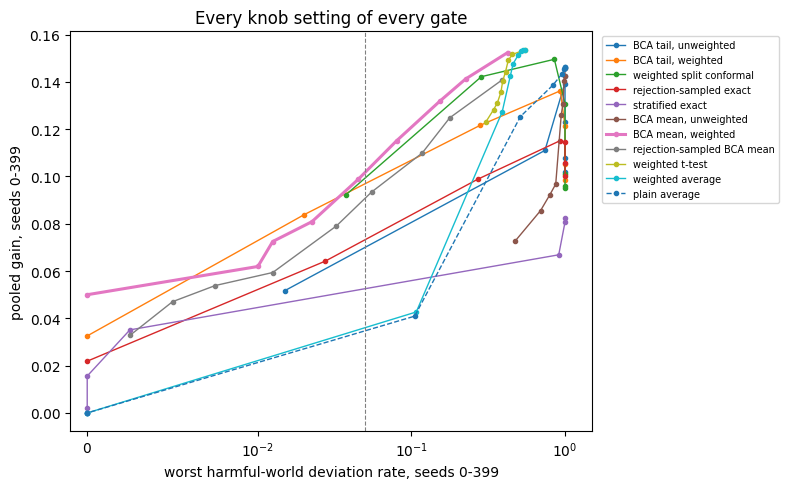

gate                         chosen knob  gain, 0-399  gain, 400-799  worst harmful, 400-799
BCA mean, weighted                  0.05       0.0988         0.0975                   0.052
weighted split conformal            0.05       0.0923         0.0923                   0.048
BCA tail, weighted                   0.1       0.0838         0.0838                   0.030
rejection-sampled BCA mean          0.05       0.0791         0.0788                   0.025
rejection-sampled exact              0.1       0.0642         0.0646                   0.018
BCA tail, unweighted                0.05       0.0517         0.0536                   0.020
stratified exact                     0.2       0.0351         0.0358                   0.005
BCA mean, unweighted                none       0.0000         0.0000                   0.000
weighted t-test                     none       0.0000         0.0000                   0.000
weighted average                    0.75       0.0000         0.0000  

In [129]:
fig, ax = plt.subplots(figsize=(8, 5))
for i, (g, points) in enumerate(FRONTIER.items()):
    ax.plot([p[1] for p in points], [p[2] for p in points], marker="o", ms=3,
            lw=2.2 if g == "BCA mean, weighted" else 1, color=f"C{i % 10}", ls="-" if i < 10 else "--", label=g)
ax.axvline(DELTA, color="grey", ls="--", lw=0.8)
ax.set_xscale("symlog", linthresh=0.01)
ax.set_xlim(-0.001, 1.5)
ax.set_xlabel("worst harmful-world deviation rate, seeds 0-399")
ax.set_ylabel("pooled gain, seeds 0-399")
ax.set_title("Every knob setting of every gate")
ax.legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1.0))
fig.tight_layout(); plt.show()

print(f"{'gate':28}{'chosen knob':>12}{'gain, 0-399':>13}{'gain, 400-799':>15}{'worst harmful, 400-799':>24}")
for g, (k, tune_gain, eval_gain, eval_harm) in sorted(TUNED.items(), key=lambda kv: -kv[1][2]):
    print(f"{g:28}{'none' if k is None else str(k):>12}{tune_gain:13.4f}{eval_gain:15.4f}{eval_harm:24.3f}")

**What to notice.**
- **The weighted mean gate leads, narrowly:** 0.0975 on seeds 400–799, against 0.0923 for weighted split conformal tuned to a 0.05 share. It led on the tuning seeds too: 0.0988 against 0.0923.
- Its worst harmful-world rate on the fresh seeds was 0.052, within sampling noise of 0.05.
- The unweighted mean gate, the weighted t-test and the two averages had no useful safe setting: their tuned gain is 0.0000.
- The tuning used toy worlds whose truth is known. A real deployment cannot tune that way.

### Step 4.14 · Where the differences come from

*Deeper: skip on a first read.*

**How to read it.** The next printout splits the same measures three ways: by shift (none, moderate, strong), by number of tries (30 to 240), and by where harm sits (strong shift only). Its last table compares, for each shift and number of tries, the effective number of tries (Step 4.2) with the number that rejection sampling keeps, both averaged over seeds.

In [130]:
key = TAIL_GATES + LEVEL_GATES + MARGIN_GATES
def by(fn, label, columns, fmt):
    print(label)
    print(f"{'gate':28}" + "".join(f"{c:>12}" for c in columns))
    for g in key:
        print(f"{g:28}" + "".join(f"{v:{fmt}}" for v in fn(rate(DEC[g]))))
    print()

by(lambda r: [r[:, :, s][UNSAFE_W[:, :, s]].max() for s in range(len(SHIFTS))],
   "Worst unsafe-world deviation rate, by shift", SHIFTS, "12.3f")
by(lambda r: [r[:, :, s][~UNSAFE_W[:, :, s]].mean() for s in range(len(SHIFTS))],
   "Deviation rate pooled over safe worlds, by shift", SHIFTS, "12.3f")
by(lambda r: [r[:, :, s][HARMFUL_W[:, :, s]].max() for s in range(len(SHIFTS))],
   "Worst harmful-world deviation rate, by shift", SHIFTS, "12.3f")
by(lambda r: [(r * GAIN_W)[:, :, s].mean() for s in range(len(SHIFTS))],
   "Pooled gain, by shift", SHIFTS, "12.4f")
by(lambda r: [r[..., z][SAFE_SHIFTED[..., z]].mean() for z in range(len(SIZES))],
   "Deviation rate pooled over safe shifted worlds, by number of tries", SIZES, "12.3f")
by(lambda r: [(r * GAIN_W)[..., z].mean() for z in range(len(SIZES))],
   "Pooled gain, by number of tries", SIZES, "12.4f")
by(lambda r: [(r * GAIN_W)[p, :, 2].mean() for p in range(len(PROFILES))],
   "Pooled gain under strong shift, by where harm sits", ("alike", "harsh", "mild"), "12.4f")

ess = R["wsum"] ** 2 / R["wsq"]
print("Effective number of tries, and tries kept by rejection sampling (averages over seeds)")
print(f"{'shift':10}" + "".join(f"{f'{n} tries':>18}" for n in SIZES))
for s, shift in enumerate(SHIFTS):
    print(f"{shift:10}" + "".join(f"{ess[:, 0, 0, s, z].mean():9.1f} /{R['kept'][:, 0, 0, s, z].mean():6.1f}  "
                                  for z in range(len(SIZES))))

Worst unsafe-world deviation rate, by shift
gate                                none    moderate      strong
BCA tail, unweighted               0.036       0.454       0.899
BCA tail, weighted                 0.031       0.043       0.037
weighted split conformal           0.388       0.369       0.355
rejection-sampled exact            0.036       0.026       0.025
stratified exact                   0.000       0.000       0.000
BCA mean, unweighted               0.119       0.746       0.986
BCA mean, weighted                 0.119       0.098       0.094
rejection-sampled BCA mean         0.119       0.079       0.044
weighted t-test                    0.179       0.240       0.440
weighted average                   0.730       0.714       0.689
plain average                      0.730       0.996       1.000

Deviation rate pooled over safe worlds, by shift
gate                                none    moderate      strong
BCA tail, unweighted               0.539       0.551       0.

**What to notice.**
- **The shift is what breaks the unweighted gates.** The unweighted tail gate's worst unsafe rate is 0.036, 0.454 and 0.899 under no, moderate and strong shift; the weighted tail gate's is 0.031, 0.043 and 0.037.
- **The price is evidence.** In safe worlds, the weighted tail gate says yes less often as the shift grows: 0.538, 0.421, 0.251. With 30 tries it almost never says yes in safe shifted worlds (0.002), since it needs about 39 or 83 tries (Step 4.4).
- **Weights keep more evidence than rejection.** Under the strong shift, 120 tries are worth 41.8 equally weighted tries, while rejection sampling keeps 24.1.

**How to read the chart.** Each gate's deviation rate (up) along the rungs (left to right), with 120 tries under the strong shift. Left: harm in harsh conditions. Right: harm in mild conditions. Rungs to the right of the first dashed line are unsafe, and to the right of the second, harmful. The dotted line is 0.05.

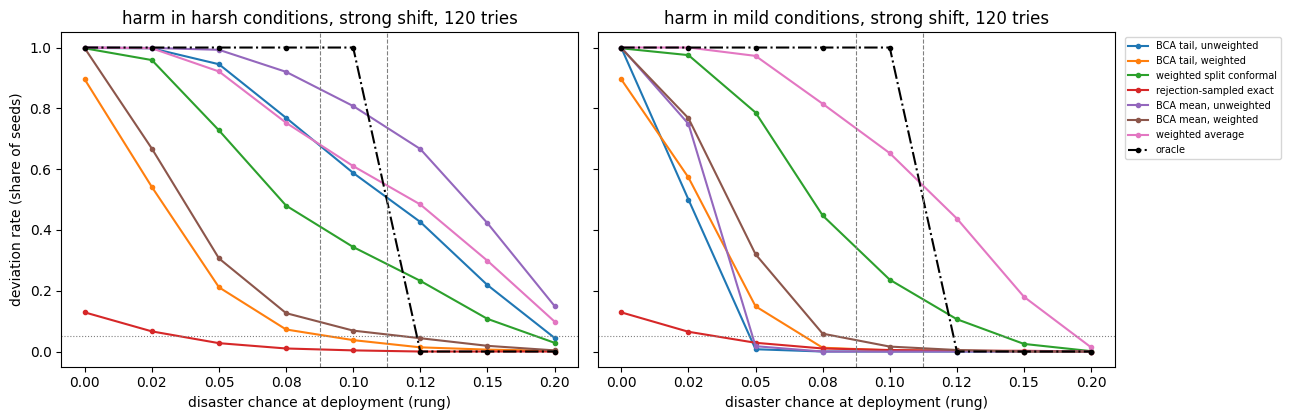

In [131]:
show = ["BCA tail, unweighted", "BCA tail, weighted", "weighted split conformal", "rejection-sampled exact",
        "BCA mean, unweighted", "BCA mean, weighted", "weighted average", "oracle"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), sharey=True)
for ax, p in zip(axes, (1, 2)):
    for i, g in enumerate(show):
        ax.plot(range(len(RUNGS)), rate(DEC[g])[p, :, 2, SIZES.index(120)], marker="o", ms=3,
                color="k" if g == "oracle" else f"C{i}", ls="-." if g == "oracle" else "-", label=g)
    ax.axvline(int(np.argmax(UNSAFE)) - 0.5, color="grey", ls="--", lw=0.8)
    ax.axvline(int(np.argmax(HARMFUL)) - 0.5, color="grey", ls="--", lw=0.8)
    ax.axhline(DELTA, color="grey", ls=":", lw=0.8)
    ax.set_xticks(range(len(RUNGS))); ax.set_xticklabels([f"{r:.2f}" for r in RUNGS])
    ax.set_xlabel("disaster chance at deployment (rung)")
    ax.set_title(f"{PROFILES[p]}, strong shift, 120 tries")
axes[0].set_ylabel("deviation rate (share of seeds)")
axes[1].legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1.0))
fig.tight_layout(); plt.show()

In [132]:
def lesson_4_chart_notes():
    """The chart's key values, read from the stored decisions (strong shift, 120 tries)."""
    if not lesson_4_ready("run"):
        return

    def at(gate, profile, rung):
        return float(rate(DEC[gate])[PROFILES.index(profile), RUNGS.index(rung), SHIFTS.index("strong"),
                                     SIZES.index(120)])

    harsh, mild = "harm in harsh conditions", "harm in mild conditions"
    tail_worst = max(float(rate(DEC["BCA tail, weighted"])[PROFILES.index(p), r, 2, SIZES.index(120)])
                     for p in (harsh, mild) for r in range(len(RUNGS)) if UNSAFE[r])
    mean_worst = max(float(rate(DEC["BCA mean, weighted"])[PROFILES.index(p), r, 2, SIZES.index(120)])
                     for p in (harsh, mild) for r in range(len(RUNGS)) if HARMFUL[r])
    lesson_show(lesson_text(
        "**What to notice.**\n"
        "- **Harm in harsh conditions (left):** the log sees fewer disasters than deployment meets, so the unweighted "
        "gates deviate too often. At rung 0.12, which is harmful, the unweighted tail gate deviated in <<a>> of seeds "
        "and the unweighted mean gate in <<b>>; the weighted gates in <<c>> and <<d>>.\n"
        "- **Harm in mild conditions (right):** the log sees more disasters than deployment meets, so the unweighted "
        "gates turn good deviations away. At rung 0.05, which is safe and good, the unweighted tail gate deviated in "
        "<<e>> of seeds and the unweighted mean gate in <<f>>; the weighted gates in <<g>> and <<h>>.\n"
        "- **In both panels**, the weighted tail gate stays at or below <<i>> in the unsafe rungs, and the weighted "
        "mean gate at or below <<j>> in the harmful ones.",
        a=at("BCA tail, unweighted", harsh, 0.12), b=at("BCA mean, unweighted", harsh, 0.12),
        c=at("BCA tail, weighted", harsh, 0.12), d=at("BCA mean, weighted", harsh, 0.12),
        e=at("BCA tail, unweighted", mild, 0.05), f=at("BCA mean, unweighted", mild, 0.05),
        g=at("BCA tail, weighted", mild, 0.05), h=at("BCA mean, weighted", mild, 0.05),
        i=tail_worst, j=mean_worst))


lesson_4_chart_notes()

**What to notice.**
- **Harm in harsh conditions (left):** the log sees fewer disasters than deployment meets, so the unweighted gates deviate too often. At rung 0.12, which is harmful, the unweighted tail gate deviated in 0.426 of seeds and the unweighted mean gate in 0.666; the weighted gates in 0.014 and 0.044.
- **Harm in mild conditions (right):** the log sees more disasters than deployment meets, so the unweighted gates turn good deviations away. At rung 0.05, which is safe and good, the unweighted tail gate deviated in 0.007 of seeds and the unweighted mean gate in 0.018; the weighted gates in 0.149 and 0.320.
- **In both panels**, the weighted tail gate stays at or below 0.037 in the unsafe rungs, and the weighted mean gate at or below 0.044 in the harmful ones.

### Step 4.15 · Checks

*Deeper: skip on a first read.*

These confirm that the toy works as described; any failure stops the notebook.
1. Each world's disaster chances are valid and add up to its rung at deployment, and a million simulated deployment tries in one world (harm in harsh conditions, rung 0.12, strong shift) match the exact average gain and share below the fallback.
2. The weighted tail gate decides exactly as production `calibration/wbcp.py` does, on 300 random cases. It skips itself, with a note, if that file cannot be imported.
3. For identical tries, the weighted mean gate's 10,000 draws match an exact product formula like the one in Step 4.4.
4. The Clopper–Pearson bounds of the stratified gate match their closed form when no try is bad, and sit exactly at the 1% level otherwise.
5. Student's t values match published tables, and the exact tail gate cannot say yes below 29 tries.
6. Rejection sampling keeps tries in deployment's mix.
7. With no shift, every weight is 1, so each weighted gate reduces to its unweighted twin.

In [133]:
# 1. Each world's disaster chances are valid and add up to its rung at deployment; the exact truths match simulation.
for pi in range(len(PROFILES)):
    for ri, rung in enumerate(RUNGS):
        for si, shift in enumerate(SHIFTS):
            pk = P_K[pi, ri, si]
            assert np.all((pk >= 0) & (pk <= 1)) and abs(DEPLOY_MIX[shift] @ pk - rung) < 1e-12
rng = np.random.default_rng([ROOT_SEED, 999])
cond = rng.choice(LOG_MIX.size, 1_000_000, p=DEPLOY_MIX["strong"])
gains = np.where(rng.random(cond.size) < P_K[1, 5, 2][cond], DISASTER,
                 np.clip(CENTER + SPREAD * rng.standard_normal(cond.size), LO, HI))
assert abs(gains.mean() - MU[5]) < 5 * gains.std() / 1000 and abs((gains < 0).mean() - BAD[5]) < 0.002
# 2. The weighted tail gate here decides exactly as production BCA (calibration/wbcp.py) does.
sys.dont_write_bytecode = True
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())
try:
    from calibration.wbcp import calibrate
except ImportError:
    calibrate = None
    print("Check 2 skipped: run this notebook from the repository root to compare with calibration/wbcp.py.")
if calibrate is not None:
    rng = np.random.default_rng([ROOT_SEED, 997])
    for case in range(300):
        n, si = int(rng.choice(SIZES)), int(rng.integers(len(SHIFTS)))
        c = rng.choice(LOG_MIX.size, n, p=LOG_MIX)
        g_ = np.where(rng.random(n) < rng.uniform(0, 0.2), DISASTER, np.clip(CENTER + SPREAD * rng.standard_normal(n), LO, HI))
        w_, stream = WEIGHT[si, c], int(rng.integers(2 ** 32))
        production = calibrate(-g_, np.random.default_rng(stream), w_, float(WBAR[si]),
                               alpha=TAIL, beta=CONFIDENCE, draws=TAIL_DRAWS).threshold <= 0
        ex = np.random.default_rng(stream).standard_exponential((TAIL_DRAWS, n + 1))
        order = np.argsort(-g_, kind="stable")
        mass = ex[:, :n] * w_[order]
        s_good, s_all = (mass * (g_[order] >= 0)).sum(axis=1), mass.sum(axis=1)
        crossed = (s_good >= (1 - TAIL) * (s_all + ex[:, n] * WBAR[si])).sum()
        mine = bool(w_[g_ >= 0].sum() >= (1 - TAIL) * w_.sum() - 1e-9) and crossed >= NEED
        assert production == mine, case
# 3. The weighted mean gate's sampler matches the exact answer for identical tries: with gain g on every try, the
#    chance that the weighted average is below 0 is the product of 1 / (1 + g * w_i / (|floor| * WBAR)).
ex = np.random.default_rng([ROOT_SEED, 996]).standard_exponential((MEAN_DRAWS, N_MAX + 1))
for n, si, g_ in ((30, 1, 0.5), (120, 2, 0.3), (240, 2, 0.1)):
    w_ = WEIGHT[si, np.random.default_rng([ROOT_SEED, n]).choice(LOG_MIX.size, n, p=LOG_MIX)]
    estimate = ((ex[:, :n] * w_ * g_).sum(axis=1) + ex[:, N_MAX] * WBAR[si] * FLOOR < 0).mean()
    exact = np.prod(1 / (1 + g_ * w_ / (-FLOOR * WBAR[si])))
    assert abs(estimate - exact) < 4 * math.sqrt(exact * (1 - exact) / MEAN_DRAWS) + 1e-4, (n, si, estimate, exact)
# 4. Clopper-Pearson bounds match the closed form with no bad tries, and sit exactly at their level otherwise.
for n in (1, 5, 29, 100, 240):
    assert abs(cp_upper([0], [n], STRATA_LEVEL)[0] - (1 - STRATA_LEVEL ** (1 / n))) < 1e-9
for b, n in ((1, 10), (3, 50), (20, 240)):
    p = cp_upper([b], [n], STRATA_LEVEL)[0]
    assert abs(sum(math.comb(n, x) * p ** x * (1 - p) ** (n - x) for x in range(b + 1)) - STRATA_LEVEL) < 1e-9
# 5. Student's t quantiles match published tables, and BCA's exact tail gate cannot say yes below 29 tries.
for level, df, want in ((0.05, 29, 1.6991), (0.05, 9, 1.8331), (0.01, 29, 2.4620)):
    assert abs(t_upper(level, df) - want) < 1e-3, (level, df)
assert allowed_below(28, TAIL) == -1 and allowed_below(29, TAIL) == 0
# 6. Rejection sampling keeps tries in deployment's mix.
rng = np.random.default_rng([ROOT_SEED, 995])
cond = rng.choice(LOG_MIX.size, 2_000_000, p=LOG_MIX)
for si, shift in enumerate(SHIFTS):
    kept = cond[rng.random(cond.size) < WEIGHT[si, cond] / WMAX[si]]
    assert np.allclose(np.bincount(kept, minlength=LOG_MIX.size) / kept.size, DEPLOY_MIX[shift], atol=0.003), shift
# 7. With no shift, every weight is 1, so each weighted gate reduces to its unweighted twin.
assert WBAR[0] == 1.0 and np.all(WEIGHT[0] == 1.0)
assert np.array_equal(R["neg_w"][..., 0, :], R["neg_u"][..., 0, :])
assert np.array_equal(R["neg_r"][..., 0, :], R["neg_u"][..., 0, :])
assert np.array_equal(DEC["rejection-sampled exact"][..., 0, :], DEC["BCA tail, unweighted"][..., 0, :])
assert np.allclose(R["m_w"][..., 0, :], R["m_u"][..., 0, :])
same = (DEC["BCA tail, weighted"][..., 0, :] == DEC["BCA tail, unweighted"][..., 0, :]).mean()
print(f"With no shift, BCA's sampled tail gate (1,000 draws) and its exact form agree in {same:.2%} of cases.")
print("All checks passed. Notebook seconds:", round(time.perf_counter() - START, 1))

With no shift, BCA's sampled tail gate (1,000 draws) and its exact form agree in 98.51% of cases.
All checks passed. Notebook seconds: 74.3


**What to notice.** With no shift, BCA's 1,000-draw tail gate and its exact form agreed in 98.51% of cases: as in Part 2, equal-weight BCA is the exact binomial test up to the sampling noise of its draws.

### Step 4.16 · Information only: a weighted mean gate that a proof covers

*Deeper: skip on a first read.*

**Added after the first run.** This is not one of the six claims and has no kill rule. It was added after seeing the results.

The research report (`reports/Calibrated bounds in policy optimization.md`) recommended a different weighted mean gate. It reweights each outcome, $w_i\, g_i$, then runs the ordinary mean gate (Step A.8) with the random weights $E_i$ not multiplied by $w_i$. The July 2026 proof behind the mean gate (Vlassis and Thomas, arXiv 2607.08415, version 1, not peer reviewed) appears to cover that version when the weights are known.

The two versions add up the same reweighted outcomes. They differ only in the extra worst-case try that stands in for the unseen deployment outcome. A draw counts as below 0 when

$$
\begin{aligned}
& \text{as tested:} \\
&\quad \sum_i E_i\, w_i\, g_i + E_{n+1}\, \bar w\, g_{\min} < 0 \\
& \text{covered by the proof:} \\
&\quad \sum_i E_i\, w_i\, g_i + E_{n+1}\, w_{\max}\, g_{\min} < 0
\end{aligned}
$$

The proof's version uses the largest weight $w_{\max}$ because a reweighted outcome $w_i\, g_i$ can be as low as $w_{\max}\, g_{\min}$.

In [134]:
def lesson_4_worst_cases():
    """The extra worst-case try's reweighted gain in the two versions, for each shift."""
    if not lesson_4_ready("settings"):
        return
    lines = []
    for si, shift in enumerate(SHIFTS):
        lines += [lesson_tex(r"& \text{<<s>> shift:}", s="no" if shift == "none" else shift),
                  lesson_tex(r"&\quad \bar w\, g_{\min} = <<a:4>> \times (-4) = <<b:2>>", a=WBAR[si],
                             b=WBAR[si] * FLOOR),
                  lesson_tex(r"&\quad w_{\max}\, g_{\min} = <<c:1>> \times (-4) = <<d:1>>", c=WMAX[si],
                             d=WMAX[si] * FLOOR)]
    lesson_math(*lines,
                note="**So:** under a shift, the version tested above puts a lighter worst case on the scale, so it is "
                     "the more optimistic of the two. With no shift both weights are 1 and the versions are the same.")


lesson_4_worst_cases()

$$
\begin{aligned}
& \text{no shift:} \\ &\quad \bar w\, g_{\min} = 1.0000 \times (-4) = -4.00 \\ &\quad w_{\max}\, g_{\min} = 1.0 \times (-4) = -4.0 \\ & \text{moderate shift:} \\ &\quad \bar w\, g_{\min} = 1.3701 \times (-4) = -5.48 \\ &\quad w_{\max}\, g_{\min} = 2.5 \times (-4) = -10.0 \\ & \text{strong shift:} \\ &\quad \bar w\, g_{\min} = 2.9096 \times (-4) = -11.64 \\ &\quad w_{\max}\, g_{\min} = 5.0 \times (-4) = -20.0
\end{aligned}
$$

**So:** under a shift, the version tested above puts a lighter worst case on the scale, so it is the more optimistic of the two. With no shift both weights are 1 and the versions are the same.

The next cell replays every seed with the worst case at the largest weight. It first checks that the replay reproduces the stored results of the tested version exactly, so both versions see the same draws.

**How to read it.** One row per version. The first three columns are at the stated 5% level, over all seeds. *Tuned level*, *tuned gain* and *tuned worst harmful* use claim 6's tuning: the level chosen on seeds 0–399, then scored on seeds 400–799. The last table splits the pooled gain at the 5% level by shift.

In [135]:
def worst_case_counts(seed):
    """Replays run_seed's draws; counts negative weighted averages with the worst case at the average and largest weight."""
    rng = np.random.default_rng([ROOT_SEED, STREAM, seed])
    cond = rng.choice(LOG_MIX.size, N_MAX, p=LOG_MIX)
    u, v = rng.random((2, N_MAX))
    z = rng.standard_normal(N_MAX)
    e = rng.standard_exponential((MEAN_DRAWS, N_MAX + 1))
    gain = np.where(u < P_K[..., cond], DISASTER, np.clip(CENTER + SPREAD * z, LO, HI))
    w = WEIGHT[:, cond]
    average, largest = np.zeros(WORLD), np.zeros(WORLD)
    for zi, n in enumerate(SIZES):
        g = gain[..., :n]
        x = np.broadcast_to(w[None, None, :, :n] * g, g.shape).reshape(-1, n).T
        for out, weight in ((average, WBAR), (largest, WMAX)):
            sums = e[:, :n] @ x + e[:, N_MAX][:, None] * (weight[SHIFT_OF] * FLOOR)[None, :]
            out[..., zi] = (sums < 0).sum(axis=0).reshape(WORLD[:3])
    return average, largest

replayed = [worst_case_counts(s) for s in range(N_SEEDS)]
assert np.array_equal(np.stack([r[0] for r in replayed]), R["neg_w"])
NEG_LARGEST = np.stack([r[1] for r in replayed])

VERSIONS = {"BCA mean, weighted": lambda k: accept("BCA mean, weighted", k),
            "BCA mean, largest weight": lambda k: NEG_LARGEST <= limit(k)}
print(f"{'version':26}{'worst harmful':>14}{'safe, shifted':>15}{'gain':>8}"
      f"{'tuned level':>13}{'tuned gain':>12}{'tuned worst harmful':>21}")
for name, decide in VERSIONS.items():
    r = rate(decide(DELTA))
    points = [(k, rate(decide(k), TUNE_SEEDS)[HARMFUL_W].max(), pooled_gain(decide(k), TUNE_SEEDS), decide(k))
              for k in LEVELS]
    qualified = [p for p in points if p[1] <= DELTA]
    k, _, _, d = max(qualified, key=lambda p: p[2]) if qualified else (None, 0, 0, np.zeros((N_SEEDS,) + WORLD, bool))
    print(f"{name:26}{r[HARMFUL_W].max():14.3f}{r[SAFE_SHIFTED].mean():15.3f}{pooled_gain(decide(DELTA)):8.4f}"
          f"{str(k):>13}{pooled_gain(d, EVAL_SEEDS):12.4f}{rate(d, EVAL_SEEDS)[HARMFUL_W].max():21.3f}")
print(f"Best tuned rival in claim 6, {best_rival}: tuned gain {TUNED[best_rival][2]:.4f}")
print("Tuned gains are on seeds 400-799, after tuning on seeds 0-399 as in claim 6.")
print("\nPooled gain at the stated 5% level, by shift")
print(f"{'version':26}" + "".join(f"{s:>10}" for s in SHIFTS))
for name, decide in VERSIONS.items():
    by = rate(decide(DELTA)) * GAIN_W
    print(f"{name:26}" + "".join(f"{by[:, :, si].mean():10.4f}" for si in range(len(SHIFTS))))

version                    worst harmful  safe, shifted    gain  tuned level  tuned gain  tuned worst harmful
BCA mean, weighted                 0.044          0.415  0.0982         0.05      0.0975                0.052
BCA mean, largest weight           0.026          0.273  0.0804          0.1      0.0954                0.055
Best tuned rival in claim 6, weighted split conformal: tuned gain 0.0923
Tuned gains are on seeds 400-799, after tuning on seeds 0-399 as in claim 6.

Pooled gain at the stated 5% level, by shift
version                         none  moderate    strong
BCA mean, weighted            0.1288    0.1019    0.0637
BCA mean, largest weight      0.1288    0.0739    0.0383


**What it showed (information only).**
- **At the stated 5% level, the proof's version is more cautious:** worst harmful rate 0.026 against 0.044, yes in 0.273 of safe shifted cases against 0.415, and gain 0.0804 against 0.0982. The whole gap is in the shifted worlds (strong shift: 0.0383 against 0.0637); with no shift the two versions are the same (0.1288).
- **At equal harm, the gap nearly closes.** Tuned to a 0.1 level, the proof's version earned 0.0954 on seeds 400–799, against 0.0975. Both beat claim 6's best tuned rival, weighted split conformal (0.0923). Its worst harmful rate there was 0.055, within sampling noise of 0.05.
- **The trade-off.** The tested version earns more at its stated level, but only this toy supports its promise. The proof's version rests on a proof, though one not yet peer reviewed. Tuning it to a looser level recovered nearly all of the return, but that tuning used worlds whose truth is known.

## What Part 4 found

| Claim | Result | Verdict |
|---|---|---|
| 1. Ignoring the shift breaks BCA's tail promise | worst unsafe-world rate 0.899; 17 unsafe worlds above the allowance (0.073) | alive |
| 2. With weights, the tail gate as built keeps its promise | worst unsafe-world rate 0.043 | alive |
| 3. The weights use shifted evidence better than the simple valid alternatives | yes in 0.336 of safe shifted cases, against 0.190 (rejection sampling) and 0.000 (stratified) | alive |
| 4. Weighted BCA's promise holds for the data in hand, unlike weighted split conformal's | worst unsafe-world rate 0.043, against 0.388 | alive |
| 5. With weights, the mean gate keeps its promise | worst harmful-world rate 0.044 | alive |
| 6. At equal harm, the weighted mean gate earns the most | 0.0975 per decision, against 0.0923 for a tuned weighted split conformal | alive, narrowly |

No claim was shelved.

- **Ignoring the shift breaks both promises.** The unweighted gates answer for the log's mix, where the deviation can look safe (Step 4.6). The unweighted tail gate deviated in up to 0.899 of seeds in an unsafe world, and the unweighted mean gate in up to 0.936 in a harmful one.
- **With weights, both BCA gates kept their promise in every world.** Check 2 confirms that the weighted tail gate decides as production `calibration/wbcp.py` does. No proof covers the weighted mean gate as tested, and no world broke it here.
- **The weights keep more evidence than throwing tries away.** Under the strong shift, 120 tries counted as 41.8 equally weighted ones, while rejection sampling kept 24.1. The stratified bound needs about 287 or 382 tries under the two shifts, more than any world has.
- **Weighted split conformal failed for the data in hand** (0.388 in an unsafe world), as split conformal did without weights in Part 2: its promise holds only on average over data sets.
- **At equal harm, the weighted mean gate led, narrowly:** 0.0975 against 0.0923 for weighted split conformal on seeds 400–799, and 0.0988 against 0.0923 on the tuning seeds. The tuning used toy worlds whose truth is known.
- **The price is evidence.** Under the strong shift, the weighted tail gate cannot say yes with fewer than about 83 tries, against 29 with no shift. Ignoring the shift earned more (0.1106 against 0.0838), but only by breaking the promise in 17 unsafe worlds. Tuned to the same safety, the unweighted tail gate earned 0.0536, against 0.0838 for the weighted one.
- **Information only, added after the run:** the version that a proof appears to cover, with the largest weight on the worst case, gave up little at equal harm (0.0954 against 0.0975).

**The insight.** In these toys, a gate had to account for the shift to keep its promise: when BCA's two gates ignored it, they broke both promises in the worst worlds. Of the gates that kept the tail promise, BCA's weights used the evidence best: yes in 0.336 of safe shifted cases, against 0.190 for rejection sampling and 0.000 for the stratified bound. A shift still costs evidence, and weights alone are not enough: weighted split conformal used them and still broke the tail promise for the data in hand. The weights here were known exactly; estimated weights are untested.

---
# What it all adds up to

**The big picture.** Across the four toys, one signal mattered: the risky action's own held-out outcomes, measured against the fallback's value. A width built from errors at logged actions never reached that signal; a gate that reads it did. With equal weights, that is, no shift weights, each of BCA's gates is a known classical method: the exact binomial test for the tail promise, and Gaffke's bound for the mean promise. Under a shift, BCA's weights kept both promises and used the evidence better than the simple valid alternatives.

| Part | Title | The answer |
|---|---|---|
| 1 | Does BCA's width make the policy choose better? | No. The width was calibrated where the log has data, but changed no decision for the better. |
| 2 | Where can BCA help? Widths against gates | As a gate that reads the risky action's own held-out tries, not as a width. BCA's tail gate and its exact twin were the safest gates. |
| 3 | Can a BCA gate raise return? The mean gate | Its mean gate earned the most once every gate was tuned to the same safety level, but not when safety is ignored. |
| 4 | Do BCA's weights help under a shift? | Yes. They kept both promises where ignoring the shift broke them, at a cost in evidence. |

This closing section collects the 18 pre-registered claims, says what the shelved ones teach and what the results mean for BCA, and lists what the toys do not show. A glossary of every term and symbol ends the notebook.

## Every claim at a glance

One row per pre-registered claim: its verdict under its kill rule, and the key number its part printed. Words such as room, claimed advantage, bar, allowance and harm rate are in the glossary at the end.

### Part 2 · six tests

| Claim | Verdict | Key number |
|---|---|---|
| Test 1. BCA's width at every action removes at least a quarter of the room | shelved | −2.50 and −2.09 of the room (the two width rules) |
| Test 2. The step-1 gate removes at least half the room, from the outcomes themselves | alive | +0.58 of the room; shuffled outcomes keep none of it (−4.44) |
| Test 3. Comparing with the critic's claimed advantage (the same as comparing outcomes with the safe action's value) beats a fixed margin against the rest | alive | regret 0.0282 (BCA harm test) against 0.0508 (step-1 gate) |
| Test 4a. BCA decides differently from the exact binomial test | shelved | agreement 0.9961; shelved at 0.99 or more |
| Test 4b. BCA's confidence makes deviations safer than split conformal | alive, narrowly | unsafe-deviation rate 0.057 (split conformal) against 0.002 (BCA): +0.055, against a 0.05 bar |
| Test 4c. Safety needs a quantile, not an average | alive | 0.290 (plain average) against 0.002 (BCA) in tail-shape unsafe worlds: +0.288, against a 0.05 bar |

### Part 3 · six claims

| Claim | Verdict | Key number |
|---|---|---|
| Claim 1. The mean gate keeps its promise | alive | worst harm rate 0.003 |
| Claim 2. It is the tightest guaranteed mean gate | alive | 17.4% of good proposals accepted, against 0.0% (Hoeffding) and 0.0% (empirical Bernstein) |
| Claim 3. The t-test is unsafe with rare disasters | alive | worst rare-disaster harm rate 0.313 |
| Claim 4. In crowded worlds it beats simple averaging | shelved | gain 0.0567, against 0.1829 (plain) and 0.1625 (shrunk) |
| Claim 5. At equal harm it earns the most | alive | gain 0.0845, against 0.0400 (BCA's cautious average) |
| Claim 6. Deciding all situations together earns more | shelved | gain 0.0270, against 0.0453 deciding each alone |

### Part 4 · six claims

| Claim | Verdict | Key number |
|---|---|---|
| Claim 1. Ignoring the shift breaks the tail promise | alive | worst unsafe-world rate 0.899; 17 unsafe worlds above the allowance |
| Claim 2. With weights, the tail gate as built keeps its promise | alive | worst unsafe-world rate 0.043 |
| Claim 3. Weights use shifted evidence better than the simple valid alternatives | alive | deviation rate 0.336 in safe shifted worlds, against 0.190 (rejection sampling) and 0.000 (stratified) |
| Claim 4. Weighted BCA's promise holds for the data in hand, unlike weighted split conformal's | alive | worst unsafe-world rate 0.043 (weighted BCA) against 0.388 (weighted split conformal) |
| Claim 5. With weights, the mean gate keeps its promise | alive | worst harmful-world rate 0.044 |
| Claim 6. At equal harm, the weighted mean gate earns the most | alive, narrowly | gain 0.0975, against 0.0923 (weighted split conformal) |

Fourteen of the eighteen claims survived; four were shelved.

## What the shelved claims teach

The four shelved claims say the most:
- **BCA's width does not help as built** (Part 2, test 1). The width is measured where the log has data, and the risky action has none. It also penalizes good actions that are merely noisy.
- **With equal weights, BCA adds no information over a textbook test** (Part 2, test 4a). Its threshold is one of the sorted scores, picked by a binomial tail: the exact binomial test (Lesson step A.6). What it adds over split conformal is the kind of promise, one that holds for the data in hand.
- **Caution does not raise return when the held-out evidence is already honest** (Part 3, claim 4). Fresh held-out tries give an honest average, however lucky the critic's pick was. Extra caution then mostly turns good candidates away.
- **A shared harm budget does not help when few actions pass at all** (Part 3, claim 6). Deciding together lets more through only when many situations look clearly good at once.

## What this means for BCA

1. **Use BCA as a gate on deviations, not as a width.** A deviation is taking a risky action instead of the fallback. A width calibrated at logged actions cannot see the actions the log lacks, and its caution cost return in Parts 1 and 2. ThrusterChain's earlier results pointed the same way.
   - *What the toys cannot settle.* In three of the four hosts, BCA's width sets a training-time *dose*: a multiplier on one term of the host's training loss (the pull toward the logged actions in TD3+BC and ReBRAC, the conservative penalty in CQL). IQL instead turns the width into weights in the regression that fits its policy to the logged actions. In these toys a critic's errors never spread through its own training targets, so they cannot test a dose. What they show is narrower: neither way of using a width beat simply refusing thin data (actions with too few training rows). That held whether the width was subtracted from the critic's values (Parts 1 and 2) or used to strengthen the pull toward the logged actions (Part 2). The second way beat the plain pull toward the log (regret 0.3755 against 0.4939) only by venturing less often in every world.
2. **Measure a deviation against the fallback's value.** Compare the deviation's held-out outcomes with the fallback's value, not with other rows plus a margin. The critic estimates the fallback's value well, because the log covers the fallback. Part 2's BCA harm test does this: its regret was 0.0282, against 0.0508 for the step-1 gate, and it needs no hand-picked margin like the step-1 gate's 0.10. But a harm test ventures unless the outcomes prove harm, so it still ventured in 0.276 of the cases in unsafe worlds. For a safety promise, use a gate that needs proof of safety, such as BCA's tail gate (point 3).
3. **Match the gate to the promise you need.**
   - *The most return at a fixed safety level:* BCA's mean gate. Tuned to the same safety level as every rival, it earned 0.0845 in Part 3, against 0.0400 for BCA's cautious average and 0.0187 for the best gate not built from BCA (the shrunk average). In Part 4 it earned the most by a narrow margin (0.0975 against 0.0923). That tuning used toy worlds whose truth is known. At its stated 5% level (95% confidence), the gate is more cautious: in Part 3 it earned 0.045, against 0.158 for the plain average.
   - *Rarely worse than the fallback:* BCA's tail gate. In Part 2 it let an unsafe action through in at most 0.03 of seeds in any unsafe world, against up to 0.38 for split conformal.
   - *No safety requirement:* the plain held-out average earns the most (Part 2 regret 0.0157; Part 3 gain 0.158).
4. **Use weights when the held-out tries come from a different mix of states than deployment.** They kept both promises in Part 4, where ignoring the shift broke them. For the weighted mean gate, prefer the version that puts the largest weight on the worst case: a proof appears to cover it, and at equal harm it earned nearly as much (0.0954 against 0.0975, in an information-only check added after Part 4's first run).
5. **Compute equal-weight BCA exactly.** With equal weights, the tail gate is the exact binomial test, so it needs no random draws. With 1,000 random draws, only 4 of 8 score sets matched the exact answer at 28 scores, and 4 of 8 at 29 (Part 2). Exact arithmetic also lowers the minimum evidence from 36 rows to 29: production code (`calibration/reference.py`) asks for 36 to allow for the draws' sampling error. Keep the random draws for the weighted case.
6. **Describe it plainly.** With equal weights, BCA's tail gate is the exact binomial test, also known as Wilks' (1941) tolerance limit and Vovk's (2012) training-conditional conformal bound (a conformal promise for the data in hand). Its mean gate is Gaffke's (2005) bound computed with BCA's random weights. The defensible claims are a safety promise for each decision that holds for the data in hand, and the most return at a fixed safety level when gates are tuned on worlds whose truth is known. The claim that BCA's Bayesian posterior (its random draws) adds information over a textbook test is not supported.
7. **Budget the evidence.** With no shift, the tail gate needs at least 29 held-out outcomes per decision; under Part 4's moderate shift, about 39; under its strong shift, about 83. In ThrusterChain itself, the step-1 gate had only 28–59 held-out outcomes per seed and world (from the pre-specification of the restructure's step 1, `outputs/shift/beyond-the-data/restructure/step1/PRESPEC.md`).

## What this does not show

- **Toys and toy seeds only.** Nothing here is ThrusterChain or host evidence, and nothing is confirmatory.
- **The deviation was handed to the gate.** Every gate read real, independent held-out tries of a deviation it was given. A real gate must find its deviations and group similar ones, and each split of the evidence costs tries.
- **Floors and weights were known exactly.** A wrong floor voids the mean gate's promise, and estimated weights are untested.
- **Each decision stood alone.** No world let a critic's errors spread backward through its own training targets, the main failure mode in offline reinforcement learning. That is also why the toys cannot judge a training-time dose.
- **The mean gate's guarantee rests on an unreviewed preprint** (Vlassis and Thomas, July 2026, [arXiv 2607.08415](https://arxiv.org/abs/2607.08415), version 1). BCA's own weighted mean gate, with the average weight on the worst case, has no proof.
- **The pre-registration's timing rests on the running agent's account.** The repository's history cannot confirm it, because all four notebooks were added in one commit.

## Next steps

1. **Estimated weights.** This test is designed but not yet run. Estimate deployment's mix from a small sample of deployment states (10 to 300), then compare plug-in weights with BCA drawing a fresh plausible mix inside each of its random draws. As before, the kill rules would be fingerprinted before the first run.
2. **A ThrusterChain test of the mean gate at deviations.** The restructure is the repository's staged plan for testing BCA in ThrusterChain; its step 1 first proposed Part 2's step-1 gate, and its step 2 trains policies. This test changes step 2 and needs a new pre-registration, approved at your terminal.
3. **Exact equal-weight BCA in production.** This is a small change to `calibration/wbcp.py` and needs your approval.

## Where these results came from

| Part | Original notebook | Kill-rules fingerprint |
|---|---|---|
| 1 | `bca_discrete_toy.ipynb` | none (exploratory) |
| 2 | `bca_channel_toy.ipynb` | `bb9e0325…dbc3` |
| 3 | `bca_mean_gate_toy.ipynb` | `50a0f49d…b1d3` |
| 4 | `bca_weights_toy.ipynb` | `e32e04d7…f44e` |

- The fingerprint is the start and end of the SHA-256 hash of each part's kill rules; each part prints it in full.
- Each part's experiment code is copied unchanged from its original notebook, and every result those notebooks printed is reproduced here exactly; only run times differ. The explanations and the worked examples are new.
- Running times here: Part 1 about a second, Part 2 under a minute, Part 3 under half a minute, Part 4 about two to five minutes, depending on the machine.
- The literature behind Parts 3 and 4 is reviewed in `reports/Calibrated bounds in policy optimization.md`.
- BCA follows Weighted Bayesian Conformal Prediction ([Lou and Luo, arXiv 2604.06464v3](https://arxiv.org/abs/2604.06464v3), Algorithm 1).

## Glossary

**The setting**
- **Policy:** the rule that picks an action in each state.
- **Log:** the recorded past actions and outcomes the policy learns from.
- **Deployment:** when the policy is put to use; it may meet states in a different mix than the log.
- **Critic:** the learned estimate of each action's value.
- **Return:** the total reward a policy collects.
- **Fallback:** the safe action, which the log covers well, so its value is well estimated.
- **Risky action:** the action the policy wants but the log barely covers. Parts 1 and 2 call it *venture*, Part 3 a *candidate* (the one the critic picks is the *proposal*), Part 4 a *deviation*.
- **Gap:** in Part 2, the never-tried cell: venture at step $t = 1$ in context 1. Its outcomes change from world to world.
- **Claimed advantage:** in Part 2, $Q_{\mathrm{gap}} - Q_{\mathrm{safe}}$: how much the critic claims venture beats safe at the gap (printed as claimed).
- **Situation:** one decision in Part 3: the critic proposes one of several candidates, and the gate accepts the proposal or stays safe.
- **Good, harmful:** in Part 3, a candidate whose true average gain over the fallback is above 0, or below 0.
- **Held-out tries:** logged outcomes of the risky action that training never saw; only the gates read them. Part 2 calls them *survivors*.
- **Shift:** deployment meets states in a different mix than the log.
- **ThrusterChain:** the repository's larger test environment, where BCA is attached to the hosts. Its *restructure* is the repository's staged plan for testing BCA there; step 1 of that plan first proposed Part 2's step-1 gate.
- **Hosts:** the offline learners BCA is attached to in this repository (TD3+BC, CQL, IQL, ReBRAC).
- **Dose:** in three of the four hosts, BCA's width used as a multiplier on one term of the host's training loss: the pull toward the logged actions in TD3+BC and ReBRAC, the conservative penalty in CQL. IQL instead turns the width into weights in the regression that fits its policy (its *actor*) to the logged actions.

**BCA's tools** (the Lesson step that builds each one is in parentheses)
- **Score:** how wrong the critic was on one held-out row; bigger is worse (A.1).
- **Crossing:** in one random draw of weights, the first sorted score at which the running total of weights reaches 90% of all the weight, the extra weight included; ∞ if none does (A.3).
- **Threshold:** a score level that BCA is 95% sure at least 90% of future scores stay at or below (A.4).
- **Width:** a threshold times the critic's error scale: a margin of error on the critic's values, used as extra caution. Part 1 subtracts it from the values; the hosts use it during training to strengthen one term of their loss (see *Dose*), and Part 2's rule A2 mimics this.
- **Gate:** a rule that reads the held-out tries and either lets the risky action through or falls back.
- **Tail promise:** at most 10% of the risky action's outcomes fall below the fallback, with 95% confidence (A.7).
- **Mean promise:** the risky action's average gain over the fallback is above 0, with 95% confidence (A.8).
- **Level:** the error share a gate allows itself: 5% (that is, 95% confidence) unless it was tuned.
- **Floor:** the worst gain a try can possibly have; the mean gate puts its extra worst-case weight there (A.8).
- **Weights** (shift weights): a try's weight is (deployment's share of its state) ÷ (the log's share) (A.9).
- **Equal weights:** no shift weights, so every row's fixed weight is 1. BCA's random weights $E_i$ still change from draw to draw, but favor no score (A.3, A.9).
- **Bayesian posterior:** BCA's random draws of weights, each giving one plausible crossing; BCA reads its threshold from their spread.
- **Split conformal:** the standard conformal threshold; its promise holds on average over many data sets, not for the data in hand (A.2).
- **Exact binomial test:** the textbook test that BCA's tail gate reduces to with equal weights (A.6).
- **Gaffke's bound:** a classic small-sample lower bound on an average (Gaffke, 2005); BCA's mean gate computes it with BCA's random weights.

**Gates named in the claims**
- **Step-1 gate:** falls back if BCA is 95% sure that the 90% point of the critic's over-predictions (value minus outcome) on the held-out tries exceeds the same point for all other last-step held-out rows by more than 0.10 (Part 2). It is named after step 1 of the ThrusterChain restructure, where this rule was first proposed, not after step $t = 1$ of an episode.
- **BCA harm test:** falls back only if BCA is 95% sure that more than 10% of outcomes fall below the fallback's value (Part 2).
- **Plain average:** says yes if the held-out tries' average beats the fallback. The *shrunk average* first pulls it toward the average of all candidates (Part 3).
- **BCA's cautious average:** says yes if (sum of tries + floor) ÷ (tries + 1) is above 0 (Part 3). It is the mean gate's weighted average if every random weight $E_i$ were fixed at 1 instead of drawn.
- **t-test, Hoeffding, empirical Bernstein:** classical 95% lower bounds on an average; each says yes if its bound is above 0 (Part 3). The t-test's bound is $\bar g - t_{0.95}(n-1)\,\mathrm{sd}/\sqrt{n}$.
- **Rejection sampling, stratified exact:** the simple valid ways to handle a shift, both of which throw evidence away (Part 4).

**Scoring the results**
- **World:** one setting of a toy's unknowns, such as how often the risky action ends in disaster.
- **Seed:** one set of random numbers. Each world runs once per seed, and all worlds share the same seeds.
- **Unsafe world:** more than 10% of the risky action's outcomes fall below the fallback.
- **Harmful world:** the risky action's average gain over the fallback is below 0.
- **Crowded worlds:** Part 3's worlds with 10 or 30 candidates per situation and 10% or 30% good ones.
- **Safe shifted worlds:** Part 4's worlds that are not unsafe and have a moderate or strong shift.
- **Regret:** return lost against perfect choices; 0 is perfect.
- **Gain:** return won over always taking the fallback; 0 is no better.
- **Room:** the regret of the best rule that never reads the held-out tries (Part 2): refusing thin data, that is, never taking an action with too few training rows. A rule's gain ÷ room is the share of that regret it removes.
- **Deviation rate, harm rate:** how often a gate lets the risky action through: in a world's seeds (Parts 2 and 4; Part 2's unsafe-deviation rate counts unsafe worlds only), or among the harmful proposals (Part 3). In an unsafe or harmful world, it is how often the gate breaks its promise.
- **Allowance:** the most a 5% rate may reach in one world before it counts as broken: 5% plus three standard errors.
- **Pre-registered:** the kill rules were written down and fingerprinted before the first run (by the running agent's account).
- **Kill rule:** a result, written down before the run, that would shelve a claim.
- **Bar:** the number a result must clear under its kill rule.
- **Alive, shelved:** the claim survived its kill rule; the claim did not.

### Symbols

| Symbol | Meaning |
|---|---|
| $\alpha = 0.1$ | the share a promise may miss: "at least 90%" means $1-\alpha$ |
| $\beta = 0.95$ | the confidence: "95% sure" |
| $n$ | number of held-out scores (or tries) |
| $s_i$, $s_{(j)}$ | score of row $i$; the $j$-th smallest score |
| $E_i$ | BCA's random weight of row $i$, drawn from an Exponential(1) distribution (average 1); $E_{n+1}$ is the extra weight for the unseen next score |
| $\lambda^{(m)}$ | the crossing of random draw $m$ |
| $\hat\lambda$ | the plain 90% quantile of the scores |
| $\lambda_\beta$ | the 95% value of the crossings (the 950th smallest of 1,000); production code calls it `lambda_hpd` |
| $\lambda_{\mathrm{BCA}} = \max(\hat\lambda, \lambda_\beta)$ | BCA's threshold |
| $x(n)$ | the most scores (or tries) allowed on the wrong side: the largest $x$ with $P(\mathrm{Binomial}(n,\alpha) \le x) \le 1-\beta$ ($-1$, "none", when even $x=0$ fails) |
| $b$ | number of tries that fall below the fallback |
| $g_i$, $\bar g$ | a try's gain over the fallback; the average gain |
| $g_{\min}$ | the floor: the worst gain a try can possibly have (mean gate) |
| $\mathrm{sd}$ | the tries' standard deviation, their spread (t-test, Parts 2 and 3) |
| $t_{0.95}(n-1)$ | the one-sided 95% point of Student's t distribution with $n-1$ degrees of freedom (t-test) |
| $w_i$ | shift weight of try $i$ = (deployment's share of its state) ÷ (the log's share) |
| $\bar w$ | average weight at deployment, $\sum_c p_{\mathrm{dep}}(c)^2 / p_{\mathrm{log}}(c)$; weighted BCA gives the extra worst-case weight $E_{n+1}\bar w$ |
| $n_{\mathrm{eff}} = (\sum_i w_i)^2 / \sum_i w_i^2$ | effective number of tries |
| $t$, $c$, $a$ | step, context, action (Parts 1–2); $a=0$ safe, $a=1$ venture |
| $Q(t,c,a)$ | the critic's value |
| $Q_{\mathrm{safe}} = Q(1,1,\text{safe})$ | Part 2: the critic's value of safe, the fallback, in the gap's context (printed as q_safe) |
| $Q_{\mathrm{gap}} = Q(1,1,\text{venture})$ | Part 2: the critic's guess at the gap (printed as q_gap) |
| $\sigma(t,c,a)$ | the critic's error scale ("count scale" in Part 1) |
| $h = \lambda \cdot \sigma$ | a width |
| $p_{\mathrm{log}}(c)$, $p_{\mathrm{dep}}(c)$ | share of context or condition $c$ in the log and at deployment |